# Entity Resolution — readable pipeline guide

**Goal:** turn PER, ORG, and LOC mentions into consistent real-world entities. **Default: do not merge when evidence is insufficient.** The Python implementation, thresholds, cell order, and outputs below are unchanged.

## End-to-end workflow

![End-to-end workflow](diagrams/workflow.png)

**How to read the diagram:** candidate generation proposes comparisons; it never merges entities. A pair-level `AUTO_MERGE` is only a proposal: cluster-wide constraints are checked again before the actual union. `REVIEW`, `LIKELY_DIFFERENT`, and `INSUFFICIENT_EVIDENCE` do not establish a hard cannot-link.

## Decision flow for one candidate pair

![Decision flow for one candidate pair](diagrams/pair_decision.png)

`decide()` in step 6 checks these questions top to bottom and stops at the first "yes". The thresholds shown (`fuzz_review=90`, `name_review=0.80`) are the fixed values from `CONFIG`.

Both diagrams are drawn by `diagrams/entity_flows.py`; re-run it after changing the pipeline.

---


> **This notebook: `Entity_Resolution_Identity_Aware_BERT.ipynb`.** It is a copy of `Entity_Resolution_Diagrams_BERT_Attention_Experiment.ipynb`, which stays unchanged. Additions:
> - identity-aware short-form evidence
> - BERT-supported merge proposals
> - a promotion identity gate
> - review tiers
> - a proposals table with cluster simulation
> - experimental ablations
>
> **Production decisions equal the source notebook's** with the default `IDA` (cell 3). Every new automatic-merge pathway runs in **shadow mode** and only writes `proposal_*` columns.
>
> **Where files go:**
> - outputs: `er/output_identity_aware/` (experimental files in its `experimental/` folder);
> - calibration: `er/config_identity_aware/`;
> - so the source notebook's files are never overwritten.
>
> **Gold:** the repo's gold labels are loaded if the runtime has none. They are an **unreviewed draft**, so all metrics are provisional and no pathway should be activated on them.
>
> **Changed or added:**
> - cell 3: `IDA`, `resolve_threshold`
> - §2: gold copy
> - §5: `short_mention_facts`, `short_mention_summary`
> - §6: `identity_anchor`, `short_form_proposal`, `promo_eligible`, `apply_proposals`, `run_decisions`
> - §7: `STRENGTH`
> - 9b: proposals + cluster simulation
> - Explorer: tiers, proposals tab, identity evidence
> - §11: dev-tuned row
> - 11b → 11c: pathway ablation + BERT validation
> - P1: review tiers
> - §13: new tests

## 0 Setup, configuration, caches

**Purpose:** set paths, thresholds, API clients, and caches. **Output:** shared configuration and reusable cached lookups.



In [2]:
import sys, subprocess
if 'google.colab' in sys.modules:  # install only on Colab; locally the environment is left untouched
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'rapidfuzz', 'cohere', 'pyvis', 'shapely', 'pyarrow'], check=True)

In [3]:
import os, re, json, time, math, pickle, hashlib, bisect, unicodedata, itertools, html, datetime
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import networkx as nx
import requests
import rapidfuzz
from rapidfuzz import fuzz, process
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import AgglomerativeClustering
from IPython.display import display, HTML

pd.set_option('display.max_colwidth', 120)

ER_DIR = Path(os.environ.get('ER_DIR', 'er'))
# Own output and config folders: the source notebook's er/output and er/config/calibration.json are never overwritten or read.
INPUT_DIR, OUTPUT_DIR, CACHE_DIR = ER_DIR / 'input', ER_DIR / 'output_identity_aware', ER_DIR / 'cache'
GOLD_DIR, REVIEW_DIR, CONFIG_DIR = ER_DIR / 'gold', ER_DIR / 'review', ER_DIR / 'config_identity_aware'
for d in (OUTPUT_DIR, CACHE_DIR, REVIEW_DIR, CONFIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

CONFIG = {
    'seed': 13,
    'types': ['PER', 'LOC', 'ORG'],
    # retrieval
    'embed_model': 'embed-v4.0', 'embed_input_type': 'clustering', 'embed_batch': 96,
    'wd_search_limit': 7, 'k_ctx': 5,
    'user_agent': 'Corpus2GeoRAG-EntityResolution/0.2 (https://github.com/EtzionR/Corpus2GeoRAG)',
    'cache_version': 'v2',             # suffix of caches whose query semantics changed in v1 (search, Nominatim lookup)
    'entity_cache_version': 'v3',      # v2: entity facts also read `mul` labels/aliases, not only `en`
    'nominatim_polygon_threshold': 0.005,
    # candidate generation (recall-oriented, not decisions)
    'top_k': 5, 'fuzz_floor': 60, 'osm_near_km': 25, 'recall_at_k': [1, 3, 5, 10],
    # REVIEW routing (only decides what a human sees; never causes a merge on its own)
    'fuzz_review': 90, 'name_review': 0.80,
    # Thresholds set by dev tuning (§3, §5, §6). None = tune on dev if gold exists, else calibration, else default.
    'link_min': None, 'link_margin': None, 'ctx_veto_margin': None, 'ctx_cluster_dist': None,
    'm_margin': None, 'ctx_support_min': None, 'alias_ctx_margin': None, 'alias_rule_enabled': None,
    'ctx_cluster_blocks': None, 'promote_threshold': None,
    'amb_b_min_precision': 0.5,        # signal (b) blocks merges only if its dev precision reaches this
    # Documented defaults, used only when neither dev tuning nor a saved calibration is available (marked UNTUNED)
    'defaults': {'link_min': 0.5, 'link_margin': 0.1, 'ctx_veto_margin': 0.05, 'ctx_cluster_dist': 0.6,
                 'm_margin': 0.05, 'ctx_support_min': 0.8, 'alias_ctx_margin': 0.05, 'alias_rule_enabled': True,
                 'ctx_cluster_blocks': False, 'promote_threshold': None},
    'bootstrap_samples': 1000,
    # tuning targets
    'precision_target': 0.95, 'min_promoted_dev_pairs': 5, 'f_beta': 0.5,
    # ablation switches (the main run uses all evidence)
    'use_wikidata': True, 'use_embeddings': True, 'use_osm': True,
}
TYPES = CONFIG['types']
TYPE_LABEL = {'PER': 'person', 'LOC': 'location', 'ORG': 'organization'}
RNG = np.random.default_rng(CONFIG['seed'])

# Identity-aware additions (§5-§6, 9b, 11c). The defaults reproduce the source notebook's production decisions:
# every new automatic-merge pathway only writes proposal_* columns (shadow mode) until its activate_* flag is set.
IDA = {'tune_on_dev': False,           # dev-tuned thresholds in production decisions (the gold is an unreviewed draft -> off)
       'activate_local_coref': False,  # LOCAL_COREF_SHORT_FORM proposals become AUTO_MERGE
       'activate_bert_path': False,    # BERT_SUPPORTED_SHORT_FORM proposals become AUTO_MERGE
       'activate_promotion': False}    # PROMOTION proposals become AUTO_MERGE

from contextlib import contextmanager

@contextmanager
def experimental_tuning():
    """Dev-tuned thresholds inside the block (experimental ablations only); production keeps IDA['tune_on_dev']."""
    old, IDA['tune_on_dev'] = IDA['tune_on_dev'], True
    try:
        yield
    finally:
        IDA['tune_on_dev'] = old

def load_cohere_key():
    """COHERE_API_KEY from the environment, else prompt (never stored in the notebook)."""
    key = os.environ.get('COHERE_API_KEY')
    if not key:
        from getpass import getpass
        key = getpass('COHERE_API_KEY: ')
        os.environ['COHERE_API_KEY'] = key
    return key

# Threshold sources (inference never depends on gold). Every tuning step calls resolve_threshold():
# tuned on dev (this run) > calibration.json (an earlier dev-tuned run) > CONFIG['defaults'] (UNTUNED).
# Dev values and non-validated calibrations are used only when IDA['tune_on_dev'] is set (draft gold must not drive merges).
CALIB_PATH = CONFIG_DIR / 'calibration.json'
CALIBRATION = json.loads(CALIB_PATH.read_text(encoding='utf-8')) if CALIB_PATH.exists() else {}
THRESHOLD_SOURCE = {}

def resolve_threshold(name, tuned=None, how='', record=True):
    """Return a threshold and record where it came from."""
    if tuned is not None and IDA['tune_on_dev']:
        src, val = (f'tuned on dev ({how})' if how else 'tuned on dev'), tuned
    elif name in CALIBRATION.get('values', {}) and (IDA['tune_on_dev'] or CALIBRATION.get('label_status') == 'validated'):
        src, val = f"calibration ({CALIBRATION.get('run_id', '?')}, {CALIBRATION.get('label_status', '?')})", CALIBRATION['values'][name]
    else:
        src, val = 'UNTUNED default' + (f' ({how})' if how else '') + (
            f'; dev value {tuned} not used (IDA tune_on_dev=False)' if tuned is not None else ''), CONFIG['defaults'][name]
    if record:
        THRESHOLD_SOURCE[name] = src
    return val

print(f'ER_DIR: {ER_DIR.resolve()}')
print(f'pandas {pd.__version__} | numpy {np.__version__} | networkx {nx.__version__} | rapidfuzz {rapidfuzz.__version__}')

ER_DIR: /content/er
pandas 2.2.3 | numpy 2.1.3 | networkx 3.7 | rapidfuzz 3.14.6


**Persistent state between Colab runtimes (Google Drive).** On Colab, the next cell mounts Drive and restores `er/input`, `er/cache` and `knowledge_graph_merged.json` from `MyDrive/Corpus2GeoRAG/er` (override with the `ER_PERSIST_DIR` env var). It copies only the files this runtime lacks, so a newer runtime copy is never overwritten. The caches then serve every lookup they already hold, and only missing items call Cohere, Wikidata or Nominatim. `save_state()` copies new or changed files back after the merged graph (§9) and at the end of the tests. If Drive can't be mounted (e.g. in a frontend without Drive support), the run continues and caches live only in the runtime. Locally, `ER_DIR` already persists, so nothing is copied. To get the files onto your PC, use Google Drive for desktop or download them from drive.google.com.

In [83]:
# Persistent ER state between Colab runtimes, kept in Google Drive: inputs, API caches and the merged graph.
# restore_state() runs here, before any cache is loaded; save_state() runs after the merged graph and at the end.
# Locally (no Colab) ER_DIR is already a persistent folder, so both functions do nothing.
import shutil

PERSIST_ITEMS = ['input', 'cache', 'output_identity_aware/knowledge_graph_merged.json']
PERSIST_DIR = None
if 'google.colab' in sys.modules:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        PERSIST_DIR = Path(os.environ.get('ER_PERSIST_DIR', '/content/drive/MyDrive/Corpus2GeoRAG/er'))
        PERSIST_DIR.mkdir(parents=True, exist_ok=True)
    except Exception as e:  # e.g. a frontend where Drive mounting is unavailable
        print(f'Google Drive not mounted ({type(e).__name__}: {e}) - caches and outputs live only in this runtime.')

def _persist_files(root):
    for item in PERSIST_ITEMS:
        p = root / item
        if p.is_dir():
            yield from sorted(f for f in p.rglob('*') if f.is_file() and f.suffix != '.tmp')  # .tmp = cache write in progress
        elif p.is_file():
            yield p

def _same_file(a, b):
    return (b.exists() and a.stat().st_size == b.stat().st_size
            and hashlib.sha256(a.read_bytes()).digest() == hashlib.sha256(b.read_bytes()).digest())

def _missing_items(root):
    return [item for item in PERSIST_ITEMS if not (root / item).exists()]

def restore_state():
    """Drive -> runtime, only files the runtime lacks, so a newer runtime copy is never overwritten."""
    if PERSIST_DIR is None:
        return
    found, copied = 0, []
    for src in _persist_files(PERSIST_DIR):
        found += 1
        dst = ER_DIR / src.relative_to(PERSIST_DIR)
        if not dst.exists():
            dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(src, dst)
            copied.append(dst.relative_to(ER_DIR).as_posix())
    print(f'restore: {found} file(s) in {PERSIST_DIR}, copied {len(copied)}: {copied or "nothing missing"}'
          + (f' | not in Drive: {_missing_items(PERSIST_DIR)}' if _missing_items(PERSIST_DIR) else ''))

def save_state():
    """Runtime -> Drive, only files that are new or changed."""
    if PERSIST_DIR is None:
        return
    checked, copied = 0, []
    for src in _persist_files(ER_DIR):
        checked += 1
        dst = PERSIST_DIR / src.relative_to(ER_DIR)
        if not _same_file(src, dst):
            dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(src, dst)
            copied.append(src.relative_to(ER_DIR).as_posix())
    print(f'save: checked {checked} runtime file(s), copied {len(copied)} new/changed to {PERSIST_DIR}: {copied or "all up to date"}'
          + (f' | not in this runtime (nothing to save): {_missing_items(ER_DIR)}' if _missing_items(ER_DIR) else ''))

restore_state()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
restore: 10 file(s) in /content/drive/MyDrive/Corpus2GeoRAG/er, copied 0: nothing missing


**Caches and API failures.** Reused unchanged from the original notebook: `JsonCache`, the embedding cache (key = `sha1(model|input_type|text)`, so embeddings computed there are reused), and the cache files `wikipedia_titles.json`, `wikidata_classes.json`. Caches whose query changed carry the `cache_version` suffix.

**D11 fix.** `fetch_json` retries with backoff and then raises `RetrievalError`. Callers catch it and record `RETRIEVAL_FAILED` for the affected items. Failures are **never cached** (they are retried next run) and never treated as "no match".

In [4]:
COUNTERS = Counter()  # api_<host> = real HTTP/API calls, <cache>_hit = cache hits


class RetrievalError(Exception):
    pass


class JsonCache:
    """A dict persisted as JSON in CACHE_DIR (same format as the original notebook)."""

    def __init__(self, name):
        self.name, self.path = name, CACHE_DIR / f'{name}.json'
        self.data = json.loads(self.path.read_text(encoding='utf-8')) if self.path.exists() else {}

    def __contains__(self, key):
        return key in self.data

    def get(self, key, default=None):
        if key in self.data:
            COUNTERS[f'{self.name}_hit'] += 1
            return self.data[key]
        return default

    def set(self, key, value):
        self.data[key] = value

    def save(self):
        tmp = self.path.with_suffix('.tmp')
        tmp.write_text(json.dumps(self.data, ensure_ascii=False), encoding='utf-8')
        tmp.replace(self.path)


SESSION = requests.Session()
SESSION.headers['User-Agent'] = CONFIG['user_agent']
_last_call = {}

def fetch_json(url, params, min_interval=0.2, retries=5, timeout=60):
    """Throttled GET (per host) with retries on 429/5xx/network errors. Raises RetrievalError when all retries fail."""
    host = url.split('/')[2]
    last = None
    for attempt in range(retries):
        wait = min_interval - (time.time() - _last_call.get(host, 0))
        if wait > 0:
            time.sleep(wait)
        _last_call[host] = time.time()
        COUNTERS[f'api_{host}'] += 1
        try:
            r = SESSION.get(url, params=params, timeout=timeout)
            if r.status_code == 429 or r.status_code >= 500:
                raise requests.HTTPError(f'HTTP {r.status_code}', response=r)
            r.raise_for_status()
            return r.json()
        except (requests.RequestException, ValueError) as e:
            last = e
            retry_after = getattr(getattr(e, 'response', None), 'headers', {}).get('Retry-After')
            delay = int(retry_after) if str(retry_after).isdigit() else 2 ** attempt * 2
            if attempt < retries - 1:
                print(f'{host}: {e} - retrying in {delay}s')
                time.sleep(delay)
    raise RetrievalError(f'{host}: {last}')

**Implementation detail:** `EmbeddingCache` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [5]:


class EmbeddingCache:
    """sha1(model|input_type|text) -> L2-normalised float32 vector, persisted as a pickle (original format)."""

    def __init__(self):
        self.path = CACHE_DIR / f"embeddings_{CONFIG['embed_model']}_{CONFIG['embed_input_type']}.pkl"
        self.data = pickle.loads(self.path.read_bytes()) if self.path.exists() else {}

    def save(self):
        tmp = self.path.with_suffix('.tmp')
        tmp.write_bytes(pickle.dumps(self.data))
        tmp.replace(self.path)


EMB = EmbeddingCache()
_cohere_client = None

def _emb_key(text):
    return hashlib.sha1(f"{CONFIG['embed_model']}|{CONFIG['embed_input_type']}|{text}".encode('utf-8')).hexdigest()

def embed_texts(texts):
    """L2-normalised Cohere embeddings (cached; the client is created only if something is missing)."""
    global _cohere_client
    keys = [_emb_key(t) for t in texts]
    todo = list(dict.fromkeys(t for t, k in zip(texts, keys) if k not in EMB.data))
    if todo and _cohere_client is None:
        import cohere
        _cohere_client = cohere.ClientV2(api_key=load_cohere_key())
    for i in range(0, len(todo), CONFIG['embed_batch']):
        batch = todo[i:i + CONFIG['embed_batch']]
        for attempt in range(5):
            try:
                COUNTERS['api_cohere'] += 1
                resp = _cohere_client.embed(texts=batch, model=CONFIG['embed_model'],
                                            input_type=CONFIG['embed_input_type'], embedding_types=['float'])
                break
            except Exception as e:
                if attempt == 4:
                    raise RetrievalError(f'cohere: {e}')
                print(f'Cohere {type(e).__name__}: retrying in {15 * (attempt + 1)}s')
                time.sleep(15 * (attempt + 1))
        for t, v in zip(batch, resp.embeddings.float_):
            v = np.asarray(v, dtype=np.float32)
            EMB.data[_emb_key(t)] = v / np.linalg.norm(v)
        EMB.save()
    return np.vstack([EMB.data[k] for k in keys]) if keys else np.zeros((0, 1), dtype=np.float32)

def api_calls():
    return {k: v for k, v in COUNTERS.items() if k.startswith('api_')}

def api_calls_since(before):
    return {k: v - before.get(k, 0) for k, v in api_calls().items() if v - before.get(k, 0)} or 'none (all cached)'

## 1 Mentions and surface forms

**Purpose:** load mentions and geocodes, then group repeated spellings into forms. **Output:** mention and form tables.

**Further detail (optional):**

Input: `ER_DIR/input/entities_geocoded.parquet` and `geocodes.parquet`, exported by `Graph_and_Geocoding.ipynb` (reused as-is, not re-geocoded).

**Mention IDs are stable**: `mention_id = "<Source>|<Index>|<start>|<TYPE>"`, independent of row order.

**D9 fix: `locate()`.** The NER offsets are trusted when the span matches the word (ignoring tokenizer spacing). Otherwise the occurrence **closest to the NER start** is used, instead of the first occurrence in the paragraph. `span_found_by` records which path was taken: `offsets`, `nearest_match` or `unresolved`.

In [7]:
ents = pd.read_parquet(INPUT_DIR / 'entities_geocoded.parquet')
geos = pd.read_parquet(INPUT_DIR / 'geocodes.parquet')
print(f'entities_geocoded: {ents.shape} | geocodes: {geos.shape}')

_SENT_BOUND = re.compile(r'(?<=[.!?])["”’)\]]*\s+(?=["“(\[]?[A-Z0-9])')

def clean_surface(word):
    """Undo tokenizer spacing in NER output: 'Ivano - Frankivsk' -> 'Ivano-Frankivsk'."""
    s = re.sub(r"\s*([-/'’])\s*", r'\1', str(word))
    return re.sub(r'\s+', ' ', s).strip()

def _key(s):
    return re.sub(r'\W+', '', str(s)).casefold()

def normalize(s):
    s = unicodedata.normalize('NFKC', str(s)).replace('’', "'")
    s = re.sub(r'\s+', ' ', s).strip()
    s = re.sub(r'^the\s+', '', s, flags=re.I)
    s = re.sub(r"'s$", '', s)
    return s.casefold()

_TRANSLIT = [(r"['’`ʼ]", ''), (r'(?<=[aeiouy])(yi|iy|ii|yy)$', 'y'), (r'(yi|iy|ii|yy)', 'i'), (r'ie', 'ye'),
             (r'j', 'y'), (r'kh', 'h'), (r'w', 'v'), (r'(.)\1', r'\1')]

def translit_key(s):
    """Coarse romanisation key for Russian/Ukrainian name variants (Zelensky/Zelenskyy, Ponomarev/Ponomaryov)."""
    s = unicodedata.normalize('NFKD', normalize(s)).encode('ascii', 'ignore').decode()
    s = re.sub(r'[^a-z ]', '', s)
    for pat, rep in _TRANSLIT:
        s = re.sub(pat, rep, s)
    return re.sub(r'\s+', ' ', s).strip()

def locate(text, word, start, end):
    """Span of the mention: NER offsets if they match the word; else the occurrence nearest to the NER start (D9)."""
    if 0 <= start < end <= len(text) and _key(text[start:end]) == _key(word):
        return start, end, 'offsets'
    surface = clean_surface(word)
    hits = [m.start() for m in re.finditer(re.escape(surface), text)] if surface else []
    if hits:
        i = min(hits, key=lambda h: abs(h - start))
        return i, i + len(surface), 'nearest_match'
    return start, end, 'unresolved'

def sentence_bounds(text, start, end):
    cuts = [0] + [m.end() for m in _SENT_BOUND.finditer(text)] + [len(text)]
    lo = bisect.bisect_right(cuts, start) - 1
    return cuts[lo], cuts[bisect.bisect_left(cuts, end)], lo

def mark(text, lo, hi, start, end):
    return (text[lo:start] + '[E]' + text[start:end] + '[/E]' + text[end:hi]).strip()

def build_mentions(ents):
    rows = []
    m = ents[ents.entity_group.isin(TYPES)].reset_index(drop=True)
    for r in m.itertuples(index=False):
        text = str(r.Text)
        a, b, how = locate(text, r.word, int(r.start), int(r.end))
        s0, s1, sid = sentence_bounds(text, a, b)
        rows.append({
            'mention_id': f'{r.Source}|{int(r.Index)}|{int(r.start)}|{r.entity_group}',
            'type': r.entity_group, 'word': r.word, 'surface': text[a:b],
            'source': r.Source, 'para_idx': int(r.Index), 'ner_start': int(r.start), 'start': a, 'end': b,
            'span_found_by': how, 'sentence_id': sid,
            'sentence': text[s0:s1].strip(), 'sentence_marked': mark(text, s0, s1, a, b),
            'paragraph_marked': mark(text, 0, len(text), a, b), 'ner_score': float(r.score),
            'source_url': 'https://en.wikipedia.org/wiki/' + str(r.Source).replace(' ', '_'),
        })
    out = pd.DataFrame(rows)
    out['norm'] = out.surface.map(normalize)
    out['form_id'] = out.type + '::' + out.word
    return out

mentions = build_mentions(ents)
mentions_by_id = mentions.set_index('mention_id')

# Checks
assert mentions.mention_id.is_unique, 'mention_id must be unique'
print(mentions.span_found_by.value_counts().to_string(), '\n')
assert (mentions.span_found_by != 'unresolved').all(), 'some NER words could not be located in their paragraph'
assert all(s in sent for s, sent in zip(mentions.surface, mentions.sentence))
print(f'{len(mentions)} PER/LOC/ORG mentions in {mentions.source.nunique()} articles')

entities_geocoded: (1002, 11) | geocodes: (95, 12)
span_found_by
offsets    674 

674 PER/LOC/ORG mentions in 9 articles


**Forms** are one row per `(type, word)`, the retrieval unit (unchanged from the original notebook). The display name is taken from the paragraph span. `ctx_sample` holds up to `k_ctx` mentions spread across articles, which caps the embedding cost for the form-level context vectors. In addition, every mention gets its own sentence embedding in step 3.

In [8]:
def pick_display(surfaces):
    c = Counter(surfaces)
    return max(c, key=lambda s: (c[s], len(s)))

def diverse_sample(g, k):
    """Up to k mention ids, round-robin over source articles (largest first), so contexts span documents."""
    queues = [list(x.mention_id) for _, x in sorted(g.groupby('source'), key=lambda kv: (-len(kv[1]), kv[0]))]
    out = []
    while len(out) < k and any(queues):
        for q in queues:
            if q and len(out) < k:
                out.append(q.pop(0))
    return out

def build_forms(mentions):
    rows = []
    for (t, w), g in mentions.groupby(['type', 'word'], sort=True):
        disp = pick_display(g.surface)
        rows.append({'form_id': f'{t}::{w}', 'type': t, 'word': w, 'display': disp, 'norm': normalize(disp),
                     'translit': translit_key(disp), 'n_mentions': len(g), 'n_sources': g.source.nunique(),
                     'sources': list(g.source.value_counts().index), 'mention_ids': list(g.mention_id),
                     'ctx_sample': diverse_sample(g, CONFIG['k_ctx'])})
    return pd.DataFrame(rows)

forms = build_forms(mentions)
print('forms per type:', forms.type.value_counts().reindex(TYPES).to_dict())

forms per type: {'PER': 119, 'LOC': 95, 'ORG': 103}


## 2 Gold labels, dev/test split, hard negatives

**Purpose:** load reference labels and split development from test data. Development data tunes rules; test data is held back for evaluation.

**Further detail (optional):**

**Gold files** (`ER_DIR/gold/`, drafted by Claude before this pipeline existed, from raw contexts and direct Wikipedia/Wikidata lookups, never from pipeline outputs):
- `gold_forms.csv`: one row per form. `gold_status ∈ {VERIFIED_QID, NIL, UNCERTAIN, NOT_AN_ENTITY, MENTION_LEVEL}`, plus `gold_entity` (`wd:Q…` or `nil:<TYPE>:<name>`), evidence, justification, `review_flag`, `reviewed`.
- `gold_mentions.csv`: per-mention labels for the `MENTION_LEVEL` forms (for example `Donetsk`: city vs oblast).

**Split: grouped by true identity only.**
- A group is one gold entity with all its forms.
- The only extra link: when an ambiguous form's mentions are labelled to several entities, those entities form one group, so a form never straddles the split.
- Shared name tokens are **not** used for grouping, which avoids giant components.
- Groups are assigned dev/test by a seeded, type-stratified greedy balance.
- UNCERTAIN and NOT_AN_ENTITY forms are their own groups and are excluded from metrics (counted).

**Hard negatives** are pairs with different gold identities that look alike: shared name token, shared surname, acronym-like, city vs oblast. They are built from gold labels and name rules only and evaluated as a separate set. Pairs whose sides fall in different splits are reported as cross-split, not dropped.

This cell needs the test labels' identities **only to form the groups**. The labels are not read again until step 10.

**Gold is optional.** Without it the pipeline still runs end to end, with the threshold sources described in step 0. Only tuning and evaluation are skipped.

In [9]:
import shutil

# The repo ships draft gold labels (labeled_by=claude-draft, reviewed=False). Copy them in when the runtime has none.
# They feed evaluation and EXPERIMENTAL runs; production decisions use them only if IDA['tune_on_dev'] is set.
if not (GOLD_DIR / 'gold_forms.csv').exists():
    for _src in (Path('Corpus2GeoRAG/Graph_n_Geocoding/er/gold'), Path('Graph_n_Geocoding/er/gold')):
        if (_src / 'gold_forms.csv').exists():
            GOLD_DIR.mkdir(parents=True, exist_ok=True)
            for _f in _src.glob('*.csv'):
                shutil.copy(_f, GOLD_DIR / _f.name)
            print(f'gold labels copied from {_src.resolve()} to {GOLD_DIR.resolve()} (unreviewed draft: metrics are provisional)')
            break

def load_gold():
    if not (GOLD_DIR / 'gold_forms.csv').exists():
        print(f'NO GOLD LABELS in {GOLD_DIR.resolve()}.\n'
              f'  Inference continues with thresholds from {CALIB_PATH} if present, else UNTUNED defaults (each threshold prints its source).\n'
              f'  Evaluation (§10, §11, §12) is skipped. To tune and evaluate, copy er/gold/*.csv into {GOLD_DIR}.')
        return None, None
    gf = pd.read_csv(GOLD_DIR / 'gold_forms.csv', keep_default_na=False)
    gm = pd.read_csv(GOLD_DIR / 'gold_mentions.csv', keep_default_na=False) if (GOLD_DIR / 'gold_mentions.csv').exists() else pd.DataFrame()
    gf['reviewed'] = gf.reviewed.astype(str).str.lower().eq('true')
    if len(gm):
        gm['reviewed'] = gm.reviewed.astype(str).str.lower().eq('true')
        gm['mention_id'] = gm.Source + '|' + gm.Index.astype(str) + '|' + gm.start.astype(str) + '|' + gm.type
    missing = set(forms.form_id) - set(gf.form_id)
    assert not missing, f'gold labels missing for {len(missing)} forms, e.g. {sorted(missing)[:3]}'
    return gf.set_index('form_id'), gm

class _UF:
    def __init__(self):
        self.p = {}
    def find(self, x):
        self.p.setdefault(x, x)
        while self.p[x] != x:
            self.p[x] = self.p[self.p[x]]
            x = self.p[x]
        return x
    def union(self, a, b):
        self.p[self.find(a)] = self.find(b)

def make_split(gf, gm, seed):
    """form_id -> 'dev'/'test', grouping forms by gold identity (and ambiguous forms with all their identities)."""
    uf = _UF()
    for fid, r in gf.iterrows():
        uf.find(fid)
        if r.gold_status in ('VERIFIED_QID', 'NIL'):
            uf.union(fid, 'E:' + r.gold_entity)
    if len(gm):
        for r in gm[gm.gold_status.isin(['VERIFIED_QID', 'NIL'])].itertuples():
            uf.union(r.form_id, 'E:' + r.gold_entity)
    groups = defaultdict(list)
    for fid in gf.index:
        groups[uf.find(fid)].append(fid)
    rng = np.random.default_rng(seed)
    order = sorted(groups.values(), key=lambda g: (-len(g), rng.random()))
    count = {s: Counter() for s in ('dev', 'test')}
    split = {}
    for g in order:
        tcount = Counter(gf.loc[g, 'type'])
        main_type = tcount.most_common(1)[0][0]
        s = min(('dev', 'test'), key=lambda s: (count[s][main_type], sum(count[s].values()), s == 'test'))
        for fid in g:
            split[fid] = s
        count[s].update(tcount)
    sizes = sorted((len(g) for g in groups.values()), reverse=True)
    return split, {'n_groups': len(groups), 'largest_group': sizes[0] if sizes else 0, 'per_split': {s: dict(c) for s, c in count.items()}}

**Implementation detail:** `_STOP` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [10]:

_STOP = {'of', 'the', 'and', 'for', 'in', 'on', 'at', 'to', 'de', 'la', 'oblast', 'republic', 'people', "people's",
         'city', 'international', 'national', 'party', 'union', 'council', 'service', 'ukraine', 'ukrainian', 'russian'}

def hard_negative_pairs(gf):
    """Gold-different, look-alike pairs within a type (built from gold + name rules, never from pipeline output)."""
    single = gf[gf.gold_status.isin(['VERIFIED_QID', 'NIL'])]
    out = []
    for t, g in single.groupby('type'):
        rows = list(g.itertuples())
        for a, b in itertools.combinations(rows, 2):
            if a.gold_entity == b.gold_entity:
                continue
            ta = {w for w in re.findall(r"[\w'-]+", clean_surface(a.word).casefold()) if len(w) > 2} - _STOP
            tb = {w for w in re.findall(r"[\w'-]+", clean_surface(b.word).casefold()) if len(w) > 2} - _STOP
            why = []
            if ta & tb:
                why.append('shared_token')
            la, lb = clean_surface(a.word).split()[-1].casefold(), clean_surface(b.word).split()[-1].casefold()
            if t == 'PER' and la == lb and len(la) > 2:
                why.append('shared_surname')
            if (a.word.isupper() and len(a.word) <= 6) or (b.word.isupper() and len(b.word) <= 6):
                if fuzz.ratio(a.word.casefold(), b.word.casefold()) >= 50:
                    why.append('acronym_like')
            if why:
                out.append({'form_a': a.Index, 'form_b': b.Index, 'type': t, 'why': '+'.join(sorted(set(why)))})
    return pd.DataFrame(out, columns=['form_a', 'form_b', 'type', 'why'])

GOLD_FORMS, GOLD_MENTIONS = load_gold()
if GOLD_FORMS is not None:
    SPLIT, split_info = make_split(GOLD_FORMS, GOLD_MENTIONS, CONFIG['seed'])
    forms['split'] = forms.form_id.map(SPLIT)
    mentions['split'] = mentions.form_id.map(SPLIT)
    HARD_NEG = hard_negative_pairs(GOLD_FORMS)
    HARD_NEG['split_a'], HARD_NEG['split_b'] = HARD_NEG.form_a.map(SPLIT), HARD_NEG.form_b.map(SPLIT)
    LABEL_STATUS = 'validated' if GOLD_FORMS.reviewed.all() else ('partially reviewed' if GOLD_FORMS.reviewed.any() else 'provisional (unreviewed Claude draft)')
    print('label status:', LABEL_STATUS)
    print('split:', split_info)
    print(f"hard negatives: {len(HARD_NEG)} ({(HARD_NEG.split_a != HARD_NEG.split_b).sum()} cross-split)")
    display(pd.crosstab(GOLD_FORMS.type, GOLD_FORMS.gold_status))
else:
    SPLIT, HARD_NEG, LABEL_STATUS = {}, pd.DataFrame(), 'none'
    forms['split'] = None
    mentions['split'] = None

def dev_gold_forms():
    """Gold rows of dev forms only: the ONLY gold access allowed before §10."""
    return GOLD_FORMS[GOLD_FORMS.index.map(lambda f: SPLIT.get(f) == 'dev')] if GOLD_FORMS is not None else None

def dev_gold_mentions():
    if GOLD_MENTIONS is None or not len(GOLD_MENTIONS):
        return pd.DataFrame()
    return GOLD_MENTIONS[GOLD_MENTIONS.form_id.map(lambda f: SPLIT.get(f) == 'dev')]

NO GOLD LABELS in /content/er/gold.
  Inference continues with thresholds from er/config_identity_aware/calibration.json if present, else UNTUNED defaults (each threshold prints its source).
  Evaluation (§10, §11, §12) is skipped. To tune and evaluate, copy er/gold/*.csv into er/gold.


### Identity linking at a glance

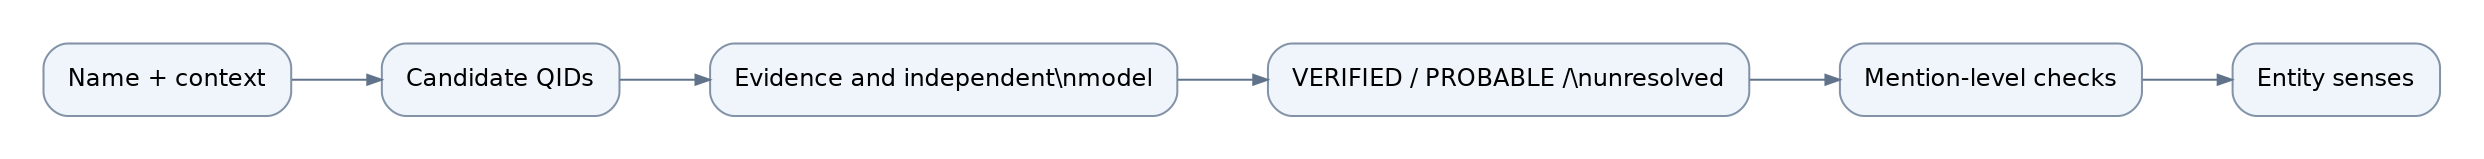


## 3 Entity linking

**Purpose:** find possible real-world identities for each name. Retrieval supplies options; models and evidence decide whether any option is trustworthy.

**Further detail (optional):**

### 3a Embeddings

The original four form-level variants are kept with identical texts, so cached vectors are reused:
- `name`
- `title`
- `sent` (centroid over `ctx_sample`)
- `para` (centroid over `ctx_sample`)

**New:** every mention's marked sentence is embedded individually (`MENTION_EMB`). This is used for mention-level linking and for flagging forms whose contexts diverge.

Cosine similarity is used as a *feature* only. It is never read as a probability.

In [11]:
VARIANTS = ['name', 'title', 'sent', 'para']

def form_texts(f):
    label = TYPE_LABEL[f.type]
    ctx = mentions_by_id.loc[f.ctx_sample]
    return {'name': [f'{f.display} ({label})'],
            'title': [f'{f.display} ({label}), mentioned in the Wikipedia article: {s}' for s in f.sources[:CONFIG['k_ctx']]],
            'sent': list(ctx.sentence_marked), 'para': list(ctx.paragraph_marked)}

def centroid(v):
    c = np.asarray(v).mean(axis=0)
    return c / np.linalg.norm(c)

def build_embeddings():
    ft = [form_texts(f) for f in forms.itertuples()]
    texts = list(dict.fromkeys([t for x in ft for v in VARIANTS for t in x[v]] + list(mentions.sentence_marked)))
    vec = dict(zip(texts, embed_texts(texts)))
    embs = {v: np.vstack([centroid([vec[t] for t in x[v]]) for x in ft]) for v in VARIANTS}
    m_emb = np.vstack([vec[t] for t in mentions.sentence_marked])
    return embs, m_emb

calls_before = api_calls()
EMBS, MENTION_EMB = build_embeddings()
MENTION_POS = {m: i for i, m in enumerate(mentions.mention_id)}
print('API calls:', api_calls_since(calls_before))
print(f"form vectors: {len(forms)} x {EMBS['name'].shape[1]} | mention vectors: {MENTION_EMB.shape}")

API calls: {'api_cohere': 18}
form vectors: 317 x 1536 | mention vectors: (674, 1536)


### 3b Wikipedia / Wikidata retrieval

**Purpose:** retrieve possible Wikipedia/Wikidata identities, including redirects and aliases. A retrieved candidate is not automatically verified.

**Further detail (optional):**

Candidates per form:
- the exact Wikipedia title or redirect resolution, non-disambiguation (a **source link**);
- `wbsearchentities` (top `wd_search_limit`);
- for LOC, the OSM `extratags.wikidata` tag of the existing geocode (step 3c, also a source link).

Facts per candidate (Wikidata `wbgetentities`, 50 QIDs per call): label, description, **aliases**, sitelinks, P31 (with `P279*` class roots), P625, P17, P131, P361, P749, P106. Claims keep SPARQL `wdt:` semantics: preferred-rank statements if any, else normal rank, never deprecated. Class roots are found by walking `P279` parents upward, and each class's parents are cached in `wikidata_superclasses`. This replaced SPARQL because `query.wikidata.org` often timed out (HTTP 502/504) on the batched queries, and every failed batch cost minutes of retries.

**v2 fix (V1).** Labels and aliases are read in `en` **and `mul`**. Wikidata's language-neutral `mul` code now holds many names that apply in all Latin-script languages. For example, the aliases of Emmanuel Macron (Q3052772) are all `mul`, among them "Macron". The v1 query read only `en`, so it returned no aliases for Q3052772, Q7747 (Putin) or Q458 (EU). The entity-facts cache is versioned `v3` because its content changed. The title, search and class caches are reused.

Every lookup records `ok` or `RETRIEVAL_FAILED`. A failed batch is not cached and is retried on the next run.

In [12]:
WP = JsonCache('wikipedia_titles')                               # original cache, same semantics
WDS = JsonCache(f"wikidata_search_{CONFIG['cache_version']}")   # limit changed (5 -> 7)
WDE = JsonCache(f"wikidata_entities_{CONFIG['entity_cache_version']}")  # v3: en + mul labels/aliases, sitelinks, relations
WDC = JsonCache('wikidata_classes')                             # original cache, same semantics
SUPER = JsonCache('wikidata_superclasses')                      # class -> truthy P279 parents (for the class walk)
WIKI_API, WD_API = 'https://en.wikipedia.org/w/api.php', 'https://www.wikidata.org/w/api.php'
_BAD_TITLE = re.compile(r'[#<>\[\]{}|]')
_QID = re.compile(r'Q\d+')
RETRIEVAL_FAILURES = []  # (stage, item, error)

def record_failures(stage, items, e):
    RETRIEVAL_FAILURES.extend((stage, x, str(e)) for x in items)

def resolve_titles(titles):
    """title -> {wp_title, was_redirect, is_disambiguation, wp_qid} or {'failed': error} (MediaWiki API, cached)."""
    todo = [t for t in dict.fromkeys(titles) if t not in WP]
    for t in [t for t in todo if _BAD_TITLE.search(t) or not t.strip()]:
        WP.set(t, {'wp_title': None, 'was_redirect': False, 'is_disambiguation': False, 'wp_qid': None})
    todo = [t for t in todo if t not in WP]
    failed = {}
    for i in range(0, len(todo), 50):
        batch = todo[i:i + 50]
        try:
            q = fetch_json(WIKI_API, {'action': 'query', 'titles': '|'.join(batch), 'redirects': 1, 'prop': 'pageprops',
                                      'ppprop': 'wikibase_item|disambiguation', 'format': 'json', 'formatversion': 2})['query']
        except RetrievalError as e:
            failed.update(dict.fromkeys(batch, str(e)))
            record_failures('wikipedia_titles', batch, e)
            continue
        normalized = {d['from']: d['to'] for d in q.get('normalized', [])}
        redirects = {d['from']: d['to'] for d in q.get('redirects', [])}
        pages = {p['title']: p for p in q.get('pages', [])}
        for t in batch:
            cur, hops = normalized.get(t, t), 0
            while cur in redirects and hops < 5:
                cur, hops = redirects[cur], hops + 1
            p = pages.get(cur, {})
            ok = bool(p) and not p.get('missing') and not p.get('invalid')
            props = p.get('pageprops', {})
            WP.set(t, {'wp_title': cur if ok else None, 'was_redirect': hops > 0,
                       'is_disambiguation': 'disambiguation' in props, 'wp_qid': props.get('wikibase_item') if ok else None})
    WP.save()
    return {t: ({'failed': failed[t]} if t in failed else WP.get(t)) for t in titles}

def wd_search(text):
    if text not in WDS:
        try:
            r = fetch_json(WD_API, {'action': 'wbsearchentities', 'search': text, 'language': 'en', 'uselang': 'en',
                                    'type': 'item', 'limit': CONFIG['wd_search_limit'], 'format': 'json'})
        except RetrievalError as e:
            record_failures('wikidata_search', [text], e)
            return None
        WDS.set(text, [{'qid': h['id'], 'label': h.get('label'), 'description': h.get('description'),
                        'match_type': h.get('match', {}).get('type'), 'match_text': h.get('match', {}).get('text')}
                       for h in r.get('search', [])])
    return WDS.get(text)

**Implementation detail:** `_wbget()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [13]:

# Wikidata facts come from the Action API (wbgetentities, 50 ids per call) instead of SPARQL:
# query.wikidata.org times out (502/504) on batched fact and P279* queries, and each failure cost minutes of retries.
def _wbget(ids, props):
    """QID -> entity JSON (en + mul terms). A redirected QID is keyed by the id that was asked for."""
    r = fetch_json(WD_API, {'action': 'wbgetentities', 'ids': '|'.join(ids), 'props': props, 'languages': 'en|mul', 'format': 'json'})
    if 'error' in r:
        raise RetrievalError(f"www.wikidata.org: {r['error'].get('code')}")
    return {e.get('redirects', {}).get('from', k): e for k, e in r.get('entities', {}).items()}

def _truthy(claims, prop):
    """Values of the best-rank statements, the same set SPARQL's wdt: returns (preferred if any, else normal)."""
    st = [s for s in claims.get(prop, []) if s.get('rank') != 'deprecated']
    best = [s for s in st if s.get('rank') == 'preferred'] or st
    return [s['mainsnak']['datavalue']['value'] for s in best if s['mainsnak'].get('snaktype') == 'value']

def _item_ids(values):
    return list(dict.fromkeys(v['id'] for v in values if isinstance(v, dict) and str(v.get('id', '')).startswith('Q')))

REL_PROPS = {'P31': 'p31', 'P131': 'p131', 'P361': 'p361', 'P749': 'p749', 'P17': 'p17', 'P106': 'p106'}

def fetch_entities(qids, batch=50):
    """Label, description, aliases, sitelink count, coordinates and relation claims per QID (one wbgetentities call per batch)."""
    todo = [q for q in dict.fromkeys(qids) if q and _QID.fullmatch(q) and q not in WDE]
    for i in range(0, len(todo), batch):
        chunk = todo[i:i + batch]
        try:
            ents = _wbget(chunk, 'labels|descriptions|aliases|sitelinks|claims')
        except RetrievalError as e:
            record_failures('wikidata_entities', chunk, e)
            continue
        for q in chunk:
            e = ents.get(q, {})
            labels, aliases, claims = e.get('labels', {}), e.get('aliases', {}), e.get('claims', {})
            coord = next(iter(_truthy(claims, 'P625')), None)
            WDE.set(q, {'label': (labels.get('en') or labels.get('mul') or {}).get('value'),
                        'description': e.get('descriptions', {}).get('en', {}).get('value'),
                        'aliases': list(dict.fromkeys(a['value'] for lang in ('en', 'mul') for a in aliases.get(lang, []))),
                        'sitelinks': len(e.get('sitelinks', {})),
                        'lat': coord['latitude'] if coord else None, 'lon': coord['longitude'] if coord else None,
                        **{v: _item_ids(_truthy(claims, p)) for p, v in REL_PROPS.items()}})
        WDE.save()

CLASS_ROOTS = {'is_org': 'Q43229', 'is_admin': 'Q56061', 'is_geo': 'Q2221906'}

def fetch_classes(classes, batch=50):
    """Class root flags (P279* to CLASS_ROOTS), by walking cached P279 parents upward level by level."""
    todo = [c for c in dict.fromkeys(classes) if c and _QID.fullmatch(c) and c not in WDC]
    seen, frontier = set(todo), list(todo)
    while frontier:
        need = [c for c in frontier if c not in SUPER]
        for i in range(0, len(need), batch):
            chunk = need[i:i + batch]
            try:
                ents = _wbget(chunk, 'claims')
            except RetrievalError as e:
                record_failures('wikidata_classes', chunk, e)
                continue
            for c in chunk:
                SUPER.set(c, _item_ids(_truthy(ents.get(c, {}).get('claims', {}), 'P279')))
            SUPER.save()
        frontier = list(dict.fromkeys(p for c in frontier for p in SUPER.data.get(c, []) if p not in seen))
        seen.update(frontier)
    for c in todo:
        anc, stack, complete = set(), [c], True
        while stack:
            x = stack.pop()
            if x in anc:
                continue
            anc.add(x)
            if x not in SUPER:
                complete = False  # a failed fetch on the path: not cached, retried next run
                continue
            stack.extend(SUPER.data[x])
        if complete:
            WDC.set(c, {n: root in anc for n, root in CLASS_ROOTS.items()})
    WDC.save()

**Implementation detail:** `NON_ENTITY_CLASSES` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [14]:

NON_ENTITY_CLASSES = {'Q4167410', 'Q13406463', 'Q4167836', 'Q11266439', 'Q101352'}  # disambiguation, list, category, template, family name

def entity_kind(qid):
    """Coarse KB class of a QID: human / geo / org flags from P31 (+ P279* roots). Coordinates alone do not make a place."""
    e = WDE.get(qid) or {}
    p31 = e.get('p31', [])
    classes = [WDC.get(c) or {} for c in p31]
    return {'non_entity': bool(NON_ENTITY_CLASSES & set(p31)) or not p31, 'is_human': 'Q5' in p31,
            'is_org': any(c.get('is_org') for c in classes),
            'is_geo': any(c.get('is_geo') or c.get('is_admin') for c in classes)}

def type_compat(form_type, qid):
    """PER: human. LOC: geographic/administrative class, not human. ORG: any non-human entity
    (NER tags states, units and events as ORG; Wikidata's org hierarchy is too broad to be a filter)."""
    k = entity_kind(qid)
    if k['non_entity']:
        return False
    return {'PER': k['is_human'], 'LOC': k['is_geo'] and not k['is_human'], 'ORG': not k['is_human']}[form_type]

def norm_set(qid):
    e = WDE.get(qid) or {}
    return {normalize(x) for x in [e.get('label')] + e.get('aliases', []) if x}

In [15]:
calls_before = api_calls()
TITLE_INFO = resolve_titles(list(forms.display))
SEARCH = {}
for n, d in enumerate(forms.display.unique()):
    SEARCH[d] = wd_search(d)
    if n % 50 == 49:
        WDS.save()
WDS.save()

www.wikidata.org: HTTP 429 - retrying in 17s


### 3c OSM evidence (LOC only), with geocoding provenance

**Purpose:** add existing OSM/geocoding evidence for locations. This does not re-geocode the input.

**Further detail (optional):**

The existing geocode per LOC string is joined as-is (no re-geocoding). An **additive, cached** Nominatim `/lookup` by the existing `osm_type + osm_id` adds:
- `extratags.wikidata`: the OSM object's own Wikidata link, a source link independent of the Wikipedia title;
- the boundary polygon (`polygon_geojson`, simplified by `nominatim_polygon_threshold`).

Polygons are used only as spatial diagnostics and as counter-evidence against identity (step 5). They never create relations or merges.

Three confidences are kept separate:
- `geocode_importance` (Nominatim's own score for the geocode);
- the entity-link score (step 3d);
- the merge decision (step 6).

In [16]:
OSM_COLS = ['osm_type', 'osm_id', 'osm_class', 'osm_kind', 'place_rank', 'addresstype', 'importance', 'latitude', 'longitude', 'display_name']
NOM = JsonCache(f"nominatim_lookup_{CONFIG['cache_version']}")

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = (np.radians(np.asarray(x, dtype=float)) for x in (lat1, lon1, lat2, lon2))
    h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(h))

def osm_ref(t, i):
    return f'{str(t)[0].upper()}{int(i)}' if isinstance(t, str) and t and pd.notna(i) else None

def nominatim_lookup(refs, batch=40):
    todo = [r for r in dict.fromkeys(refs) if r and r not in NOM]
    for i in range(0, len(todo), batch):
        chunk = todo[i:i + batch]
        try:
            res = fetch_json('https://nominatim.openstreetmap.org/lookup',
                             {'osm_ids': ','.join(chunk), 'format': 'json', 'extratags': 1, 'polygon_geojson': 1,
                              'polygon_threshold': CONFIG['nominatim_polygon_threshold']}, min_interval=1.0)
        except RetrievalError as e:
            record_failures('nominatim_lookup', chunk, e)
            continue
        got = {}
        for x in res:
            ref = osm_ref(x.get('osm_type'), x.get('osm_id'))
            got[ref] = {'wikidata': (x.get('extratags') or {}).get('wikidata'), 'geojson': x.get('geojson'),
                        'class': x.get('class'), 'type': x.get('type'), 'place_rank': x.get('place_rank')}
        for r in chunk:
            NOM.set(r, got.get(r, {'wikidata': None, 'geojson': None, 'missing': True}))
        NOM.save()

def attach_osm(forms):
    osm = geos.drop_duplicates('word').set_index('word')[[c for c in OSM_COLS if c in geos.columns]]
    joined = osm.reindex(forms.word).reset_index(drop=True)
    joined.index = forms.index
    joined.loc[forms.type != 'LOC', :] = None
    # also drop geocode_importance (the renamed `importance`) so re-running this cell does not duplicate the column
    out = pd.concat([forms.drop(columns=[*joined.columns, 'geocode_importance'], errors='ignore'), joined], axis=1)
    out['has_osm'] = out.osm_id.notna()
    out['osm_ref'] = [osm_ref(t, i) if h else None for t, i, h in zip(out.osm_type, out.osm_id, out.has_osm)]
    if CONFIG['use_osm']:
        nominatim_lookup([r for r in out.osm_ref if r])
    look = [NOM.get(r) or {} if r else {} for r in out.osm_ref]
    out['osm_wikidata'] = [x.get('wikidata') for x in look]
    out['has_polygon'] = [bool(x.get('geojson')) and (x.get('geojson') or {}).get('type') in ('Polygon', 'MultiPolygon') for x in look]
    out = out.rename(columns={'importance': 'geocode_importance'}) if 'importance' in out else out
    return out

forms = attach_osm(forms)
assert forms.columns.is_unique, forms.columns[forms.columns.duplicated()].tolist()
loc = forms[forms.type == 'LOC']
print(f"LOC forms with a geocode: {loc.has_osm.sum()}/{len(loc)} | with an OSM wikidata tag: {loc.osm_wikidata.notna().sum()} | with a polygon: {loc.has_polygon.sum()}")

LOC forms with a geocode: 88/95 | with an OSM wikidata tag: 81 | with a polygon: 79


In [17]:
# Facts for every candidate QID (title/redirect, search hits, OSM tag), then class roots for their P31 values
cand_qids = set()
for d in forms.display:
    ti = TITLE_INFO.get(d) or {}
    if ti.get('wp_qid'):
        cand_qids.add(ti['wp_qid'])
    cand_qids |= {h['qid'] for h in (SEARCH.get(d) or [])}
cand_qids |= set(forms.osm_wikidata.dropna())
fetch_entities(cand_qids)
fetch_classes({c for q in cand_qids for c in (WDE.get(q) or {}).get('p31', [])})
print('API calls:', api_calls_since(calls_before))
print(f'candidate QIDs: {len(cand_qids)} | retrieval failures so far: {len(RETRIEVAL_FAILURES)}')
if RETRIEVAL_FAILURES:
    display(pd.DataFrame(RETRIEVAL_FAILURES, columns=['stage', 'item', 'error']).groupby('stage').size())

API calls: {'api_en.wikipedia.org': 7, 'api_www.wikidata.org': 404, 'api_nominatim.openstreetmap.org': 2}
candidate QIDs: 1266 | retrieval failures so far: 0


### 3d Candidate features, link models, identity status

**Purpose:** compare each form with its possible identities using name, source, context, and geographic evidence. Independent scoring helps avoid trusting a source link merely because it exists.

**Further detail (optional):**

**Candidate features** (one row per form × candidate):
- `name_sim`: best fuzzy match against the label and aliases. `name_exact`: the normalized form equals a label or alias.
- `type_ok`: see `type_compat`. `entity_like`: not a disambiguation page, list, category, template or family name.
- `src_title` / `src_osm`: the candidate is the form's Wikipedia title link / the OSM tag of its geocode.
- `search_rr`: reciprocal rank in Wikidata search.
- `prior`: log sitelinks, a popularity prior.
- `ctx`: cosine of the form's sentence centroid against `label — description`.
  - It is computed for type-compatible candidates and, in v2, also for **entity-like candidates of any type whose name matches** (`name_sim ≥ 0.8`).
  - Those extra rows are never linked to. They are the alternatives an ambiguous alias must beat (step 5).
- `geo_close`: LOC within 50 km of the geocode.

**Two link models**, both logistic regressions trained on **dev** forms with a gold QID (label = candidate is the gold QID):
- the **main model** (all features), which gives the probabilistic `model_link_qid`;
- the **independent model**, which leaves out the source-link features `src_title` / `src_osm`. It is used:
  - (i) to confirm a source link without relying on it;
  - (ii) for mention-level linking (v2 fix V4). The v1 mention scores reused the form-level source features, so every mention followed the form's title link and mentions could never disagree.

`link_min` / `link_margin` are grid-searched on dev to maximise F0.5 (precision-weighted). `m_margin`, the mention-level margin, is tuned on dev mention labels. Without gold, each value comes from the saved calibration or the documented default, marked UNTUNED.

**Three provenance fields per form** (never collapsed):
- `source_link_qid` + `source_link_kind`:
  - `title` / `redirect`: the Wikipedia resolution, non-disambiguation, type-compatible;
  - `+osm` when the geocode's OSM tag agrees;
  - `osm_only` when only the OSM tag gives it.
- `model_qid`, `model_score`, `model_margin`.
- `human_qid`: from review labels (`ER_DIR/review/mention_labels.csv`), never from gold.

**`id_status = VERIFIED`** (v2 fix V5) needs either a human label, or **all** of:
1. a `title`/`redirect` source link. An OSM tag alone is a geocoder's guess of what the string means, so `osm_only` is at most PROBABLE;
2. the **independent model agrees**: its top candidate is the source QID and passes `link_min` / `link_margin`. This is positive support from name, prior, search and context, even when the form has only one candidate;
3. **context support**: in at least `ctx_support_min` of the form's mentions, no name-plausible competitor beats the source QID on mention context by more than `ctx_veto_margin`. v1 used "any mention", so frequent forms failed and one-mention forms passed;
4. the form is not ambiguity-suspected.

A similarity score never produces VERIFIED on its own. Only VERIFIED (or human) identities create hard constraints.

**`link_status`:**
- `PROBABLE`: the main model's top candidate passes `link_min` and `link_margin`;
- `UNRESOLVED`: there are plausible candidates, but none passes;
- `NIL`: retrieval succeeded and no type-compatible candidate matches the name;
- `RETRIEVAL_FAILED`.

In [18]:
LINK_FEATURES_ALL = ['name_sim', 'name_exact', 'src_title', 'src_osm', 'search_rr', 'prior', 'ctx', 'geo_close']
SRC_FEATURES, CTX_FEATURES = {'src_title', 'src_osm'}, {'ctx'}
DEFAULT_WEIGHTS = {'name_sim': 1.0, 'name_exact': 1.0, 'src_title': 1.5, 'src_osm': 1.5, 'search_rr': 0.5, 'prior': 0.5, 'ctx': 1.0, 'geo_close': 0.5}

def candidate_table(forms):
    """Collect and filter possible external knowledge-base links for each surface form."""
    rows = []
    for i, f in forms.iterrows():
        ti = TITLE_INFO.get(f.display) or {}
        hits = SEARCH.get(f.display)
        failed = ('failed' in ti) or hits is None
        cands = {}
        if ti.get('wp_qid') and not ti.get('is_disambiguation'):
            cands[ti['wp_qid']] = {'src_title': 1}
        for r, h in enumerate(hits or []):
            cands.setdefault(h['qid'], {})['search_rank'] = min(r, cands.get(h['qid'], {}).get('search_rank', 99))
        if f.type == 'LOC' and isinstance(f.osm_wikidata, str):
            cands.setdefault(f.osm_wikidata, {})['src_osm'] = 1
        for q, c in cands.items():
            e = WDE.get(q)
            if e is None:  # facts not retrieved for this QID (failure): keep it out, the form is marked failed below
                failed = True
                continue
            names = norm_set(q)
            km = (float(haversine_km(f.latitude, f.longitude, e['lat'], e['lon']))
                  if f.type == 'LOC' and f.has_osm and e.get('lat') is not None else np.nan)
            rows.append({'form_idx': i, 'form_id': f.form_id, 'type': f.type, 'qid': q,
                         'label': e.get('label'), 'description': e.get('description'),
                         'type_ok': type_compat(f.type, q), 'entity_like': not entity_kind(q)['non_entity'],
                         'src_title': c.get('src_title', 0), 'src_osm': c.get('src_osm', 0),
                         'search_rr': 1 / (1 + c['search_rank']) if 'search_rank' in c else 0.0,
                         'name_sim': max([fuzz.WRatio(f.norm, n) / 100 for n in names], default=0.0),
                         'name_exact': float(f.norm in names or f.translit in {translit_key(n) for n in names}),
                         'prior': math.log1p(e.get('sitelinks', 0)) / math.log1p(400), 'geo_km': km,
                         'geo_close': float(km <= 50) if not np.isnan(km) else 0.0, 'retrieval_failed': failed})
        if not cands:
            rows.append({'form_idx': i, 'form_id': f.form_id, 'type': f.type, 'qid': None, 'type_ok': False, 'entity_like': False,
                         'retrieval_failed': failed})
    ct = pd.DataFrame(rows)
    ct['retrieval_failed'] = ct.groupby('form_idx').retrieval_failed.transform('max')
    ct['name_plausible'] = (ct.name_sim.fillna(0) >= 0.8) | (ct.name_exact.fillna(0) == 1)
    # Context similarity: form sentence centroid vs "label — description".
    # Rows: type-compatible candidates + name-plausible entity-like candidates of any type (alternatives for §5).
    real = ct.qid.notna() & (ct.type_ok | (ct.entity_like & ct.name_plausible))
    ct['ctx'] = 0.0
    ct['_desc_row'] = np.nan
    if real.any():
        desc_q = list(dict.fromkeys(ct.loc[real, 'qid']))
        desc_texts = [((WDE.get(q) or {}).get('label') or q) + ' — ' + ((WDE.get(q) or {}).get('description') or '') for q in desc_q]
        globals()['_DESC_VECS'] = embed_texts(desc_texts)
        globals()['QID_DESC_ROW'] = {q: k for k, q in enumerate(desc_q)}
        ct.loc[real, '_desc_row'] = ct.loc[real, 'qid'].map(QID_DESC_ROW)
        ct.loc[real, 'ctx'] = (_DESC_VECS[ct.loc[real, '_desc_row'].astype(int).values] * EMBS['sent'][ct.loc[real, 'form_idx'].values]).sum(axis=1)
    return ct.fillna({c: 0.0 for c in LINK_FEATURES_ALL})

CANDS = candidate_table(forms)
print(f'candidate rows: {len(CANDS)} | type-compatible: {int(CANDS.type_ok.sum())} | '
      f'name-plausible alternatives of other types (context only): {int((~CANDS.type_ok & CANDS.entity_like & CANDS.name_plausible).sum())} | '
      f'forms with failed retrieval: {CANDS[CANDS.retrieval_failed].form_idx.nunique()}')

candidate rows: 1398 | type-compatible: 765 | name-plausible alternatives of other types (context only): 445 | forms with failed retrieval: 0


In [19]:
def link_features(variant, independent=False):
    return [f for f in LINK_FEATURES_ALL
            if (variant.get('use_embeddings', True) or f not in CTX_FEATURES) and not (independent and f in SRC_FEATURES)]

def fit_link_model(cands, variant, independent=False):
    """Logistic regression on dev forms with a gold QID; returns (model, features) or (None, features)."""
    feats = link_features(variant, independent)
    dev = dev_gold_forms()
    if dev is None:
        return None, feats
    gold_q = dev[dev.gold_status == 'VERIFIED_QID'].gold_qid
    tr = cands[cands.form_id.isin(gold_q.index) & cands.type_ok & cands.qid.notna()].copy()
    tr['y'] = (tr.qid == tr.form_id.map(gold_q)).astype(int)
    if tr.y.nunique() < 2:
        return None, feats
    model = LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000, random_state=CONFIG['seed'])
    model.fit(tr[feats].values, tr.y.values)
    return model, feats

def score_candidates(cands, model, feats, ctx_override=None):
    """Model score per candidate row (0 for type-incompatible); ctx_override replaces the form-level ctx (mention level)."""
    x = cands[feats].copy()
    if ctx_override is not None and 'ctx' in feats:
        x['ctx'] = ctx_override
    if model is None:  # untuned fallback: documented fixed weights, flagged in the output
        s = sum(x[f] * DEFAULT_WEIGHTS[f] for f in feats) / sum(DEFAULT_WEIGHTS[f] for f in feats)
    else:
        s = model.predict_proba(x.values)[:, 1]
    return np.where(cands.type_ok & cands.qid.notna(), s, 0.0)

def top2(g, col='score'):
    g = g[g.type_ok & g.qid.notna()].sort_values(col, ascending=False)
    if not len(g):
        return None, 0.0, 0.0
    second = g[col].iloc[1] if len(g) > 1 else 0.0
    return g.qid.iloc[0], float(g[col].iloc[0]), float(g[col].iloc[0] - second)

def link_decision(qid, score, margin, link_min, link_margin):
    return qid if qid is not None and score >= link_min and margin >= link_margin else None

def f_beta_counts(tp, fp, pos, beta=None):
    beta2 = (CONFIG['f_beta'] if beta is None else beta) ** 2
    p, r = (tp / (tp + fp) if tp + fp else 0), (tp / pos if pos else 0)
    return (1 + beta2) * p * r / (beta2 * p + r) if p + r else 0

def tune_link_thresholds(cands, forms):
    """Grid search link_min / link_margin on dev forms (gold VERIFIED_QID or NIL), maximising F0.5 of linked predictions.
    Returns (link_min, link_margin, how) or None without dev labels."""
    dev = dev_gold_forms()
    if dev is None:
        return None
    dev = dev[dev.gold_status.isin(['VERIFIED_QID', 'NIL'])]
    preds = {fid: top2(g) for fid, g in cands[cands.form_id.isin(dev.index)].groupby('form_id')}
    best = (-1, 0.5, 0.1)
    pos = (dev.gold_status == 'VERIFIED_QID').sum()
    for lm in np.arange(0.2, 0.95, 0.05):
        for mg in [0.0, 0.05, 0.1, 0.2, 0.3]:
            tp = fp = 0
            for fid, (q, s, m) in preds.items():
                p = link_decision(q, s, m, lm, mg)
                if p is not None:
                    tp += p == dev.at[fid, 'gold_qid']
                    fp += p != dev.at[fid, 'gold_qid']
            f = f_beta_counts(tp, fp, pos)
            if f > best[0] + 1e-9:
                best = (f, round(float(lm), 2), mg)
    return best[1], best[2], f'dev F{CONFIG["f_beta"]}={best[0]:.3f}'

**Mention-level linking, ambiguity and senses.**
- Each mention is scored with the **independent** model (no form-level source features), using its own sentence as context.
  - `mention_qid` passes `link_min` and the mention margin `m_margin`.
  - `m_margin` is tuned on dev mention labels: the gold mention labels of ambiguous forms, plus the mentions of dev single-identity forms.
- **Ambiguity is flagged, not resolved.** `ambiguity_suspected` is set when:
  - (a) two type-compatible candidates both pass `link_min` within `link_margin`;
  - (b) the form's mention contexts split into ≥2 clusters. This uses average-linkage cosine with `ctx_cluster_dist`, tuned on dev forms whose gold mention labels name ≥2 identities (F0.5).
    - (b) is always computed, reported (`amb_report`) and evaluated (step 10). Without dev labels, the calibration or the default distance is used, never `None`.
    - Context clusters measure how varied the topics around a name are. That is not the same as the name referring to different things: Putin is discussed in many contexts and is still one person.
    - So (b) **blocks** automatic merges and verification only when its dev precision reaches `amb_b_min_precision` (`ctx_cluster_blocks`). Otherwise it is report-only. The default without dev evidence is report-only, marked UNTUNED;
  - (c) mentions are linked to different QIDs;
  - (d) the Wikipedia title link and the geocode's OSM tag name different QIDs.
- **A form is split into senses only with disambiguation evidence**: (c), or human mention labels.
  - Each mention-QID group becomes a sense.
  - Mentions that are not resolved go to a flagged placeholder sense `…#unresolved`, which never auto-merges.
- A form flagged only by (a), (b) or (d) keeps one sense, is not VERIFIED, and is excluded from automatic merges.

In [20]:
def context_clusters(mention_ids, dist):
    if len(mention_ids) < 2 or dist is None:
        return 1
    X = MENTION_EMB[[MENTION_POS[m] for m in mention_ids]]
    if len(mention_ids) > 200:
        X = X[RNG.choice(len(X), 200, replace=False)]
    lab = AgglomerativeClustering(n_clusters=None, metric='cosine', linkage='average', distance_threshold=dist).fit_predict(X)
    return len(set(lab))

def gold_ambiguous_forms(gm):
    """Forms whose gold mention labels name >= 2 distinct identities (truly ambiguous surface forms)."""
    if gm is None or not len(gm):
        return set()
    ok = gm[gm.gold_status.isin(['VERIFIED_QID', 'NIL'])]
    n = ok.groupby('form_id').gold_entity.nunique()
    return set(n[n >= 2].index)

def tune_cluster_dist(forms, variant):
    """Distance threshold whose flags best recover truly ambiguous dev forms among dev forms with >=2 mentions (F0.5),
    and whether the signal is precise enough to block merges. Returns (dist or None, blocks or None, how)."""
    dev = dev_gold_forms()
    if dev is None:
        return None, None, 'no dev labels'
    if not variant.get('use_embeddings', True):
        return None, None, 'embeddings off'
    multi = forms[forms.form_id.isin(dev.index) & (forms.n_mentions >= 2)]
    amb = gold_ambiguous_forms(dev_gold_mentions())
    y = multi.form_id.isin(amb).values
    if y.sum() == 0:
        return None, None, 'no truly ambiguous dev forms'
    best = (-1, None, 0.0, 0, 0)
    for d in [0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
        pred = np.array([context_clusters(ids, d) >= 2 for ids in multi.mention_ids])
        tp, fp = int((pred & y).sum()), int((pred & ~y).sum())
        f = f_beta_counts(tp, fp, int(y.sum()))
        if f > best[0] + 1e-9:
            best = (f, d, tp / (tp + fp) if tp + fp else 0.0, tp, fp)
    if best[0] <= 0:
        return None, False, f'no distance flags any of the {int(y.sum())} ambiguous dev forms -> report-only'
    blocks = best[2] >= CONFIG['amb_b_min_precision']
    return best[1], blocks, (f"dev F{CONFIG['f_beta']}={best[0]:.2f}, precision {best[2]:.2f} (TP {best[3]}, FP {best[4]}) on {len(multi)} dev forms "
                             f"({int(y.sum())} ambiguous) -> {'blocks merges' if blocks else 'report-only'}")

def load_human_mention_labels():
    p = REVIEW_DIR / 'mention_labels.csv'  # columns: mention_id, label (QID | NIL | UNCERTAIN), reviewer, timestamp
    if not p.exists():
        return {}
    lab = pd.read_csv(p, keep_default_na=False).sort_values('timestamp').drop_duplicates('mention_id', keep='last')
    return dict(zip(lab.mention_id, lab.label))

def form_link_status(model_q, failed, has_name_match, src_q):
    """PROBABLE if the model link passes; RETRIEVAL_FAILED if any lookup failed (never read as NIL);
    NIL only when retrieval succeeded and nothing type-compatible matches the name; otherwise UNRESOLVED."""
    if model_q:
        return 'PROBABLE'
    if failed:
        return 'RETRIEVAL_FAILED'
    if not has_name_match and src_q is None:
        return 'NIL'
    return 'UNRESOLVED'

**Implementation detail:** `dev_mention_gold()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [21]:

def dev_mention_gold():
    """mention_id -> gold QID ('NIL' for NIL) on dev: mention labels + mentions of dev single-identity forms."""
    dev = dev_gold_forms()
    if dev is None:
        return {}
    by_form = mentions.groupby('form_id').mention_id.apply(list).to_dict()
    out = {}
    for fid, r in dev[dev.gold_status.isin(['VERIFIED_QID', 'NIL'])].iterrows():
        for m in by_form.get(fid, []):
            out[m] = r.gold_qid or 'NIL'
    gm = dev_gold_mentions()
    if len(gm):
        for r in gm[gm.gold_status.isin(['VERIFIED_QID', 'NIL'])].itertuples():
            out[r.mention_id] = r.gold_qid or 'NIL'
    return out

def tune_m_margin(mrows, link_min):
    """Mention margin maximising F0.5 of mention links on dev mention labels. Returns (value or None, how)."""
    gold = dev_mention_gold()
    sub = [r for r in mrows if r['mention_id'] in gold]
    if not sub:
        return None, 'no dev mention labels'
    pos = sum(gold[r['mention_id']] != 'NIL' for r in sub)
    best = (-1, None)
    for mg in [0.0, 0.02, 0.05, 0.1, 0.2, 0.3]:
        tp = fp = 0
        for r in sub:
            q = link_decision(r['q'], r['s'], r['m'], link_min, mg)
            if q is not None:
                tp, fp = tp + (q == gold[r['mention_id']]), fp + (q != gold[r['mention_id']])
        f = f_beta_counts(tp, fp, pos)
        if f > best[0] + 1e-9:
            best = (f, mg)
    return best[1], f'dev mention F{CONFIG["f_beta"]}={best[0]:.3f} on {len(sub)} mentions'

def context_support(src_q, mm, plausible, veto):
    """Share of mentions whose context does not prefer a name-plausible competitor over src_q by more than `veto`.
    1.0 when no mention-level context is available (embeddings off)."""
    if src_q is None:
        return 0.0
    if mm is None or not len(mm):
        return 1.0
    ok = []
    for d in mm.ctx_by_q:
        if not d or src_q not in d:
            ok.append(True)
            continue
        comp = [v for k, v in d.items() if k != src_q and k in plausible]
        ok.append(not comp or max(comp) - d[src_q] <= veto)
    return float(np.mean(ok))

VERIFY_KINDS = {'title', 'redirect', 'title+osm', 'redirect+osm'}

**Implementation detail:** `verified_mask()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [22]:

def verified_mask(forms, support, support_min):
    return (forms.source_link_kind.isin(VERIFY_KINDS) & forms.indep_agrees & (pd.Series(support, index=forms.index) >= support_min)
            & ~forms.ambiguity_suspected)

def tune_verification(forms, support_by_veto, variant):
    """(ctx_veto_margin, ctx_support_min) maximising F0.5 of VERIFIED source links on dev forms with gold QID/NIL."""
    dev = dev_gold_forms()
    if dev is None or not variant.get('use_embeddings', True):
        return None, None, 'no dev labels' if dev is None else 'embeddings off'
    dev = dev[dev.gold_status.isin(['VERIFIED_QID', 'NIL'])]
    on_dev = forms.form_id.isin(dev.index)
    pos = (dev.gold_status == 'VERIFIED_QID').sum()
    best = (-1, None, None)
    for veto, support in support_by_veto.items():
        for smin in [0.5, 0.67, 0.8, 1.0]:
            sel = forms[verified_mask(forms, support, smin) & on_dev]
            ok = (sel.source_link_qid.values == sel.form_id.map(dev.gold_qid).values)
            f = f_beta_counts(int(ok.sum()), int((~ok).sum()), pos)
            if f > best[0] + 1e-9:
                best = (f, veto, smin)
    return best[1], best[2], f'dev F{CONFIG["f_beta"]} of VERIFIED links={best[0]:.3f}'

VETO_GRID = [0.0, 0.02, 0.05, 0.1, 0.15, 0.2, 1.0]

# Columns run_linking adds. They are dropped on entry, so re-running this cell (or linking already-linked forms) never duplicates them.
LINK_OUT_COLS = ['source_link_qid', 'source_link_kind', 'source_link_context_ok', 'context_support', 'title_osm_disagree',
                 'model_qid', 'model_score', 'model_margin', 'model_link_qid', 'indep_qid', 'indep_agrees', 'human_qid',
                 'id_status', 'id_source', 'link_status', 'verified_qid', 'probable_qid', 'retrieval_failed', 'cand_competition',
                 'plausible_qids', 'ambiguity_suspected', 'amb_reason', 'amb_report']

def run_linking(forms, cands, variant, verbose=True):
    """Adds provenance fields and statuses to forms; returns (forms, mention_links, link_info)."""
    forms = forms.drop(columns=LINK_OUT_COLS, errors='ignore')
    info = {}
    rec = variant.get('record_sources', True)
    use_emb = variant.get('use_embeddings', True)
    dist = variant.get('ctx_cluster_dist') if use_emb else None
    b_blocks = bool(variant.get('ctx_cluster_blocks')) and use_emb
    if not variant.get('use_wikidata', True):
        for c, v in {'source_link_qid': None, 'source_link_kind': None, 'source_link_context_ok': False, 'context_support': 0.0,
                     'model_qid': None, 'model_score': 0.0, 'model_margin': 0.0, 'model_link_qid': None, 'indep_qid': None,
                     'indep_agrees': False, 'human_qid': None, 'id_status': 'NONE', 'id_source': '', 'link_status': 'NOT_LINKED',
                     'verified_qid': None, 'probable_qid': None, 'retrieval_failed': False, 'cand_competition': False}.items():
            forms[c] = v
        forms['ambiguity_suspected'], forms['amb_reason'] = False, ''
        forms['amb_report'] = ''
        if use_emb:
            b = np.array([context_clusters(ids, dist) >= 2 for ids in forms.mention_ids])
            forms['amb_report'] = np.where(b, 'b:context_clusters', '')
            forms['ambiguity_suspected'] = b & b_blocks
            forms['amb_reason'] = np.where(forms.ambiguity_suspected, 'b:context_clusters', '')
        ml = pd.DataFrame({'mention_id': mentions.mention_id, 'form_id': mentions.form_id, 'mention_qid': None, 'mention_status': 'NOT_LINKED'})
        info['scored_cands'] = None
        return forms, ml, info

    model, feats = fit_link_model(cands, variant)
    imodel, ifeats = fit_link_model(cands, variant, independent=True)
    cands = cands.copy()
    cands['score'] = score_candidates(cands, model, feats)
    cands['iscore'] = score_candidates(cands, imodel, ifeats)
    lm, mg = variant.get('link_min'), variant.get('link_margin')
    if lm is None:
        t = tune_link_thresholds(cands, forms) if model is not None else None
        lm = resolve_threshold('link_min', t[0] if t else None, t[2] if t else 'no dev labels', rec)
        mg = resolve_threshold('link_margin', t[1] if t else None, t[2] if t else 'no dev labels', rec)
        variant['link_min'], variant['link_margin'] = lm, mg
    info['link_model'] = 'logistic regressions (dev)' if model is not None else 'fixed weights (UNTUNED)'
    info['scored_cands'] = cands
    human = load_human_mention_labels()

    # Form level: source link (with kind), main-model link, independent-model link
    rows = []
    for i, f in forms.iterrows():
        g = cands[cands.form_idx == i]
        failed = bool(g.retrieval_failed.any()) if len(g) else False
        q, s, m = top2(g)
        tq = g[(g.src_title == 1) & g.type_ok].qid
        oq = g[(g.src_osm == 1) & g.type_ok].qid
        title_q, osm_q = (tq.iloc[0] if len(tq) else None), (oq.iloc[0] if len(oq) else None)
        if title_q:
            kind = ('redirect' if (TITLE_INFO.get(f.display) or {}).get('was_redirect') else 'title') + ('+osm' if osm_q == title_q else '')
        else:
            kind = 'osm_only' if osm_q else None
        src_q = title_q or osm_q
        iq = link_decision(*top2(g, 'iscore'), lm, mg)
        has_name_match = bool((g.type_ok & (g.name_sim >= 0.8)).any()) if len(g) else False
        model_q = link_decision(q, s, m, lm, mg)
        rows.append({'source_link_qid': src_q, 'source_link_kind': kind, 'title_osm_disagree': bool(title_q and osm_q and title_q != osm_q),
                     'model_qid': q, 'model_score': s, 'model_margin': m, 'model_link_qid': model_q,
                     'indep_qid': iq, 'indep_agrees': bool(title_q is not None and iq == title_q),
                     'link_status': form_link_status(model_q, failed, has_name_match, src_q), 'retrieval_failed': failed,
                     'cand_competition': bool(q is not None and s >= lm and m < mg and len(g[g.type_ok]) > 1),
                     'plausible_qids': set(g[g.type_ok & g.name_plausible].qid)})
    forms = pd.concat([forms.reset_index(drop=True), pd.DataFrame(rows)], axis=1)

    # Mention level: independent model with each mention's own sentence as context
    mrows = []
    have_ctx = use_emb and '_desc_row' in cands
    for f in forms.itertuples():
        g = cands[(cands.form_idx == f.Index) & cands.type_ok & cands.qid.notna()]
        for mid in f.mention_ids:
            if not len(g):
                mrows.append({'mention_id': mid, 'form_id': f.form_id, 'q': None, 's': 0.0, 'm': 0.0, 'ctx_by_q': {}})
                continue
            mctx = _DESC_VECS[g._desc_row.astype(int).values] @ MENTION_EMB[MENTION_POS[mid]] if have_ctx else None
            q, s, m = top2(g.assign(iscore=score_candidates(g, imodel, ifeats, ctx_override=mctx)), 'iscore')
            mrows.append({'mention_id': mid, 'form_id': f.form_id, 'q': q, 's': s, 'm': m,
                          'ctx_by_q': dict(zip(g.qid, mctx)) if mctx is not None else {}})
    mmg = variant.get('m_margin')
    if mmg is None:
        t, how = tune_m_margin(mrows, lm) if imodel is not None else (None, 'no dev labels')
        mmg = variant['m_margin'] = resolve_threshold('m_margin', t, how, rec)
    ml = pd.DataFrame([{'mention_id': r['mention_id'], 'form_id': r['form_id'],
                        'mention_qid': link_decision(r['q'], r['s'], r['m'], lm, mmg), 'm_top': r['q'], 'm_score': r['s'],
                        'm_margin': r['m'], 'ctx_by_q': r['ctx_by_q']} for r in mrows])

    # Ambiguity flags (a)-(d)
    by_form = dict(list(ml.groupby('form_id')))
    amb, why, report = [], [], []
    for f in forms.itertuples():
        mm = by_form.get(f.form_id)
        r = []
        if f.cand_competition:
            r.append('a:candidate_competition')
        b = use_emb and context_clusters(f.mention_ids, dist) >= 2
        report.append('b:context_clusters' if b else '')
        if b and b_blocks:
            r.append('b:context_clusters')
        if mm is not None and mm.mention_qid.dropna().nunique() >= 2:
            r.append('c:mention_qids_differ')
        if f.title_osm_disagree:
            r.append('d:title_vs_osm')
        amb.append(bool(r))
        why.append('+'.join(r))
    forms['ambiguity_suspected'], forms['amb_reason'], forms['amb_report'] = amb, why, report

    # Context support of the source link (positive support share), dev-tuned veto margin and minimum share
    support_by_veto = {v: [context_support(f.source_link_qid, by_form.get(f.form_id), f.plausible_qids, v) for f in forms.itertuples()]
                       for v in VETO_GRID}
    veto, smin = variant.get('ctx_veto_margin'), variant.get('ctx_support_min')
    if veto is None or smin is None:
        tv, ts, how = tune_verification(forms, support_by_veto, variant)
        veto = variant['ctx_veto_margin'] = resolve_threshold('ctx_veto_margin', tv, how, rec)
        smin = variant['ctx_support_min'] = resolve_threshold('ctx_support_min', ts, how, rec)
    support = support_by_veto[veto] if veto in support_by_veto else \
        [context_support(f.source_link_qid, by_form.get(f.form_id), f.plausible_qids, veto) for f in forms.itertuples()]
    forms['context_support'] = support
    forms['source_link_context_ok'] = forms.context_support >= smin

    # Human labels (review), then identity status
    hq = {}
    for f in forms.itertuples():
        labs = {human[m] for m in f.mention_ids if m in human and human[m] not in ('', 'UNCERTAIN', 'NIL')}
        hq[f.form_id] = labs.pop() if len(labs) == 1 else None
    forms['human_qid'] = forms.form_id.map(hq)
    ver = verified_mask(forms, support, smin)
    forms['id_status'] = np.select([forms.human_qid.notna(), ver, forms.model_link_qid.notna() | forms.source_link_qid.notna()],
                                   ['VERIFIED', 'VERIFIED', 'PROBABLE'], 'NONE')
    forms['id_source'] = np.select(
        [forms.human_qid.notna(), ver], ['human', 'source link + independent model + context'],
        np.where(forms.model_link_qid.notna(), 'model', np.where(forms.source_link_qid.notna(), 'source link (unconfirmed)', '')))
    forms['verified_qid'] = np.where(forms.human_qid.notna(), forms.human_qid, np.where(ver, forms.source_link_qid, None))
    forms['probable_qid'] = [v or m or s for v, m, s in zip(forms.verified_qid, forms.model_link_qid, forms.source_link_qid)]
    forms = forms.drop(columns=['plausible_qids'])
    ml['mention_status'] = np.where(ml.mention_qid.notna(), 'PROBABLE', 'UNRESOLVED')
    ml = ml.merge(forms[['form_id', 'id_status', 'verified_qid', 'link_status']], on='form_id', how='left')
    ml.loc[ml.id_status.eq('VERIFIED'), 'mention_status'] = 'VERIFIED'
    ml.loc[ml.id_status.eq('VERIFIED'), 'mention_qid'] = ml.verified_qid
    ml.loc[ml.link_status.isin(['NIL', 'RETRIEVAL_FAILED']) & ml.mention_qid.isna(), 'mention_status'] = ml.link_status
    ml_ids = set(ml.mention_id)
    for mid, lab in human.items():
        if mid in ml_ids and lab not in ('', 'UNCERTAIN'):
            ml.loc[ml.mention_id == mid, ['mention_qid', 'mention_status']] = [lab if lab != 'NIL' else None, 'VERIFIED' if lab != 'NIL' else 'NIL']
    if verbose:
        print(f"link model: {info['link_model']}")
        print(f"link_min={lm} link_margin={mg} m_margin={mmg} ctx_veto_margin={veto} ctx_support_min={smin} ctx_cluster_dist={dist} "
              f"(context clusters {'block merges' if b_blocks else 'report-only'})")
    return forms, ml.drop(columns=['id_status', 'verified_qid', 'link_status']), info

**Implementation detail:** `build_senses()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [23]:

def build_senses(forms, ml, variant):
    """Split a form into senses only with disambiguation evidence (c) or human labels; unresolved mentions of an
    ambiguous form go to a placeholder sense that never auto-merges."""
    rows, m2s = [], {}
    by_form = dict(list(ml.groupby('form_id')))
    for f in forms.itertuples():
        mm = by_form.get(f.form_id)
        groups = {None: list(f.mention_ids)}
        if f.ambiguity_suspected and mm is not None:
            # Group mentions by their own (PROBABLE / human-VERIFIED) identity; unresolved ones -> placeholder.
            # Several QIDs = disambiguation evidence (c) -> several senses. One QID and nothing unresolved -> one sense.
            g = {}
            for r in mm.itertuples():
                g.setdefault(r.mention_qid if r.mention_qid else '#unresolved', []).append(r.mention_id)
            if len([k for k in g if k != '#unresolved']) >= 2:
                groups = g
        for key, mids in groups.items():
            sid = f.form_id if key is None else f'{f.form_id}#{key.lstrip("#")}'
            placeholder = key == '#unresolved'
            sense_q = None if key in (None, '#unresolved') else key
            pos = [MENTION_POS[m] for m in mids]
            rows.append({'sense_id': sid, 'form_id': f.form_id, 'form_idx': f.Index, 'type': f.type, 'display': f.display,
                         'norm': f.norm, 'translit': f.translit, 'mention_ids': mids, 'n_mentions': len(mids),
                         'sources': list(pd.Series([mentions_by_id.at[m, 'source'] for m in mids]).value_counts().index),
                         'is_split': key is not None, 'is_placeholder': placeholder,
                         'ambiguous': bool(f.ambiguity_suspected),
                         'verified_qid': f.verified_qid if key is None else (sense_q if sense_q and mm[mm.mention_qid == sense_q].mention_status.eq('VERIFIED').all() else None),
                         'probable_qid': f.probable_qid if key is None else sense_q,
                         'id_status': f.id_status if key is None else ('UNRESOLVED' if placeholder else 'PROBABLE'),
                         'link_status': f.link_status if key is None else ('UNRESOLVED' if placeholder else 'PROBABLE'),
                         'ctx_vec': None if key is None else centroid(MENTION_EMB[pos])})
            for m in mids:
                m2s[m] = sid
    senses = pd.DataFrame(rows).reset_index(drop=True)
    return senses, m2s

LINK_VARIANT = {k: CONFIG[k] for k in ('use_wikidata', 'use_embeddings', 'use_osm')}
cd, cb, cd_how = tune_cluster_dist(forms, LINK_VARIANT)
LINK_VARIANT['ctx_cluster_dist'] = CONFIG['ctx_cluster_dist'] = resolve_threshold('ctx_cluster_dist', cd, cd_how)
LINK_VARIANT['ctx_cluster_blocks'] = CONFIG['ctx_cluster_blocks'] = resolve_threshold('ctx_cluster_blocks', cb, cd_how)
FORMS_BASE = forms.drop(columns=LINK_OUT_COLS, errors='ignore')  # pre-linking forms, reused by the ablations in §11
forms, MENTION_LINKS, LINK_INFO = run_linking(forms, CANDS, LINK_VARIANT)
assert forms.columns.is_unique, forms.columns[forms.columns.duplicated()].tolist()
CONFIG.update({k: LINK_VARIANT[k] for k in ('link_min', 'link_margin', 'm_margin', 'ctx_veto_margin', 'ctx_support_min')})
senses, MENTION_TO_SENSE = build_senses(forms, MENTION_LINKS, LINK_VARIANT)
display(pd.DataFrame([{'threshold': k, 'value': CONFIG[k], 'source': THRESHOLD_SOURCE.get(k)}
                      for k in ('link_min', 'link_margin', 'm_margin', 'ctx_veto_margin', 'ctx_support_min', 'ctx_cluster_dist', 'ctx_cluster_blocks')]))

# Checks
assert set(MENTION_TO_SENSE) == set(mentions.mention_id), 'every mention must map to exactly one sense'
assert not forms[forms.id_status.eq('VERIFIED') & forms.ambiguity_suspected & forms.human_qid.isna()].shape[0]
assert not forms[forms.id_status.eq('VERIFIED') & forms.source_link_kind.eq('osm_only') & forms.human_qid.isna()].shape[0]
assert CONFIG['ctx_cluster_dist'] is not None or not LINK_VARIANT['use_embeddings'], 'context clustering must never be silently disabled'

link model: fixed weights (UNTUNED)
link_min=0.5 link_margin=0.1 m_margin=0.05 ctx_veto_margin=0.05 ctx_support_min=0.8 ctx_cluster_dist=0.6 (context clusters report-only)


,threshold,value,source
0,link_min,0.5,UNTUNED default (no dev labels)
1,link_margin,0.1,UNTUNED default (no dev labels)
2,m_margin,0.05,UNTUNED default (no dev labels)
3,ctx_veto_margin,0.05,UNTUNED default (no dev labels)
4,ctx_support_min,0.8,UNTUNED default (no dev labels)
5,ctx_cluster_dist,0.6,UNTUNED default (no dev labels)
6,ctx_cluster_blocks,False,UNTUNED default (no dev labels)


**Implementation detail:** `this step` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [24]:
display(pd.crosstab(forms.type, forms.id_status))
display(pd.crosstab(forms.type, forms.link_status))
display(pd.crosstab(forms.source_link_kind.fillna('none'), forms.id_status).rename_axis('source_link_kind'))
print(f"context clusters (b), report: {int(forms.amb_report.ne('').sum())} forms | "
      f"ambiguity suspected (blocking): {int(forms.ambiguity_suspected.sum())} forms {dict(Counter(r for x in forms.amb_reason if x for r in x.split('+')))} | "
      f"split into senses: {senses.groupby('form_id').size().gt(1).sum()} forms | placeholder senses: {int(senses.is_placeholder.sum())}")
display(forms[forms.ambiguity_suspected][['form_id', 'n_mentions', 'amb_reason', 'id_status', 'link_status', 'source_link_qid', 'model_link_qid']])

id_status,NONE,PROBABLE,VERIFIED
type,,,
LOC,6,29,60
ORG,43,17,43
PER,75,10,34


link_status,NIL,PROBABLE,UNRESOLVED
type,,,
LOC,5,84,6
ORG,17,56,30
PER,57,35,27


id_status,NONE,PROBABLE,VERIFIED
source_link_kind,,,
none,124,1,0
osm_only,0,6,0
redirect,0,14,17
redirect+osm,0,1,3
title,0,25,67
title+osm,0,9,50


context clusters (b), report: 33 forms | ambiguity suspected (blocking): 9 forms {'d:title_vs_osm': 9, 'a:candidate_competition': 2} | split into senses: 0 forms | placeholder senses: 0


,form_id,n_mentions,amb_reason,id_status,link_status,source_link_qid,model_link_qid
10,LOC::Chernihiv,9,d:title_vs_osm,PROBABLE,PROBABLE,Q157053,Q157053
20,LOC::Donetsk,28,d:title_vs_osm,PROBABLE,PROBABLE,Q43070,Q43070
38,LOC::Ireland,1,d:title_vs_osm,PROBABLE,PROBABLE,Q22890,Q27
40,LOC::Karabakh,1,d:title_vs_osm,PROBABLE,PROBABLE,Q2397204,Q2397204
43,LOC::Kherson,2,d:title_vs_osm,PROBABLE,PROBABLE,Q156732,Q156732
47,LOC::Kremlin,1,a:candidate_competition+d:title_vs_osm,PROBABLE,UNRESOLVED,Q133274,None
50,LOC::Luhansk,5,d:title_vs_osm,PROBABLE,PROBABLE,Q134279,Q134279
80,LOC::Stalingrad,1,a:candidate_competition+d:title_vs_osm,PROBABLE,UNRESOLVED,Q914,None
88,LOC::Vinnytsia,1,d:title_vs_osm,PROBABLE,PROBABLE,Q157144,Q157144


## 4 Candidate generation over senses (recall-oriented; nothing is decided here)

**Purpose:** find sense pairs worth comparing. **No merges happen here.** Different retrieval methods improve recall.

**Further detail (optional):**

Within each type, every method proposes sense pairs independently. `proposed_by` records the methods. Placeholder senses (`#unresolved`) are excluded: they never merge automatically and are listed in the review queue instead.

| method | proposes a pair when… | needs |
|---|---|---|
| `exact_norm` | normalized strings equal | – |
| `translit` | romanisation keys equal (Zelensky/Zelenskyy, Ponomarev/Ponomaryov) | – |
| `rule` | PER: token subset with the same last token; ORG: acronym of the other | – |
| `initials` | PER: `V. Putin` vs `Vladimir Putin` | – |
| `fuzz` | top-`top_k` RapidFuzz neighbours ≥ `fuzz_floor` | – |
| `cohere_name` / `cohere_ctx` | top-`top_k` cosine neighbours (name / title, sentence, paragraph) | embeddings |
| `wikidata` | same PROBABLE or VERIFIED QID | Wikidata |
| `wd_alias` | one name is a label/alias of the other's QID | Wikidata |
| `osm` | same OSM object, or ≤ `osm_near_km` km with the same `place_rank` | OSM |

Recall@K and the reduction ratio are measured on the test split in step 10.

In [25]:
def name_tokens(s):
    return re.findall(r"[\w'’-]+", str(s).casefold())

def per_rule(a, b):
    """Shorter name's tokens ⊂ longer name's tokens, same last token (surname)."""
    ta, tb = name_tokens(a), name_tokens(b)
    if not ta or not tb or ta == tb:
        return False
    short, long_ = sorted([ta, tb], key=len)
    return len(short) < len(long_) and short[-1] == long_[-1] and set(short) <= set(long_)

ACRONYM_STOP = {'of', 'the', 'and', 'for', 'in', 'on', 'at', 'to', 'de', 'la', 'le', 'des', 'du', 'der', 'und', '&'}

def acronym(name):
    words = [w for w in re.split(r'[\s/]+', name) if w and w.casefold() not in ACRONYM_STOP]
    return ''.join(w[0] for w in words if w[0].isalnum()).upper()

def org_rule(a, b):
    """One name is an all-caps acronym of the other (initials of content words)."""
    for short, long_ in ((a, b), (b, a)):
        s = short.replace('.', '').replace(' ', '')
        if 2 <= len(s) <= 8 and s.isupper() and len(long_.split()) >= 2 and acronym(long_) == s:
            return True
    return False

def initials_rule(a, b):
    """PER: same surname and every other token of one is the initial of the corresponding token of the other."""
    ta, tb = [t.rstrip('.') for t in name_tokens(a)], [t.rstrip('.') for t in name_tokens(b)]
    if len(ta) != len(tb) or len(ta) < 2 or ta[-1] != tb[-1] or ta == tb:
        return False
    return all(x == y or (len(x) == 1 and y.startswith(x)) or (len(y) == 1 and x.startswith(y)) for x, y in zip(ta[:-1], tb[:-1])) \
        and any(len(x) == 1 or len(y) == 1 for x, y in zip(ta[:-1], tb[:-1]))

RULES = {'PER': per_rule, 'ORG': org_rule}
METHODS = ['exact_norm', 'translit', 'rule', 'initials', 'fuzz', 'cohere_name', 'cohere_ctx', 'wikidata', 'wd_alias', 'osm']

def sense_vec(senses, v):
    """Sense-level vectors: form-level variants, except sentence/paragraph centroids of split senses."""
    base = EMBS[v][senses.form_idx.values].copy()
    if v in ('sent', 'para'):
        for i, s in enumerate(senses.itertuples()):
            if s.ctx_vec is not None:
                base[i] = s.ctx_vec
    return base

def generate_candidates(senses, forms, variant, top_k=None):
    """{(i, j): set(methods)} over non-placeholder senses of the same type (i < j, sense row indices)."""
    top_k = top_k or CONFIG['top_k']
    cand = defaultdict(set)
    def propose(i, j, m):
        if i != j:
            cand[(min(i, j), max(i, j))].add(m)
    fx = forms.set_index('form_id')
    use_emb, use_wd, use_osm = variant.get('use_embeddings', True), variant.get('use_wikidata', True), variant.get('use_osm', True)
    vecs = {v: sense_vec(senses, v) for v in VARIANTS} if use_emb else {}
    for t in TYPES:
        idx = senses.index[(senses.type == t) & ~senses.is_placeholder].tolist()
        if len(idx) < 2:
            continue
        sub = senses.loc[idx]
        for key, m in [('norm', 'exact_norm'), ('translit', 'translit')]:
            for _, grp in sub[sub[key] != ''].groupby(key):
                for i, j in itertools.combinations(grp.index, 2):
                    if sub.at[i, 'form_id'] != sub.at[j, 'form_id']:
                        propose(i, j, m)
        for (i, a), (j, b) in itertools.combinations(zip(idx, sub.display), 2):
            if t in RULES and RULES[t](a, b):
                propose(i, j, 'rule')
            if t == 'PER' and initials_rule(a, b):
                propose(i, j, 'initials')
        norms = sub.norm.tolist()
        S = np.maximum(process.cdist(norms, norms, scorer=fuzz.WRatio), process.cdist(norms, norms, scorer=fuzz.token_set_ratio)).astype(float)
        np.fill_diagonal(S, -1)
        for r, i in enumerate(idx):
            for c in np.argsort(-S[r])[:top_k]:
                if S[r, c] >= CONFIG['fuzz_floor']:
                    propose(i, idx[c], 'fuzz')
        if use_emb:
            for v, m in [('name', 'cohere_name'), ('title', 'cohere_ctx'), ('sent', 'cohere_ctx'), ('para', 'cohere_ctx')]:
                E = vecs[v][idx]
                C = E @ E.T
                np.fill_diagonal(C, -np.inf)
                for r, i in enumerate(idx):
                    for c in np.argsort(-C[r])[:top_k]:
                        propose(i, idx[c], m)
        if use_wd:
            by_q = defaultdict(list)
            for i in idx:
                q = senses.at[i, 'probable_qid']
                if isinstance(q, str):
                    by_q[q].append(i)
            for g in by_q.values():
                for i, j in itertools.combinations(g, 2):
                    propose(i, j, 'wikidata')
            norm_to = defaultdict(list)
            for i in idx:
                norm_to[senses.at[i, 'norm']].append(i)
            for j in idx:
                q = senses.at[j, 'probable_qid']
                if isinstance(q, str):
                    for n in norm_set(q):
                        for i in norm_to.get(n, []):
                            propose(i, j, 'wd_alias')
        if use_osm and t == 'LOC':
            rows = [(i, fx.loc[senses.at[i, 'form_id']]) for i in idx]
            rows = [(i, f) for i, f in rows if f.has_osm]
            for (i, a), (j, b) in itertools.combinations(rows, 2):
                same_obj = (a.osm_type, a.osm_id) == (b.osm_type, b.osm_id)
                near = float(haversine_km(a.latitude, a.longitude, b.latitude, b.longitude)) <= CONFIG['osm_near_km']
                if same_obj or (near and a.place_rank == b.place_rank):
                    propose(i, j, 'osm')
    return cand

**Implementation detail:** `CAND` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [26]:

CAND = generate_candidates(senses, forms, LINK_VARIANT)
per_method = Counter(m for ms in CAND.values() for m in ms)
n_all = sum(math.comb(int(c), 2) for c in senses[~senses.is_placeholder].type.value_counts())
print(f'{len(CAND)} candidate pairs out of {n_all} within-type pairs (reduction {1 - len(CAND) / n_all:.1%})')
print('pairs per method:', {m: per_method[m] for m in METHODS})

3032 candidate pairs out of 16739 within-type pairs (reduction 81.9%)
pairs per method: {'exact_norm': 1, 'translit': 1, 'rule': 22, 'initials': 0, 'fuzz': 670, 'cohere_name': 1183, 'cohere_ctx': 2074, 'wikidata': 21, 'wd_alias': 27, 'osm': 13}


### 4b. BERT entity-to-entity attention (optional experiment)

**Where this plugs in:** after `CAND = generate_candidates(...)`, before `PAIRS = pair_features(...)`. This is an **additive** experimental branch. It does not change the existing rules or permit attention-only auto-merges.

**Input:** `mentions` with exact paragraph character spans; `MENTION_TO_SENSE`; `senses`. **Output:** mention-pair attention scores, sense-pair aggregates, and optionally additional candidate pairs.

**Install once in the selected kernel:** `%pip install -U transformers torch pyarrow`. The pretrained checkpoint must be available from Hugging Face or a local cache. Run on a small subset first.

**Important:** attention measures model interaction, **not** identity probability. Scores are not calibrated probabilities. Different people mentioned in the same sentence may attend strongly to each other. The baseline for the lift metric is a uniform distribution over valid tokens; this is a heuristic and does not guarantee comparability across paragraph lengths. The code stores only pair-level results, but requesting `output_attentions=True` still materializes attention matrices during inference.

Set `BERT_ER['enabled'] = True` to compute features; set `add_candidates = True` *only for a retrieval ablation*. All decisions remain governed by the original pair policy.

In [27]:
# BERT experiment configuration — edit here, without touching the original pipeline.
BERT_ER = {
    'enabled': True,
    'model': 'bert-base-multilingual-cased',  # multilingual; swap for domain-specific encoder if justified
    'max_length': 256,
    'max_paragraphs': 200,       # None = all paragraphs; start small
    'min_lift_for_candidate': 2.0,  # heuristic for retrieval only, NOT merge threshold
    'top_k_per_mention': 3,
    'add_candidates': False,     # safe default: feature-only ablation
    'device': 'cuda' if __import__('torch').cuda.is_available() else 'cpu',
}


In [28]:
import torch
from transformers import AutoTokenizer, AutoModel

# One record per original Wikipedia paragraph, not per mention.
# The marked paragraph is reconstructed by removing the two markers.
def bert_paragraph_groups(mentions):
    data = []
    for (source, para_idx), g in mentions.groupby(['source', 'para_idx'], sort=False):
        first = g.iloc[0]
        paragraph = first.paragraph_marked.replace('[E]', '').replace('[/E]', '')
        # Validate all offsets against the original paragraph.
        spans = []
        for r in g.itertuples(index=False):
            a, b = int(r.start), int(r.end)
            if 0 <= a < b <= len(paragraph) and paragraph[a:b] == r.surface:
                spans.append((r.mention_id, r.type, a, b))
        if len(spans) >= 2:
            data.append((str(source), int(para_idx), paragraph, spans))
    return data


def bert_token_spans(offsets, mention_spans):
    # Character-overlap alignment, robust to WordPiece splitting.
    out = []
    for mid, typ, start, end in mention_spans:
        ix = [i for i, (a, b) in enumerate(offsets)
              if b > a and a < end and b > start]
        if ix and min(offsets[i][0] for i in ix) <= start and max(offsets[i][1] for i in ix) >= end:
            out.append((mid, typ, ix))
    return out


def bert_entity_attention(last_attn, aligned, valid_count):
    """last_attn [H,T,T]; outputs per-head directed mass/lift and symmetric lift.
    Does NOT convert attention to same-entity probabilities.
    """
    H, T, _ = last_attn.shape
    m = len(aligned)
    W = torch.zeros((T, m), device=last_attn.device, dtype=last_attn.dtype)
    for col, (_, _, token_indices) in enumerate(aligned):
        W[token_indices, col] = 1.0
    sizes = W.sum(dim=0)
    src = W / sizes.clamp_min(1)[None, :]
    mass = torch.matmul(src.T, torch.matmul(last_attn, W))  # [H,M,M]
    lift = mass / (sizes[None, None, :] / valid_count).clamp_min(1e-8)
    sym = (lift * lift.transpose(1, 2)).clamp_min(0).sqrt()
    # Max across heads AFTER pooling over the entity's tokens.
    best, best_head = sym.max(dim=0)
    avg = sym.mean(dim=0)
    top3 = sym.topk(k=min(3, H), dim=0).values.mean(dim=0)
    return best, best_head, avg, top3, mass.mean(dim=0)


In [29]:
@torch.inference_mode()
def run_bert_mention_attention(mentions, cfg):
    if not cfg['enabled']:
        return pd.DataFrame()
    tok = AutoTokenizer.from_pretrained(cfg['model'], use_fast=True)
    if not tok.is_fast:
        raise ValueError('A fast tokenizer with offset_mapping is required')
    model = AutoModel.from_pretrained(cfg['model'], attn_implementation='eager').to(cfg['device']).eval()
    groups = bert_paragraph_groups(mentions)
    if cfg['max_paragraphs'] is not None:
        groups = groups[:cfg['max_paragraphs']]
    rows = []
    for source, para_idx, paragraph, spans in groups:
        batch = tok(paragraph, return_tensors='pt', return_offsets_mapping=True,
                    truncation=True, max_length=cfg['max_length'])
        offsets = batch.pop('offset_mapping')[0].tolist()
        aligned = bert_token_spans(offsets, spans)
        if len(aligned) < 2:
            continue
        inputs = {k: v.to(cfg['device']) for k, v in batch.items()}
        output = model(**inputs, output_attentions=True, return_dict=True)
        if output.attentions is None:
            raise RuntimeError('Model did not return attention weights; use eager attention')
        A = output.attentions[-1][0].float()  # last layer only; [heads,T,T]
        best, head, avg, top3, mass = bert_entity_attention(A, aligned, int(inputs['attention_mask'].sum()))
        for x in range(len(aligned)):
            for y in range(x + 1, len(aligned)):
                id_a, typ_a, _ = aligned[x]
                id_b, typ_b, _ = aligned[y]
                if typ_a != typ_b:
                    continue  # existing ER compares only within the same NER type
                rows.append({'mention_a': id_a, 'mention_b': id_b,
                             'source': source, 'para_idx': para_idx, 'type': typ_a,
                             'bert_lift_max_head': float(best[x, y]),
                             'bert_best_head': int(head[x, y]),
                             'bert_lift_mean_heads': float(avg[x, y]),
                             'bert_lift_top3': float(top3[x, y]),
                             'bert_attention_mass_mean': float((mass[x, y] + mass[y, x]) / 2),
                             'bert_token_count': len(offsets), 'bert_model': cfg['model']})
        del output, A
    return pd.DataFrame(rows)

BERT_MENTION_PAIRS = run_bert_mention_attention(mentions, BERT_ER)
BERT_MENTION_PAIRS.to_parquet(OUTPUT_DIR / 'bert_mention_pairs.parquet', index=False)
print('BERT mention pairs:', len(BERT_MENTION_PAIRS))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT mention pairs: 1249


In [30]:
def aggregate_bert_to_senses(mention_pairs, mention_to_sense, senses):
    cols = ['i', 'j', 'bert_lift_max', 'bert_lift_mean', 'bert_lift_top3_mean',
            'bert_support_n', 'bert_paragraphs_n', 'bert_mass_mean']
    if mention_pairs.empty:
        return pd.DataFrame(columns=cols)
    sense_idx = {sid: int(i) for i, sid in senses.sense_id.items()}
    rows = []
    for r in mention_pairs.itertuples(index=False):
        sa = mention_to_sense.get(r.mention_a)
        sb = mention_to_sense.get(r.mention_b)
        if sa not in sense_idx or sb not in sense_idx:
            continue
        i, j = sorted((sense_idx[sa], sense_idx[sb]))
        if i == j or senses.at[i, 'type'] != senses.at[j, 'type']:
            continue
        if senses.at[i, 'is_placeholder'] or senses.at[j, 'is_placeholder']:
            continue
        rows.append({'i': i, 'j': j, 'bert_lift': r.bert_lift_max_head,
                     'bert_top3': r.bert_lift_top3,
                     'bert_mass': r.bert_attention_mass_mean,
                     'paragraph_key': (r.source, r.para_idx)})
    if not rows:
        return pd.DataFrame(columns=cols)
    df = pd.DataFrame(rows)
    out = df.groupby(['i', 'j'], as_index=False).agg(
        bert_lift_max=('bert_lift', 'max'),
        bert_lift_mean=('bert_lift', 'mean'),
        bert_lift_top3_mean=('bert_top3', 'mean'),
        bert_support_n=('bert_lift', 'size'),
        bert_paragraphs_n=('paragraph_key', 'nunique'),
        bert_mass_mean=('bert_mass', 'mean'))
    return out[cols]


def bert_candidate_pairs(sense_pairs):
    """(i, j) pairs the attention retrieval rule proposes: per anchor sense, top-k by lift with lift >= min_lift_for_candidate."""
    selected = set()
    if sense_pairs.empty:
        return selected
    for i, g in pd.concat([
        sense_pairs.assign(anchor=sense_pairs.i),
        sense_pairs.assign(anchor=sense_pairs.j)
    ]).groupby('anchor'):
        top = g[g.bert_lift_max >= BERT_ER['min_lift_for_candidate']].nlargest(
            BERT_ER['top_k_per_mention'], 'bert_lift_max')
        selected.update(zip(top.i.astype(int), top.j.astype(int)))
    return selected

BERT_SENSE_PAIRS = aggregate_bert_to_senses(BERT_MENTION_PAIRS, MENTION_TO_SENSE, senses)
BERT_SENSE_PAIRS.to_parquet(OUTPUT_DIR / 'bert_sense_pairs.parquet', index=False)
print('BERT sense pairs:', len(BERT_SENSE_PAIRS))

# Optional retrieval ablation: rank top-k neighbours per entity, no automatic merging.
if BERT_ER['add_candidates'] and not BERT_SENSE_PAIRS.empty:
    selected = bert_candidate_pairs(BERT_SENSE_PAIRS)
    for pair in selected:
        CAND[pair].add('bert_attention')
    if 'bert_attention' not in METHODS:
        METHODS.append('bert_attention')
    print('Attention candidate pairs added/annotated:', len(selected))


BERT sense pairs: 546


## 5 Pair features and hard constraints

**Purpose:** calculate evidence for each pair. Hard conflicts forbid merging; weaker warnings trigger review rather than an irreversible decision.

**Further detail (optional):**

All applicable evidence is computed for **every** candidate pair. Non-applicable cells are `NaN`.

**Hard constraints** come only from independently justified evidence:
- `verified_conflict`: both sides VERIFIED with different QIDs;
- `wd_relation`: a VERIFIED `P131` / `P361` / `P749` link between the two QIDs, meaning one is administratively in or part of the other;
- a human `different` label.

**Soft counter-evidence:**
- `probable_conflict`: different PROBABLE QIDs;
- `rank_differs`: LOC Nominatim `place_rank` differs (Nominatim ranks can differ for the same place);
- `spatial_contained`: one polygon strictly inside the other (area ratio < 0.5);
- an ambiguity-suspected side.

Soft counter-evidence blocks automatic merges and leads to REVIEW. It never vetoes.

**Short forms of an identified entity (v2 fix V1).** One side is VERIFIED as Q, and the other side's string may be another name for Q:
- `alias`: a Wikidata label or alias of Q, now including `mul`;
- `surname`: PER, a single token equal to the full name's last name;
- `acronym`: ORG.

Such a short form is **ambiguous** when:
- it is a bare surname or an acronym;
- its Wikipedia title is a disambiguation page;
- or it is also the exact name of another entity-like Wikidata item **of any type** (e.g. "Donetsk Republic" is the label of the separatist movement Q16185932 as well as an alias of the DPR).

- **Unambiguous alias** → `alias_link` (strong).
- **Ambiguous short form** → it can merge automatically only with **corroboration**. Document co-occurrence is supporting evidence, never sufficient. All of these must hold:
  1. `short_doc_ok`: every mention is in a document that also mentions a sense VERIFIED as Q;
  2. `short_unique`: in those documents no other sense of that type could carry the same short form (another person with that surname, another organisation with that acronym);
  3. **mention-level context**, for every mention:
     - `short_ctx_dom`: cosine(sentence, Q) minus the best name-matching alternative of any type must reach `alias_ctx_margin`;
     - `short_ctx_rel`: the sentence must be about as similar to Q as Q's own verified mentions are (median minus at most `ALIAS_REL_SLACK`).

  `alias_ctx_margin` and the rule gate (`alias_rule_enabled`) are set on **dev pairs**: the rule is disabled if no margin reaches the dev precision target. Without dev labels, the calibration or the documented default is used.

The v1 guard ("no alias link if the alias side's title is a disambiguation page") is replaced by this rule. It blocked `Macron`, `SBU`, `ICC` and `KIIS` together with `Donetsk Republic`.

In [31]:
from shapely.geometry import shape

_GEOM = {}

def form_geom(form_row):
    ref = form_row.osm_ref if isinstance(form_row.osm_ref, str) else None
    if ref is None:
        return None
    if ref not in _GEOM:
        gj = (NOM.get(ref) or {}).get('geojson')
        try:
            g = shape(gj) if gj and gj.get('type') in ('Polygon', 'MultiPolygon') else None
            _GEOM[ref] = g if g is not None and g.is_valid and g.area > 0 else (g.buffer(0) if g is not None else None)
        except Exception:
            _GEOM[ref] = None
    return _GEOM[ref]

def spatial_relation(fa, fb):
    """Diagnostic only: containment / intersection / area ratio between two area features (None for point-only)."""
    ga, gb = form_geom(fa), form_geom(fb)
    if ga is None or gb is None:
        return None
    small, big = (ga, gb) if ga.area <= gb.area else (gb, ga)
    ratio = small.area / big.area if big.area else np.nan
    inter = small.intersection(big).area / small.area if small.area else 0.0
    return {'area_ratio': float(ratio), 'overlap_of_smaller': float(inter),
            'contains': bool(inter > 0.95), 'intersects': bool(inter > 0)}

def load_pair_labels():
    p = REVIEW_DIR / 'pair_labels.csv'  # columns: sense_a, sense_b, label (same|different|uncertain), reviewer, timestamp
    if not p.exists():
        return {}
    lab = pd.read_csv(p, keep_default_na=False).sort_values('timestamp')
    out = {}
    for r in lab.itertuples():
        out[frozenset((r.sense_a, r.sense_b))] = r.label
    return out

def wd_relation(qa, qb):
    """Relation between two QIDs: 'a P131 b' style string, or None."""
    for x, y in ((qa, qb), (qb, qa)):
        e = WDE.get(x) or {}
        for prop, key in (('P131', 'p131'), ('P361', 'p361'), ('P749', 'p749')):
            if y in e.get(key, []):
                return f'{x} {prop} {y}'
    return None

def title_disambig(display):
    return bool((TITLE_INFO.get(display) or {}).get('is_disambiguation'))

# ---- Short forms: aliases, surnames, acronyms (v2 fix V1) ----

def short_form_kind(a, v, q):
    """How sense `a` could be another name of sense `v` (identity q): 'alias' (a Wikidata label/alias of q),
    'surname' (PER: a single token = v's last name), 'acronym' (ORG), or None."""
    names = norm_set(q) if isinstance(q, str) else set()
    if names and (a.norm in names or (a.translit and a.translit in {translit_key(n) for n in names})):
        return 'alias'
    if a.type == 'PER' and len(name_tokens(a.display)) == 1 and per_rule(a.display, v.display):
        return 'surname'
    if a.type == 'ORG' and org_rule(a.display, v.display) and len(a.display) < len(v.display):
        return 'acronym'
    return None

**Implementation detail:** `short_form_ambiguity()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [32]:

def short_form_ambiguity(a, q, kind):
    """Why `a`'s string may name something other than q. A bare surname or an acronym is ambiguous by nature;
    an alias is ambiguous when its Wikipedia title is a disambiguation page or the string is also the exact name of another
    entity-like Wikidata item (of any type)."""
    r = []
    if kind in ('surname', 'acronym'):
        r.append(kind)
    if title_disambig(a.display):
        r.append('disambiguation title')
    other = CANDS[(CANDS.form_id == a.form_id) & CANDS.qid.notna() & (CANDS.qid != q) & CANDS.entity_like & (CANDS.name_exact == 1)]
    if len(other):
        r.append('also names ' + ','.join(sorted(other.qid)[:3]))
    return r

def short_form_evidence(a, v, q, senses):
    """Corroboration for an ambiguous short form `a` of identified sense `v` (identity q):
    (1) doc_ok: every mention of `a` is in a document that also mentions a sense VERIFIED as q;
    (2) unique: in those documents no other sense of the type (with another or no identity) could carry the same short form;
    (3) mention context, for every mention of `a`:
        dom = ctx(q) - max ctx(name-matching entity-like alternatives of any type), and
        rel = ctx(q) - median ctx(q) over the mentions of the q-verified senses (`a` reads like a mention of q)."""
    a_docs = [mentions_by_id.at[m, 'source'] for m in a.mention_ids]
    q_senses = senses[senses.verified_qid.eq(q)]
    q_mids = [m for x in q_senses.mention_ids for m in x]
    q_docs = {mentions_by_id.at[m, 'source'] for m in q_mids}
    doc_ok = bool(a_docs) and all(d in q_docs for d in a_docs)
    rivals, rival_docs = [], set()
    same_docs = senses[(senses.type == a.type) & ~senses.is_placeholder & (senses.sense_id != a.sense_id)
                       & senses.sources.map(lambda ss: bool(set(ss) & set(a_docs)))]
    for s in same_docs.itertuples():
        sq = s.verified_qid if isinstance(s.verified_qid, str) else (s.probable_qid if isinstance(s.probable_qid, str) else None)
        if sq == q or s.sense_id == v.sense_id:
            continue
        if short_form_kind(a, s, sq):
            rivals.append(s.sense_id)
            rival_docs |= set(s.sources)
    dom = rel = np.nan
    doms, rels = [], []
    if 'QID_DESC_ROW' in globals() and q in QID_DESC_ROW and q_mids:
        qv = _DESC_VECS[QID_DESC_ROW[q]]
        alts = CANDS[(CANDS.form_id == a.form_id) & CANDS.qid.notna() & (CANDS.qid != q) & CANDS.entity_like
                     & CANDS.name_plausible & CANDS._desc_row.notna()]
        av = _DESC_VECS[alts._desc_row.astype(int).values] if len(alts) else None
        floor = float(np.median(MENTION_EMB[[MENTION_POS[m] for m in q_mids]] @ qv))
        for m in a.mention_ids:
            e = MENTION_EMB[MENTION_POS[m]]
            cq = float(qv @ e)
            doms.append(cq - float((av @ e).max()) if av is not None else np.inf)
            rels.append(cq - floor)
        dom, rel = float(min(doms)), float(min(rels))
    return {'short_doc_ok': doc_ok, 'short_unique': not rivals, 'short_rivals': ','.join(rivals[:3]),
            'short_ctx_dom': dom, 'short_ctx_rel': rel,
            'sm_states': json.dumps(short_mention_facts(a, q, q_mids, rival_docs, dict(zip(a.mention_ids, zip(doms, rels))), senses))}

ALIAS_REL_SLACK = 0.10  # fixed: `a`'s mentions may be at most this much less similar to q than q's own mentions (median)

# Same-type mention pairs from §4b, keyed by mention pair; read by short_mention_facts (no new BERT inference).
BERT_TOP3 = ({frozenset((r.mention_a, r.mention_b)): float(r.bert_lift_top3) for r in BERT_MENTION_PAIRS.itertuples(index=False)}
             if len(globals().get('BERT_MENTION_PAIRS', ())) else {})


def short_mention_facts(a, q, q_mids, rival_docs, ctx, senses):
    """Per-mention local evidence for short form `a` of identity q (supporting evidence, never proof of coreference).
    For a mention in a paragraph that also mentions q, BERT compares q's mention with the competitors there: mentions of the
    same type whose sense could also carry the short form (short_form_kind), under another identity."""
    pos = lambda m: (mentions_by_id.at[m, 'source'], int(mentions_by_id.at[m, 'para_idx']))
    q_set = set(q_mids)
    m2s = {m: i for i, ms in senses.mention_ids.items() for m in ms}
    out = []
    for m in a.mention_ids:
        doc, para = pos(m)
        f_para = [x for x in q_mids if pos(x) == (doc, para)]
        dom, rel = ctx.get(m, (np.nan, np.nan))
        row = {'mention_id': m, 'source': doc, 'para_idx': para, 'para_anchor': bool(f_para),
               'doc_anchor': any(mentions_by_id.at[x, 'source'] == doc for x in q_mids),
               'follows_full': any(mentions_by_id.at[x, 'start'] < mentions_by_id.at[m, 'start'] for x in f_para),
               'competitor': doc in rival_docs, 'dom': dom, 'rel': rel,
               'bert_state': None, 'bert_full': None, 'bert_comp': [], 'bert_n_comp': 0, 'bert_rival': ''}
        if f_para:
            comp = []
            for x in mentions_by_id.index[(mentions_by_id.source == doc) & (mentions_by_id.para_idx == para)]:
                c = senses.loc[m2s[x]] if x in m2s else None
                if c is None or x == m or x in q_set or c.sense_id == a.sense_id or c.type != a.type:
                    continue
                cq = c.verified_qid if isinstance(c.verified_qid, str) else (c.probable_qid if isinstance(c.probable_qid, str) else None)
                if cq != q and short_form_kind(a, c, cq):
                    comp.append(x)
            score = lambda x: BERT_TOP3.get(frozenset((m, x)), np.nan)
            full = max(((x, score(x)) for x in f_para), key=lambda t: -np.inf if np.isnan(t[1]) else t[1])
            scored = [(x, score(x)) for x in comp if not np.isnan(score(x))]  # unobserved competitors cannot be ranked
            row.update(bert_full=list(full), bert_comp=[list(t) for t in scored], bert_n_comp=len(comp),
                       bert_state=bert_mention_state(full[1], [s for _, s in scored]))
            if scored:
                row['bert_rival'] = str(mentions_by_id.at[max(scored, key=lambda t: t[1])[0], 'word'])
        out.append(row)
    return out


def bert_mention_state(full, comp):
    """BERT state of one paragraph-anchored short-form mention. Attention lift is not a coreference probability."""
    if np.isnan(full):
        return 'BERT_MISSING'
    if not comp:
        return 'BERT_INCONCLUSIVE'  # no plausible alternative referent: attention cannot discriminate
    margin = full - max(comp)
    if margin < 0:
        return 'BERT_COMPETITOR_PREFERRED'
    return 'BERT_SUPPORT' if margin > 0 and full > 1 else 'BERT_INCONCLUSIVE'  # > 1 = above the uniform-attention baseline of lift


**Implementation detail:** `pair_features()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [33]:

def pair_features(senses, forms, cand, variant):
    """Build comparison features for each proposed pair of entity senses."""
    fx = forms.set_index('form_id')
    labels = load_pair_labels()
    use_emb, use_wd, use_osm = variant.get('use_embeddings', True), variant.get('use_wikidata', True), variant.get('use_osm', True)
    vecs = {v: sense_vec(senses, v) for v in VARIANTS} if use_emb else {}
    rows = []
    for (i, j), ms in cand.items():
        a, b = senses.loc[i], senses.loc[j]
        fa, fb = fx.loc[a.form_id], fx.loc[b.form_id]
        t = a.type
        r = {'i': i, 'j': j, 'sense_a': a.sense_id, 'sense_b': b.sense_id, 'form_a': a.form_id, 'form_b': b.form_id,
             'type': t, 'a': a.display, 'b': b.display, 'proposed_by': '|'.join(m for m in METHODS if m in ms),
             'exact_norm': a.norm == b.norm, 'translit_eq': a.translit == b.translit and bool(a.translit),
             'rule_match': RULES[t](a.display, b.display) if t in RULES else np.nan,
             'initials_match': initials_rule(a.display, b.display) if t == 'PER' else np.nan,
             'fuzz_wratio': fuzz.WRatio(a.norm, b.norm), 'fuzz_token_set': fuzz.token_set_ratio(a.norm, b.norm),
             'same_source_doc': bool(set(a.sources) & set(b.sources)),
             'ambiguous_a': bool(a.ambiguous), 'ambiguous_b': bool(b.ambiguous),
             'label': labels.get(frozenset((a.sense_id, b.sense_id)))}
        r['fuzz_max'] = max(r['fuzz_wratio'], r['fuzz_token_set'])
        for v in VARIANTS:
            r[f'cohere_{v}'] = float(vecs[v][i] @ vecs[v][j]) if use_emb else np.nan
        va, vb = (a.verified_qid, b.verified_qid) if use_wd else (None, None)
        pa, pb = (a.probable_qid, b.probable_qid) if use_wd else (None, None)
        va, vb, pa, pb = [x if isinstance(x, str) else None for x in (va, vb, pa, pb)]
        r.update({'verified_a': va, 'verified_b': vb, 'probable_a': pa, 'probable_b': pb,
                  'same_verified_qid': bool(va and va == vb), 'verified_conflict': bool(va and vb and va != vb),
                  'same_probable_qid': bool(pa and pa == pb), 'probable_conflict': bool(pa and pb and pa != pb),
                  'wd_relation': wd_relation(va, vb) if va and vb and va != vb else None,
                  'probable_relation': wd_relation(pa, pb) if use_wd and pa and pb and pa != pb else None})
        # Short form of the other side's VERIFIED identity (alias / surname / acronym)
        sf = {'short_kind': None, 'short_side': None, 'short_target': None, 'short_ambiguity': '', 'alias_link': False,
              'short_doc_ok': False, 'short_unique': False, 'short_rivals': '', 'short_ctx_dom': np.nan, 'short_ctx_rel': np.nan,
              'sm_states': '[]'}
        if use_wd and not (va and vb):
            for short, full, q, side in ((a, b, vb, 'a'), (b, a, va, 'b')):
                if not q or short.is_placeholder:
                    continue
                kind = short_form_kind(short, full, q)
                if kind is None:
                    continue
                amb = short_form_ambiguity(short, q, kind)
                sp = pa if side == 'a' else pb
                sf.update({'short_kind': kind, 'short_side': side, 'short_target': q, 'short_ambiguity': '; '.join(amb)})
                if kind == 'alias' and not amb and sp in (None, q):
                    sf['alias_link'] = True
                elif amb:
                    sf.update(short_form_evidence(short, full, q, senses) if use_emb else {})
                break
        r.update(sf)
        if t == 'LOC' and use_osm and fa.has_osm and fb.has_osm:
            km = float(haversine_km(fa.latitude, fa.longitude, fb.latitude, fb.longitude))
            sp_ = spatial_relation(fa, fb)
            r.update({'same_osm': (fa.osm_type, fa.osm_id) == (fb.osm_type, fb.osm_id), 'osm_km': km,
                      'same_place_rank': fa.place_rank == fb.place_rank, 'rank_differs': fa.place_rank != fb.place_rank,
                      'spatial': sp_, 'spatial_contained': bool(sp_ and sp_['contains'] and sp_['area_ratio'] < 0.5)})
        else:
            r.update({'same_osm': np.nan, 'osm_km': np.nan, 'same_place_rank': np.nan, 'rank_differs': False,
                      'spatial': None, 'spatial_contained': False})
        r['link_status_a'], r['link_status_b'] = a.link_status, b.link_status
        rows.append(r)
    p = pd.DataFrame(rows)
    if len(p):
        p['hard_constraint'] = np.select([p.label.eq('different'), p.verified_conflict, p.wd_relation.notna()],
                                         ['human cannot-link', 'verified QIDs differ', 'verified relation: ' + p.wd_relation.fillna('')], '')
        p = apply_short_form_rule(p, variant)
    return p

**Implementation detail:** `dev_pair_labels()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [34]:

def dev_pair_labels(p):
    """1/0 for candidate pairs whose two senses are whole, single-identity dev forms; NaN otherwise."""
    dev = dev_gold_forms()
    if dev is None:
        return pd.Series(np.nan, index=p.index)
    ok = dev[dev.gold_status.isin(['VERIFIED_QID', 'NIL'])].gold_entity
    y = [float(ok[fa] == ok[fb]) if fa in ok.index and fb in ok.index and sa == fa and sb == fb else np.nan
         for fa, fb, sa, sb in zip(p.form_a, p.form_b, p.sense_a, p.sense_b)]
    return pd.Series(y, index=p.index)

def tune_short_form_rule(p, variant):
    """alias_ctx_margin and the rule gate, on dev pairs only. Returns (margin, enabled, how), None where dev gives no evidence."""
    elig = p.short_ambiguity.ne('') & p.short_doc_ok.astype(bool) & p.short_unique.astype(bool) & p.short_ctx_dom.notna()
    y = dev_pair_labels(p)[elig].dropna()
    if not len(y):
        return None, None, 'no eligible dev pairs'
    sub = p.loc[y.index]
    best = None
    for m in [0.0, 0.02, 0.05, 0.1, 0.15, 0.2]:
        sel = (sub.short_ctx_dom >= m) & (sub.short_ctx_rel >= -ALIAS_REL_SLACK)
        tp, fp = int((y[sel] == 1).sum()), int((y[sel] == 0).sum())
        if tp + fp == 0:
            continue
        prec = tp / (tp + fp)
        f = f_beta_counts(tp, fp, int((y == 1).sum()))
        if prec >= CONFIG['precision_target'] and (best is None or f > best[0] + 1e-9):
            best = (f, m, tp, fp)
    if best is None:
        anypred = any(((sub.short_ctx_dom >= m) & (sub.short_ctx_rel >= -ALIAS_REL_SLACK)).any() for m in [0.0, 0.2])
        if not anypred:
            return None, None, f'{len(y)} eligible dev pairs, none passes the context test'
        return None, False, f'disabled: no margin reaches dev precision {CONFIG["precision_target"]} ({len(y)} dev pairs)'
    return best[1], True, f'dev: {best[2]} correct / {best[3]} wrong of {len(y)} eligible pairs'

def short_mention_summary(states_json, m):
    """Classify each short-form mention (AMBIGUOUS > SEMANTIC_AGAINST > ANCHORED_PARA > ANCHORED_DOC > UNANCHORED) and summarise
    the pair. SEMANTIC_AGAINST (dom < -m: another identity's description fits the mention better) is embedding evidence against
    the match, not an identity conflict: it blocks a merge proposal but never becomes a constraint."""
    rows = json.loads(states_json)
    for r in rows:
        d = r['dom']
        r['sem'] = 'missing' if d is None or np.isnan(d) else 'for' if d >= m else 'against' if d < -m else 'neutral'
        r['state'] = ('AMBIGUOUS' if r['competitor'] else 'SEMANTIC_AGAINST' if r['sem'] == 'against' else
                      'ANCHORED_PARA' if r['para_anchor'] else 'ANCHORED_DOC' if r['doc_anchor'] else 'UNANCHORED')
    n = Counter(r['state'] for r in rows)
    b = Counter(r['bert_state'] for r in rows if r['para_anchor'] and r['bert_state'])
    if not b:
        bert = None
    elif b['BERT_SUPPORT'] and b['BERT_COMPETITOR_PREFERRED']:
        bert = 'MIXED'
    elif b['BERT_SUPPORT'] or b['BERT_COMPETITOR_PREFERRED']:
        bert = 'SUPPORT' if b['BERT_SUPPORT'] else 'COMPETITOR_PREFERRED'
    else:
        bert = 'MISSING' if b['BERT_MISSING'] == sum(b.values()) else 'INCONCLUSIVE'
    margins = [r['bert_full'][1] - max(s for _, s in r['bert_comp']) for r in rows
               if r['bert_comp'] and r['bert_full'] and not np.isnan(r['bert_full'][1])]
    return {'sm_states': json.dumps(rows), 'sm_n_para': n['ANCHORED_PARA'], 'sm_n_doc': n['ANCHORED_DOC'],
            'sm_n_unanch': n['UNANCHORED'], 'sm_n_ambig': n['AMBIGUOUS'], 'sm_n_against': n['SEMANTIC_AGAINST'],
            'bert_short_state': bert, 'bert_short_margin': min(margins) if margins else np.nan,
            'bert_short_rival': ', '.join(sorted({r['bert_rival'] for r in rows if r['bert_state'] == 'BERT_COMPETITOR_PREFERRED'})),
            'bert_short_n_mentions': sum(b.values())}

def apply_short_form_rule(p, variant):
    rec = variant.get('record_sources', True)
    m, on = variant.get('alias_ctx_margin'), variant.get('alias_rule_enabled')
    if m is None or on is None:
        tm, ton, how = tune_short_form_rule(p, variant) if variant.get('use_embeddings', True) else (None, None, 'embeddings off')
        m = variant['alias_ctx_margin'] = resolve_threshold('alias_ctx_margin', tm, how, rec)
        on = variant['alias_rule_enabled'] = resolve_threshold('alias_rule_enabled', ton, how, rec)
    p['short_form_corroborated'] = (bool(on) & p.short_ambiguity.ne('') & p.short_doc_ok.astype(bool) & p.short_unique.astype(bool)
                                    & (p.short_ctx_dom >= m) & (p.short_ctx_rel >= -ALIAS_REL_SLACK))
    states = p.sm_states if 'sm_states' in p else ['[]'] * len(p)  # frames built without pair_features (tests) have none
    summary = pd.DataFrame([short_mention_summary(s, m) for s in states], index=p.index)
    return p.drop(columns=[c for c in summary.columns if c in p]).join(summary)

PAIRS = pair_features(senses, forms, CAND, LINK_VARIANT)
CONFIG.update({k: LINK_VARIANT[k] for k in ('alias_ctx_margin', 'alias_rule_enabled')})
print(f"pairs: {len(PAIRS)} | hard constraints: {(PAIRS.hard_constraint != '').sum()} "
      f"({PAIRS.hard_constraint.str.split(':').str[0].value_counts().drop('', errors='ignore').to_dict()})")
print(f"short forms of an identified side: {PAIRS.short_kind.value_counts().to_dict()} | unambiguous aliases: {int(PAIRS.alias_link.sum())} | "
      f"ambiguous, corroborated (doc + mention context): {int(PAIRS.short_form_corroborated.sum())} | "
      f"alias_ctx_margin={CONFIG['alias_ctx_margin']} [{THRESHOLD_SOURCE.get('alias_ctx_margin')}] rule enabled={CONFIG['alias_rule_enabled']}")
SF_SHOW = ['type', 'a', 'b', 'short_kind', 'short_side', 'short_target', 'short_ambiguity', 'alias_link', 'short_doc_ok', 'short_unique',
           'short_ctx_dom', 'short_ctx_rel', 'short_form_corroborated']

pairs: 3032 | hard constraints: 705 ({'verified QIDs differ': 705})
short forms of an identified side: {'alias': 11, 'surname': 7} | unambiguous aliases: 1 | ambiguous, corroborated (doc + mention context): 5 | alias_ctx_margin=0.05 [UNTUNED default (no eligible dev pairs)] rule enabled=True


### 5b. Attach BERT evidence to pair features (non-decision-changing)

`PAIRS` remains the original output of `pair_features`. We left-join attention evidence by the existing sense-index pair `(i,j)`. Missing attention means **not observed together**, not negative evidence. No original decision rule or promotion feature list is changed in this experiment. Use the table for diagnostics and ablation; train/calibrate a new pair classifier separately before allowing the signal to affect merges.

In [35]:
BERT_FEATURE_COLUMNS = ['bert_lift_max', 'bert_lift_mean', 'bert_lift_top3_mean',
                        'bert_support_n', 'bert_paragraphs_n', 'bert_mass_mean']
PAIRS = PAIRS.merge(BERT_SENSE_PAIRS, on=['i', 'j'], how='left', validate='one_to_one')
PAIRS['bert_observed'] = PAIRS.bert_support_n.notna()
assert PAIRS[['i', 'j']].duplicated().sum() == 0
PAIRS.to_parquet(OUTPUT_DIR / 'pairs_with_bert_features.parquet', index=False)
print('Candidates with BERT evidence:', int(PAIRS.bert_observed.sum()), '/', len(PAIRS))
if PAIRS.bert_observed.any():
    display(PAIRS.loc[PAIRS.bert_observed, ['a', 'b', 'type', 'bert_lift_max',
                 'bert_lift_top3_mean', 'bert_support_n', 'hard_constraint']]
            .sort_values('bert_lift_max', ascending=False).head(25))


Candidates with BERT evidence: 429 / 3032


,a,b,type,bert_lift_max,bert_lift_top3_mean,bert_support_n,hard_constraint
1421,Russia,Ukraine,LOC,48.199242,8.078792,76.0,
1269,Crimea,Russia,LOC,36.630989,8.439137,14.0,
1895,NSEC,North Seas Energy Cooperation,ORG,33.876305,13.893569,1.0,
1692,Crimea,Donetsk,LOC,28.199903,8.376403,5.0,
1956,DPR,LPR,ORG,28.147215,27.264959,1.0,
1891,EU,European Union,ORG,27.878244,25.476562,1.0,
1081,Donetsk,Donetsk Oblast,LOC,26.122089,10.875569,4.0,
1140,Luhansk,Luhansk Oblast,LOC,24.785027,20.601778,1.0,
3030,OSCE,United Nations,ORG,24.456408,9.015481,1.0,verified QIDs differ
2881,PESCO,Permanent Structured Cooperation,ORG,24.373594,10.557886,1.0,


**Implementation detail:** `this step` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [36]:
display(PAIRS[PAIRS.short_kind.notna()].sort_values(['type', 'short_kind', 'a'])[SF_SHOW].round(3))

,type,a,b,short_kind,short_side,short_target,short_ambiguity,alias_link,short_doc_ok,short_unique,short_ctx_dom,short_ctx_rel,short_form_corroborated
1062,LOC,Crimea,Crimean Peninsula,alias,a,Q7835,"also names Q15966495,Q160440,Q756294",False,False,True,-0.048,-0.153,False
1092,LOC,Donetsk People's Republic,Donetsk Republic,alias,b,Q16150196,disambiguation title; also names Q16185932,False,True,True,-0.056,-0.007,False
1121,LOC,Kharkiv,Kharkiv Oblast,alias,a,Q170666,"also names Q1033990,Q42308,Q521873",False,False,True,-0.077,-0.111,False
1170,LOC,Russia,Russian Federation,alias,a,Q159,"also names Q23890440,Q34266",False,False,True,-0.070,-0.089,False
1891,ORG,EU,European Union,alias,a,Q458,"also names Q211593,Q8752",False,True,True,0.118,0.068,True
1892,ORG,ICC,International Criminal Court,alias,a,Q47488,"disambiguation title; also names Q106079704,Q18556554,Q25401110",False,True,True,0.064,-0.040,True
1893,ORG,KIIS,Kyiv International Institute of Sociology,alias,a,Q4220218,disambiguation title; also names Q6325777,False,True,True,-0.011,-0.187,False
2881,ORG,PESCO,Permanent Structured Cooperation,alias,b,Q2360193,,True,False,False,NaN,NaN,False
2096,ORG,Party of Regions,Party of the Regions,alias,a,Q4266,also names Q2026927,False,True,True,0.040,-0.123,False
2706,ORG,SBU,Security Service of Ukraine,alias,a,Q615811,"disambiguation title; also names Q301987,Q3551584,Q47249304",False,True,True,0.099,-0.161,False


## 6 Decision policy: AUTO_MERGE / REVIEW / AUTO_NO_MERGE / LIKELY_DIFFERENT / INSUFFICIENT_EVIDENCE

**Purpose:** assign a decision to each candidate pair. Only `AUTO_MERGE` proposes a union; only `AUTO_NO_MERGE` creates a binding cannot-link.

**Further detail (optional):**

Rules, in order. The policy is shared across types; the evidence that applies is type-specific: surnames and initials for PER, acronyms for ORG, rank and polygons for LOC.

| step | condition | decision |
|---|---|---|
| hard | human cannot-link · VERIFIED QIDs differ · VERIFIED P131/P361/P749 relation | **AUTO_NO_MERGE** (established non-identity; becomes a cannot-link) |
| human | human `same` label (cluster constraints are still checked in step 7) | AUTO_MERGE |
| strong | same VERIFIED QID · an **unambiguous** Wikidata alias of the other side's VERIFIED QID · `exact_norm` | AUTO_MERGE, **unless** soft counter-evidence → REVIEW |
| corroborated short form | an **ambiguous** alias / surname / acronym of the other side's VERIFIED QID with (1) document co-occurrence, (2) no rival in those documents, (3) mention context that prefers the target over every name-matching alternative of any type by `alias_ctx_margin`, and reads like the target's own mentions. The rule is gated on dev precision. | AUTO_MERGE, unless soft counter-evidence (other than the side's own model link, which (3) re-checks) → REVIEW |
| weak | rule · initials · translit · fuzz ≥ `fuzz_review` · cohere_name ≥ `name_review` · same PROBABLE QID · same OSM object · an uncorroborated short form | REVIEW. Exception: if the **only** evidence is embedding similarity and the two sides have different probable identities → **LIKELY_DIFFERENT** |
| none | both sides have a (probable) identity → **LIKELY_DIFFERENT**; otherwise → **INSUFFICIENT_EVIDENCE** | |

**Non-merge semantics (v2 fix V3).**
- Only `AUTO_NO_MERGE` is binding: it becomes a cannot-link in step 7.
- `LIKELY_DIFFERENT` is a non-binding judgement from probable identities. It is not reviewed and does not stop a later merge through stronger evidence.
- `INSUFFICIENT_EVIDENCE` means nothing is known either way.
- In v1, 235 pairs got `AUTO_NO_MERGE` only because both sides had *some* QID.

**Document co-occurrence is supporting evidence, never sufficient**: an ambiguous short form also needs mention-level context (3), or a human label.

**Promotion (optional, dev-tuned).**
- A logistic regression on dev candidate pairs (label = same gold entity) scores eligible REVIEW pairs: no soft counter-evidence and no ambiguous side.
- The threshold is the lowest score whose **5-fold cross-validated** dev precision reaches `precision_target`, with at least `min_promoted_dev_pairs` promotions. Otherwise promotion is disabled.
- The test split is never used.

In [37]:
def T(x):
    """True only for a real True (bool / numpy bool / 1); False for False, None and NaN."""
    return x is not None and not (isinstance(x, float) and math.isnan(x)) and bool(x)

NAME_EVIDENCE = ('rule', 'initials', 'translit', 'fuzz', 'same probable QID', 'same OSM object', 'ambiguous')

def decide(p):
    if p.hard_constraint:
        return 'AUTO_NO_MERGE', p.hard_constraint
    if p.label == 'same':
        return 'AUTO_MERGE', 'human must-link'
    soft = [n for n, c in [('ambiguous side', p.ambiguous_a or p.ambiguous_b), ('probable QIDs differ', p.probable_conflict),
                           ('place_rank differs', p.rank_differs), ('polygon containment', p.spatial_contained)] if c]
    strong = [n for n, c in [('same verified QID', p.same_verified_qid), ('alias of verified QID', T(p.alias_link)),
                             ('exact_norm', p.exact_norm)] if c]
    if strong:
        return ('REVIEW', '+'.join(strong) + ' but ' + ', '.join(soft)) if soft else ('AUTO_MERGE', '+'.join(strong))
    kind = p.short_kind if isinstance(p.short_kind, str) else None
    if kind and T(p.short_form_corroborated):
        soft2 = [s for s in soft if s != 'probable QIDs differ']
        why = f'ambiguous {kind} of verified QID + same documents + mention context'
        return ('REVIEW', why + ' but ' + ', '.join(soft2)) if soft2 else ('AUTO_MERGE', why)
    weak = [n for n, c in [('rule', T(p.rule_match)), ('initials', T(p.initials_match)),
                           ('translit', p.translit_eq), (f'fuzz {p.fuzz_max:.0f}', p.fuzz_max >= CONFIG['fuzz_review']),
                           (f'cohere_name {p.cohere_name:.2f}', not pd.isna(p.cohere_name) and p.cohere_name >= CONFIG['name_review']),
                           ('same probable QID', p.same_probable_qid), ('same OSM object', T(p.same_osm)),
                           (f'ambiguous {kind} of verified QID (not corroborated)', bool(kind) and bool(p.short_ambiguity))] if c]
    if weak:
        if p.probable_conflict and not any(w.startswith(NAME_EVIDENCE) for w in weak):
            return 'LIKELY_DIFFERENT', '+'.join(weak) + ' only; probable identities differ'
        return 'REVIEW', '+'.join(weak) + (f" ({', '.join(soft)})" if soft else '')
    if p.probable_a and p.probable_b:
        return 'LIKELY_DIFFERENT', 'different probable identities, no linking evidence'
    return 'INSUFFICIENT_EVIDENCE', 'no linking evidence, identity unknown on at least one side'

DECISIONS = ['AUTO_MERGE', 'REVIEW', 'AUTO_NO_MERGE', 'LIKELY_DIFFERENT', 'INSUFFICIENT_EVIDENCE']
PROMO_FEATURES_BASE = ['fuzz_max', 'exact_norm', 'translit_eq', 'rule_match', 'initials_match', 'same_source_doc']
PROMO_FEATURES_EMB = ['cohere_name', 'cohere_title', 'cohere_sent', 'cohere_para']
PROMO_FEATURES_WD = ['same_probable_qid', 'probable_conflict']
PROMO_FEATURES_OSM = ['same_osm', 'osm_close']

def promo_matrix(p, feats):
    x = p.reindex(columns=feats).copy()
    if 'osm_close' in feats:
        x['osm_close'] = (p.osm_km <= CONFIG['osm_near_km']).astype(float)
    if 'fuzz_max' in feats:
        x['fuzz_max'] = p.fuzz_max / 100
    return x.astype(float).fillna(0.0).values

def promo_features(variant):
    f = list(PROMO_FEATURES_BASE)
    f += PROMO_FEATURES_EMB if variant.get('use_embeddings', True) else []
    f += PROMO_FEATURES_WD if variant.get('use_wikidata', True) else []
    f += PROMO_FEATURES_OSM if variant.get('use_osm', True) else []
    return f


# ---- Identity-aware additions: evidence families, anchors, short-form proposals, review tiers (no change to decide()) ----
def name_structure(p):
    return isinstance(p.short_kind, str) or T(p.rule_match) or T(p.initials_match) or T(p.translit_eq)

def identity_anchor(p):
    """'conflict' | 'strong' (KB-verified identity or exact name) | 'conditional' (probable QID or name structure) | None.
    Semantic similarity (fuzz, cohere_*) and BERT attention are never anchors."""
    if p.hard_constraint or T(p.probable_conflict):
        return 'conflict'
    if T(p.same_verified_qid) or T(p.alias_link) or T(p.same_osm) or T(p.exact_norm):
        return 'strong'
    if T(p.same_probable_qid) or name_structure(p):
        return 'conditional'
    return None

def local_positive(p):
    return p.sm_n_para >= 1 and p.sm_n_ambig == 0 and p.sm_n_against == 0

def anchor_corroborated(p):
    """Conditional evidence counts only when two independent families agree: name structure + probable QID,
    or name structure + positive local evidence."""
    return name_structure(p) and (T(p.same_probable_qid) or local_positive(p))

def short_anchor(p):
    """Identity anchor of the short side, independent of the local text: a KB alias of the target QID and/or its own probable link to it."""
    if not isinstance(p.short_kind, str):
        return None
    probable = p.probable_a if p.short_side == 'a' else p.probable_b
    return '+'.join(k for k, c in (('kb_alias', p.short_kind == 'alias'), ('probable_qid', probable == p.short_target)) if c) or None

def short_form_proposal(p, decision):
    """(rule, status, why) for an ambiguous short form of a verified identity; (None, None, '') for other pairs.
    A merge proposal needs an identity anchor AND local evidence; BERT adds support or asks for review, never merges on its own."""
    if not (isinstance(p.short_kind, str) and p.short_ambiguity) or decision == 'AUTO_MERGE':
        return None, None, ''
    if p.hard_constraint:
        return None, 'BLOCKED_BY_CONSTRAINT', p.hard_constraint
    anchor = short_anchor(p)
    conflicts = [n for n, c in (('probable QIDs differ', T(p.probable_conflict)), ('ambiguous side', p.ambiguous_a or p.ambiguous_b),
                                (f'{p.sm_n_ambig} mention(s) with a competing referent in the document', p.sm_n_ambig > 0),
                                (f'{p.sm_n_against} mention(s) whose context fits another identity better', p.sm_n_against > 0)) if c]
    missing = [n for n, c in (('no identity anchor (not a KB alias, not linked to the target)', anchor is None),
                              ('no mention in a paragraph that names the full identity', p.sm_n_para < 1),
                              (f'{p.sm_n_unanch} mention(s) in documents without the full name, and no probable link to it',
                               p.sm_n_unanch > 0 and 'probable_qid' not in (anchor or ''))) if c]
    if anchor is None:
        return None, 'INSUFFICIENT_EVIDENCE', '; '.join(missing + conflicts)
    if conflicts:
        return None, 'REVIEW_RECOMMENDED', '; '.join(conflicts + missing)
    if missing:
        return None, 'INSUFFICIENT_EVIDENCE', '; '.join(missing)
    if p.bert_short_state in ('COMPETITOR_PREFERRED', 'MIXED'):
        return None, 'REVIEW_RECOMMENDED', f'BERT attention prefers another referent ({p.bert_short_rival}); not evidence of a different identity'
    return ('BERT_SUPPORTED_SHORT_FORM' if p.bert_short_state == 'SUPPORT' else 'LOCAL_COREF_SHORT_FORM'), 'PROPOSED', ''

def review_tier(p):
    """PRIORITY_REVIEW: identity evidence a reviewer can settle (an anchor, conflicting identities, or an open proposal).
    DEFERRED: similarity only. Neither tier means 'different'; None for pairs that are not in review."""
    if getattr(p, 'proposal_status', None) in ('PROPOSED', 'REVIEW_RECOMMENDED') and p.decision != 'AUTO_MERGE':
        return 'PRIORITY_REVIEW'
    if p.decision != 'REVIEW':
        return None
    return 'PRIORITY_REVIEW' if identity_anchor(p) is not None else 'DEFERRED'


**Implementation detail:** `tune_promotion()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [38]:

def tune_promotion(p, variant):
    """Returns (model, feats, threshold, info). Threshold from 5-fold CV predictions on dev pairs only."""
    from sklearn.model_selection import StratifiedKFold, cross_val_predict
    feats = promo_features(variant)
    y = dev_pair_labels(p)
    tr = p[y.notna()]
    yt = y[y.notna()].astype(int).values
    if len(tr) < 20 or len(set(yt)) < 2 or min(np.bincount(yt)) < 5:
        return None, feats, None, f'disabled (dev pairs: {len(tr)}, positives: {int(yt.sum()) if len(yt) else 0})'
    X = promo_matrix(tr, feats)
    model = LogisticRegression(C=1.0, class_weight='balanced', max_iter=2000, random_state=CONFIG['seed'])
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=CONFIG['seed'])
    oof = cross_val_predict(model, X, yt, cv=cv, method='predict_proba')[:, 1]
    eligible = promo_eligible(tr).values
    thr = None
    for t in np.unique(np.round(oof[eligible], 4))[::-1] if eligible.any() else []:
        sel = eligible & (oof >= t)
        if sel.sum() >= CONFIG['min_promoted_dev_pairs'] and yt[sel].mean() >= CONFIG['precision_target']:
            thr = float(t)
    model.fit(X, yt)
    if thr is None:
        return model, feats, None, f'disabled: no threshold reaches dev CV precision {CONFIG["precision_target"]}'
    sel = eligible & (oof >= thr)
    return model, feats, thr, f'threshold {thr:.3f}: dev CV precision {yt[sel].mean():.2f} on {int(sel.sum())} promoted dev pairs'

def promo_eligible(p):
    """REVIEW pairs without soft conflicts whose identity anchor is strong, or conditional and corroborated (never similarity alone)."""
    base = p.decision.eq('REVIEW') & ~(p.ambiguous_a | p.ambiguous_b | p.probable_conflict | p.rank_differs | p.spatial_contained)
    gate = [(a := identity_anchor(r)) == 'strong' or (a == 'conditional' and anchor_corroborated(r)) for r in p.itertuples(index=False)]
    return base & pd.Series(gate, index=p.index, dtype=bool)

PROPOSAL_FLAGS = {'LOCAL_COREF_SHORT_FORM': 'activate_local_coref', 'BERT_SUPPORTED_SHORT_FORM': 'activate_bert_path',
                  'PROMOTION': 'activate_promotion'}
PROPOSAL_SUFFIX = {'LOCAL_COREF_SHORT_FORM': ' -> local coreference', 'BERT_SUPPORTED_SHORT_FORM': ' -> BERT-supported short form',
                   'PROMOTION': ' -> promoted'}

def apply_proposals(p, rules):
    """AUTO_MERGE for the PROPOSED rows of `rules`, starting from the decide()-only decision_base / reason_base."""
    p = p.assign(decision=p.decision_base, reason=p.reason_base)
    sel = p.proposal_status.eq('PROPOSED') & p.proposal_rule.isin(list(rules))
    score = np.where(p.proposal_rule.eq('PROMOTION'), ' (p=' + p.promo_score.round(2).astype(str) + ')', '')
    p.loc[sel, 'reason'] = (p.reason + p.proposal_rule.map(PROPOSAL_SUFFIX).fillna('') + score)[sel]
    p.loc[sel, 'decision'] = 'AUTO_MERGE'
    return p

def run_decisions(p, variant, verbose=True):
    """decide() for every pair, then merge proposals (short forms, promotion). Proposals change decisions only for the pathways
    whose IDA activate_* flag (or the same key in `variant`) is set; otherwise this is shadow mode."""
    p = p.copy()
    dec = [decide(r) for r in p.itertuples(index=False)]
    p['decision_base'], p['reason_base'] = [d for d, _ in dec], [r for _, r in dec]
    p['decision'], p['reason'] = p.decision_base, p.reason_base
    p['promo_score'] = np.nan
    model, feats, thr, info = tune_promotion(p, variant)
    variant['promote_threshold'] = thr
    prop = [short_form_proposal(r, d) for r, d in zip(p.itertuples(index=False), p.decision)]
    p['proposal_rule'], p['proposal_status'], p['proposal_failed'] = [x[0] for x in prop], [x[1] for x in prop], [x[2] for x in prop]
    if model is not None:
        p['promo_score'] = model.predict_proba(promo_matrix(p, feats))[:, 1]
        if thr is not None:
            prom = promo_eligible(p) & (p.promo_score >= thr) & p.proposal_rule.isna()
            p.loc[prom, ['proposal_rule', 'proposal_status']] = ['PROMOTION', 'PROPOSED']
    p['identity_anchor'] = [identity_anchor(r) for r in p.itertuples(index=False)]
    active = [r for r, f in PROPOSAL_FLAGS.items() if variant.get(f, IDA[f])]
    p = apply_proposals(p, active)
    if not active:  # shadow mode: decisions and reasons are exactly decide()'s
        assert p.decision.eq(p.decision_base).all() and p.reason.eq(p.reason_base).all()
    if verbose:
        print('promotion:', info, '| proposals:', p.proposal_rule.value_counts().to_dict() or 'none',
              '| active pathways:', active or 'none (shadow mode)')
    return p, info

PAIRS, PROMO_INFO = run_decisions(PAIRS, LINK_VARIANT)
CONFIG['promote_threshold'] = LINK_VARIANT['promote_threshold']
MAIN_THRESHOLD_SOURCE = dict(THRESHOLD_SOURCE)  # §11 re-tunes per variant; keep the main run's sources

# Save the dev-tuned thresholds, so a later run without gold uses them instead of the untuned defaults (A1)
_tuned = {k: CONFIG[k] for k, src in MAIN_THRESHOLD_SOURCE.items() if src.startswith('tuned')}
if _tuned:
    CALIB_PATH.write_text(json.dumps({'run_id': datetime.datetime.now().isoformat(timespec='seconds'), 'label_status': LABEL_STATUS,
                                      'values': _tuned, 'sources': {k: MAIN_THRESHOLD_SOURCE[k] for k in _tuned}}, indent=1), encoding='utf-8')

promotion: disabled (dev pairs: 0, positives: 0) | proposals: {'LOCAL_COREF_SHORT_FORM': 4} | active pathways: none (shadow mode)


**Implementation detail:** `this step` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [39]:
display(pd.DataFrame([{'threshold': k, 'value': CONFIG.get(k), 'source': s} for k, s in MAIN_THRESHOLD_SOURCE.items()]))
print(f"calibration {'written to ' + str(CALIB_PATH) if _tuned else 'not written (nothing tuned on dev in this run)'}")

# Checks
assert PAIRS.loc[PAIRS.hard_constraint != '', 'decision'].eq('AUTO_NO_MERGE').all()
assert PAIRS.loc[PAIRS.decision == 'AUTO_NO_MERGE', 'hard_constraint'].ne('').all(), 'AUTO_NO_MERGE only for established non-identity'
assert not PAIRS[(PAIRS.decision == 'AUTO_MERGE') & (PAIRS.ambiguous_a | PAIRS.ambiguous_b) & (PAIRS.label != 'same')].shape[0]
display(pd.crosstab(PAIRS.type, PAIRS.decision).reindex(columns=DECISIONS, fill_value=0))
SHOW = ['type', 'a', 'b', 'reason', 'fuzz_max', 'cohere_name', 'probable_a', 'probable_b']
print('AUTO_MERGE pairs:')
display(PAIRS[PAIRS.decision == 'AUTO_MERGE'].sort_values(['type', 'a'])[SHOW])

,threshold,value,source
0,ctx_cluster_dist,0.6,UNTUNED default (no dev labels)
1,ctx_cluster_blocks,False,UNTUNED default (no dev labels)
2,link_min,0.5,UNTUNED default (no dev labels)
3,link_margin,0.1,UNTUNED default (no dev labels)
4,m_margin,0.05,UNTUNED default (no dev labels)
5,ctx_veto_margin,0.05,UNTUNED default (no dev labels)
6,ctx_support_min,0.8,UNTUNED default (no dev labels)
7,alias_ctx_margin,0.05,UNTUNED default (no eligible dev pairs)
8,alias_rule_enabled,True,UNTUNED default (no eligible dev pairs)


calibration not written (nothing tuned on dev in this run)


decision,AUTO_MERGE,REVIEW,AUTO_NO_MERGE,LIKELY_DIFFERENT,INSUFFICIENT_EVIDENCE
type,,,,,
LOC,1,25,340,427,71
ORG,9,28,190,189,727
PER,5,23,175,94,728


AUTO_MERGE pairs:


,type,a,b,reason,fuzz_max,cohere_name,probable_a,probable_b
1198,LOC,US,United States,same verified QID,60.000000,0.848296,Q30,Q30
1900,ORG,36th Marine Brigade,36th Separate Marine Brigade,same verified QID,100.000000,0.930479,Q22132026,Q22132026
1890,ORG,ANC,African National Congress,same verified QID,40.000000,0.767154,Q83162,Q83162
1889,ORG,Associated Press,The Associated Press,same verified QID+exact_norm,100.000000,0.939372,Q40469,Q40469
1891,ORG,EU,European Union,ambiguous alias of verified QID + same documents + mention context,90.000000,0.862358,Q458,Q458
1892,ORG,ICC,International Criminal Court,ambiguous alias of verified QID + same documents + mention context,30.000000,0.665303,None,Q47488
2316,ORG,Information Telegraph Agency of Russia,Tass,same verified QID,30.000000,0.589260,Q223799,Q223799
1894,ORG,NATO,North Atlantic Treaty Organization,same verified QID,45.000000,0.802463,Q7184,Q7184
1896,ORG,OSCE,Organization for Security and Co-operation in Europe,same verified QID,34.285714,0.658532,Q81299,Q81299
2881,ORG,PESCO,Permanent Structured Cooperation,alias of verified QID,54.000000,0.432311,Q2360193,Q2360193


### Why pair approval is not enough

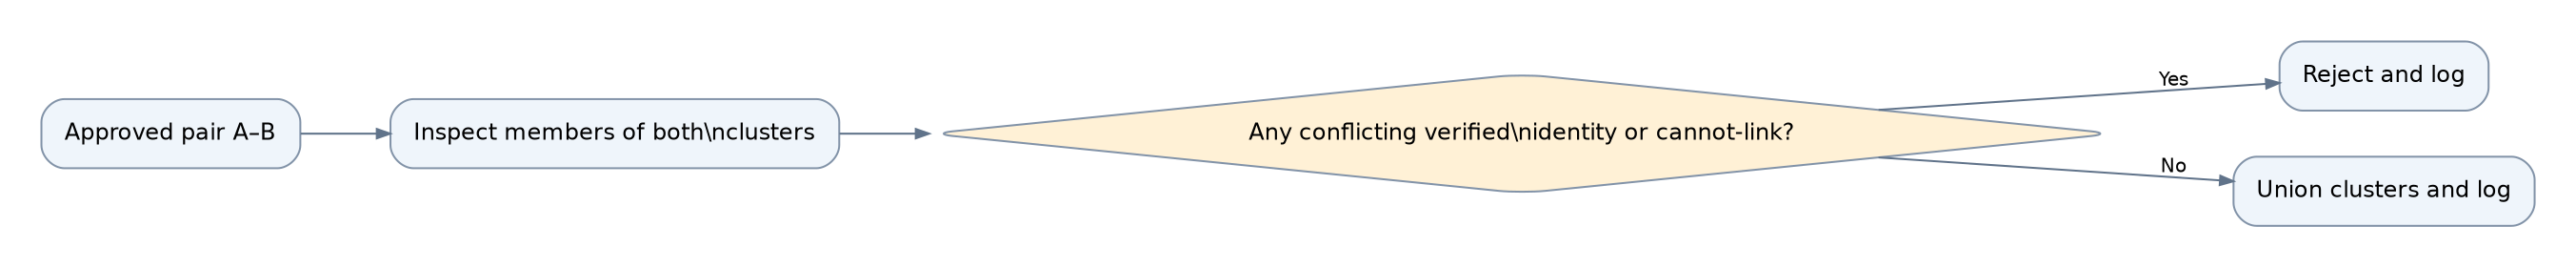


## 7 Constrained Union-Find, adjudication, audit, cluster diagnostics

**Purpose:** merge approved pairs, strongest evidence first, but check every existing cluster member for conflicts before each union. Log accepted and rejected attempts.

**Further detail (optional):**

**Order.** AUTO_MERGE edges are applied strongest first: human, then verified QID / unambiguous alias, then `exact_norm`, then corroborated short forms, then promoted. Ties are broken by score.

**Cluster-level checks before each union** (fixes D1/D2):
- (1) the two clusters' VERIFIED QID sets must not differ;
- (2) no human cannot-link or verified-relation pair may connect the two clusters. Constraints are tracked per member, so they stay valid after indirect merges.

**A human `same` label that conflicts with a VERIFIED identity** is not applied. It goes to `adjudication.csv` for a person to resolve.

Every attempt is logged in `merge_audit.csv`.

**Cluster diagnostics (v2 fix V7).** v1 gave every 2-member cluster with one strong edge a score of 1.0. That number described the merge tree, not the evidence. v2 describes the evidence:
- **Identifier quality** `id_quality`, the weakest member decides:
  - 1.0: a human label;
  - 0.8: every member is VERIFIED to the same QID (title + independent model + context);
  - 0.6: one member is VERIFIED and the others carry the same QID as PROBABLE or through a corroborated short form;
  - 0.3: only PROBABLE QIDs agree;
  - 0: no identifier.
- **Independent evidence families** (each must hold for every member pair):
  - `identifier` (id_quality ≥ 0.6);
  - `name` (exact/translit/rule/initials/alias/short form/fuzz ≥ `fuzz_review`);
  - `document` (every member shares a document with another member);
  - `context` (sentence-centroid cosine ≥ `context_family_min`);
  - `geo` (LOC: same OSM object or ≤ `osm_near_km`).
- The structural diagnostics from v1 are kept:
  - `direct_share`: the share of member pairs with direct positive evidence;
  - `min_level`: the weakest pair's evidence level (3 = verified/alias/human, 2 = exact/translit/corroborated short form, 1 = weak, 0 = none);
  - `depth`: the merge-tree depth;
  - `only_promoted`;
  - soft conflicts.

**`cluster_status`:**
- CONFLICTED = any soft conflict;
- WEAK = `direct_share` < 1, depth > 2, or only promoted edges;
- RELIABLE = a human label, or `id_quality` ≥ 0.8 and ≥ 2 families;
- SUPPORTED = everything else (a single evidence family carries the merge).

**`cluster_reliability_score`** = clip(0.4·id_quality + 0.3·min(n_families, 3)/3 + 0.15·direct_share + 0.15/max(depth, 1) − 0.3·conflicted, 0, 1). **It is a diagnostic ranking score, not a probability.** Step 10 reports it against gold correctness; with few or no wrong clusters it cannot be validated.

In [40]:
STRENGTH = [('human must-link', 5), ('same verified QID', 4), ('alias of verified QID', 4), ('exact_norm', 3),
            ('mention context', 2), ('local coreference', 2), ('BERT-supported short form', 2), ('promoted', 1)]
CONTEXT_FAMILY_MIN = 0.6  # fixed: sentence-centroid cosine for the `context` evidence family (diagnostic only)

def edge_strength(reason):
    return max([s for k, s in STRENGTH if k in reason], default=0)

def evidence_level(p):
    if p is None:
        return 0
    if p.get('label') == 'same' or T(p.get('same_verified_qid')) or T(p.get('alias_link')):
        return 3
    if T(p.get('exact_norm')) or T(p.get('translit_eq')) or T(p.get('short_form_corroborated')):
        return 2
    weak = [T(p.get('rule_match')), T(p.get('initials_match')),
            p.get('fuzz_max', 0) >= CONFIG['fuzz_review'], (p.get('cohere_name') or 0) >= CONFIG['name_review'],
            T(p.get('same_probable_qid')), T(p.get('same_osm')), isinstance(p.get('short_kind'), str)]
    return 1 if any(weak) else 0

def name_evidence(p):
    return bool(p) and (T(p.get('exact_norm')) or T(p.get('translit_eq')) or T(p.get('rule_match')) or T(p.get('initials_match'))
                        or T(p.get('alias_link')) or isinstance(p.get('short_kind'), str) or p.get('fuzz_max', 0) >= CONFIG['fuzz_review'])

def uf_find(parent, x):
    """Root of x in a list-based union-find (path halving)."""
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def cluster_senses(senses, pairs, forms):
    """Merge compatible sense pairs while enforcing identity and ambiguity constraints."""
    n = len(senses)
    parent = list(range(n))
    members = {i: {i} for i in range(n)}
    vq = {i: ({senses.at[i, 'verified_qid']} if isinstance(senses.at[i, 'verified_qid'], str) else set()) for i in range(n)}
    cannot = defaultdict(set)
    for p in pairs[pairs.hard_constraint != ''].itertuples():
        cannot[p.i].add(p.j)
        cannot[p.j].add(p.i)
    audit, adjud = [], []
    edges = pairs[pairs.decision == 'AUTO_MERGE'].copy()
    edges['strength'] = edges.reason.map(edge_strength)
    edges = edges.sort_values(['strength', 'promo_score', 'cohere_name'], ascending=False, na_position='last')
    tree = defaultdict(list)
    for order, p in enumerate(edges.itertuples()):
        ra, rb = uf_find(parent, p.i), uf_find(parent, p.j)
        row = {'order': order, 'sense_a': p.sense_a, 'sense_b': p.sense_b, 'type': p.type, 'reason': p.reason, 'strength': p.strength}
        if ra == rb:
            audit.append({**row, 'status': 'redundant (already joined)'})
            continue
        qa, qb = vq[ra], vq[rb]
        blocked = None
        if qa and qb and qa != qb:
            blocked = f'verified QIDs {sorted(qa)} vs {sorted(qb)}'
        elif any(cannot[x] & members[rb] for x in members[ra]):
            blocked = 'cannot-link between clusters'
        if blocked:
            audit.append({**row, 'status': f'refused: {blocked}'})
            if p.label == 'same':
                adjud.append({**row, 'conflict': blocked, 'members_a': sorted(senses.loc[list(members[ra]), 'sense_id']),
                              'members_b': sorted(senses.loc[list(members[rb]), 'sense_id'])})
            continue
        parent[rb] = ra
        members[ra] |= members.pop(rb)
        vq[ra] = qa | qb
        tree[p.i].append(p.j)
        tree[p.j].append(p.i)
        audit.append({**row, 'status': 'applied'})
    root = [uf_find(parent, i) for i in range(n)]
    return root, pd.DataFrame(audit), pd.DataFrame(adjud), tree

**Implementation detail:** `identifier_quality()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [41]:

def identifier_quality(sub, human_edge):
    if human_edge:
        return 1.0
    vq = {q for q in sub.verified_qid if isinstance(q, str)}
    ids = {(q if isinstance(q, str) else p) for q, p in zip(sub.verified_qid, sub.probable_qid)}
    if len(vq) == 1 and sub.verified_qid.map(lambda q: isinstance(q, str)).all():
        return 0.8
    if len(vq) == 1 and ids == vq:
        return 0.6
    if len(vq) == 1:  # the other members have no identity (or a different probable one) but were joined by a short-form rule
        return 0.6 if sub.probable_qid.map(lambda q: not isinstance(q, str) or q in vq).all() else 0.3
    pq = {q for q in sub.probable_qid if isinstance(q, str)}
    return 0.3 if len(pq) == 1 and sub.probable_qid.map(lambda q: isinstance(q, str)).all() else 0.0

def cluster_diagnostics(senses, pairs, forms, root, tree, audit):
    """Summarize confidence, conflicts, and evidence for each resolved cluster."""
    pidx = {(min(p['i'], p['j']), max(p['i'], p['j'])): p for p in pairs.to_dict('records')}
    fx = forms.set_index('form_id')
    applied = audit[audit.status == 'applied'] if len(audit) else audit
    sent = sense_vec(senses, 'sent') if 'sent' in EMBS else None
    rows = []
    for r, mem in pd.Series(range(len(senses))).groupby(pd.Series(root)):
        mem = list(mem)
        if len(mem) < 2:
            continue
        levels, names, ctxs = [], [], []
        for a, b in itertools.combinations(sorted(mem), 2):
            p = pidx.get((a, b))
            if p is None:  # not a candidate pair: compute name-level evidence on the fly
                sa, sb = senses.loc[a], senses.loc[b]
                p = {'exact_norm': sa.norm == sb.norm, 'translit_eq': sa.translit == sb.translit,
                     'rule_match': RULES[sa.type](sa.display, sb.display) if sa.type in RULES else False,
                     'fuzz_max': max(fuzz.WRatio(sa.norm, sb.norm), fuzz.token_set_ratio(sa.norm, sb.norm)),
                     'same_verified_qid': isinstance(sa.verified_qid, str) and sa.verified_qid == sb.verified_qid,
                     'same_probable_qid': isinstance(sa.probable_qid, str) and sa.probable_qid == sb.probable_qid}
            levels.append(evidence_level(p))
            names.append(name_evidence(p))
            if sent is not None:
                ctxs.append(float(sent[a] @ sent[b]))
        start = max(mem, key=lambda i: senses.at[i, 'n_mentions'])
        depth, seen, frontier = 0, {start}, [start]
        while frontier:
            nxt = [y for x in frontier for y in tree[x] if y not in seen]
            seen |= set(nxt)
            depth += bool(nxt)
            frontier = nxt
        sub = senses.loc[mem]
        ids = set(sub.sense_id)
        cl_edges = applied[applied.sense_a.isin(ids)] if len(applied) else applied
        only_promoted = bool(len(cl_edges)) and cl_edges.reason.str.contains('promoted').all()
        human_edge = bool(len(cl_edges)) and cl_edges.reason.str.contains('human').any()
        pq = {q for q in sub.probable_qid if isinstance(q, str)}
        t = sub.type.iloc[0]
        ranks = {fx.at[f, 'place_rank'] for f in sub.form_id if t == 'LOC' and pd.notna(fx.at[f, 'place_rank'])}
        conflicts = [x for x, c in [('several probable QIDs', len(pq) > 1), ('place_rank spread', len(ranks) > 1),
                                    ('ambiguous member', sub.ambiguous.any())] if c]
        idq = identifier_quality(sub, human_edge)
        docs = [set(s) for s in sub.sources]
        fam = {'identifier': idq >= 0.6, 'name': all(names),
               'document': all(any(d & e for k, e in enumerate(docs) if k != j) for j, d in enumerate(docs)),
               'context': bool(ctxs) and min(ctxs) >= CONTEXT_FAMILY_MIN}
        if t == 'LOC':
            osm = [fx.loc[f] for f in sub.form_id]
            fam['geo'] = all(o.has_osm for o in osm) and all(
                (x.osm_type, x.osm_id) == (y.osm_type, y.osm_id) or float(haversine_km(x.latitude, x.longitude, y.latitude, y.longitude)) <= CONFIG['osm_near_km']
                for x, y in itertools.combinations(osm, 2))
        families = [k for k, v in fam.items() if v]
        direct = float(np.mean([l >= 1 for l in levels]))
        if conflicts:
            status = 'CONFLICTED'
        elif direct < 1 or depth > 2 or only_promoted:
            status = 'WEAK'
        elif human_edge or (idq >= 0.8 and len(families) >= 2):
            status = 'RELIABLE'
        else:
            status = 'SUPPORTED'
        score = float(np.clip(0.4 * idq + 0.3 * min(len(families), 3) / 3 + 0.15 * direct + 0.15 / max(depth, 1) - 0.3 * bool(conflicts), 0, 1))
        rows.append({'root': r, 'size': len(mem), 'members': sorted(ids), 'id_quality': idq, 'evidence_families': '+'.join(families),
                     'n_families': len(families), 'direct_share': direct, 'min_level': min(levels), 'depth': depth,
                     'only_promoted': only_promoted, 'soft_conflicts': '; '.join(conflicts),
                     'cluster_status': status, 'cluster_reliability_score': round(score, 3)})
    return pd.DataFrame(rows, columns=['root', 'size', 'members', 'id_quality', 'evidence_families', 'n_families', 'direct_share',
                                       'min_level', 'depth', 'only_promoted', 'soft_conflicts', 'cluster_status', 'cluster_reliability_score'])

**Implementation detail:** `ROOT` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [42]:

ROOT, AUDIT, ADJUD, TREE = cluster_senses(senses, PAIRS, forms)
DIAG = cluster_diagnostics(senses, PAIRS, forms, ROOT, TREE, AUDIT)
AUDIT.to_csv(OUTPUT_DIR / 'merge_audit.csv', index=False)
ADJUD.to_csv(OUTPUT_DIR / 'adjudication.csv', index=False)
DIAG.to_csv(OUTPUT_DIR / 'cluster_diagnostics.csv', index=False)

# Checks: no cluster holds two VERIFIED QIDs or a hard-constraint pair
cl = pd.Series(ROOT)
for r, mem in cl.groupby(cl):
    q = {senses.at[i, 'verified_qid'] for i in mem.index if isinstance(senses.at[i, 'verified_qid'], str)}
    assert len(q) <= 1, f'cluster {r} holds verified QIDs {q}'
for p in PAIRS[PAIRS.hard_constraint != ''].itertuples():
    assert ROOT[p.i] != ROOT[p.j], f'hard constraint violated: {p.a} / {p.b}'
print(AUDIT.status.str.split(':').str[0].value_counts().to_string() if len(AUDIT) else 'no merges', '\n')
print(f'adjudication items: {len(ADJUD)}')
if len(DIAG):
    display(DIAG.cluster_status.value_counts())
    display(DIAG.sort_values('cluster_reliability_score')[['members', 'cluster_status', 'cluster_reliability_score', 'id_quality',
                                                          'evidence_families', 'direct_share', 'depth', 'soft_conflicts']])

status
applied    15 

adjudication items: 0


,count
cluster_status,
RELIABLE,8
SUPPORTED,7


,members,cluster_status,cluster_reliability_score,id_quality,evidence_families,direct_share,depth,soft_conflicts
6,"[ORG::Information Telegraph Agency of Russia, ORG::Tass]",SUPPORTED,0.72,0.8,identifier,1.0,1,
4,"[ORG::EU, ORG::European Union]",SUPPORTED,0.84,0.6,identifier+name+document+context,1.0,1,
5,"[ORG::ICC, ORG::International Criminal Court]",SUPPORTED,0.84,0.6,identifier+name+document+context,1.0,1,
9,"[ORG::PESCO, ORG::Permanent Structured Cooperation]",SUPPORTED,0.84,0.6,identifier+name+document+context,1.0,1,
12,"[PER::Liz Truss, PER::Truss]",SUPPORTED,0.84,0.6,identifier+name+document,1.0,1,
13,"[PER::Oleksandr Turchynov, PER::Turchynov]",SUPPORTED,0.84,0.6,identifier+name+document,1.0,1,
11,"[PER::Emmanuel Macron, PER::Macron]",SUPPORTED,0.84,0.6,identifier+name+document,1.0,1,
0,"[LOC::US, LOC::United States]",RELIABLE,0.92,0.8,identifier+document+geo,1.0,1,
7,"[ORG::NATO, ORG::North Atlantic Treaty Organization]",RELIABLE,0.92,0.8,identifier+name+document+context,1.0,1,
1,"[ORG::36th Marine Brigade, ORG::36th Separate Marine Brigade]",RELIABLE,0.92,0.8,identifier+name+document,1.0,1,


## 8 Canonical entities and stable IDs

**Purpose:** give each resulting entity a stable ID, display name, aliases, mentions, and metadata.

**Further detail (optional):**

**`entity_id`:**
- `wd:<QID>` when the cluster holds exactly one VERIFIED QID (a second unmerged cluster with the same QID gets `#2` and is flagged);
- otherwise `loc:<TYPE>:<hash>`, kept in `entity_registry.json` and **reused across runs** (a cluster takes the ID held by most of its members in the last run);
- placeholders: `unresolved:<TYPE>:<hash>`.

**Display name** (deterministic): the VERIFIED Wikidata label, then the form's Wikipedia title (when VERIFIED via title), then the most-mentioned display, then the longest.

Each entity keeps:
- its aliases (display strings and original NER words);
- its forms, senses and mentions;
- the documents and `(doc, paragraph)` references;
- identity status and source;
- cluster diagnostics;
- LOC geography: the geocode of the canonical form, OSM reference, polygon flag, Wikidata coordinates.

In [43]:
REGISTRY_PATH = OUTPUT_DIR / 'entity_registry.json'

def entity_id_for_group(group, entity_type, verified_qids, registry, used):
    """Reuse a stable entity ID, preferring a verified Wikidata identity."""
    if group.is_placeholder.all():
        digest = hashlib.sha1('|'.join(sorted(group.sense_id)).encode()).hexdigest()[:10]
        return f'unresolved:{entity_type}:{digest}'
    if len(verified_qids) == 1:
        base = 'wd:' + verified_qids[0]
        candidate, suffix = base, 2
        while candidate in used:
            candidate, suffix = f'{base}#{suffix}', suffix + 1
        return candidate

    previous = Counter(registry[x] for x in group.sense_id
                       if x in registry and registry[x].startswith('loc:') and registry[x] not in used)
    if previous:
        return previous.most_common(1)[0][0]
    counts = dict(zip(group.sense_id, group.n_mentions))
    anchor = sorted(group.sense_id, key=lambda x: (-int(counts[x]), x))[0]
    base = f'loc:{entity_type}:' + hashlib.sha1(anchor.encode()).hexdigest()[:10]
    candidate, suffix = base, 2
    while candidate in used:
        candidate, suffix = f'{base}#{suffix}', suffix + 1
    return candidate


def entity_geography(group, canonical, form_index, verified_qids):
    """Find the preferred OSM geometry and optional Wikidata coordinates."""
    if group.type.iloc[0] != 'LOC':
        return {}
    geo = {}
    for form_id in [canonical.form_id] + [f for f in group.form_id if f != canonical.form_id]:
        form = form_index.loc[form_id]
        if form.has_osm:
            geo = {'latitude': float(form.latitude), 'longitude': float(form.longitude), 'osm_ref': form.osm_ref,
                   'place_rank': None if pd.isna(form.place_rank) else int(form.place_rank),
                   'address': form.display_name if isinstance(form.display_name, str) else None,
                   'geocode_importance': None if pd.isna(form.geocode_importance) else float(form.geocode_importance),
                   'has_polygon': bool(form.has_polygon), 'geo_source_form': form_id}
            break
    if verified_qids and (WDE.get(verified_qids[0]) or {}).get('lat') is not None:
        geo.update({'wd_latitude': WDE.get(verified_qids[0])['lat'],
                    'wd_longitude': WDE.get(verified_qids[0])['lon']})
    return geo

def build_entities(senses, forms, root, diag, registry=None, save=True):
    """Turn resolved sense clusters into stable entities and a sense-to-entity map."""
    registry = dict(registry if registry is not None else (json.loads(REGISTRY_PATH.read_text(encoding='utf-8')) if REGISTRY_PATH.exists() else {}))
    fx = forms.set_index('form_id')
    diag_by_root = diag.set_index('root') if len(diag) else pd.DataFrame()
    s = senses.assign(root=root)
    used, rows, sense_entity = set(), [], {}
    groups = sorted(s.groupby('root'), key=lambda kv: -kv[1].n_mentions.sum())
    for r, g in groups:
        t = g.type.iloc[0]
        vq = sorted({q for q in g.verified_qid if isinstance(q, str)})
        pq = sorted({q for q in g.probable_qid if isinstance(q, str)})
        eid = entity_id_for_group(g, t, vq, registry, used)
        used.add(eid)
        canon = g.sort_values(['n_mentions', 'display'], key=lambda c: c.str.len() if c.name == 'display' else c, ascending=False).iloc[0]
        if vq and (WDE.get(vq[0]) or {}).get('label'):
            name, name_src = WDE.get(vq[0])['label'], 'wikidata label (verified)'
        else:
            name, name_src = canon.display, 'most-mentioned form'
        mids = [m for x in g.mention_ids for m in x]
        mm = mentions_by_id.loc[mids]
        geo = entity_geography(g, canon, fx, vq)
        d = diag_by_root.loc[r] if len(diag_by_root) and r in diag_by_root.index else None
        status = 'UNRESOLVED' if g.is_placeholder.all() else ('VERIFIED' if vq else ('PROBABLE' if len(pq) == 1 else 'NONE'))
        rows.append({'entity_id': eid, 'type': t, 'name': name, 'name_source': name_src, 'qid': vq[0] if vq else (pq[0] if len(pq) == 1 else None),
                     'id_status': status, 'id_source': 'verified' if vq else ('model/source link (probable)' if len(pq) == 1 else ''),
                     'aliases': sorted(set(g.display) | set(fx.loc[list(g.form_id), 'word'])),
                     'form_ids': sorted(set(g.form_id)), 'sense_ids': sorted(g.sense_id), 'mention_ids': mids,
                     'n_mentions': len(mids), 'docs': sorted(set(mm.source)),
                     'paragraphs': sorted({(a, int(b)) for a, b in zip(mm.source, mm.para_idx)}),
                     'merged': len(g) > 1, 'cluster_status': d.cluster_status if d is not None else 'SINGLETON',
                     'cluster_reliability_score': float(d.cluster_reliability_score) if d is not None else None,
                     'ambiguous_member': bool(g.ambiguous.any()), 'duplicate_qid': '#' in eid and eid.startswith('wd:'), 'geo': geo})
        for x in g.sense_id:
            sense_entity[x] = eid
    ents_df = pd.DataFrame(rows)
    if save:
        REGISTRY_PATH.write_text(json.dumps({**registry, **sense_entity}, ensure_ascii=False, indent=1), encoding='utf-8')
    return ents_df, sense_entity

**Implementation detail:** `ENTITIES` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [44]:

ENTITIES, SENSE_ENTITY = build_entities(senses, forms, ROOT, DIAG)
MENTION_ENTITY = {m: SENSE_ENTITY[s] for m, s in MENTION_TO_SENSE.items()}
ent_name = ENTITIES.set_index('entity_id').name
entity_map = senses[['sense_id', 'form_id', 'type', 'display', 'is_placeholder', 'ambiguous', 'id_status', 'link_status', 'verified_qid', 'probable_qid']].assign(
    word=senses.form_id.str.split('::', n=1).str[1], entity_id=senses.sense_id.map(SENSE_ENTITY))
entity_map['entity_name'] = entity_map.entity_id.map(ent_name)
entity_map.to_csv(OUTPUT_DIR / 'entity_map.csv', index=False)
mention_map = pd.DataFrame({'mention_id': list(MENTION_TO_SENSE), 'sense_id': list(MENTION_TO_SENSE.values())})
mention_map['entity_id'] = mention_map.sense_id.map(SENSE_ENTITY)
mention_map = mention_map.merge(MENTION_LINKS[['mention_id', 'mention_qid', 'mention_status']], on='mention_id', how='left')
mention_map.to_csv(OUTPUT_DIR / 'mention_map.csv', index=False)
ENTITIES.to_json(OUTPUT_DIR / 'entities.json', orient='records', force_ascii=False, indent=1)

# Checks
assert ENTITIES.entity_id.is_unique
assert set(MENTION_ENTITY.values()) <= set(ENTITIES.entity_id)
print(f"{len(senses)} senses -> {len(ENTITIES)} entities | merged: {int(ENTITIES.merged.sum())} | "
      f"id_status: {ENTITIES.id_status.value_counts().to_dict()}")
display(ENTITIES[ENTITIES.merged][['entity_id', 'type', 'name', 'aliases', 'id_status', 'cluster_status', 'cluster_reliability_score']])

317 senses -> 302 entities | merged: 15 | id_status: {'VERIFIED': 128, 'NONE': 121, 'PROBABLE': 53}


,entity_id,type,name,aliases,id_status,cluster_status,cluster_reliability_score
7,wd:Q81299,ORG,Organization for Security and Co-operation in Europe,"[OSCE, Organization for Security and Co - operation in Europe, Organization for Security and Co-operation in Europe]",VERIFIED,RELIABLE,0.92
13,wd:Q458,ORG,European Union,"[EU, European Union]",VERIFIED,SUPPORTED,0.84
17,wd:Q7747,PER,Vladimir Putin,"[Putin, Vladimir Putin]",VERIFIED,RELIABLE,0.92
24,wd:Q15850,PER,Oleksandr Turchynov,"[Oleksandr Turchynov, Turchynov]",VERIFIED,SUPPORTED,0.84
27,wd:Q30,LOC,United States,"[US, United States]",VERIFIED,RELIABLE,0.92
29,wd:Q1148669,PER,Cyril Ramaphosa,"[Cyril Ramaphosa, Ramaphosa]",VERIFIED,RELIABLE,0.92
30,wd:Q272201,PER,Liz Truss,"[Liz Truss, Truss]",VERIFIED,SUPPORTED,0.84
36,wd:Q40469,ORG,Associated Press,"[Associated Press, The Associated Press]",VERIFIED,RELIABLE,0.92
39,wd:Q47488,ORG,International Criminal Court,"[ICC, International Criminal Court]",VERIFIED,SUPPORTED,0.84
42,wd:Q3052772,PER,Emmanuel Macron,"[Emmanuel Macron, Macron]",VERIFIED,SUPPORTED,0.84


## 9 Knowledge graph: two layers, reversible export, views

**Purpose:** build an undirected co-occurrence graph and a separate directed verified-relation graph, preserving evidence in the export.

**Further detail (optional):**

**`G_cooc` is an `nx.Graph`, undirected by construction**, because co-occurrence is symmetric. Neighbour queries need no direction handling, and there is no arbitrary direction (fixes D7).

One edge per entity pair aggregates:
- `count` (number of shared snippets);
- `paragraphs` `[(doc, para_idx)]`;
- `docs`;
- `mention_pairs`.

Evidence is **never overwritten**. Two forms of one entity in the same snippet would form a self-pair; it is dropped deliberately and counted.

**`G_rel` is an `nx.MultiDiGraph`** of directed, evidence-backed relations between entities with VERIFIED QIDs only:
- `ADMINISTRATIVELY_IN`: Wikidata P131, only when both sides are geographic/administrative entities;
- `PART_OF`: P361, or P749 for ORG, between entities of the same type.

Administrative membership (P131) is kept separate from geometric containment. **Polygon containment never creates an edge**; it is only a diagnostic in `pairs.spatial`. No relation label is invented beyond these.

`neighbors(entity_id, relation=None)` queries both layers.

In [45]:
def build_graphs(entities, mention_entity):
    """Construct graph representations from the resolved entities and relationships."""
    ent = entities.set_index('entity_id')
    G = nx.Graph()
    for eid, e in ent.iterrows():
        G.add_node(eid, type=e.type, name=e['name'], qid=e.qid, id_status=e.id_status, merged=bool(e.merged))
    self_pairs = []
    for (doc, para), g in mentions.groupby(['source', 'para_idx']):
        by_e = defaultdict(list)
        for m in g.mention_id:
            by_e[mention_entity[m]].append(m)
        for e, mids in by_e.items():
            if len({mentions_by_id.at[m, 'form_id'] for m in mids}) > 1:
                self_pairs.append({'entity_id': e, 'doc': doc, 'para_idx': int(para), 'forms': sorted({mentions_by_id.at[m, 'form_id'] for m in mids})})
        for a, b in itertools.combinations(sorted(by_e), 2):
            mp = [[x, y] for x in by_e[a] for y in by_e[b]]
            if G.has_edge(a, b):
                d = G[a][b]
                d['count'] += 1
                d['paragraphs'].append([doc, int(para)])
                d['docs'].add(doc)
                d['mention_pairs'] += mp
            else:
                G.add_edge(a, b, relation='CO_OCCURS_WITH', directed=False, count=1, paragraphs=[[doc, int(para)]], docs={doc}, mention_pairs=mp)
    R = nx.MultiDiGraph()
    by_q = {e.qid: eid for eid, e in ent.iterrows() if e.id_status == 'VERIFIED' and isinstance(e.qid, str)}
    for eid, e in ent.iterrows():
        if e.id_status != 'VERIFIED' or not isinstance(e.qid, str):
            continue
        facts = WDE.get(e.qid) or {}
        src_kind = entity_kind(e.qid)
        for prop, key, rel in (('P131', 'p131', 'ADMINISTRATIVELY_IN'), ('P361', 'p361', 'PART_OF'), ('P749', 'p749', 'PART_OF')):
            for tq in facts.get(key, []):
                tgt = by_q.get(tq)
                if tgt is None or tgt == eid:
                    continue
                t_type, t_kind = ent.at[tgt, 'type'], entity_kind(tq)
                valid = (src_kind['is_geo'] and t_kind['is_geo']) if rel == 'ADMINISTRATIVELY_IN' else \
                        (e.type == t_type and (prop != 'P749' or e.type == 'ORG'))
                if valid:
                    R.add_edge(eid, tgt, key=f'{rel}:{prop}', relation=rel, directed=True,
                               provenance=f'wikidata:{e.qid} {prop} {tq}', confidence='verified identities + Wikidata claim')
    return G, R, pd.DataFrame(self_pairs)

def neighbors(entity_id, relation=None):
    """[(neighbor, relation, direction)] over both layers. Co-occurrence is undirected; relations keep direction."""
    out = []
    if relation in (None, 'CO_OCCURS_WITH') and entity_id in G_COOC:
        out += [(n, 'CO_OCCURS_WITH', 'undirected') for n in G_COOC.neighbors(entity_id)]
    if entity_id in G_REL:
        out += [(v, d['relation'], 'out') for _, v, d in G_REL.out_edges(entity_id, data=True) if relation in (None, d['relation'])]
        out += [(u, d['relation'], 'in') for u, _, d in G_REL.in_edges(entity_id, data=True) if relation in (None, d['relation'])]
    return out

G_COOC, G_REL, SELF_PAIRS = build_graphs(ENTITIES, MENTION_ENTITY)
print(f'co-occurrence: {G_COOC.number_of_nodes()} nodes, {G_COOC.number_of_edges()} undirected edges, '
      f"{sum(d['count'] for _, _, d in G_COOC.edges(data=True))} snippet-level co-occurrences | "
      f'self-pairs dropped (two forms of one entity in a snippet): {len(SELF_PAIRS)}')
print(f'relations: {G_REL.number_of_edges()} ({Counter(d["relation"] for _, _, d in G_REL.edges(data=True))})')

co-occurrence: 302 nodes, 1156 undirected edges, 1378 snippet-level co-occurrences | self-pairs dropped (two forms of one entity in a snippet): 10
relations: 28 (Counter({'ADMINISTRATIVELY_IN': 21, 'PART_OF': 7}))


**Export schema, `knowledge_graph_resolved.json` (schema 2.0):**

```
meta:        schema_version, created, label_status, config, counts, reconstruction notes
entities:    entity_id, type, name, name_source, qid, id_status, id_source, aliases, original_node_ids (TYPE::word),
             form_ids, sense_ids, mention_ids, docs, paragraphs, merged, cluster_status,
             cluster_reliability_score (diagnostic, not a probability), geo{lat, lon, osm_ref, place_rank, ...}
forms:       form_id (TYPE::word), type, word, display, sense_ids, entity_ids, source_link_qid, model_qid, verified_qid,
             id_status, link_status, ambiguity_suspected, amb_reason
mentions:    mention_id, form_id, sense_id, entity_id, doc, para_idx, start, end, ner_start, surface, sentence,
             mention_status, mention_qid, source_url
paragraphs:  "<doc>|<para_idx>" -> paragraph text (stored once; edges point to it)
edges:       source, target, relation, directed, count, evidence[{doc, para_idx, mention_pairs}], provenance, confidence
node_mapping: {"TYPE::word": [entity_id, ...]} and {"word": [entity_id, ...]} (old graph node ids)
```

A `node_link_data` view of the co-occurrence layer (`knowledge_graph_resolved_node_link.json`, keys `nodes` and `edges`) is written for existing loaders.

**Reversibility.** `to_raw_graph(export)` rebuilds the **type-qualified** mention-level co-occurrence graph exactly, with every snippet. Compared with the old graph in `Graph_and_Geocoding.ipynb`:
- **Reproduced exactly:** its bare-word node set and its unordered edge set.
- **Artefacts of row order, not information:** its edge direction and its "last snippet wins" evidence.
- **Lost upstream** (not recoverable from that graph, recovered here from the NER table): the entity type of a word used with two types (there the first-seen type wins), and every snippet but the last per pair.

In [46]:
def build_export(entities, forms, senses, G, R, sense_entity, mention_entity, mention_links):
    """Serialize resolved entities and their relationships for downstream graph consumers."""
    ml = mention_links.set_index('mention_id')
    fx = forms.set_index('form_id')
    paragraphs = {f'{s}|{int(i)}': str(t) for (s, i), t in ents.groupby(['Source', 'Index']).Text.first().items()}
    ent_records = []
    for e in entities.to_dict('records'):
        e = {k: (v if not isinstance(v, (np.floating, np.integer, np.bool_)) else v.item()) for k, v in e.items()}
        e['original_node_ids'] = e['form_ids']
        e['paragraphs'] = [list(x) for x in e['paragraphs']]
        ent_records.append(e)
    form_records = []
    for f in forms.itertuples():
        sids = list(senses[senses.form_id == f.form_id].sense_id)
        form_records.append({'form_id': f.form_id, 'type': f.type, 'word': f.word, 'display': f.display, 'sense_ids': sids,
                             'entity_ids': sorted({sense_entity[s] for s in sids}),
                             **{k: (None if (v is None or (isinstance(v, float) and math.isnan(v))) else v)
                                for k, v in [('source_link_qid', getattr(f, 'source_link_qid', None)), ('model_qid', getattr(f, 'model_link_qid', None)),
                                             ('verified_qid', getattr(f, 'verified_qid', None))]},
                             'id_status': getattr(f, 'id_status', None), 'link_status': getattr(f, 'link_status', None),
                             'ambiguity_suspected': bool(getattr(f, 'ambiguity_suspected', False)), 'amb_reason': getattr(f, 'amb_reason', '')})
    mention_records = []
    for m in mentions.itertuples():
        r = ml.loc[m.mention_id] if m.mention_id in ml.index else None
        mention_records.append({'mention_id': m.mention_id, 'form_id': m.form_id, 'sense_id': MENTION_TO_SENSE[m.mention_id],
                                'entity_id': mention_entity[m.mention_id], 'doc': m.source, 'para_idx': m.para_idx,
                                'start': m.start, 'end': m.end, 'ner_start': m.ner_start, 'surface': m.surface, 'sentence': m.sentence,
                                'mention_status': None if r is None else r.mention_status,
                                'mention_qid': None if r is None or not isinstance(r.mention_qid, str) else r.mention_qid,
                                'source_url': m.source_url})
    edges = []
    for a, b, d in G.edges(data=True):
        ev = defaultdict(list)
        for x, y in d['mention_pairs']:
            doc, para = mentions_by_id.at[x, 'source'], int(mentions_by_id.at[x, 'para_idx'])
            ev[(doc, para)].append([x, y])
        edges.append({'source': a, 'target': b, 'relation': 'CO_OCCURS_WITH', 'directed': False, 'count': d['count'],
                      'evidence': [{'doc': k[0], 'para_idx': k[1], 'mention_pairs': v} for k, v in ev.items()],
                      'provenance': 'NER co-occurrence in the same paragraph', 'confidence': None})
    for u, v, d in R.edges(data=True):
        edges.append({'source': u, 'target': v, 'relation': d['relation'], 'directed': True, 'count': None, 'evidence': [],
                      'provenance': d['provenance'], 'confidence': d['confidence']})
    node_map, word_map = defaultdict(set), defaultdict(set)
    for f in form_records:
        node_map[f['form_id']] |= set(f['entity_ids'])
        word_map[f['word']] |= set(f['entity_ids'])
    return {
        'meta': {'schema_version': '2.0', 'created': datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds'),
                 'label_status': LABEL_STATUS,
                 'config': {k: v for k, v in CONFIG.items() if isinstance(v, (int, float, str, bool, list, type(None)))},
                 'counts': {'entities': len(ent_records), 'forms': len(form_records), 'mentions': len(mention_records),
                            'cooccurrence_edges': G.number_of_edges(), 'relation_edges': R.number_of_edges()},
                 'notes': 'Co-occurrence edges are undirected. cluster_reliability_score is a diagnostic ranking score, not a probability. '
                          'See the notebook (section 9) for which parts of the original graph can be reconstructed.'},
        'entities': ent_records, 'forms': form_records, 'mentions': mention_records, 'paragraphs': paragraphs, 'edges': edges,
        'node_mapping': {'type_qualified': {k: sorted(v) for k, v in node_map.items()}, 'word': {k: sorted(v) for k, v in word_map.items()}},
    }

**Implementation detail:** `to_raw_graph()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [47]:

def to_raw_graph(export):
    """Type-qualified mention-level co-occurrence graph (TYPE::word nodes), all snippets kept."""
    G = nx.Graph()
    for f in export['forms']:
        G.add_node(f['form_id'])
    by_para = defaultdict(list)
    for m in export['mentions']:
        by_para[(m['doc'], m['para_idx'])].append(m['form_id'])
    for (doc, para), fids in by_para.items():
        for a, b in itertools.combinations(sorted(set(fids)), 2):
            if G.has_edge(a, b):
                G[a][b]['snippets'].append((doc, para))
            else:
                G.add_edge(a, b, snippets=[(doc, para)])
    return G

def bare_word_edges_from_export(export):
    """Unordered bare-word edge set of the old graph notebook (self-pairs when one word appears with two types)."""
    by_para = defaultdict(set)
    for m in export['mentions']:
        t, w = m['form_id'].split('::', 1)
        by_para[(m['doc'], m['para_idx'])].add((w, t))
    out = set()
    for ents_ in by_para.values():
        for (wa, _), (wb, _) in itertools.combinations(sorted(ents_), 2):
            out.add(frozenset((wa, wb)))
    return out

def original_graph(df):
    """Exact replica of the graph-building cell of Graph_and_Geocoding.ipynb (DiGraph keyed by word)."""
    clean_df = df[df['entity_group'].isin(['PER', 'LOC', 'ORG'])].copy()
    G = nx.DiGraph()
    for _, row in clean_df.iterrows():
        if not G.has_node(row['word']):
            G.add_node(row['word'], type=row['entity_group'])
    for (source, idx), group in clean_df.groupby(['Source', 'Index']):
        entities = group[['word', 'entity_group']].drop_duplicates().to_dict('records')
        for i in range(len(entities)):
            for j in range(i + 1, len(entities)):
                G.add_edge(entities[i]['word'], entities[j]['word'], evidence=group['Text'].iloc[0], source_doc=source)
    return G

EXPORT = build_export(ENTITIES, forms, senses, G_COOC, G_REL, SENSE_ENTITY, MENTION_ENTITY, MENTION_LINKS)
with open(OUTPUT_DIR / 'knowledge_graph_resolved.json', 'w', encoding='utf-8') as f:
    json.dump(EXPORT, f, ensure_ascii=False, indent=1, default=lambda o: sorted(o) if isinstance(o, set) else str(o))
G_view = nx.Graph()
G_view.add_nodes_from(G_COOC.nodes(data=True))
G_view.add_edges_from((a, b, {k: (sorted(v) if isinstance(v, set) else v) for k, v in d.items() if k != 'mention_pairs'}) for a, b, d in G_COOC.edges(data=True))
with open(OUTPUT_DIR / 'knowledge_graph_resolved_node_link.json', 'w', encoding='utf-8') as f:
    json.dump(nx.node_link_data(G_view, edges='edges'), f, ensure_ascii=False, indent=1, default=str)

# Checks: graph consistency and reversibility
raw_typed_direct = to_raw_graph({'forms': [{'form_id': f} for f in forms.form_id],
                                 'mentions': [{'form_id': m.form_id, 'doc': m.source, 'para_idx': m.para_idx} for m in mentions.itertuples()]})

**Merged knowledge graph.** Applies the final ER decisions to the existing `knowledge_graph.json` (the graph AgentRag reads) without rebuilding it from mentions, and writes `OUTPUT_DIR/knowledge_graph_merged.json` in the same node-link DiGraph format. Nodes are merged only when a graph word maps to exactly one entity of the same type. Words ER split into several entities (`sense_split`), words the original graph had already collapsed across types (`collapsed_types`), and `type_mismatch` words stay unmerged and are reported. Every original node dict is kept in `original_nodes`, and every original edge is kept as one record in `evidences`, traceable by `original_edge_id`. Self-loops are kept. LOC coordinates are never averaged: they come from the ER canonical geo, else from a single unambiguous original location, else they stay null (`geo_conflict`). The original file is only read.

In [81]:
# Merged knowledge graph: apply the final ER decisions to the EXISTING knowledge_graph.json (not rebuilt from mentions).
# Output keeps its node-link DiGraph format; every original node/edge dict is kept in original_nodes / evidences.
import inspect

KG_PATH = ER_DIR.parent / 'knowledge_graph.json'
assert KG_PATH.exists(), f'original graph not found: {KG_PATH.resolve()}'
assert 'edges' in inspect.signature(nx.node_link_graph).parameters, 'networkx >= 3.4 is needed for edges="edges"'

def _sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def _clean(v):
    """Non-finite floats -> None and numpy scalars -> Python, recursively, so the export is strict JSON."""
    if isinstance(v, np.generic):
        v = v.item()
    if isinstance(v, float) and not math.isfinite(v):
        return None
    if isinstance(v, dict):
        return {k: _clean(x) for k, x in v.items()}
    if isinstance(v, (list, tuple)):
        return [_clean(x) for x in v]
    return v

def _finite(x):
    return isinstance(x, (int, float)) and not isinstance(x, bool) and math.isfinite(x)

def build_merge_mapping(raw_nodes, word_map, ent_by_id):
    """original node id -> canonical id. Only unambiguous, type-consistent ER assignments are merged."""
    node_entity, ambiguous = {}, {}
    for n in raw_nodes:
        cands = sorted(word_map.get(n['id'], []))
        if len(cands) == 1 and ent_by_id[cands[0]]['type'] == n.get('type'):
            node_entity[n['id']] = cands[0]
        elif len(cands) == 1:
            ambiguous[n['id']] = ('type_mismatch', cands)
        elif cands:
            # the original graph keys nodes by bare word, so it already collapsed these mentions; never pick one
            reason = 'collapsed_types' if len({ent_by_id[c]['type'] for c in cands}) > 1 else 'sense_split'
            ambiguous[n['id']] = (reason, cands)
    # Resolve all canonical ids globally before building nodes: unmerged ids are reserved first.
    used = {n['id'] for n in raw_nodes if n['id'] not in node_entity}
    canon_of_entity = {}
    for eid in sorted(set(node_entity.values())):
        name = ent_by_id[eid]['name']
        cid = name if name not in used else f'{name} ({eid})'
        assert cid not in used, f'canonical id collision: {cid}'
        used.add(cid)
        canon_of_entity[eid] = cid
    mapping = {n['id']: canon_of_entity[node_entity[n['id']]] if n['id'] in node_entity else n['id'] for n in raw_nodes}
    return mapping, node_entity, ambiguous

def canonical_location(entity, members):
    """ER canonical geo if valid; else the single distinct valid original location; else None (conflict flagged)."""
    geo = entity.get('geo') if isinstance(entity.get('geo'), dict) else {}
    if _finite(geo.get('latitude')) and _finite(geo.get('longitude')):
        return (geo['latitude'], geo['longitude'], geo.get('address')), False
    locs = {(m['latitude'], m['longitude'], m.get('address')) for m in members
            if _finite(m.get('latitude')) and _finite(m.get('longitude'))}
    if len(locs) == 1:
        return locs.pop(), False
    return (None, None, None), len(locs) > 1

def merge_nodes(raw_nodes, mapping, node_entity, ambiguous, ent_by_id):
    groups = defaultdict(list)
    for n in sorted(raw_nodes, key=lambda n: n['id']):
        groups[mapping[n['id']]].append(_clean(n))
    nodes = {}
    for cid in sorted(groups):
        members = groups[cid]
        eid = node_entity.get(members[0]['id'])
        e = ent_by_id.get(eid, {})
        attrs = {'type': e['type'] if eid else members[0].get('type'),
                 'aliases': sorted(set(e['aliases'])) if eid else [members[0]['id']],
                 'entity_id': eid, 'qid': _clean(e.get('qid'))}
        if attrs['type'] == 'LOC':
            (attrs['latitude'], attrs['longitude'], attrs['address']), conflict = canonical_location(e, members)
            if conflict:
                attrs['geo_conflict'] = True
        if members[0]['id'] in ambiguous:
            attrs['ambiguity_reason'], attrs['unresolved_entity_ids'] = ambiguous[members[0]['id']]
        attrs['original_nodes'] = members
        nodes[cid] = _clean(attrs)
    return nodes

def merge_edges(raw_edges, mapping):
    """One record per original edge, in input order; nothing is deduplicated, self-loops are kept."""
    edges = {}
    for i, e in enumerate(raw_edges):
        u, v = e['source'], e['target']
        extra = {k: x for k, x in e.items() if k not in ('source', 'target', 'evidence')}
        assert not set(extra) & {'original_edge_id', 'text', 'original_source', 'original_target', 'self_loop_origin'}
        rec = {'original_edge_id': i, **({'text': e['evidence']} if 'evidence' in e else {}), **extra,
               'original_source': u, 'original_target': v}
        cu, cv = mapping[u], mapping[v]
        if cu == cv:
            rec['self_loop_origin'] = 'original' if u == v else 'merge'
        edges.setdefault((cu, cv), []).append(_clean(rec))
    return {k: {'relations': sorted({r['relation'] for r in recs if r.get('relation') is not None}),
                'evidence_count': len(recs), 'evidences': recs} for k, recs in edges.items()}

def record_to_original(rec):
    o = {k: x for k, x in rec.items() if k not in ('original_edge_id', 'text', 'original_source', 'original_target', 'self_loop_origin')}
    if 'text' in rec:
        o['evidence'] = rec['text']
    return {**o, 'source': rec['original_source'], 'target': rec['original_target']}

def validate_merge(out_path, raw, mapping):
    H = nx.node_link_graph(json.loads(out_path.read_text(encoding='utf-8')), directed=True, multigraph=False, edges='edges')
    assert isinstance(H, nx.DiGraph) and not H.is_multigraph()
    assert all('original_nodes' in d for _, d in H.nodes(data=True)), 'edge endpoint without a node record'
    assert set(H.nodes) == set(mapping.values()), 'unexpected or missing canonical nodes'
    seen = Counter(m['id'] for _, d in H.nodes(data=True) for m in d['original_nodes'])
    assert set(seen) == {n['id'] for n in raw['nodes']} and set(seen.values()) == {1}, 'every original node exactly once'
    orig_nodes = {n['id']: _clean(n) for n in raw['nodes']}
    for cid, d in H.nodes(data=True):
        for m in d['original_nodes']:
            assert m == orig_nodes[m['id']] and mapping[m['id']] == cid, f'original node changed: {m["id"]}'
    recs = {}
    for u, v, d in H.edges(data=True):
        assert d['evidence_count'] == len(d['evidences'])
        assert d['relations'] == sorted({r['relation'] for r in d['evidences'] if r.get('relation') is not None})
        for r in d['evidences']:
            assert r['original_edge_id'] not in recs, f'edge {r["original_edge_id"]} appears twice'
            assert (mapping[r['original_source']], mapping[r['original_target']]) == (u, v)
            recs[r['original_edge_id']] = r
    assert sorted(recs) == list(range(len(raw['edges']))), 'every original edge exactly once'
    for i, e in enumerate(raw['edges']):
        assert record_to_original(recs[i]) == _clean(e), f'original edge {i} changed'
    assert sum(d['evidence_count'] for _, _, d in H.edges(data=True)) == len(raw['edges'])
    return H

kg_sha = _sha256(KG_PATH)
raw_kg = json.loads(KG_PATH.read_text(encoding='utf-8'))
G_original = nx.node_link_graph(raw_kg, directed=True, multigraph=False, edges='edges')
assert G_original.number_of_edges() == len(raw_kg['edges']), 'duplicate (u, v) pairs in the original edge list'

ent_by_id = ENTITIES.set_index('entity_id').to_dict('index')
MERGE_MAP, NODE_ENTITY, MERGE_AMBIGUOUS = build_merge_mapping(raw_kg['nodes'], EXPORT['node_mapping']['word'], ent_by_id)

# Reuse an existing merged graph (e.g. restored from Drive) when its inputs are unchanged. Bump MERGE_VERSION when this cell's logic changes.
MERGE_VERSION = 1
merge_fingerprint = hashlib.sha256(json.dumps(_clean({
    'version': MERGE_VERSION, 'kg_sha256': kg_sha, 'word_map': EXPORT['node_mapping']['word'],
    'entities': {eid: {k: e.get(k) for k in ('type', 'name', 'qid', 'aliases', 'geo')} for eid, e in ent_by_id.items()}}),
    sort_keys=True, ensure_ascii=False, default=str).encode('utf-8')).hexdigest()
MERGED_KG_PATH = OUTPUT_DIR / 'knowledge_graph_merged.json'
try:
    previous_fingerprint = json.loads(MERGED_KG_PATH.read_text(encoding='utf-8'))['graph'].get('merge_fingerprint')
except (FileNotFoundError, KeyError, ValueError):
    previous_fingerprint = None

if previous_fingerprint == merge_fingerprint:
    print(f'{MERGED_KG_PATH.name}: inputs unchanged - reusing the existing file (not rebuilt)')
else:
    merged_nodes = merge_nodes(raw_kg['nodes'], MERGE_MAP, NODE_ENTITY, MERGE_AMBIGUOUS, ent_by_id)
    merged_edges = merge_edges(raw_kg['edges'], MERGE_MAP)
    G_new = nx.DiGraph(merge_fingerprint=merge_fingerprint)
    G_new.add_nodes_from(merged_nodes.items())
    G_new.add_edges_from((u, v, d) for (u, v), d in merged_edges.items())
    with open(MERGED_KG_PATH, 'w', encoding='utf-8') as f:
        json.dump(nx.node_link_data(G_new, edges='edges'), f, ensure_ascii=False, indent=2, allow_nan=False)

# Checks (also run on a reused file)
G_merged = validate_merge(MERGED_KG_PATH, raw_kg, MERGE_MAP)
assert G_merged.graph.get('merge_fingerprint') == merge_fingerprint
assert _sha256(KG_PATH) == kg_sha, 'the original knowledge_graph.json was modified'
save_state()

loop_origin = Counter(r['self_loop_origin'] for _, _, d in G_merged.edges(data=True) for r in d['evidences'] if 'self_loop_origin' in r)
merges = {c: d for c, d in G_merged.nodes(data=True) if len(d['original_nodes']) >= 2}
print(f'nodes: {G_original.number_of_nodes()} -> {G_merged.number_of_nodes()} | '
      f'edges: {G_original.number_of_edges()} -> {G_merged.number_of_edges()} '
      f'({G_original.number_of_edges() - G_merged.number_of_edges()} original edges combined into existing ones)')
print(f'mapped entities (canonical nodes with an entity_id): {sum(d["entity_id"] is not None for _, d in G_merged.nodes(data=True))} | '
      f'actual merges (2+ original nodes): {len(merges)}, absorbing {sum(len(d["original_nodes"]) for d in merges.values())} original nodes')
print(f'self-loops: {sum(e["source"] == e["target"] for e in raw_kg["edges"])} before -> '
      f'{sum(u == v for u, v in G_merged.edges)} after | evidence records: {dict(loop_origin)}')
print(f'left unmerged because of ambiguous ER assignments: {len(MERGE_AMBIGUOUS)} '
      f'{dict(Counter(r for r, _ in MERGE_AMBIGUOUS.values()))}')
print(f'LOC nodes with conflicting original locations (canonical geo left null): '
      f'{sum(bool(d.get("geo_conflict")) for _, d in G_merged.nodes(data=True))}')
print(f'saved: {MERGED_KG_PATH.resolve()} | original unchanged (sha256 {kg_sha[:12]}…)')
for nid, (reason, cands) in sorted(MERGE_AMBIGUOUS.items()):
    print(f'  ambiguous: {nid!r} [{reason}] -> {cands}')
for cid in sorted(merges, key=lambda c: -len(merges[c]['original_nodes']))[:3]:
    d = merges[cid]
    print(f'\n=== {cid} | {d["entity_id"]} | qid={d["qid"]} | original nodes: {[m["id"] for m in d["original_nodes"]]}')
    print(f'    aliases: {d["aliases"]}' + (f' | lat/lon: {d.get("latitude")}, {d.get("longitude")}' if d['type'] == 'LOC' else ''))
    for u, v in sorted(set(G_merged.in_edges(cid)) | set(G_merged.out_edges(cid))):
        e = G_merged.edges[u, v]
        print(f'  {u} -> {v}  relations={e["relations"]}  evidence_count={e["evidence_count"]}')
        for r in e['evidences']:
            print('    ', json.dumps(r, ensure_ascii=False))


knowledge_graph_merged.json: inputs unchanged - reusing the existing file (not rebuilt)
saved 0 new/changed file(s) to /content/drive/MyDrive/Corpus2GeoRAG/er: all up to date
nodes: 315 -> 301 | edges: 1292 -> 1243 (49 original edges combined into existing ones)
mapped entities (canonical nodes with an entity_id): 299 | actual merges (2+ original nodes): 14, absorbing 28 original nodes
self-loops: 1 before -> 11 after | evidence records: {'merge': 10, 'original': 1}
left unmerged because of ambiguous ER assignments: 2 {'collapsed_types': 2}
LOC nodes with conflicting original locations (canonical geo left null): 0
saved: /content/er/output_identity_aware/knowledge_graph_merged.json | original unchanged (sha256 ecc9a1e32604…)
  ambiguous: 'Morgenshtern' [collapsed_types] -> ['loc:ORG:1cb745983b', 'wd:Q59194713']
  ambiguous: 'US' [collapsed_types] -> ['wd:Q30', 'wd:Q30#2']

=== 36th Separate Marine Brigade | wd:Q22132026 | qid=Q22132026 | original nodes: ['36th Marine Brigade', '36th Se

**Implementation detail:** `raw_typed_export` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [49]:
raw_typed_export = to_raw_graph(EXPORT)
assert set(raw_typed_export.nodes) == set(raw_typed_direct.nodes)
assert {frozenset(e) for e in raw_typed_export.edges} == {frozenset(e) for e in raw_typed_direct.edges}
assert all(sorted(raw_typed_export[a][b]['snippets']) == sorted(raw_typed_direct[a][b]['snippets']) for a, b in raw_typed_direct.edges)
G_OLD = original_graph(ents)
assert {w for w in G_OLD.nodes} == {f.split('::', 1)[1] for f in forms.form_id}
assert {frozenset(e) for e in G_OLD.edges} == bare_word_edges_from_export(EXPORT)
assert G_COOC.number_of_nodes() == len(ENTITIES)
assert not any(a == b for a, b in G_COOC.edges)
n_instances = sum(math.comb(len({MENTION_ENTITY[m] for m in g.mention_id}), 2) for _, g in mentions.groupby(['source', 'para_idx']))
assert sum(d['count'] for _, _, d in G_COOC.edges(data=True)) == n_instances
print('reversibility: type-qualified graph reproduced exactly (nodes, edges, every snippet); '
      'old bare-word graph: node set and unordered edge set reproduced exactly')
print(f'old graph: {G_OLD.number_of_nodes()} word nodes, {G_OLD.number_of_edges()} directed edges '
      f'({len({frozenset(e) for e in G_OLD.edges})} unordered) | typed raw graph: {raw_typed_export.number_of_nodes()} nodes, '
      f'{raw_typed_export.number_of_edges()} edges | resolved: {G_COOC.number_of_nodes()} entities, {G_COOC.number_of_edges()} edges')

reversibility: type-qualified graph reproduced exactly (nodes, edges, every snippet); old bare-word graph: node set and unordered edge set reproduced exactly
old graph: 315 word nodes, 1292 directed edges (1229 unordered) | typed raw graph: 317 nodes, 1232 edges | resolved: 302 entities, 1156 edges


In [50]:
from pyvis.network import Network

TYPE_COLOR = {'PER': '#42a5f5', 'LOC': '#66bb6a', 'ORG': '#ffa726'}
PHYSICS = '''{"physics": {"barnesHut": {"gravitationalConstant": -3000, "centralGravity": 0.3, "springLength": 95},
              "minVelocity": 0.75, "stabilization": {"enabled": true, "iterations": 200}}}'''

def show_network(net, name, height=650):
    """Save the PyVis graph to OUTPUT_DIR and display it in an isolated iframe."""
    page = net.generate_html()
    (OUTPUT_DIR / name).write_text(page, encoding='utf-8')
    display(HTML(f'<iframe srcdoc="{html.escape(page)}" style="width:100%; height:{height + 40}px; border:none;"></iframe>'))

def view_resolved_graph():
    net = Network(height='750px', width='100%', bgcolor='#1e1e1e', font_color='white', cdn_resources='in_line')
    ent = ENTITIES.set_index('entity_id')
    deg = dict(G_COOC.degree())
    for eid, e in ent.iterrows():
        merged = bool(e.merged)
        title = f"{e['name']}\n{eid}\ntype: {e.type} | {e.id_status}\ndegree: {deg.get(eid, 0)}"
        if merged:
            title += f"\nmerged from: {' | '.join(e.aliases)}\ncluster: {e.cluster_status} (reliability score {e.cluster_reliability_score}, diagnostic)"
        if e.id_status == 'UNRESOLVED':
            title += '\nUNRESOLVED placeholder (mentions of an ambiguous form)'
        net.add_node(eid, label=e['name'], title=title, shape='diamond' if e.id_status == 'UNRESOLVED' else 'dot',
                     color={'background': TYPE_COLOR[e.type], 'border': '#ff1744' if merged else TYPE_COLOR[e.type]},
                     borderWidth=5 if merged else 1, size=25 if merged else 12)
    for a, b, d in G_COOC.edges(data=True):
        net.add_edge(a, b, title=f"CO_OCCURS_WITH x{d['count']}", width=min(1 + d['count'] / 3, 6), color='#555555')
    for u, v, d in G_REL.edges(data=True):
        net.add_edge(u, v, title=f"{d['relation']} ({d['provenance']})", arrows='to', color='#ffd54f', width=2)
    net.set_options(PHYSICS)
    print(f'resolved graph: {len(ENTITIES)} entities ({int(ENTITIES.merged.sum())} merged, red border), '
          f'{G_COOC.number_of_edges()} co-occurrence edges (grey), {G_REL.number_of_edges()} relations (yellow arrows)')
    show_network(net, 'knowledge_graph_resolved.html', height=750)

def view_merge_graph(show_review=True):
    net = Network(height='650px', width='100%', bgcolor='#1e1e1e', font_color='white', cdn_resources='in_line')
    sets = [(AUDIT[AUDIT.status == 'applied'] if len(AUDIT) else AUDIT, '#2e7d32', False, 3, 'applied merge'),
            (AUDIT[AUDIT.status.str.startswith('refused')] if len(AUDIT) else AUDIT, '#e53935', True, 2, 'refused')]
    if show_review:
        rv = PAIRS[PAIRS.decision == 'REVIEW'][['sense_a', 'sense_b', 'type', 'reason']]
        sets.append((rv, '#9e9e9e', True, 1, 'REVIEW (not merged)'))
    sx = senses.set_index('sense_id')
    for d, color, dashes, width, kind in sets:
        for r in d.itertuples():
            for s in (r.sense_a, r.sense_b):
                if s not in net.get_nodes():
                    x = sx.loc[s]
                    net.add_node(s, label=x.display + (' [split]' if x.is_split else ''), color=TYPE_COLOR[x.type],
                                 title=f'{s}\nentity: {SENSE_ENTITY[s]}\nmentions: {x.n_mentions}\nid: {x.verified_qid or x.probable_qid} ({x.id_status})',
                                 size=12 + 3 * np.log1p(x.n_mentions))
            net.add_edge(r.sense_a, r.sense_b, color=color, dashes=dashes, width=width, title=f'{kind}: {r.reason}')
    net.set_options(PHYSICS)
    print(f'merge graph: {len(net.get_nodes())} senses (green = applied merge, red dashed = refused, grey dashed = REVIEW)')
    show_network(net, 'merge_graph.html')

merged_table = ENTITIES[ENTITIES.merged].assign(n_forms=lambda d: d.form_ids.map(len))[
    ['type', 'name', 'entity_id', 'aliases', 'n_forms', 'n_mentions', 'id_status', 'cluster_status', 'cluster_reliability_score']]
with pd.option_context('display.max_colwidth', 200, 'display.max_rows', 500):
    display(merged_table.sort_values(['type', 'n_mentions'], ascending=[True, False]).reset_index(drop=True))
view_merge_graph()
view_resolved_graph()

,type,name,entity_id,aliases,n_forms,n_mentions,id_status,cluster_status,cluster_reliability_score
0,LOC,United States,wd:Q30,"[US, United States]",2,4,VERIFIED,RELIABLE,0.92
1,ORG,Organization for Security and Co-operation in Europe,wd:Q81299,"[OSCE, Organization for Security and Co - operation in Europe, Organization for Security and Co-operation in Europe]",2,12,VERIFIED,RELIABLE,0.92
2,ORG,European Union,wd:Q458,"[EU, European Union]",2,8,VERIFIED,SUPPORTED,0.84
3,ORG,Associated Press,wd:Q40469,"[Associated Press, The Associated Press]",2,3,VERIFIED,RELIABLE,0.92
4,ORG,International Criminal Court,wd:Q47488,"[ICC, International Criminal Court]",2,3,VERIFIED,SUPPORTED,0.84
5,ORG,36th Separate Marine Brigade,wd:Q22132026,"[36th Marine Brigade, 36th Separate Marine Brigade]",2,2,VERIFIED,RELIABLE,0.92
6,ORG,African National Congress,wd:Q83162,"[ANC, African National Congress]",2,2,VERIFIED,RELIABLE,0.92
7,ORG,TASS,wd:Q223799,"[Information Telegraph Agency of Russia, Tass]",2,2,VERIFIED,SUPPORTED,0.72
8,ORG,NATO,wd:Q7184,"[NATO, North Atlantic Treaty Organization]",2,2,VERIFIED,RELIABLE,0.92
9,ORG,Permanent Structured Cooperation in Defence,wd:Q2360193,"[PESCO, Permanent Structured Cooperation]",2,2,VERIFIED,SUPPORTED,0.84


merge graph: 129 senses (green = applied merge, red dashed = refused, grey dashed = REVIEW)


/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


resolved graph: 302 entities (15 merged, red border), 1156 co-occurrence edges (grey), 28 relations (yellow arrows)


### 9b Identity-aware merge proposals (EXPERIMENTAL; shadow mode by default)

**What it shows:** every ambiguous short form of a verified identity, and every promotion candidate, with the proposal from §6 (`short_form_proposal`, `promo_eligible`). With the default `IDA`, **no proposal changes a decision, cluster, entity or graph**. This cell only reports and exports.

| rule | requires |
|---|---|
| `LOCAL_COREF_SHORT_FORM` | **an identity anchor on the short side:** a KB alias of the target and/or its own probable link to it. **Plus local evidence:** ≥1 mention in a paragraph that names the full identity; no competing referent in the document; no mention whose context fits another identity better. Unanchored mentions are allowed only with the probable link. BERT is inconclusive or missing. |
| `BERT_SUPPORTED_SHORT_FORM` | the same, and in those paragraphs BERT attention (top-3 heads) prefers the full name over every competitor of the same type whose sense could also carry the short form, with lift > 1. This is a **preliminary** signal (see 11c). |
| `PROMOTION` | the existing dev-trained promotion, limited to pairs with a strong identity anchor or corroborated conditional evidence. |

**Statuses:**
- `PROPOSED`
- `REVIEW_RECOMMENDED`: anchored, but some evidence conflicts. For example BERT prefers a competitor, which is *not* evidence of a different identity.
- `INSUFFICIENT_EVIDENCE`
- `BLOCKED_BY_CONSTRAINT`: a hard constraint, or refused by the constrained Union-Find in the simulation.

**Cluster simulation:** each `PROPOSED` merge is added **alone** to the decide()-only merges (= production in shadow mode), and then **all together**. `sim_transitive_conflict` flags proposals whose outcome differs between the two.

**Exports** (in `OUTPUT_DIR/experimental/`):
- `bert_merge_proposals.csv`: one row per pair;
- `bert_merge_proposal_mentions.csv`: one row per short-form mention, with its sentence and BERT ranking.

In [51]:
# 9b Identity-aware merge proposals: report, simulate, export. In shadow mode PAIRS.decision, AUDIT and ENTITIES are untouched.
EXP_DIR = OUTPUT_DIR / 'experimental'
EXP_DIR.mkdir(parents=True, exist_ok=True)


def simulate_proposals(pairs, senses_v, forms_v):
    """Union-Find outcome of each PROPOSED merge added alone to the decide()-only merges, and of all of them together."""
    prop = list(pairs.index[pairs.proposal_status.eq('PROPOSED')])

    def run(idx):
        p = apply_proposals(pairs.assign(proposal_status=np.where(pairs.index.isin(idx), 'PROPOSED', None)), PROPOSAL_SUFFIX)
        _, audit, _, _ = cluster_senses(senses_v, p, forms_v)
        st = {frozenset((r.sense_a, r.sense_b)): r.status for r in audit.itertuples()} if len(audit) else {}
        return [st.get(frozenset((pairs.at[i, 'sense_a'], pairs.at[i, 'sense_b'])), 'not attempted') for i in idx]

    out = pd.DataFrame({'sim_independent': pd.Series({i: run([i])[0] for i in prop}, dtype=object),
                        'sim_joint': pd.Series(dict(zip(prop, run(prop))) if prop else {}, dtype=object)})
    ok = lambda s: str(s).startswith(('applied', 'redundant'))
    out['sim_transitive_conflict'] = [ok(a) != ok(j) for a, j in zip(out.sim_independent, out.sim_joint)]
    return out


SIM = simulate_proposals(PAIRS, senses, forms)
PAIRS = PAIRS.drop(columns=[c for c in SIM.columns if c in PAIRS]).join(SIM)
_refused = PAIRS.sim_independent.astype(str).str.startswith('refused')
PAIRS.loc[_refused, 'proposal_failed'] = 'cluster simulation: ' + PAIRS.loc[_refused, 'sim_independent'].astype(str)
PAIRS.loc[_refused, 'proposal_status'] = 'BLOCKED_BY_CONSTRAINT'

SHORT_FORM_PAIRS = PAIRS.short_kind.notna() & PAIRS.short_ambiguity.ne('')
PROP_COLS = ['type', 'a', 'b', 'decision', 'decision_base', 'proposal_rule', 'proposal_status', 'proposal_failed', 'identity_anchor',
             'short_anchor', 'short_kind', 'short_side', 'short_target', 'verified_a', 'verified_b', 'probable_a', 'probable_b',
             'link_status_a', 'link_status_b', 'sm_n_para', 'sm_n_doc', 'sm_n_unanch', 'sm_n_ambig', 'sm_n_against',
             'short_ctx_dom', 'short_ctx_rel', 'bert_short_state', 'bert_short_margin', 'bert_short_rival', 'bert_short_n_mentions',
             'bert_lift_top3_mean', 'bert_support_n', 'promo_score', 'sim_independent', 'sim_joint', 'sim_transitive_conflict', 'reason']
_rows = PAIRS[SHORT_FORM_PAIRS | PAIRS.proposal_rule.notna()]
PROPOSALS = _rows.assign(short_anchor=[short_anchor(r) for r in _rows.itertuples()]).reindex(columns=PROP_COLS)
PROPOSAL_MENTIONS = pd.DataFrame([
    {'pair': i, 'a': r.a, 'b': r.b, 'proposal_status': r.proposal_status, 'word': mentions_by_id.at[m['mention_id'], 'word'],
     **{k: v for k, v in m.items() if k not in ('bert_full', 'bert_comp')},
     'bert_full_mention': (m['bert_full'] or [None, None])[0], 'bert_full_lift_top3': (m['bert_full'] or [None, None])[1],
     'bert_competitors': json.dumps(m['bert_comp']), 'sentence': mentions_by_id.at[m['mention_id'], 'sentence']}
    for i, r in PAIRS[SHORT_FORM_PAIRS].iterrows() for m in json.loads(r.sm_states)])
PROPOSALS.to_csv(EXP_DIR / 'bert_merge_proposals.csv', index_label='pair')
PROPOSAL_MENTIONS.to_csv(EXP_DIR / 'bert_merge_proposal_mentions.csv', index=False)

_active = [r for r, f in PROPOSAL_FLAGS.items() if IDA[f]]
if not _active:
    assert PAIRS.decision.eq(PAIRS.decision_base).all(), 'shadow mode must not change decisions'
print(f"mode: {'ACTIVE for ' + ', '.join(_active) if _active else 'SHADOW (no decision, cluster or entity changed)'} | "
      f"ambiguous short-form pairs: {int(SHORT_FORM_PAIRS.sum())} | proposal rows: {len(PROPOSALS)} | "
      f"transitive conflicts in the joint simulation: {int(PAIRS.sim_transitive_conflict.fillna(False).astype(bool).sum())}")
print(f'exported: {EXP_DIR / "bert_merge_proposals.csv"} and {EXP_DIR / "bert_merge_proposal_mentions.csv"}')
display(PROPOSALS.groupby(['proposal_status', PROPOSALS.proposal_rule.fillna('—'), PROPOSALS.bert_short_state.fillna('—')],
                          dropna=False).size().rename('pairs').to_frame())
_show = ['type', 'a', 'b', 'decision', 'proposal_rule', 'proposal_status', 'short_anchor', 'sm_n_para', 'sm_n_doc', 'sm_n_unanch',
         'sm_n_ambig', 'sm_n_against', 'bert_short_state', 'bert_short_margin', 'sim_independent', 'sim_joint', 'proposal_failed']
if PROPOSALS.proposal_status.eq('PROPOSED').any():
    display(PROPOSALS[PROPOSALS.proposal_status.eq('PROPOSED')][_show].round(3))
else:
    print('No pair qualifies for an automatic-merge proposal.')
display(PROPOSALS[~PROPOSALS.proposal_status.eq('PROPOSED')].sort_values(['proposal_status', 'type', 'a'])[_show].round(3))

mode: SHADOW (no decision, cluster or entity changed) | ambiguous short-form pairs: 17 | proposal rows: 17 | transitive conflicts in the joint simulation: 0
exported: er/output_identity_aware/experimental/bert_merge_proposals.csv and er/output_identity_aware/experimental/bert_merge_proposal_mentions.csv


/tmp/ipykernel_1819/3854314592.py:51: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  f"transitive conflicts in the joint simulation: {int(PAIRS.sim_transitive_conflict.fillna(False).astype(bool).sum())}")


pairs
proposal_status       proposal_rule          bert_short_state       
INSUFFICIENT_EVIDENCE —                      INCONCLUSIVE          2
                                             —                     3
PROPOSED              LOCAL_COREF_SHORT_FORM INCONCLUSIVE          4
REVIEW_RECOMMENDED    —                      INCONCLUSIVE          1
                                             —                     2
NaN                   —                      INCONCLUSIVE          5

,type,a,b,decision,proposal_rule,proposal_status,short_anchor,sm_n_para,sm_n_doc,sm_n_unanch,sm_n_ambig,sm_n_against,bert_short_state,bert_short_margin,sim_independent,sim_joint,proposal_failed
9,PER,Modi,Narendra Modi,REVIEW,LOCAL_COREF_SHORT_FORM,PROPOSED,probable_qid,2,0,0,0,0,INCONCLUSIVE,NaN,applied,applied,
12,PER,Viktor Yanukovych,Yanukovych,REVIEW,LOCAL_COREF_SHORT_FORM,PROPOSED,probable_qid,1,1,0,0,0,INCONCLUSIVE,NaN,applied,applied,
1062,LOC,Crimea,Crimean Peninsula,REVIEW,LOCAL_COREF_SHORT_FORM,PROPOSED,kb_alias+probable_qid,3,11,1,0,0,INCONCLUSIVE,NaN,applied,applied,
1893,ORG,KIIS,Kyiv International Institute of Sociology,REVIEW,LOCAL_COREF_SHORT_FORM,PROPOSED,kb_alias,1,1,0,0,0,INCONCLUSIVE,NaN,applied,applied,


,type,a,b,decision,proposal_rule,proposal_status,short_anchor,sm_n_para,sm_n_doc,sm_n_unanch,sm_n_ambig,sm_n_against,bert_short_state,bert_short_margin,sim_independent,sim_joint,proposal_failed
2096,ORG,Party of Regions,Party of the Regions,REVIEW,None,INSUFFICIENT_EVIDENCE,kb_alias+probable_qid,0,1,0,0,0,None,NaN,NaN,NaN,no mention in a paragraph that names the full identity
2706,ORG,SBU,Security Service of Ukraine,REVIEW,None,INSUFFICIENT_EVIDENCE,kb_alias,0,5,0,0,0,None,NaN,NaN,NaN,no mention in a paragraph that names the full identity
0,PER,Akhmetov,Rinat Akhmetov,REVIEW,None,INSUFFICIENT_EVIDENCE,None,3,0,0,0,0,INCONCLUSIVE,NaN,NaN,NaN,"no identity anchor (not a KB alias, not linked to the target)"
2,PER,Chernov,Mstyslav Chernov,REVIEW,None,INSUFFICIENT_EVIDENCE,None,0,0,0,6,0,INCONCLUSIVE,NaN,NaN,NaN,"no identity anchor (not a KB alias, not linked to the target); no mention in a paragraph that names the full identit..."
13,PER,Volodymyr Zelenskyy,Zelenskyy,REVIEW,None,INSUFFICIENT_EVIDENCE,probable_qid,0,0,1,0,0,None,NaN,NaN,NaN,no mention in a paragraph that names the full identity
1092,LOC,Donetsk People's Republic,Donetsk Republic,REVIEW,None,REVIEW_RECOMMENDED,kb_alias+probable_qid,0,0,0,0,1,None,NaN,NaN,NaN,1 mention(s) whose context fits another identity better; no mention in a paragraph that names the full identity
1121,LOC,Kharkiv,Kharkiv Oblast,REVIEW,None,REVIEW_RECOMMENDED,kb_alias,0,4,0,0,2,None,NaN,NaN,NaN,probable QIDs differ; 2 mention(s) whose context fits another identity better; no mention in a paragraph that names ...
1170,LOC,Russia,Russian Federation,REVIEW,None,REVIEW_RECOMMENDED,kb_alias+probable_qid,4,20,6,0,3,INCONCLUSIVE,NaN,NaN,NaN,3 mention(s) whose context fits another identity better
1891,ORG,EU,European Union,AUTO_MERGE,None,None,kb_alias+probable_qid,2,0,0,0,0,INCONCLUSIVE,NaN,NaN,NaN,
1892,ORG,ICC,International Criminal Court,AUTO_MERGE,None,None,kb_alias,2,0,0,0,0,INCONCLUSIVE,NaN,NaN,NaN,


## Interactive Entity Resolution Visualizations & Decision Explorer

**Purpose:** inspect the real Entity Resolution results produced in steps 1–9 — every evaluated candidate pair, why it got its decision, what happened when the merge was attempted, and how the merged entities look in the graph. **Read-only:** nothing here recomputes Entity Resolution or changes any pipeline variable, and nothing is written to disk unless you click an export button (or call an `erv_export_*` function).

**Uses (all created in steps 1–9):** `mentions`, `mentions_by_id`, `forms`, `senses`, `PAIRS`, `AUDIT`, `ADJUD`, `DIAG`, `ENTITIES`, `SENSE_ENTITY`, `G_COOC`, `G_REL`, `raw_typed_export`, `WDE`, `LINK_VARIANT`, `PROMO_INFO`, `CONFIG`, `TYPES`, `TYPE_COLOR`, and the existing function `decide()`. Nothing from step 10 or later.

**Three different things, kept apart everywhere below:**
- **Pairwise decision** (`PAIRS.decision`, step 6): what the policy recommends for one candidate pair. `AUTO_MERGE` is only a proposal.
- **Merge operation** (`AUDIT`, step 7): what happened when that proposal reached the constrained Union-Find — `applied`, `redundant (already joined)` or `refused: …`.
- **Final cluster membership** (`SENSE_ENTITY`, step 8): whether the two senses ended up in the same entity, possibly through *other* merges.

**Recorded facts vs explanations.** Decisions, reasons, audit statuses and features are read from stored results. The *decision trace* re-runs the existing pure function `decide()` on the stored features to show which rule fired; it does not store or replay a historical execution log. Explanations of *which cluster member* blocked a merge are derived from the final clusters and are labelled as explanatory.

**Visualizations:** A pair explorer · B decision trace · C before/after graph · D cluster inspector · E summary dashboard. Run the cells below in order, then use the explorer in the last cell, or call the functions directly (e.g. `erv_show_pair(idx)`, `erv_show_cluster('wd:Q145')`).

**BERT attention (this notebook, §4b / §5b).** Also uses `BERT_ER`, `BERT_MENTION_PAIRS` and `MENTION_TO_SENSE`, plus the `bert_*` columns that §5b joined onto `PAIRS`. These are **diagnostics only**: `decide()`, promotion and clustering never read them, so the explorer shows them but never as "supports" or "against". Every pair gets one BERT band, and a missing score is kept apart from a low one:
- `high lift`: observed, with `bert_lift_max ≥ BERT_ER['min_lift_for_candidate']` (the retrieval heuristic, not a merge threshold).
- `low lift`: observed, below that value.
- `not observed`: the two senses never shared a paragraph that BERT processed (`max_paragraphs` caps that). This is **missing evidence**, not a low score.
- `not computed`: no `bert_*` columns in `PAIRS` (BERT disabled, or §5b not run).

Use the **bert** filter in the Pairs tab; a scored band lists pairs by lift, highest first. The pair view adds a BERT evidence group, the top mention pairs behind the score (paragraph, both mentions, lift, head), and a trace line. The summary adds the band counts. Section 11b measures whether the signal is useful.

**Identity-aware additions (this notebook).**
- **Pairs tab filters:** **tier** (PRIORITY_REVIEW / DEFERRED, from identity evidence, not a similarity threshold) and **proposal** (the 9b status).
- **Each pair** shows an *Identity & local coreference* evidence group and a per-mention table for short forms.
- **Trace line 14** shows the proposal, shadow or active.
- **A fourth tab, BERT Merge Proposals,** lists the 9b table. It separates BERT-supported proposals, local-coreference-only proposals, and proposals with missing or inconclusive BERT evidence.
- **Extra names used:** `PROPOSALS`, `IDA` and the §6 helpers.

In [52]:
# Read-only views and pair renderers (A: pair explorer, B: decision trace). All new names start with erv_ / ERV_.
try:
    import plotly.graph_objects as erv_go
    from plotly.subplots import make_subplots as erv_make_subplots
except ImportError:
    erv_go = None
try:
    import ipywidgets as erv_w
except ImportError:
    erv_w = None

ERV_SX = senses.set_index('sense_id', drop=False)        # new frames; the pipeline objects are only read
ERV_FX = forms.set_index('form_id', drop=False)
ERV_EX = ENTITIES.set_index('entity_id', drop=False)
ERV_AUDIT = {frozenset((r.sense_a, r.sense_b)): r for r in AUDIT.itertuples()} if len(AUDIT) else {}
ERV_DECISIONS = ['AUTO_MERGE', 'REVIEW', 'AUTO_NO_MERGE', 'LIKELY_DIFFERENT', 'INSUFFICIENT_EVIDENCE']
ERV_BERT_ON = 'bert_lift_max' in PAIRS.columns           # BERT §5b ran; its columns are diagnostics, never read by decide()
ERV_BERT_BANDS = ['high lift', 'low lift', 'not observed', 'not computed']
ERV_TIERS = ['PRIORITY_REVIEW', 'DEFERRED']
ERV_PROPOSAL_STATUSES = ['PROPOSED', 'REVIEW_RECOMMENDED', 'INSUFFICIENT_EVIDENCE', 'BLOCKED_BY_CONSTRAINT']


def erv_val(x):
    """None for missing values (None / NaN / empty string)."""
    if x is None or (isinstance(x, float) and math.isnan(x)) or (isinstance(x, str) and not x):
        return None
    return x


def erv_bert_band(p):
    """BERT band of a pair. 'not observed' = never in one processed paragraph (missing evidence), unlike a low score."""
    if not ERV_BERT_ON:
        return 'not computed'
    x = erv_val(p.get('bert_lift_max'))
    if x is None:
        return 'not observed'
    return 'high lift' if float(x) >= BERT_ER['min_lift_for_candidate'] else 'low lift'


# Mention pairs behind each sense pair's BERT score, for the pair view (same sense mapping as aggregate_bert_to_senses).
ERV_BERT_CTX = {}
if ERV_BERT_ON and len(BERT_MENTION_PAIRS):
    for r in BERT_MENTION_PAIRS.itertuples(index=False):
        sa, sb = MENTION_TO_SENSE.get(r.mention_a), MENTION_TO_SENSE.get(r.mention_b)
        if sa is not None and sb is not None and sa != sb:
            ERV_BERT_CTX.setdefault(frozenset((sa, sb)), []).append(r)


def erv_merge_op(p):
    """Recorded merge operation for a pair (AUDIT), as (category, detail)."""
    a = ERV_AUDIT.get(frozenset((p.sense_a, p.sense_b)))
    if a is None:
        return 'not attempted', f'no merge attempted: decision is {p.decision}'
    if a.status == 'applied':
        return 'applied', f'applied (order {a.order}, strength {a.strength})'
    if a.status.startswith('redundant'):
        return 'already joined', f'not needed: already in one cluster when reached (order {a.order})'
    return 'refused', a.status


def erv_build_pair_view():
    rows = []
    for idx, p in PAIRS.iterrows():
        cat, _ = erv_merge_op(p)
        ea, eb = SENSE_ENTITY.get(p.sense_a), SENSE_ENTITY.get(p.sense_b)
        rows.append({'idx': idx, 'type': p.type, 'a': p.a, 'b': p.b, 'sense_a': p.sense_a, 'sense_b': p.sense_b,
                     'decision': p.decision, 'merge_op': cat, 'final': 'same entity' if ea == eb else 'different entities',
                     'entity_a': ea, 'entity_b': eb, 'bert': erv_bert_band(p), 'bert_lift': erv_val(p.get('bert_lift_max')),
                     'review_tier': review_tier(p), 'proposal': erv_val(p.get('proposal_status')) or 'none',
                     'search': ' '.join(str(x) for x in (p.a, p.b, p.sense_a, p.sense_b, ea, eb, p.probable_a, p.probable_b,
                                                         p.verified_a, p.verified_b) if x).casefold()})
    return pd.DataFrame(rows)

ERV_PAIRS = erv_build_pair_view()


def erv_filter_pairs(text='', typ='all', decision='all', merge_op='all', final='all', bert='all', tier='all', proposal='all'):
    v = ERV_PAIRS
    if text:
        v = v[v.search.str.contains(text.casefold(), regex=False)]
    for col, val in (('type', typ), ('decision', decision), ('merge_op', merge_op), ('final', final), ('bert', bert),
                     ('review_tier', tier), ('proposal', proposal)):
        if val != 'all':
            v = v[v[col] == val]
    if bert in ('high lift', 'low lift'):
        v = v.sort_values('bert_lift', ascending=False, kind='mergesort')
    return v


# ---- small HTML helpers ----
ERV_CSS = ('<style>.erv{font-family:system-ui,sans-serif;font-size:13px;color:#1f2933;background:#fff;padding:8px}'
           '.erv table{border-collapse:collapse;margin:4px 0 10px}.erv td,.erv th{border:1px solid #d5dbe3;padding:3px 7px;'
           'text-align:left;vertical-align:top}.erv th{background:#eef3fa}.erv h3{margin:12px 0 4px}.erv h4{margin:10px 0 2px}'
           '.erv mark{background:#ffe08a}.erv .tag{display:inline-block;padding:1px 6px;border-radius:9px;font-size:12px}'
           '.erv .box{display:inline-block;vertical-align:top;border:1px solid #d5dbe3;border-radius:6px;padding:6px 10px;'
           'margin:0 8px 8px 0;min-width:220px;max-width:380px}.erv .muted{color:#6b7785}</style>')
ERV_TAG = {'supports': '#d8f0d8', 'against': '#f9d6d5', 'neutral': '#eceff3', 'n/a': '#f6f6f6', 'PASS': '#d8f0d8',
           'FAIL': '#eceff3', 'DECISIVE': '#ffe08a', 'NOT EVALUATED': '#f6f6f6', 'UNAVAILABLE': '#f6f6f6', 'INFO': '#e3ecfa'}


def erv_esc(x):
    return html.escape('—' if erv_val(x) is None else str(x))


def erv_tag(label):
    return f'<span class="tag" style="background:{ERV_TAG.get(label, "#eceff3")}">{html.escape(label)}</span>'


def erv_bar(x, scale=1.0, note=''):
    """Horizontal bar for a similarity in [0, scale]; the raw value is printed, nothing is turned into a probability."""
    if erv_val(x) is None:
        return '<span class="muted">n/a</span>'
    w = max(0.0, min(1.0, float(x) / scale)) * 120
    return (f'<span style="display:inline-block;width:120px;background:#eceff3;height:9px;vertical-align:middle">'
            f'<span style="display:block;width:{w:.0f}px;height:9px;background:#5b6b80"></span></span> {float(x):.3f}{note}')


def erv_table(rows, header):
    body = ''.join('<tr>' + ''.join(f'<td>{c}</td>' for c in r) + '</tr>' for r in rows)
    return '<table><tr>' + ''.join(f'<th>{h}</th>' for h in header) + '</tr>' + body + '</table>'


def erv_qid(q):
    q = erv_val(q)
    if q is None:
        return '—'
    label = (WDE.get(q) or {}).get('label')
    return f'<a href="https://www.wikidata.org/wiki/{q}" target="_blank">{q}</a>' + (f' ({html.escape(label)})' if label else '')


def erv_side_rows(sid):
    s, f = ERV_SX.loc[sid], ERV_FX.loc[ERV_SX.at[sid, 'form_id']]
    eid = SENSE_ENTITY.get(sid)
    ename = ERV_EX.at[eid, 'name'] if eid in ERV_EX.index else None
    return [erv_esc(s.display), erv_esc(f.word), erv_esc(sid), f'{erv_esc(eid)}<br>{erv_esc(ename)}',
            erv_qid(s.verified_qid), erv_qid(s.probable_qid), erv_esc(s.id_status), erv_esc(s.link_status),
            erv_esc(f.get('source_link_kind')), 'yes' if s.ambiguous else 'no',
            ('split sense' if s.is_split else 'whole form') + (' · placeholder' if s.is_placeholder else ''), int(s.n_mentions)]


def erv_evidence_rows(p):
    """(group, evidence, value html, reading) from the stored pair features only."""
    g = lambda k: erv_val(p.get(k))
    yes = lambda k: g(k) is not None and bool(g(k))
    r = []
    def add(group, name, value, reading):
        r.append((group, name, value, reading))
    add('Name', 'exact normalized name', 'yes' if yes('exact_norm') else 'no', 'supports' if yes('exact_norm') else 'neutral')
    add('Name', 'RapidFuzz max (WRatio / token set)', erv_bar(g('fuzz_max'), 100, f" ({erv_esc(g('fuzz_wratio'))} / {erv_esc(g('fuzz_token_set'))})"),
        'supports' if (g('fuzz_max') or 0) >= CONFIG['fuzz_review'] else 'neutral')
    add('Name', 'transliteration key equal', 'yes' if yes('translit_eq') else 'no', 'supports' if yes('translit_eq') else 'neutral')
    add('Name', 'PER token rule / ORG acronym rule', erv_esc(g('rule_match')), 'supports' if yes('rule_match') else ('n/a' if g('rule_match') is None else 'neutral'))
    add('Name', 'initials rule (PER)', erv_esc(g('initials_match')), 'supports' if yes('initials_match') else ('n/a' if g('initials_match') is None else 'neutral'))
    for v in ('name', 'title', 'sent', 'para'):
        add('Embedding (cosine, not a probability)', f'Cohere {v}', erv_bar(g(f'cohere_{v}')),
            'supports' if v == 'name' and (g('cohere_name') or 0) >= CONFIG['name_review'] else ('n/a' if g(f'cohere_{v}') is None else 'neutral'))
    add('Wikidata', 'verified QIDs (a / b)', f"{erv_qid(g('verified_a'))} / {erv_qid(g('verified_b'))}",
        'supports' if yes('same_verified_qid') else ('against' if yes('verified_conflict') else 'neutral'))
    add('Wikidata', 'probable QIDs (a / b)', f"{erv_qid(g('probable_a'))} / {erv_qid(g('probable_b'))}",
        'supports' if yes('same_probable_qid') else ('against' if yes('probable_conflict') else 'neutral'))
    add('Wikidata', 'Wikidata relation (verified / probable)', f"{erv_esc(g('wd_relation'))} / {erv_esc(g('probable_relation'))}",
        'against' if g('wd_relation') or g('probable_relation') else 'neutral')
    if 'prob_alias_both' in p:
        add('Alias verification (shared probable QID)', 'both names are label/alias of the QID', 'yes' if yes('prob_alias_both') else 'no',
            'supports' if yes('prob_alias_both') else 'neutral')
        add('Alias verification (shared probable QID)', 'a name equals the canonical label', 'yes' if yes('prob_label_alias') else 'no',
            'supports' if yes('prob_label_alias') else 'neutral')
        rivals = p.get('prob_alias_rivals')
        add('Alias verification (shared probable QID)', 'other QIDs with exactly these names',
            f"{int(g('prob_alias_competitors') or 0)}: " + ', '.join(erv_qid(q) for q in (rivals if isinstance(rivals, list) else [])),
            'against' if (g('prob_alias_competitors') or 0) > 0 else 'neutral')
    else:
        add('Alias verification (shared probable QID)', 'features', '<span class="muted">not in PAIRS (unavailable)</span>', 'n/a')
    add('Short form of a verified side', 'kind / side / target', f"{erv_esc(g('short_kind'))} / {erv_esc(g('short_side'))} / {erv_qid(g('short_target'))}",
        'neutral' if g('short_kind') is None else 'supports')
    add('Short form of a verified side', 'unambiguous alias link', 'yes' if yes('alias_link') else 'no', 'supports' if yes('alias_link') else 'neutral')
    add('Short form of a verified side', 'why ambiguous', erv_esc(g('short_ambiguity')), 'against' if g('short_ambiguity') else 'neutral')
    add('Short form of a verified side', 'same documents / no rival / rivals', f"{erv_esc(g('short_doc_ok'))} / {erv_esc(g('short_unique'))} / {erv_esc(g('short_rivals'))}",
        'neutral' if g('short_kind') is None else ('supports' if yes('short_doc_ok') and yes('short_unique') else 'against'))
    add('Short form of a verified side', 'context dominance / reads like target', f"{erv_esc(g('short_ctx_dom'))} / {erv_esc(g('short_ctx_rel'))}", 'neutral')
    add('Short form of a verified side', 'corroborated (doc + context, rule gate)', 'yes' if yes('short_form_corroborated') else 'no',
        'supports' if yes('short_form_corroborated') else 'neutral')
    sp = p.get('spatial') if isinstance(p.get('spatial'), dict) else None
    add('Geography (LOC)', 'same OSM object', erv_esc(g('same_osm')), 'supports' if yes('same_osm') else ('n/a' if g('same_osm') is None else 'neutral'))
    add('Geography (LOC)', 'geocode distance (km)', erv_esc(None if g('osm_km') is None else round(float(g('osm_km')), 1)), 'n/a' if g('osm_km') is None else 'neutral')
    add('Geography (LOC)', 'place_rank differs', 'yes' if yes('rank_differs') else 'no', 'against' if yes('rank_differs') else 'neutral')
    add('Geography (LOC)', 'polygon containment (diagnostic)', erv_esc(json.dumps({k: round(v, 3) if isinstance(v, float) else v for k, v in sp.items()}) if sp else None),
        'against' if yes('spatial_contained') else ('n/a' if sp is None else 'neutral'))
    add('Documents / context', 'share a source document', 'yes' if yes('same_source_doc') else 'no', 'supports' if yes('same_source_doc') else 'neutral')
    add('Ambiguity', 'ambiguity-suspected side (a / b)', f"{'yes' if yes('ambiguous_a') else 'no'} / {'yes' if yes('ambiguous_b') else 'no'}",
        'against' if yes('ambiguous_a') or yes('ambiguous_b') else 'neutral')
    add('Constraints', 'hard constraint', erv_esc(g('hard_constraint')), 'against' if g('hard_constraint') else 'neutral')
    add('Constraints', 'human label (review/pair_labels.csv)', erv_esc(g('label')), 'supports' if g('label') == 'same' else ('against' if g('label') == 'different' else 'n/a'))
    idg = 'Identity & local coreference (proposals)'
    anc = g('identity_anchor')
    add(idg, 'identity anchor of the pair', erv_esc(anc), 'supports' if anc == 'strong' else 'against' if anc == 'conflict' else 'neutral')
    if isinstance(g('short_kind'), str):
        sa = short_anchor(p)
        add(idg, 'short-side anchor (KB alias / own probable link to the target)', erv_esc(sa), 'neutral' if sa else 'n/a')
        add(idg, 'mentions: same paragraph / same document / unanchored / competing referent / context against',
            ' / '.join(erv_esc(g(k)) for k in ('sm_n_para', 'sm_n_doc', 'sm_n_unanch', 'sm_n_ambig', 'sm_n_against')),
            'against' if (g('sm_n_ambig') or 0) or (g('sm_n_against') or 0) else 'neutral')
        bm = g('bert_short_margin')
        add(idg, 'BERT short-form state (preliminary; competitors = same type and name-compatible)',
            f"{erv_esc(g('bert_short_state'))} · margin {erv_esc(None if bm is None else round(float(bm), 2))}"
            + (f" · preferred: {erv_esc(g('bert_short_rival'))}" if g('bert_short_rival') else ''), 'neutral')
    add(idg, 'proposal: rule / status / why', ' / '.join(erv_esc(g(k)) for k in ('proposal_rule', 'proposal_status', 'proposal_failed')), 'neutral')
    if g('sim_independent') is not None:
        add(idg, 'cluster simulation: alone / with all proposals', f"{erv_esc(g('sim_independent'))} / {erv_esc(g('sim_joint'))}",
            'against' if str(g('sim_independent')).startswith('refused') or g('sim_transitive_conflict') else 'neutral')
    bert_grp = 'BERT attention (diagnostic, not used by decide())'
    band = erv_bert_band(p)
    add(bert_grp, 'band', band + (' <span class="muted">(missing evidence, not a low score)</span>' if band == 'not observed' else ''),
        'n/a' if band in ('not observed', 'not computed') else 'neutral')
    if band in ('high lift', 'low lift'):
        r2 = lambda k: erv_esc(None if g(k) is None else round(float(g(k)), 2))
        add(bert_grp, 'lift max / mean / top-3 mean (× uniform baseline, not a probability)',
            f"{r2('bert_lift_max')} / {r2('bert_lift_mean')} / {r2('bert_lift_top3_mean')} "
            f"<span class=\"muted\">(high-lift cut {BERT_ER['min_lift_for_candidate']})</span>", 'neutral')
        add(bert_grp, 'mention pairs / paragraphs / mean attention mass',
            f"{erv_esc(g('bert_support_n'))} / {erv_esc(g('bert_paragraphs_n'))} / {erv_esc(None if g('bert_mass_mean') is None else round(float(g('bert_mass_mean')), 4))}", 'neutral')
    add('Promotion model', 'promo_score (dev-trained, not calibrated)', erv_bar(g('promo_score')), 'n/a' if g('promo_score') is None else 'neutral')
    add('Candidate generation', 'proposed by', erv_esc(g('proposed_by')), 'neutral')
    return r


def erv_context_html(sid, n=3):
    mids = list(ERV_SX.at[sid, 'mention_ids'])
    out = [f'<h4>{erv_esc(ERV_SX.at[sid, "display"])} <span class="muted">({len(mids)} mentions, showing {min(n, len(mids))})</span></h4>']
    for m in mids[:n]:
        r = mentions_by_id.loc[m]
        mark = lambda t: html.escape(str(t)).replace('[E]', '<mark>').replace('[/E]', '</mark>')
        out.append(f'<div style="margin:3px 0 6px">{mark(r.sentence_marked)}<br><span class="muted">'
                   f'<a href="{html.escape(str(r.source_url))}" target="_blank">{html.escape(str(r.source))}</a>, paragraph {int(r.para_idx)}</span>'
                   f'<details><summary class="muted">full paragraph</summary>{mark(r.paragraph_marked)}</details></div>')
    return ''.join(out)


def erv_bert_context_html(p, n=5):
    """Top mention pairs (by lift) behind the pair's BERT score, with the paragraph they share."""
    rows = sorted(ERV_BERT_CTX.get(frozenset((p.sense_a, p.sense_b)), []), key=lambda r: -r.bert_lift_max_head)[:n]
    if not rows:
        return f'<div class="muted">BERT band: {erv_esc(erv_bert_band(p))} — no mention pair to show.</div>'
    mark = lambda t: html.escape(str(t)).replace('[E]', '<mark>').replace('[/E]', '</mark>')
    word = lambda m: erv_esc(mentions_by_id.at[m, 'word']) if m in mentions_by_id.index else erv_esc(m)
    return (erv_table([(erv_esc(r.source), int(r.para_idx), word(r.mention_a), word(r.mention_b), f'{r.bert_lift_max_head:.2f}',
                        int(r.bert_best_head), f'{r.bert_lift_top3:.2f}', f'{r.bert_attention_mass_mean:.4f}') for r in rows],
                      ['source', 'paragraph', 'mention a', 'mention b', 'lift (best head)', 'head', 'top-3 lift', 'attention mass'])
            + ''.join(f'<details><summary class="muted">paragraph {int(r.para_idx)} of {erv_esc(r.source)} (mention a marked)</summary>'
                      f'{mark(mentions_by_id.at[r.mention_a, "paragraph_marked"])}</details>'
                      for r in rows[:1] if r.mention_a in mentions_by_id.index))


def erv_short_mentions_html(p):
    """Per-mention local-coreference evidence of a short-form pair (the sm_states recorded in §5)."""
    word = lambda m: erv_esc(mentions_by_id.at[m, 'word']) if m in mentions_by_id.index else erv_esc(m)
    r3 = lambda x: erv_esc(None if x is None or erv_val(x) is None else round(float(x), 3))
    rows = json.loads(p.get('sm_states') or '[]')
    return erv_table([(word(r['mention_id']), f"{erv_esc(r['source'])} ¶{r['para_idx']}", erv_esc(r.get('state')), erv_esc(r.get('sem')),
                       r3(r['dom']), r3(r['rel']), 'yes' if r['follows_full'] else 'no', erv_esc(r['bert_state']),
                       r3((r['bert_full'] or [None, None])[1]),
                       erv_esc(', '.join(f"{word(c)}: {s:.2f}" for c, s in r['bert_comp'])) if r['bert_comp'] else '—') for r in rows],
                     ['short-form mention', 'paragraph', 'state', 'context', 'dom', 'rel', 'after full name', 'BERT state',
                      'BERT lift to full name (top-3)', 'name-compatible competitors (lift)'])


def erv_pair_html(idx, with_trace=True):
    """Visualization A (and B): self-contained HTML for one candidate pair (PAIRS index `idx`)."""
    p = PAIRS.loc[idx]
    cat, detail = erv_merge_op(p)
    ea, eb = SENSE_ENTITY.get(p.sense_a), SENSE_ENTITY.get(p.sense_b)
    hdr = ['display', 'NER word', 'sense', 'final entity', 'verified QID', 'probable QID', 'id_status', 'link_status',
           'source link', 'ambiguous', 'sense kind', 'mentions']
    side = list(zip(hdr, erv_side_rows(p.sense_a), erv_side_rows(p.sense_b)))
    h = [ERV_CSS, '<div class="erv">', f'<h3>Pair {idx}: {erv_esc(p.a)} ⟷ {erv_esc(p.b)} <span class="muted">({p.type})</span></h3>',
         erv_table([(k, a, b) for k, a, b in side], ['', 'side a', 'side b']),
         f'<div class="box"><b>1. Pairwise decision</b> (step 6)<br>{erv_tag(p.decision)}<br>{erv_esc(p.reason)}</div>',
         f'<div class="box"><b>2. Merge operation</b> (step 7, AUDIT)<br>{erv_tag(cat)}<br>{erv_esc(detail)}</div>',
         f'<div class="box"><b>3. Final cluster membership</b> (step 8)<br>{erv_tag("same entity" if ea == eb else "different entities")}'
         f'<br>{erv_esc(ea)}{"" if ea == eb else " / " + erv_esc(eb)}</div>',
         '<h3>Evidence (stored pair features)</h3>',
         erv_table([(g, n, v, erv_tag(rd)) for g, n, v, rd in erv_evidence_rows(p)], ['group', 'evidence', 'value', 'reading'])]
    if with_trace:
        h.append(erv_trace_html(idx, standalone=False))
    h += ['<h3>Original context</h3>', erv_context_html(p.sense_a), erv_context_html(p.sense_b)]
    if ERV_BERT_ON:
        h += ['<h3>BERT attention context (diagnostic)</h3>', erv_bert_context_html(p)]
    if isinstance(p.get('short_kind'), str) and (p.get('sm_states') or '[]') != '[]':
        h += ['<h3>Short-form mentions (local coreference evidence; supporting, not proof)</h3>', erv_short_mentions_html(p)]
    h.append('</div>')
    return ''.join(h)


# ---- B: decision trace ----
def erv_trace(idx):
    """Stages of the decision for one pair: (stage, status, detail, basis). Uses the stored features and the existing decide()."""
    p = PAIRS.loc[idx]
    d0, r0 = decide(p)                               # pure function: the pre-promotion decision on the stored features
    if d0 == 'AUTO_NO_MERGE':
        rule = 'hard'
    elif r0 == 'human must-link':
        rule = 'human'
    elif r0.startswith(('same verified QID', 'alias of verified QID', 'exact_norm')):
        rule = 'strong'
    elif 'same documents + mention context' in r0:
        rule = 'short'
    elif r0.startswith(('different probable identities', 'no linking evidence')):
        rule = 'none'
    else:
        rule = 'weak'
    order = ['hard', 'human', 'strong', 'short', 'weak', 'none']
    reached = lambda r: order.index(r) <= order.index(rule)
    yes = lambda k: erv_val(p.get(k)) is not None and bool(p.get(k))
    soft = [n for n, c in [('ambiguous side', yes('ambiguous_a') or yes('ambiguous_b')), ('probable QIDs differ', yes('probable_conflict')),
                           ('place_rank differs', yes('rank_differs')), ('polygon containment', yes('spatial_contained'))] if c]
    st = lambda holds, at: ('DECISIVE' if rule == at and holds else 'PASS' if holds else 'FAIL') if reached(at) else 'NOT EVALUATED'
    rows = [('1 Hard constraints', st(bool(erv_val(p.hard_constraint)), 'hard'), erv_esc(p.hard_constraint), 'recorded feature'),
            ('2 Human must-link / cannot-link', st(p.label == 'same', 'human') if p.label != 'different' else 'PASS',
             erv_esc(p.label) + ' <span class="muted">(cannot-link is part of step 1)</span>', 'recorded label'),
            ('3 Verified identity', st(yes('same_verified_qid'), 'strong'), f"same verified QID: {yes('same_verified_qid')}", 'recorded feature'),
            ('4 Alias verification', st(yes('alias_link'), 'strong'),
             f"unambiguous alias of verified QID: {yes('alias_link')}" + (f"; shared-probable-QID alias evidence: both={yes('prob_alias_both')}, "
             f"label={yes('prob_label_alias')}, competitors={int(p.get('prob_alias_competitors') or 0)} (promotion input only, not used by decide())"
             if 'prob_alias_both' in p else ''), 'recorded feature'),
            ('5 Exact name / short form', st(yes('exact_norm'), 'strong') if rule != 'short' else 'DECISIVE',
             f"exact normalized name: {yes('exact_norm')}; corroborated ambiguous short form: {yes('short_form_corroborated')}", 'recorded feature'),
            ('6 Ambiguity checks', ('PASS' if not (yes('ambiguous_a') or yes('ambiguous_b')) else 'FAIL') if reached('strong') else 'NOT EVALUATED',
             f"ambiguous side: a={yes('ambiguous_a')}, b={yes('ambiguous_b')} (an ambiguous side is soft counter-evidence)", 'recorded feature'),
            ('7 Supporting similarity (weak evidence)', st(rule == 'weak', 'weak') if reached('weak') else 'NOT EVALUATED',
             erv_esc(r0) if rule == 'weak' else 'rule / initials / translit / fuzz / name embedding / same probable QID / same OSM / uncorroborated short form',
             'decide() on stored features'),
            ('8 Soft counter-evidence', ('FAIL' if soft else 'PASS') if reached('strong') else 'NOT EVALUATED',
             ', '.join(soft) or 'none', 'recorded feature'),
            ('9 Decisive pairwise rule', 'DECISIVE', f'decide() → {erv_tag(d0)} {erv_esc(r0)}', 'decide() on stored features')]
    changed = str(p.reason).split(' -> ', 1)[1] if ' -> ' in str(p.reason) else ''  # promotion or an activated identity-aware pathway
    promoted = changed.startswith('promoted')
    if promoted:
        rows.append(('10 Model-based promotion', 'DECISIVE', f"promoted to AUTO_MERGE: score {float(p.promo_score):.3f} ≥ threshold "
                     f"{erv_esc(LINK_VARIANT.get('promote_threshold'))}", 'recorded reason'))
    elif p.decision == 'REVIEW':
        elig = not soft
        rows.append(('10 Model-based promotion', 'FAIL' if erv_val(p.promo_score) is not None else 'UNAVAILABLE',
                     f"eligible: {elig}; score: {erv_esc(None if erv_val(p.promo_score) is None else round(float(p.promo_score), 3))}; "
                     f"threshold: {erv_esc(LINK_VARIANT.get('promote_threshold'))}; run: {erv_esc(PROMO_INFO)}", 'recorded score / run info'))
    else:
        rows.append(('10 Model-based promotion', 'NOT EVALUATED', 'only REVIEW pairs can be promoted', 'pipeline rule'))
    cat, detail = erv_merge_op(p)
    if cat == 'not attempted':
        rows.append(('11 Cluster-level constraint validation', 'NOT EVALUATED', 'only AUTO_MERGE pairs reach the Union-Find', 'pipeline rule'))
    else:
        why = '' if cat != 'refused' else '<br><span class="muted">explanatory: ' + erv_block_explanation(p.sense_a, p.sense_b) + '</span>'
        rows.append(('11 Cluster-level constraint validation', 'PASS' if cat in ('applied', 'already joined') else 'FAIL', erv_esc(detail) + why, 'recorded AUDIT'))
    ea, eb = SENSE_ENTITY.get(p.sense_a), SENSE_ENTITY.get(p.sense_b)
    rows.append(('12 Final merge outcome', 'INFO', ('same final entity ' + erv_esc(ea) + ('' if cat == 'applied' else
                 ' (joined through other merges)' if cat != 'already joined' else ' (already joined)')) if ea == eb
                 else f'different final entities: {erv_esc(ea)} / {erv_esc(eb)}', 'recorded SENSE_ENTITY'))
    if ERV_BERT_ON:
        lift = erv_val(p.get('bert_lift_max'))
        rows.append(('13 BERT attention (diagnostic)', 'INFO', f"band: {erv_esc(erv_bert_band(p))}; lift max: "
                     f"{erv_esc(None if lift is None else round(float(lift), 2))}; proposed by attention: "
                     f"{'bert_attention' in str(p.get('proposed_by'))} — not read by decide(), promotion or clustering", 'recorded feature'))
    if erv_val(p.get('proposal_status')) is not None:
        applied = bool(changed) and not promoted
        rows.append(('14 Identity-aware proposal', 'DECISIVE' if applied else 'INFO',
                     f"{erv_esc(p.get('proposal_rule'))} / {erv_esc(p.get('proposal_status'))}"
                     + (f" — {erv_esc(p.get('proposal_failed'))}" if erv_val(p.get('proposal_failed')) else '')
                     + (' (applied: pathway active)' if applied else ' (shadow mode: decision unchanged)' if p.get('proposal_status') == 'PROPOSED' else ''),
                     'recorded proposal'))
    stored_pre = str(p.reason).split(' -> ')[0]
    check = 'matches' if (d0 == p.decision or changed) and r0 == stored_pre else 'DOES NOT match'
    return rows, f'decide() on the stored features {check} the stored decision/reason.'


def erv_block_explanation(sa, sb):
    """Explanatory only: which final-cluster members could have blocked a refused merge."""
    ca = [s for s, e in SENSE_ENTITY.items() if e == SENSE_ENTITY.get(sa)]
    cb = [s for s, e in SENSE_ENTITY.items() if e == SENSE_ENTITY.get(sb)]
    vq = lambda c: sorted({f'{s}={ERV_SX.at[s, "verified_qid"]}' for s in c if isinstance(ERV_SX.at[s, 'verified_qid'], str)})
    hard = PAIRS[(PAIRS.hard_constraint != '') & ((PAIRS.sense_a.isin(ca) & PAIRS.sense_b.isin(cb)) | (PAIRS.sense_a.isin(cb) & PAIRS.sense_b.isin(ca)))]
    parts = [f'verified members: {", ".join(vq(ca)) or "none"} vs {", ".join(vq(cb)) or "none"}']
    if len(hard):
        parts.append('hard constraints between the final clusters: ' + '; '.join(f'{r.a} / {r.b} ({r.hard_constraint})' for r in hard.head(5).itertuples()))
    return html.escape(' · '.join(parts)) + ' (final clusters, not the clusters at the time of the attempt)'


def erv_trace_html(idx, standalone=True):
    rows, check = erv_trace(idx)
    h = ['<h3>Decision trace</h3>', f'<div class="muted">{html.escape(check)} Statuses: PASS = condition holds, FAIL = it does not, '
         'DECISIVE = the rule that set the outcome, NOT EVALUATED = not reached by decide() or not applicable. '
         '"basis" says whether a line is a recorded fact or derived with decide() from recorded features.</div>',
         erv_table([(s, erv_tag(stt), d, f'<span class="muted">{b}</span>') for s, stt, d, b in rows], ['stage', 'status', 'detail', 'basis'])]
    return (ERV_CSS + '<div class="erv">' + ''.join(h) + '</div>') if standalone else ''.join(h)


def erv_show_pair(idx):
    display(HTML(erv_pair_html(idx)))


def erv_show_trace(idx):
    display(HTML(erv_trace_html(idx)))

print(f'pair view: {len(ERV_PAIRS)} candidate pairs | merge operations recorded: {len(ERV_AUDIT)} | '
      f'ipywidgets: {"yes" if erv_w else "not installed (use the erv_show_* functions)"} | plotly: {"yes" if erv_go else "not installed"}')
print('BERT bands: ' + (', '.join(f'{b}={int((ERV_PAIRS.bert == b).sum())}' for b in ERV_BERT_BANDS[:3]) if ERV_BERT_ON
                        else 'not computed (no bert_* columns in PAIRS)') + f' | mention pairs indexed for context: {sum(map(len, ERV_BERT_CTX.values()))}')


pair view: 3032 candidate pairs | merge operations recorded: 15 | ipywidgets: yes | plotly: yes
BERT bands: high lift=219, low lift=210, not observed=2603 | mention pairs indexed for context: 1062


In [53]:
# C: before/after graph for one entity, D: cluster inspector, E: summary dashboard. Plotly figures, deterministic layouts.
ERV_MAX_NEIGHBORS = 15
ERV_EDGE_STYLE = {'applied merge': ('#2e7d32', 'solid'), 'already joined': ('#81c784', 'dot'), 'REVIEW (not merged)': ('#9e9e9e', 'dash'),
                  'refused merge': ('#e53935', 'dash'), 'hard cannot-link': ('#212121', 'dot')}


def erv_entity_of(key):
    """Entity id from an entity id, sense id, form id or (case-insensitive) display name."""
    if key in ERV_EX.index:
        return key
    if key in SENSE_ENTITY:
        return SENSE_ENTITY[key]
    if key in ERV_FX.index:
        return SENSE_ENTITY.get(ERV_SX[ERV_SX.form_id == key].sense_id.iloc[0])
    hit = ENTITIES[ENTITIES.name.str.casefold() == str(key).casefold()]
    return hit.entity_id.iloc[0] if len(hit) else None


def erv_layout(G):
    return nx.spring_layout(G, seed=13, k=1.2 / max(1, len(G)) ** 0.5) if len(G) else {}


def erv_add_graph(fig, G, pos, col, node_color, node_text, edge_text, node_line=None, edge_groups=None):
    """Draw graph G into subplot column `col`; edge_groups maps an edge to a legend group from ERV_EDGE_STYLE."""
    groups = {}
    for u, v, d in G.edges(data=True):
        groups.setdefault(edge_groups(u, v, d) if edge_groups else 'edge', []).append((u, v, d))
    for gname, edges in groups.items():
        color, dash = ERV_EDGE_STYLE.get(gname, ('#9aa5b1', 'solid'))
        for u, v, d in edges:
            fig.add_trace(erv_go.Scatter(x=[pos[u][0], pos[v][0]], y=[pos[u][1], pos[v][1]], mode='lines', hoverinfo='skip', showlegend=False,
                                         line=dict(color=color, dash=dash, width=min(1 + d.get('count', 1) / 3, 6) if gname == 'edge' else 2)),
                          row=1, col=col)
        mids = [((pos[u][0] + pos[v][0]) / 2, (pos[u][1] + pos[v][1]) / 2, edge_text(u, v, d)) for u, v, d in edges]
        fig.add_trace(erv_go.Scatter(x=[m[0] for m in mids], y=[m[1] for m in mids], mode='markers', marker=dict(size=7, color=color, opacity=0.35),
                                     hovertext=[m[2] for m in mids], hoverinfo='text', name=gname, showlegend=gname != 'edge'), row=1, col=col)
    nodes = list(G.nodes)
    fig.add_trace(erv_go.Scatter(x=[pos[n][0] for n in nodes], y=[pos[n][1] for n in nodes], mode='markers+text',
                                 text=[G.nodes[n].get('label', n) for n in nodes], textposition='top center', textfont=dict(size=10),
                                 hovertext=[node_text(n) for n in nodes], hoverinfo='text', showlegend=False,
                                 marker=dict(size=[G.nodes[n].get('size', 12) for n in nodes], color=[node_color(n) for n in nodes],
                                             line=dict(color=[(node_line or (lambda n: '#ffffff'))(n) for n in nodes], width=3))),
                  row=1, col=col)


def erv_graph_figure(key, max_neighbors=None):
    """Visualization C: before (TYPE::word forms in the raw co-occurrence graph) vs after (resolved entity in G_COOC / G_REL)."""
    eid = erv_entity_of(key)
    if erv_go is None or eid is None:
        print('plotly not installed' if erv_go is None else f'no entity found for {key!r}')
        return None
    k = max_neighbors or ERV_MAX_NEIGHBORS
    e = ERV_EX.loc[eid]
    own = set(e.form_ids)
    before = nx.Graph()
    raw = globals().get('raw_typed_export')
    if raw is not None:
        nb = {}
        for f in own & set(raw.nodes):
            for n in raw.neighbors(f):
                if n not in own:
                    nb[n] = nb.get(n, 0) + len(raw[f][n]['snippets'])
        keep = own | {n for n, _ in sorted(nb.items(), key=lambda kv: (-kv[1], kv[0]))[:k]}
        before = raw.subgraph(keep).copy()
        for n in before:
            before.nodes[n].update(label=n.split('::', 1)[1], size=18 if n in own else 10)
    after = nx.Graph()
    after.add_node(eid, label=e['name'], size=24)
    top = sorted(G_COOC[eid].items(), key=lambda kv: (-kv[1]['count'], kv[0]))[:k] if eid in G_COOC else []
    for n, d in top:
        after.add_node(n, label=ERV_EX.at[n, 'name'], size=10)
        after.add_edge(eid, n, **{x: d[x] for x in ('count', 'docs', 'relation')})
    rel = [(u, v, d) for u, v, d in G_REL.edges(data=True) if eid in (u, v)] if eid in G_REL else []
    for u, v, d in rel:
        other = v if u == eid else u
        after.add_node(other, label=ERV_EX.at[other, 'name'], size=10)
        if after.has_edge(u, v):  # also co-occurs: keep the co-occurrence edge and note the relation on it
            after[u][v]['rel_note'] = after[u][v].get('rel_note', '') + f"<br>{d['relation']} {u} → {v} ({d['provenance']})"
        else:
            after.add_edge(u, v, count=1, relation=d['relation'], provenance=d['provenance'], direction=f'{u} → {v}')
    fig = erv_make_subplots(rows=1, cols=2, subplot_titles=[
        f'Before ER: {len(own)} original form node(s) of {e["name"]} (red outline) + top {k} co-occurring forms',
        f'After ER: entity {eid} + top {k} co-occurring entities + Wikidata relations'])
    type_of = lambda n: n.split('::', 1)[0] if '::' in n else (ERV_EX.at[n, 'type'] if n in ERV_EX.index else 'ORG')
    if len(before):
        erv_add_graph(fig, before, erv_layout(before), 1, lambda n: TYPE_COLOR.get(type_of(n), '#9aa5b1'),
                      lambda n: f'{n}<br>{"form of the selected entity" if n in own else "co-occurring form"}',
                      lambda u, v, d: f'{u} — {v}<br>{len(d["snippets"])} snippet(s)', lambda n: '#e53935' if n in own else '#ffffff')
    else:
        fig.add_annotation(text='raw typed graph (raw_typed_export) unavailable', xref='x', yref='y', showarrow=False)
    erv_add_graph(fig, after, erv_layout(after), 2, lambda n: TYPE_COLOR.get(type_of(n), '#9aa5b1'),
                  lambda n: f'{n}<br>{ERV_EX.at[n, "name"]}' + (f'<br>aliases: {", ".join(e.aliases)}' if n == eid else ''),
                  lambda u, v, d: (f'{d.get("relation")} {d.get("direction", "")}<br>{d.get("provenance", "")}' if d.get('provenance')
                                   else f'CO_OCCURS_WITH ×{d["count"]}<br>docs: {", ".join(sorted(d["docs"]))[:300]}' + d.get('rel_note', '')),
                  lambda n: '#e53935' if n == eid else '#ffffff')
    fig.update_xaxes(visible=False)
    fig.update_yaxes(visible=False)
    fig.update_layout(height=560, margin=dict(l=10, r=10, t=50, b=10), plot_bgcolor='white', paper_bgcolor='white')
    return fig


def erv_cluster_tables(key):
    """Visualization D, tables: members, diagnostics, merge attempts, review pairs, hard constraints, adjudication."""
    eid = erv_entity_of(key)
    if eid is None:
        return f'<div class="erv">no entity found for {html.escape(str(key))}</div>'
    e = ERV_EX.loc[eid]
    mem = list(e.sense_ids)
    ms = ERV_SX.loc[mem]
    touch = PAIRS.sense_a.isin(mem) | PAIRS.sense_b.isin(mem)
    inside = PAIRS.sense_a.isin(mem) & PAIRS.sense_b.isin(mem)
    au = AUDIT[AUDIT.sense_a.isin(mem) | AUDIT.sense_b.isin(mem)] if len(AUDIT) else AUDIT
    dg = DIAG[DIAG.members.map(lambda m: set(m) == set(mem))] if len(DIAG) else DIAG
    adj = ADJUD[ADJUD.sense_a.isin(mem) | ADJUD.sense_b.isin(mem)] if len(ADJUD) and 'sense_a' in ADJUD else ADJUD.iloc[:0]
    h = [ERV_CSS, '<div class="erv">', f'<h3>Cluster {erv_esc(eid)}: {erv_esc(e["name"])} <span class="muted">({e.type}, {e.id_status}, '
         f'{erv_esc(e.cluster_status)}, reliability score {erv_esc(e.cluster_reliability_score)} — diagnostic, not a probability)</span></h3>',
         f'<div>QID {erv_qid(e.qid)} · {int(e.n_mentions)} mentions · {len(e.docs)} documents · aliases: {erv_esc(", ".join(e.aliases))}</div>',
         '<h4>Member senses</h4>',
         erv_table([(erv_esc(s.sense_id), erv_esc(s.display), erv_esc(s.form_id), int(s.n_mentions), erv_qid(s.verified_qid), erv_qid(s.probable_qid),
                     erv_esc(s.id_status), 'yes' if s.ambiguous else 'no', len(s.sources)) for s in ms.itertuples()],
                   ['sense', 'display', 'form', 'mentions', 'verified', 'probable', 'id_status', 'ambiguous', 'docs']),
         '<h4>Cluster diagnostics (DIAG)</h4>',
         erv_table([[erv_esc(v) for v in r] for r in dg.drop(columns=['members']).itertuples(index=False)], list(dg.columns.drop('members')))
         if len(dg) else '<div class="muted">singleton entity: no cluster diagnostics</div>',
         '<h4>Merge attempts touching the cluster (AUDIT, recorded)</h4>',
         erv_table([(int(r.order), erv_esc(r.sense_a), erv_esc(r.sense_b), erv_esc(r.reason), erv_tag('applied' if r.status == 'applied' else
                     'already joined' if r.status.startswith('redundant') else 'refused'), erv_esc(r.status)
                     + ('' if r.status == 'applied' or r.status.startswith('redundant') else
                        '<br><span class="muted">explanatory: ' + erv_block_explanation(r.sense_a, r.sense_b) + '</span>')) for r in au.itertuples()],
                   ['order', 'sense a', 'sense b', 'reason', 'outcome', 'status']) if len(au) else '<div class="muted">no merge attempts</div>',
         '<h4>Members joined without a direct pairwise AUTO_MERGE</h4>',
         erv_esc(', '.join(f'{r.a} / {r.b} ({r.decision})' for r in PAIRS[inside & (PAIRS.decision != 'AUTO_MERGE')].itertuples())
                 or 'none: every evaluated member pair inside the cluster was AUTO_MERGE (or was not a candidate pair)'),
         f'<h4>Pending REVIEW pairs touching the cluster ({int((touch & (PAIRS.decision == "REVIEW")).sum())})</h4>',
         erv_table([(i, erv_esc(r.a), erv_esc(r.b), erv_esc(r.reason)) for i, r in PAIRS[touch & (PAIRS.decision == 'REVIEW')].head(25).iterrows()],
                   ['pair', 'a', 'b', 'reason']),
         f'<h4>Hard cannot-link constraints touching the cluster ({int((touch & (PAIRS.hard_constraint != "")).sum())}, first 25)</h4>',
         erv_table([(i, erv_esc(r.a), erv_esc(r.b), erv_esc(r.hard_constraint)) for i, r in PAIRS[touch & (PAIRS.hard_constraint != '')].head(25).iterrows()],
                   ['pair', 'a', 'b', 'constraint']),
         '<h4>Adjudication cases (human "same" labels refused by a constraint)</h4>',
         erv_table([[erv_esc(v) for v in r] for r in adj.itertuples(index=False)], list(adj.columns)) if len(adj) else '<div class="muted">none</div>',
         '</div>']
    return ''.join(h)


def erv_cluster_figure(key, max_outside=12):
    """Visualization D, graph: member senses + outside senses linked by review / refused / hard edges (capped)."""
    eid = erv_entity_of(key)
    if erv_go is None or eid is None:
        return None
    mem = set(ERV_EX.at[eid, 'sense_ids'])
    G = nx.Graph()
    for s in mem:
        G.add_node(s, label=ERV_SX.at[s, 'display'], size=18)
    kinds = {}
    for r in (AUDIT.itertuples() if len(AUDIT) else []):
        if r.sense_a in mem or r.sense_b in mem:
            kinds[frozenset((r.sense_a, r.sense_b))] = ('applied merge' if r.status == 'applied' else 'already joined'
                                                         if r.status.startswith('redundant') else 'refused merge', r.reason + ' | ' + r.status)
    touch = PAIRS[(PAIRS.sense_a.isin(mem) | PAIRS.sense_b.isin(mem))]
    for kind, sel in (('REVIEW (not merged)', touch[touch.decision == 'REVIEW']), ('hard cannot-link', touch[touch.hard_constraint != ''])):
        outside = 0
        for r in sel.itertuples():
            key2 = frozenset((r.sense_a, r.sense_b))
            if key2 in kinds:
                continue
            if not (r.sense_a in mem and r.sense_b in mem):
                if outside >= max_outside:
                    continue
                outside += 1
            kinds[key2] = (kind, r.reason if kind.startswith('REVIEW') else r.hard_constraint)
    for pair, (kind, why) in kinds.items():
        a, b = sorted(pair)
        for s in (a, b):
            if s not in G:
                G.add_node(s, label=ERV_SX.at[s, 'display'], size=10)
        G.add_edge(a, b, kind=kind, why=why)
    fig = erv_make_subplots(rows=1, cols=1, subplot_titles=[f'Cluster {eid}: members (red outline) and recorded pair relations '
                                                            f'(outside senses capped at {max_outside} per kind)'])
    erv_add_graph(fig, G, erv_layout(G), 1, lambda n: TYPE_COLOR.get(ERV_SX.at[n, 'type'], '#9aa5b1'),
                  lambda n: f'{n}<br>entity: {SENSE_ENTITY.get(n)}<br>verified: {erv_val(ERV_SX.at[n, "verified_qid"]) or "—"} · probable: {erv_val(ERV_SX.at[n, "probable_qid"]) or "—"}',
                  lambda u, v, d: f'{d["kind"]}: {u} — {v}<br>{html.escape(str(d["why"]))[:300]}',
                  lambda n: '#e53935' if n in mem else '#ffffff', edge_groups=lambda u, v, d: d['kind'])
    fig.update_xaxes(visible=False)
    fig.update_yaxes(visible=False)
    fig.update_layout(height=480, margin=dict(l=10, r=10, t=50, b=10), plot_bgcolor='white', paper_bgcolor='white',
                      legend=dict(orientation='h', y=-0.05))
    return fig


def erv_show_cluster(key):
    display(HTML(erv_cluster_tables(key)))
    for fig in (erv_cluster_figure(key), erv_graph_figure(key)):
        if fig is not None:
            fig.show()


# ---- E: summary dashboard ----
def erv_summary_tables():
    by_type = lambda s: {t: int(s.get(t, 0)) for t in TYPES}
    au = AUDIT.status if len(AUDIT) else pd.Series(dtype=str)
    pt = PAIRS.groupby('type').decision.value_counts().unstack(fill_value=0).reindex(index=TYPES, columns=ERV_DECISIONS, fill_value=0)
    rows = [('Inputs', 'mentions', len(mentions), by_type(mentions.type.value_counts())),
            ('Inputs', 'surface forms', len(forms), by_type(forms.type.value_counts())),
            ('Inputs', 'senses', len(senses), by_type(senses.type.value_counts())),
            ('Inputs', 'ambiguity-suspected forms', int(forms.ambiguity_suspected.sum()), by_type(forms[forms.ambiguity_suspected].type.value_counts())),
            ('Inputs', 'split senses (forms split by mention identity)', int(senses.is_split.sum()), by_type(senses[senses.is_split].type.value_counts())),
            ('Candidate pairs (step 6)', 'evaluated pairs', len(PAIRS), by_type(PAIRS.type.value_counts()))]
    rows += [('Candidate pairs (step 6)', d, int(pt[d].sum()), pt[d].to_dict()) for d in ERV_DECISIONS]
    rows += [('Merge operations (step 7)', 'applied merges', int((au == 'applied').sum()), by_type(AUDIT[au == 'applied'].type.value_counts()) if len(AUDIT) else {}),
             ('Merge operations (step 7)', 'already joined (redundant)', int(au.str.startswith('redundant').sum()), {}),
             ('Merge operations (step 7)', 'refused / blocked attempts', int(au.str.startswith('refused').sum()), {}),
             ('Merge operations (step 7)', 'adjudication cases', len(ADJUD), {}),
             ('Final clusters (step 8)', 'canonical entities', len(ENTITIES), by_type(ENTITIES.type.value_counts())),
             ('Final clusters (step 8)', 'merged entities (≥ 2 senses)', int(ENTITIES.merged.sum()), by_type(ENTITIES[ENTITIES.merged].type.value_counts()))]
    if ERV_BERT_ON:
        rows += [('BERT attention (diagnostic, §4b)', f'candidate pairs: {b}', int((ERV_PAIRS.bert == b).sum()),
                  by_type(ERV_PAIRS[ERV_PAIRS.bert == b].type.value_counts())) for b in ERV_BERT_BANDS[:3]]
    return pd.DataFrame([{'level': l, 'count of': n, 'total': v, **{t: c.get(t, '') for t in TYPES}} for l, n, v, c in rows]), pt


def erv_summary_figure():
    if erv_go is None:
        return None
    _, pt = erv_summary_tables()
    colors = {'AUTO_MERGE': '#2e7d32', 'REVIEW': '#f9a825', 'AUTO_NO_MERGE': '#212121', 'LIKELY_DIFFERENT': '#90a4ae', 'INSUFFICIENT_EVIDENCE': '#cfd8dc'}
    fig = erv_make_subplots(rows=1, cols=2, subplot_titles=['Candidate pairs by pairwise decision (step 6)',
                                                            'Senses → canonical entities by type (steps 7–8)'])
    for d in ERV_DECISIONS:
        fig.add_trace(erv_go.Bar(x=TYPES, y=pt[d].tolist(), name=d, marker_color=colors[d], legendgroup='dec'), row=1, col=1)
    for name, s, c in (('senses', senses.type.value_counts(), '#90a4ae'), ('canonical entities', ENTITIES.type.value_counts(), '#5b6b80'),
                       ('merged entities', ENTITIES[ENTITIES.merged].type.value_counts(), '#2e7d32')):
        fig.add_trace(erv_go.Bar(x=TYPES, y=[int(s.get(t, 0)) for t in TYPES], name=name, marker_color=c), row=1, col=2)
    fig.update_layout(barmode='group', height=420, margin=dict(l=10, r=10, t=50, b=10), plot_bgcolor='white', paper_bgcolor='white')
    fig.update_yaxes(type='log', title='pairs (log scale)', row=1, col=1)
    return fig


def erv_show_summary():
    t, _ = erv_summary_tables()
    display(t)
    fig = erv_summary_figure()
    if fig is not None:
        fig.show()


In [54]:
# Exports: only when called (or clicked). Files go to OUTPUT_DIR/er_viz_exports/ and never overwrite an existing file.
ERV_EXPORT_DIR = OUTPUT_DIR / 'er_viz_exports'


def erv_safe_path(stem, ext):
    ERV_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    stem = re.sub(r'[^A-Za-z0-9._-]+', '_', stem).strip('_')[:120] or 'export'
    path = ERV_EXPORT_DIR / f'{stem}.{ext}'
    if path.exists():
        path = ERV_EXPORT_DIR / f'{stem}_{datetime.datetime.now().strftime("%Y%m%d_%H%M%S_%f")}.{ext}'
    return path


def erv_export_pair_html(idx):
    """Self-contained HTML report for one pair: entities, evidence, decision trace, final outcome, context."""
    p = PAIRS.loc[idx]
    path = erv_safe_path(f'pair_{idx}_{p.a}__{p.b}', 'html')
    path.write_text(f'<!doctype html><html><head><meta charset="utf-8"><title>Pair {idx}: {html.escape(str(p.a))} / '
                    f'{html.escape(str(p.b))}</title></head><body>{erv_pair_html(idx)}</body></html>', encoding='utf-8')
    return path


def erv_export_pair_evidence(idx, fmt='csv'):
    """Evidence table of one pair as CSV or JSON (values as stored, HTML stripped)."""
    p = PAIRS.loc[idx]
    rows = [{'group': g, 'evidence': n, 'value': re.sub(r'<[^>]+>', '', html.unescape(v)).strip(), 'reading': r}
            for g, n, v, r in erv_evidence_rows(p)]
    rows += [{'group': 'Decision trace', 'evidence': s, 'value': re.sub(r'<[^>]+>', '', html.unescape(d)).strip(), 'reading': st}
             for s, st, d, _ in erv_trace(idx)[0]]
    path = erv_safe_path(f'pair_{idx}_{p.a}__{p.b}_evidence', fmt)
    if fmt == 'json':
        path.write_text(json.dumps({'pair': int(idx) if isinstance(idx, (int, np.integer)) else str(idx), 'a': p.a, 'b': p.b,
                                    'decision': p.decision, 'reason': p.reason, 'evidence': rows}, ensure_ascii=False, indent=1), encoding='utf-8')
    else:
        pd.DataFrame(rows).to_csv(path, index=False)
    return path


def erv_export_figure(fig, stem, fmt='html'):
    """Plotly figure as interactive HTML (always available) or PNG/SVG (needs the kaleido package)."""
    if fig is None:
        return None
    path = erv_safe_path(stem, fmt)
    if fmt == 'html':
        fig.write_html(str(path), include_plotlyjs='inline')
        return path
    try:
        fig.write_image(str(path))
        return path
    except Exception as e:
        print(f'{fmt.upper()} export unavailable ({type(e).__name__}: {e}). Use fmt="html" or install kaleido in the runtime.')
        return None


def erv_export_pairs_table(view=None, stem='pairs_filtered'):
    """CSV of a filtered pair view (default: all pairs) with decision, merge operation and final membership."""
    path = erv_safe_path(stem, 'csv')
    (ERV_PAIRS if view is None else view).drop(columns=['search']).to_csv(path, index=False)
    return path


### Launch the explorer

The cell below opens three tabs (needs `ipywidgets`; without it, it prints how to call the functions directly):
- **Pairs (A + B):** search by name, sense, entity id or QID; filter by type, pairwise decision, merge operation, final membership and **BERT band**; select a pair to see its overview, evidence, decision trace and context. Choosing `high lift` or `low lift` lists pairs by BERT lift, highest first; `not observed` lists pairs BERT never saw together. Buttons export the selected pair as an HTML report or its evidence as CSV/JSON.
- **Entities & clusters (C + D):** select an entity (merged ones first) to see its cluster inspector and the before/after graph. Buttons export the figures as HTML (PNG/SVG need `kaleido`).
- **Summary (E):** counts per level (candidate pairs, merge operations, final clusters, BERT bands) and per type, with charts.
- **BERT Merge Proposals:** the 9b table, filterable by rule (BERT-supported / local coreference / promotion), BERT state (SUPPORT / INCONCLUSIVE / MISSING / COMPETITOR_PREFERRED / MIXED) and status. Selecting a row opens the full pair view. In shadow mode none of these proposals changed a decision.

Nothing is rendered until you select something, and nothing is written until you click an export button.

**Investigating BERT with the explorer:** set **bert** = `high lift` and **decision** = `REVIEW` (or `INSUFFICIENT_EVIDENCE`). These are pairs the policy left open but attention links strongly. In each one, read the *BERT attention context*: same paragraph, and do the two mentions refer to one entity, or are two related entities just mentioned together? Then try **bert** = `high lift` with **final** = `different entities`, and **bert** = `low lift` with **final** = `same entity`, to see where the signal disagrees with the result.

In [55]:
def erv_launch(max_options=300):
    if erv_w is None:
        print('ipywidgets is not installed in this runtime. Use the functions directly, for example:\n'
              '  erv_filter_pairs(text="UK", decision="REVIEW")      # find pairs\n'
              '  erv_filter_pairs(bert="high lift", decision="REVIEW")  # BERT: strongly attended, still open\n'
              '  erv_show_pair(idx) / erv_show_trace(idx)              # A / B\n'
              '  erv_show_cluster("wd:Q145")                           # C + D\n'
              '  erv_show_summary()                                    # E\n'
              '  PROPOSALS / erv_filter_pairs(proposal="PROPOSED")     # identity-aware merge proposals (9b)\n'
              '  erv_export_pair_html(idx), erv_export_pair_evidence(idx, "json"), erv_export_figure(fig, "name")')
        return None
    W = erv_w
    # ---- tab 1: pairs ----
    q = W.Text(placeholder='name, sense, entity id or QID', description='search')
    ft = W.Dropdown(options=['all'] + TYPES, description='type')
    fd = W.Dropdown(options=['all'] + ERV_DECISIONS, description='decision')
    fm = W.Dropdown(options=['all', 'applied', 'already joined', 'refused', 'not attempted'], description='merge op')
    ff = W.Dropdown(options=['all', 'same entity', 'different entities'], description='final')
    fb = W.Dropdown(options=['all'] + ERV_BERT_BANDS, description='bert')
    fr = W.Dropdown(options=['all'] + ERV_TIERS, description='tier')
    fp = W.Dropdown(options=['all', 'none'] + ERV_PROPOSAL_STATUSES, description='proposal')
    sel = W.Select(rows=12, layout=W.Layout(width='100%'))
    info, out_pair, msg = W.HTML(), W.Output(), W.HTML()
    b_html, b_csv, b_json = W.Button(description='Export HTML report'), W.Button(description='Evidence CSV'), W.Button(description='Evidence JSON')

    def refresh(*_):
        v = erv_filter_pairs(q.value.strip(), ft.value, fd.value, fm.value, ff.value, fb.value, fr.value, fp.value)
        info.value = f'{len(v)} matching pairs' + (f' (showing the first {max_options})' if len(v) > max_options else '')
        lift = lambda x: '' if erv_val(x) is None else f' {float(x):.2f}'
        sel.options = [(f'[{r.idx}] {r.type} | {r.a} ⟷ {r.b} | {r.decision} | {r.merge_op} | {r.final} | bert: {r.bert}{lift(r.bert_lift)}', r.idx)
                       for r in v.head(max_options).itertuples()]

    def show_pair(change):
        out_pair.clear_output()
        if change.get('new') is not None:
            with out_pair:
                erv_show_pair(change['new'])

    def export(kind):
        def run(_):
            if sel.value is None:
                msg.value = 'select a pair first'
                return
            path = erv_export_pair_html(sel.value) if kind == 'html' else erv_export_pair_evidence(sel.value, kind)
            msg.value = f'written: {html.escape(str(path))}'
        return run

    for w_ in (q, ft, fd, fm, ff, fb, fr, fp):
        w_.observe(refresh, names='value')
    sel.observe(show_pair, names='value')
    b_html.on_click(export('html')); b_csv.on_click(export('csv')); b_json.on_click(export('json'))
    refresh()
    tab_pairs = W.VBox([W.HBox([q, ft, fb]), W.HBox([fd, fm, ff]), W.HBox([fr, fp]), info, sel, W.HBox([b_html, b_csv, b_json]), msg, out_pair])
    # ---- tab 2: entities and clusters ----
    order = ENTITIES.sort_values(['merged', 'n_mentions'], ascending=False)
    eq = W.Text(placeholder='entity name or id', description='search')
    merged_only = W.Checkbox(value=True, description='merged entities only')
    esel = W.Select(rows=10, layout=W.Layout(width='100%'))
    out_ent, emsg = W.Output(), W.HTML()
    figs = {}
    b_fig = {(n, f): W.Button(description=f'{n} graph {f.upper()}') for n in ('before/after', 'cluster') for f in ('html', 'png')}

    def erefresh(*_):
        v = order[order.merged] if merged_only.value else order
        if eq.value.strip():
            s = eq.value.strip().casefold()
            v = v[v.name.str.casefold().str.contains(s, regex=False) | v.entity_id.str.casefold().str.contains(s, regex=False)]
        esel.options = [(f'{r.name} | {r.entity_id} | {r.type} | {len(r.sense_ids)} senses | {r.n_mentions} mentions', r.entity_id)
                        for r in v.head(max_options).itertuples()]

    def show_entity(change):
        out_ent.clear_output()
        figs.clear()
        if change.get('new') is None:
            return
        with out_ent:
            display(HTML(erv_cluster_tables(change['new'])))
            figs['cluster'], figs['before/after'] = erv_cluster_figure(change['new']), erv_graph_figure(change['new'])
            for f in (figs['cluster'], figs['before/after']):
                if f is not None:
                    f.show()

    def fig_export(name, fmt):
        def run(_):
            if esel.value is None or figs.get(name) is None:
                emsg.value = 'select an entity first'
                return
            path = erv_export_figure(figs[name], f'{name.replace("/", "_")}_{esel.value}', fmt)
            emsg.value = f'written: {html.escape(str(path))}' if path else f'{fmt.upper()} export unavailable (see the printed message)'
        return run

    eq.observe(erefresh, names='value')
    merged_only.observe(erefresh, names='value')
    esel.observe(show_entity, names='value')
    for (n, f), b in b_fig.items():
        b.on_click(fig_export(n, f))
    erefresh()
    tab_ent = W.VBox([W.HBox([eq, merged_only]), esel, W.HBox(list(b_fig.values())), emsg, out_ent])
    # ---- tab 4: identity-aware merge proposals (9b) ----
    P = globals().get('PROPOSALS')
    pr = W.Dropdown(options=['all', 'BERT_SUPPORTED_SHORT_FORM', 'LOCAL_COREF_SHORT_FORM', 'PROMOTION', 'none'], description='rule')
    pb = W.Dropdown(options=['all', 'SUPPORT', 'INCONCLUSIVE', 'MISSING', 'COMPETITOR_PREFERRED', 'MIXED', 'none'], description='bert')
    ps = W.Dropdown(options=['all'] + ERV_PROPOSAL_STATUSES, description='status')
    psel = W.Select(rows=12, layout=W.Layout(width='100%'))
    pinfo, out_prop = W.HTML(), W.Output()

    def prefresh(*_):
        if P is None:
            pinfo.value, psel.options = 'run the 9b proposals cell first', []
            return
        v = P
        for col, val in (('proposal_rule', pr.value), ('bert_short_state', pb.value), ('proposal_status', ps.value)):
            v = v[v[col].isna()] if val == 'none' else v if val == 'all' else v[v[col] == val]
        pinfo.value = f'{len(v)} rows · ' + ('shadow mode: no proposal changed a decision' if not any(IDA[f] for f in PROPOSAL_FLAGS.values())
                                             else 'ACTIVE pathways: ' + ', '.join(r for r, f in PROPOSAL_FLAGS.items() if IDA[f]))
        psel.options = [(f"[{i}] {r.type} | {r.a} ⟷ {r.b} | {r.proposal_rule or '—'} | {r.proposal_status} | BERT {r.bert_short_state or '—'}", i)
                        for i, r in v.head(max_options).iterrows()]

    def show_prop(change):
        out_prop.clear_output()
        if change.get('new') is not None:
            with out_prop:
                erv_show_pair(change['new'])

    for w_ in (pr, pb, ps):
        w_.observe(prefresh, names='value')
    psel.observe(show_prop, names='value')
    prefresh()
    tab_prop = W.VBox([W.HBox([pr, pb, ps]), pinfo, psel, out_prop])
    # ---- tab 3: summary (rendered when the tab is first opened) ----
    out_sum = W.Output()
    tabs = W.Tab(children=[tab_pairs, tab_ent, out_sum, tab_prop])
    for i, t in enumerate(['Pairs (A + B)', 'Entities & clusters (C + D)', 'Summary (E)', 'BERT Merge Proposals']):
        tabs.set_title(i, t)

    def on_tab(change):
        if change['new'] == 2 and not out_sum.outputs:
            with out_sum:
                erv_show_summary()

    tabs.observe(on_tab, names='selected_index')
    display(tabs)
    return tabs

ERV_UI = erv_launch()


## 10 Evaluation on the held-out test split

**Purpose:** evaluate linking, clustering, and graph integrity using held-out labels. Separate provisional labels from human-validated results.

**Further detail (optional):**

Everything above is frozen before this cell reads the test labels.

| level | metrics |
|---|---|
| candidate generation | Recall@K (K = `recall_at_k`) on gold-positive test pairs, reduction ratio |
| entity linking (forms) | accuracy, linked precision/recall, VERIFIED precision and coverage, NIL precision/recall, candidate Recall@K |
| entity linking (mentions of ambiguous forms) | mention accuracy, within-form pairwise P/R/F1 (sense separation), NOT_AN_ENTITY handling |
| clustering | pairwise P/R/F1, B³ P/R/F1, false-merge rate on hard negatives, constraint violations |
| cross-split | predicted dev–test merges, each checked against gold identity (not assumed wrong) |
| graph | node/entity consistency, evidence preservation, self-loops, LOC geographic consistency |

**Units:**
- Single-identity gold forms (VERIFIED_QID / NIL) are the clustering units. A form's prediction is the entity of the majority of its mentions.
- UNCERTAIN and NOT_AN_ENTITY are excluded and counted.
- Gold cross-type identities (the NER gave the same entity two types) are out of scope for a within-type resolver and are counted separately.

**Provisional vs validated:**
- Metrics on unreviewed Claude labels go to `eval_provisional.json`.
- `eval_validated.json` is written only from human-reviewed rows.

**Uncertainty (v2 fix V8).**
- Every table shows raw **TP / FP / FN** next to P/R/F1.
- 95% intervals come from an **entity-level bootstrap**: gold entities are resampled with all their forms. Pairs that share an entity are not independent, so per-pair intervals would be too narrow.
- The test split is small: about 20 gold-positive pairs across PER/ORG/LOC, with only a few LOC pairs. Differences of one or two pairs are within the noise.

**Added in v2:**
- ambiguity detection against gold;
- an audit of every VERIFIED link, by identity path;
- false cannot-links;
- every predicted merge with its gold verdict, and every missed alias with the pipeline's decision, per type;
- cluster reliability against gold correctness.

These diagnostics use **all** gold forms (dev and test), each row marked with its split, because the counts are too small to be useful on test alone. Headline metrics are on test.

In [56]:
def prf(tp, fp, fn):
    p = tp / (tp + fp) if tp + fp else float('nan')
    r = tp / (tp + fn) if tp + fn else float('nan')
    f = 2 * p * r / (p + r) if p + r and not (math.isnan(p) or math.isnan(r)) else float('nan')
    return {'precision': p, 'recall': r, 'f1': f, 'tp': int(tp), 'fp': int(fp), 'fn': int(fn)}

def form_prediction(forms_v, mention_entity_v):
    """form_id -> entity (majority of its mentions)."""
    out = {}
    for f in forms_v.itertuples():
        c = Counter(mention_entity_v[m] for m in f.mention_ids)
        out[f.form_id] = c.most_common(1)[0][0]
    return out

def clustering_metrics(gold, pred, units):
    """Pairwise and B-cubed over `units` (within type); gold/pred: unit -> cluster id."""
    tp = fp = fn = 0
    fps, fns = [], []
    by_type = defaultdict(list)
    for u in units:
        by_type[u.split('::', 1)[0]].append(u)
    for t, us in by_type.items():
        for a, b in itertools.combinations(sorted(us), 2):
            gs, ps = gold[a] == gold[b], pred[a] == pred[b]
            tp += gs and ps
            fp += ps and not gs
            fn += gs and not ps
            if ps and not gs:
                fps.append((a, b))
            if gs and not ps:
                fns.append((a, b))
    gk = {u: (u.split('::')[0], gold[u]) for u in units}
    pk = {u: (u.split('::')[0], pred[u]) for u in units}
    gcl, pcl = defaultdict(set), defaultdict(set)
    for u in units:
        gcl[gk[u]].add(u)
        pcl[pk[u]].add(u)
    bp = np.mean([len(gcl[gk[u]] & pcl[pk[u]]) / len(pcl[pk[u]]) for u in units]) if units else float('nan')
    br = np.mean([len(gcl[gk[u]] & pcl[pk[u]]) / len(gcl[gk[u]]) for u in units]) if units else float('nan')
    b3 = {'precision': float(bp), 'recall': float(br), 'f1': float(2 * bp * br / (bp + br)) if bp + br else float('nan')}
    return prf(tp, fp, fn), b3, fps, fns

def bootstrap_ci(gold_of, pred, units, n=None, seed=None, alpha=0.05):
    """Entity-level bootstrap CIs for pairwise and B-cubed P/R/F1 (within type).
    Gold entities are resampled with replacement, each with all of its units. A resampled set counts
    within-entity pairs once per copy and cross-entity pairs once per pair of copies; pairs between two copies
    of the same entity are ignored. Pairs are dependent through shared entities, so this is preferred over
    per-pair (Wilson) intervals. Percentile intervals; metrics undefined in a resample are skipped."""
    n = n or CONFIG['bootstrap_samples']
    rng = np.random.default_rng(CONFIG['seed'] if seed is None else seed)
    ents = sorted({(u.split('::', 1)[0], gold_of[u]) for u in units})
    if len(ents) < 2:
        return {}
    k_of = {e: k for k, e in enumerate(ents)}
    K = len(ents)
    ku_of = {u: k_of[(u.split('::', 1)[0], gold_of[u])] for u in units}  # unit -> gold entity index
    members = defaultdict(list)
    for u in units:
        members[ku_of[u]].append(u)
    tp_k, fn_k = np.zeros(K), np.zeros(K)
    fp = defaultdict(float)
    for k, us in members.items():
        for a, b in itertools.combinations(us, 2):
            if pred[a] == pred[b]:
                tp_k[k] += 1
            else:
                fn_k[k] += 1
    by_pred = defaultdict(list)
    for u in units:
        by_pred[(u.split('::', 1)[0], pred[u])].append(u)
    for us in by_pred.values():
        for a, b in itertools.combinations(us, 2):
            ka, kb = ku_of[a], ku_of[b]
            if ka != kb:
                fp[(min(ka, kb), max(ka, kb))] += 1
    fp_idx = np.array(list(fp.keys()), dtype=int).reshape(-1, 2)
    fp_val = np.array(list(fp.values()))
    # B-cubed: per unit, overlap with own entity (s) and with each other entity inside its predicted cluster (M)
    U = len(units)
    ku = np.array([ku_of[u] for u in units])
    s = np.zeros(U)
    M = np.zeros((U, K))
    size = np.array([len(members[k]) for k in range(K)], dtype=float)
    for i, u in enumerate(units):
        for w in by_pred[(u.split('::', 1)[0], pred[u])]:
            kw = ku_of[w]
            if kw == ku[i]:
                s[i] += 1
            else:
                M[i, kw] += 1
    out = defaultdict(list)
    for _ in range(n):
        c = np.bincount(rng.integers(0, K, K), minlength=K).astype(float)
        TP, FN = float(c @ tp_k), float(c @ fn_k)
        FP = float((c[fp_idx[:, 0]] * c[fp_idx[:, 1]] * fp_val).sum()) if len(fp_val) else 0.0
        if TP + FP:
            out['pairwise_precision'].append(TP / (TP + FP))
        if TP + FN:
            out['pairwise_recall'].append(TP / (TP + FN))
        if TP:
            p_, r_ = TP / (TP + FP), TP / (TP + FN)
            out['pairwise_f1'].append(2 * p_ * r_ / (p_ + r_))
        elif TP + FP + FN:
            out['pairwise_f1'].append(0.0)
        w = c[ku]
        if w.sum():
            bp = float((w * s / (s + M @ c)).sum() / w.sum())
            br = float((w * s / size[ku]).sum() / w.sum())
            out['b3_precision'].append(bp)
            out['b3_recall'].append(br)
            out['b3_f1'].append(2 * bp * br / (bp + br) if bp + br else 0.0)
    return {k: (float(np.quantile(v, alpha / 2)), float(np.quantile(v, 1 - alpha / 2)), len(v)) for k, v in out.items() if v}

**Implementation detail:** `evaluate()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [57]:

def evaluate(split, forms_v, senses_v, sense_entity_v, mention_entity_v, mention_links_v=None, scored_cands=None,
             variant=None, gold_forms=None, gold_mentions=None, with_candidates=True):
    gf = GOLD_FORMS if gold_forms is None else gold_forms
    gm = GOLD_MENTIONS if gold_mentions is None else gold_mentions
    in_split = lambda f: split == 'all' or SPLIT.get(f) == split  # 'all' = every gold form (includes dev; diagnostics only)
    single = gf[gf.gold_status.isin(['VERIFIED_QID', 'NIL'])]
    units = [f for f in single.index if in_split(f)]
    fx = forms_v.set_index('form_id')
    pred_form = form_prediction(forms_v, mention_entity_v)
    gold_of = single.gold_entity.to_dict()
    res = {'split': split, 'n_units': len(units),
           'excluded': {s: int(sum(in_split(f) for f in gf.index[gf.gold_status == s])) for s in ['UNCERTAIN', 'NOT_AN_ENTITY', 'MENTION_LEVEL']}}
    # cross-type gold identities (out of scope for a within-type resolver)
    ct = single[single.index.map(in_split)].groupby('gold_entity').type.nunique()
    res['gold_cross_type_entities'] = int((ct > 1).sum())
    pw, b3, fps, fns = clustering_metrics(gold_of, pred_form, units)
    res['pairwise'], res['b_cubed'] = pw, b3
    res['false_merges'] = [{'a': a, 'b': b, 'gold_a': gold_of[a], 'gold_b': gold_of[b], 'entity': pred_form[a]} for a, b in fps]
    res['missed_merges'] = [{'a': a, 'b': b, 'gold': gold_of[a], 'entity_a': pred_form[a], 'entity_b': pred_form[b]} for a, b in fns]
    res['ci'] = {'all': bootstrap_ci(gold_of, pred_form, units)}
    for t in TYPES:
        u_t = [u for u in units if u.startswith(t + '::')]
        res[f'pairwise_{t}'], res[f'b_cubed_{t}'], _, _ = clustering_metrics(gold_of, pred_form, u_t)
        res['ci'][t] = bootstrap_ci(gold_of, pred_form, u_t)
        res[f'n_entities_{t}'] = len({gold_of[u] for u in u_t})
    res['n_gold_positive_pairs'] = pw['tp'] + pw['fn']
    # hard negatives
    if len(HARD_NEG):
        hn = HARD_NEG if split == 'all' else HARD_NEG[(HARD_NEG.split_a == split) & (HARD_NEG.split_b == split)]
        merged = [pred_form[a] == pred_form[b] for a, b in zip(hn.form_a, hn.form_b)]
        res['hard_negatives'] = {'n': len(hn), 'false_merges': int(sum(merged)), 'false_merge_rate': float(np.mean(merged)) if len(hn) else float('nan'),
                                 'merged_pairs': [f'{a} = {b}' for (a, b), m in zip(zip(hn.form_a, hn.form_b), merged) if m]}
        if split != 'all':
            xs = HARD_NEG[(HARD_NEG.split_a != HARD_NEG.split_b) & ((HARD_NEG.split_a == split) | (HARD_NEG.split_b == split))]
            xm = [pred_form[a] == pred_form[b] for a, b in zip(xs.form_a, xs.form_b)]
            res['hard_negatives_cross_split'] = {'n': len(xs), 'false_merges': int(sum(xm))}
    # cross-split predicted merges, checked against gold identity
    other = 'dev' if split == 'test' else ('test' if split == 'dev' else None)
    other_single = [f for f in single.index if other and SPLIT.get(f) == other]
    other_excl = list(gf.index[(gf.gold_status.isin(['UNCERTAIN', 'NOT_AN_ENTITY'])) & gf.index.map(lambda x: other is not None and SPLIT.get(x) == other)])
    cross = []
    for a in units:
        for b in other_single:
            if b.split('::')[0] == a.split('::')[0] and pred_form[a] == pred_form[b]:
                cross.append({'form_' + split: a, 'form_' + other: b, 'gold_same': gold_of[a] == gold_of[b]})
    excl_cross = [(a, f) for a in units for f in other_excl if f.split('::')[0] == a.split('::')[0] and pred_form[a] == pred_form.get(f)]
    res['cross_split_merges'] = {'n': len(cross), 'gold_same': int(sum(c['gold_same'] for c in cross)),
                                 'gold_different': int(sum(not c['gold_same'] for c in cross)),
                                 'with_excluded_gold_forms': len(excl_cross), 'pairs': cross}
    # constraint violations: an entity holding two VERIFIED QIDs, or a human cannot-link pair inside one entity
    ent_q = defaultdict(set)
    for s in senses_v.itertuples():
        if isinstance(s.verified_qid, str):
            ent_q[sense_entity_v[s.sense_id]].add(s.verified_qid)
    lab = load_pair_labels()
    res['constraint_violations'] = int(sum(len(q) > 1 for q in ent_q.values())) + \
        int(sum(1 for k, v in lab.items() if v == 'different' and len(k) == 2 and len({sense_entity_v.get(x) for x in k}) == 1))
    # entity linking, form level
    if 'probable_qid' in fx:
        el = []
        for u in units:
            g = gf.at[u, 'gold_qid'] or None
            f = fx.loc[u]
            pq = f.probable_qid if isinstance(f.probable_qid, str) else None
            vq = f.verified_qid if isinstance(f.verified_qid, str) else None
            el.append({'form': u, 'gold': g, 'pred': pq, 'verified': vq, 'link_status': f.link_status})
        el = pd.DataFrame(el)
        linked = el[el.pred.notna()]
        res['entity_linking'] = {
            'accuracy': float((el.pred.fillna('NIL') == el.gold.fillna('NIL')).mean()),
            'linked_precision': float((linked.pred == linked.gold).mean()) if len(linked) else float('nan'),
            'linked_recall': float((el.pred == el.gold).sum() / el.gold.notna().sum()) if el.gold.notna().any() else float('nan'),
            'verified_precision': float((el[el.verified.notna()].verified == el[el.verified.notna()].gold).mean()) if el.verified.notna().any() else float('nan'),
            'verified_coverage': float(el.verified.notna().mean()),
            'nil': prf(int((el.pred.isna() & el.gold.isna()).sum()), int((el.pred.isna() & el.gold.notna()).sum()), int((el.pred.notna() & el.gold.isna()).sum())),
            'wrong_links': el[el.pred.notna() & (el.pred != el.gold)].to_dict('records'),
            'retrieval_failed_forms': int((el.link_status == 'RETRIEVAL_FAILED').sum())}
        if scored_cands is not None:
            rk = {}
            gq = el[el.gold.notna()]
            for k in [1, 3, 5]:
                hit = []
                for u, g in zip(gq.form, gq.gold):
                    c = scored_cands[(scored_cands.form_id == u) & scored_cands.type_ok].sort_values('score', ascending=False)
                    hit.append(g in set(c.qid.head(k)))
                rk[f'recall@{k}'] = float(np.mean(hit)) if hit else float('nan')
            res['entity_linking']['candidate_recall'] = rk
    # mention level, ambiguous (MENTION_LEVEL) forms
    if gm is not None and len(gm):
        gms = gm[gm.form_id.map(in_split)]
        ent_qid = {}
        for s in senses_v.itertuples():
            q = s.verified_qid if isinstance(s.verified_qid, str) else (s.probable_qid if isinstance(s.probable_qid, str) else None)
            ent_qid.setdefault(sense_entity_v[s.sense_id], set()).add(q)
        rows = []
        for r in gms.itertuples():
            e = mention_entity_v.get(r.mention_id)
            qs = {q for q in ent_qid.get(e, set()) if q}
            rows.append({'mention_id': r.mention_id, 'form_id': r.form_id, 'gold_status': r.gold_status, 'gold_entity': r.gold_entity,
                         'entity': e, 'placeholder': str(e).startswith('unresolved:'), 'pred_qid': next(iter(qs)) if len(qs) == 1 else None})
        mr = pd.DataFrame(rows)
        idf = mr[mr.gold_status.isin(['VERIFIED_QID', 'NIL'])]
        acc = [((p == g[3:]) if g.startswith('wd:') else (p is None and not ph)) for p, g, ph in zip(idf.pred_qid, idf.gold_entity, idf.placeholder)]
        tp = fp = fn = 0
        for _, g in idf.groupby('form_id'):
            for (_, a), (_, b) in itertools.combinations(g.iterrows(), 2):
                gs, ps = a.gold_entity == b.gold_entity, a.entity == b.entity
                tp, fp, fn = tp + (gs and ps), fp + (ps and not gs), fn + (gs and not ps)
        res['mention_level'] = {'n_mentions': len(mr), 'n_identified_gold': len(idf), 'accuracy': float(np.mean(acc)) if acc else float('nan'),
                                'in_placeholder': int(mr.placeholder.sum()), 'within_form_pairwise': prf(tp, fp, fn),
                                'not_an_entity': int((mr.gold_status == 'NOT_AN_ENTITY').sum()),
                                'not_an_entity_in_placeholder': int((mr[mr.gold_status == 'NOT_AN_ENTITY'].placeholder).sum())}
    # candidate generation Recall@K over gold-positive pairs of whole single-identity forms
    if with_candidates and variant is not None:
        whole = set(senses_v[~senses_v.is_split].form_id)
        pos = [(a, b) for t in TYPES for a, b in itertools.combinations(sorted(u for u in units if u.startswith(t + '::') and u in whole), 2)
               if gold_of[a] == gold_of[b]]
        sid = senses_v.reset_index(drop=True)
        rk = {}
        for k in CONFIG['recall_at_k']:
            c = generate_candidates(sid, forms_v, variant, top_k=k)
            got = {frozenset((sid.at[i, 'form_id'], sid.at[j, 'form_id'])) for i, j in c}
            rk[f'recall@{k}'] = float(np.mean([frozenset(p) in got for p in pos])) if pos else float('nan')
            if k == CONFIG['top_k']:
                n_all = sum(math.comb(int(x), 2) for x in sid[~sid.is_placeholder].type.value_counts())
                res['candidate_reduction_ratio'] = 1 - len(c) / n_all
        res['candidate_generation'] = {'n_gold_positive_pairs': len(pos), **rk}
    return res

**Implementation detail:** `in_scope()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [58]:

def in_scope(f, split):
    return split == 'all' or SPLIT.get(f) == split

def ambiguity_eval(split, forms_v, senses_v):
    """Ambiguity detection vs gold (v2 fix V4).
    Positives: forms with >= 2 mentions whose gold mention labels name >= 2 identities.
    Negatives: single-identity gold forms with >= 2 mentions.
    Reports the flag (any of a-d) and the actual split into >= 2 identified senses."""
    gf = GOLD_FORMS
    pos = gold_ambiguous_forms(GOLD_MENTIONS)
    fx = forms_v.set_index('form_id')
    n_id_senses = senses_v[~senses_v.is_placeholder].groupby('form_id').size()
    rows = []
    for fid in fx.index:
        if not in_scope(fid, split) or fx.at[fid, 'n_mentions'] < 2:
            continue
        g = gf.at[fid, 'gold_status'] if fid in gf.index else None
        if fid in pos:
            y = True
        elif g in ('VERIFIED_QID', 'NIL'):
            y = False
        else:
            continue
        rows.append({'form_id': fid, 'gold_ambiguous': y, 'n_mentions': int(fx.at[fid, 'n_mentions']),
                     'flagged': bool(fx.at[fid, 'ambiguity_suspected']) if 'ambiguity_suspected' in fx else False,
                     'context_clusters': bool(fx.at[fid, 'amb_report']) if 'amb_report' in fx else False,
                     'reason': fx.at[fid, 'amb_reason'] if 'amb_reason' in fx else '',
                     'split_into_senses': int(n_id_senses.get(fid, 1)) >= 2})
    t = pd.DataFrame(rows, columns=['form_id', 'gold_ambiguous', 'n_mentions', 'flagged', 'context_clusters', 'reason', 'split_into_senses'])
    out = {'n_forms': len(t), 'n_gold_ambiguous': int(t.gold_ambiguous.sum())}
    for col in ('flagged', 'context_clusters', 'split_into_senses'):
        out[col] = prf(int((t[col] & t.gold_ambiguous).sum()), int((t[col] & ~t.gold_ambiguous).sum()), int((~t[col] & t.gold_ambiguous).sum()))
    out['table'] = t[t.gold_ambiguous | t.flagged | t.context_clusters].to_dict('records')
    return out

def infer_source_path(display, qid, osm_qid=None):
    """For outputs without a recorded source kind (v1): how a VERIFIED QID relates to the title link / OSM tag."""
    ti = TITLE_INFO.get(display) or {}
    if ti.get('wp_qid') == qid and not ti.get('is_disambiguation'):
        return 'redirect' if ti.get('was_redirect') else 'title'
    return 'osm_only' if osm_qid == qid else 'other'

def verified_audit(forms_v, split='all'):
    """Every VERIFIED form vs the provisional gold, by type and by identity path; plus false cannot-links:
    pairs of VERIFIED forms of one type with different QIDs that gold says are the same entity."""
    gf = GOLD_FORMS
    rows = []
    for f in forms_v.itertuples():
        if f.id_status != 'VERIFIED' or not in_scope(f.form_id, split) or f.form_id not in gf.index:
            continue
        g = gf.loc[f.form_id]
        path = getattr(f, 'source_link_kind', None) or infer_source_path(f.display, f.verified_qid, getattr(f, 'osm_wikidata', None))
        if isinstance(getattr(f, 'human_qid', None), str):
            path = 'human'
        if g.gold_status == 'VERIFIED_QID':
            verdict = 'correct' if g.gold_qid == f.verified_qid else 'wrong QID'
        elif g.gold_status == 'NIL':
            verdict = 'wrong (gold NIL)'
        elif g.gold_status == 'MENTION_LEVEL':
            gm = GOLD_MENTIONS[(GOLD_MENTIONS.form_id == f.form_id) & GOLD_MENTIONS.gold_status.eq('VERIFIED_QID')]
            share = float((gm.gold_qid == f.verified_qid).mean()) if len(gm) else float('nan')
            verdict = 'ambiguous form, all mentions agree' if share == 1 else f'ambiguous form, {share:.0%} of labelled mentions agree'
        else:
            verdict = f'gold {g.gold_status}'
        rows.append({'form_id': f.form_id, 'type': f.type, 'path': path, 'verified_qid': f.verified_qid, 'gold_status': g.gold_status,
                     'gold_qid': g.gold_qid, 'verdict': verdict, 'split': SPLIT.get(f.form_id), 'n_mentions': f.n_mentions})
    a = pd.DataFrame(rows, columns=['form_id', 'type', 'path', 'verified_qid', 'gold_status', 'gold_qid', 'verdict', 'split', 'n_mentions'])
    judged = a[a.gold_status.isin(['VERIFIED_QID', 'NIL'])]
    by = judged.assign(correct=judged.verdict.eq('correct')).groupby(['type', 'path']).correct.agg(['sum', 'count']).rename(
        columns={'sum': 'correct', 'count': 'judged'}).reset_index()
    single = gf[gf.gold_status.isin(['VERIFIED_QID', 'NIL'])].gold_entity
    ver = forms_v[forms_v.id_status.eq('VERIFIED') & forms_v.form_id.isin(single.index)]
    false_cl = []
    for t, g in ver.groupby('type'):
        for x, y in itertools.combinations(g.itertuples(), 2):
            if x.verified_qid != y.verified_qid and single[x.form_id] == single[y.form_id]:
                false_cl.append({'a': x.form_id, 'b': y.form_id, 'qid_a': x.verified_qid, 'qid_b': y.verified_qid, 'gold': single[x.form_id]})
    return {'n_verified': len(a), 'n_judged': len(judged), 'correct': int(judged.verdict.eq('correct').sum()),
            'precision': float(judged.verdict.eq('correct').mean()) if len(judged) else float('nan'),
            'by_type_path': by.to_dict('records'), 'not_judged': a[~a.gold_status.isin(['VERIFIED_QID', 'NIL'])].to_dict('records'),
            'errors': judged[~judged.verdict.eq('correct')].to_dict('records'), 'false_cannot_links': false_cl, 'table': a}

**Implementation detail:** `merge_report()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [59]:

def merge_report(forms_v, mention_entity_v, pairs_v=None, split='all'):
    """Every predicted multi-form entity with its gold verdict, and every gold multi-form identity that was not fully merged
    (missed aliases), with the pipeline's decision for the pair when it was a candidate pair. Within type, single-identity gold forms."""
    gf = GOLD_FORMS
    single = gf[gf.gold_status.isin(['VERIFIED_QID', 'NIL'])]
    pf = form_prediction(forms_v, mention_entity_v)
    units = [f for f in single.index if in_scope(f, split) and f in pf]
    merged = []
    for (t, e), g in pd.Series({u: pf[u] for u in units}).groupby([lambda u: u.split('::')[0], lambda u: pf[u]]):
        if len(g) < 2:
            continue
        gold = single.loc[g.index, 'gold_entity']
        merged.append({'type': t, 'entity': e, 'forms': sorted(g.index), 'gold_entities': sorted(set(gold)),
                       'verdict': 'correct' if gold.nunique() == 1 else 'FALSE MERGE'})
    dec = {}
    if pairs_v is not None and len(pairs_v):
        for p in pairs_v.itertuples():
            dec[frozenset((p.form_a, p.form_b))] = (p.decision, p.reason)
    missed = []
    for (t, e), g in single.loc[units].groupby(['type', 'gold_entity']):
        for a, b in itertools.combinations(sorted(g.index), 2):
            if pf[a] != pf[b]:
                d, r = dec.get(frozenset((a, b)), ('not a candidate pair', '') if pairs_v is not None else ('', ''))
                missed.append({'type': t, 'gold': e, 'a': a, 'b': b, 'decision': d, 'reason': r})
    return pd.DataFrame(merged, columns=['type', 'entity', 'forms', 'gold_entities', 'verdict']), \
        pd.DataFrame(missed, columns=['type', 'gold', 'a', 'b', 'decision', 'reason'])

def reliability_vs_gold(diag, senses_v):
    """Cluster status / score against gold correctness (all members single-identity gold with one entity)."""
    single = GOLD_FORMS[GOLD_FORMS.gold_status.isin(['VERIFIED_QID', 'NIL'])].gold_entity
    sx = senses_v.set_index('sense_id')
    rows = []
    for d in diag.itertuples():
        fs = sorted({sx.at[s, 'form_id'] for s in d.members})
        g = [single[f] for f in fs if f in single.index]
        rows.append({'members': d.members, 'cluster_status': d.cluster_status, 'score': d.cluster_reliability_score,
                     'gold_judged': len(g) == len(fs), 'gold_correct': len(set(g)) == 1 if len(g) == len(fs) else None})
    return pd.DataFrame(rows)

def graph_checks():
    loc_far = []
    for e in ENTITIES[(ENTITIES.type == 'LOC') & (ENTITIES.id_status == 'VERIFIED')].itertuples():
        g = e.geo or {}
        if g.get('wd_latitude') is not None and g.get('latitude') is not None:
            km = float(haversine_km(g['latitude'], g['longitude'], g['wd_latitude'], g['wd_longitude']))
            if km > 100:
                loc_far.append({'entity_id': e.entity_id, 'name': e.name, 'geocode_vs_wikidata_km': round(km, 1)})
    return {'nodes_equal_entities': G_COOC.number_of_nodes() == len(ENTITIES),
            'cooccurrence_instances_preserved': sum(d['count'] for _, _, d in G_COOC.edges(data=True)) == n_instances,
            'self_loops': sum(1 for a, b in G_COOC.edges if a == b), 'self_pairs_dropped': len(SELF_PAIRS),
            'export_roundtrip_typed_exact': True, 'old_graph_edges_reproduced': True,
            'loc_geocode_far_from_wikidata': loc_far}

**Implementation detail:** `fmt_ci()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [60]:

def fmt_ci(ci, key):
    x = (ci or {}).get(key)
    return f'[{x[0]:.2f}, {x[1]:.2f}]' if x else 'n/a'

def summary_row(name, r, scope='all'):
    el = r.get('entity_linking', {})
    pw = r['pairwise'] if scope == 'all' else r[f'pairwise_{scope}']
    b3 = r['b_cubed'] if scope == 'all' else r[f'b_cubed_{scope}']
    ci = r.get('ci', {}).get(scope)
    return {'variant': name, 'scope': scope, 'TP': pw['tp'], 'FP': pw['fp'], 'FN': pw['fn'],
            'pairwise_P': pw['precision'], 'pairwise_R': pw['recall'], 'pairwise_F1': pw['f1'],
            'F1 95% CI': fmt_ci(ci, 'pairwise_f1'), 'B3_P': b3['precision'], 'B3_R': b3['recall'], 'B3_F1': b3['f1'],
            'B3 F1 95% CI': fmt_ci(ci, 'b3_f1'),
            'hard_neg_false_merges': r.get('hard_negatives', {}).get('false_merges') if scope == 'all' else None,
            'EL_accuracy': el.get('accuracy') if scope == 'all' else None,
            'EL_verified_precision': el.get('verified_precision') if scope == 'all' else None,
            'cand_recall@5': r.get('candidate_generation', {}).get('recall@5') if scope == 'all' else None}

In [61]:
def jsonable(o):
    if isinstance(o, pd.DataFrame):
        return jsonable(o.to_dict('records'))
    if isinstance(o, dict):
        return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, set)):
        return [jsonable(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if math.isnan(float(o)) else float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    return o

def prf_str(d, sep=' '):
    return f"{d['precision']:.2f}/{d['recall']:.2f} (TP {d['tp']}{sep}FP {d['fp']}{sep}FN {d['fn']})"

def contexts(mids, n=2):
    return ' || '.join(mentions_by_id.loc[list(mids)[:n], 'sentence_marked'].str.slice(0, 220))

def show_eval(r, title):
    print(f"== {title} == units: {r['n_units']} | gold-positive pairs: {r['n_gold_positive_pairs']} | excluded: {r['excluded']} | "
          f"gold cross-type entities (out of scope): {r['gold_cross_type_entities']}")
    display(pd.DataFrame([summary_row(title, r, sc) for sc in ['all'] + TYPES]).drop(columns=['variant']).round(3))
    if 'entity_linking' in r:
        el = r['entity_linking']
        display(pd.DataFrame([{k: v for k, v in el.items() if not isinstance(v, (list, dict))} | {'nil_P': el['nil']['precision'], 'nil_R': el['nil']['recall']}
                              | el.get('candidate_recall', {})]).round(3))
    for k in ('hard_negatives', 'hard_negatives_cross_split', 'mention_level', 'candidate_generation'):
        if k in r:
            print(f'{k}:', {kk: (round(v, 3) if isinstance(v, float) else v) for kk, v in r[k].items() if kk not in ('merged_pairs',)})
    print('candidate reduction ratio:', round(r.get('candidate_reduction_ratio', float('nan')), 3))
    if 'cross_split_merges' in r and r['cross_split_merges']['n']:
        print('cross-split predicted merges:', {k: v for k, v in r['cross_split_merges'].items() if k != 'pairs'})
    print('constraint violations:', r['constraint_violations'])
    if r['false_merges']:
        print('false merges:')
        display(pd.DataFrame(r['false_merges']))

def queue_precision(queue, ks=(10, 25, 50)):
    """Share of gold-positive pairs among the top-k judged review pairs (both sides whole single-identity gold forms)."""
    single = GOLD_FORMS[GOLD_FORMS.gold_status.isin(['VERIFIED_QID', 'NIL'])].gold_entity
    lab = [(single[a] == single[b]) if a in single.index and b in single.index else None for a, b in zip(queue.sense_a, queue.sense_b)]
    out = {'n_pairs': len(queue), 'n_judged': sum(x is not None for x in lab), 'gold_positive': sum(bool(x) for x in lab if x is not None)}
    for k in ks:
        top = [x for x in lab[:k] if x is not None]
        out[f'precision@{k}'] = float(np.mean(top)) if top else float('nan')
        out[f'positives@{k}'] = int(sum(top))
    return out

if GOLD_FORMS is not None:
    EVAL_TEST = evaluate('test', forms, senses, SENSE_ENTITY, MENTION_ENTITY, MENTION_LINKS, LINK_INFO.get('scored_cands'), LINK_VARIANT)
    EVAL_ALL = evaluate('all', forms, senses, SENSE_ENTITY, MENTION_ENTITY, MENTION_LINKS, LINK_INFO.get('scored_cands'), LINK_VARIANT,
                        with_candidates=False)
    EVAL_TEST['graph'] = graph_checks()
    for r in (EVAL_TEST, EVAL_ALL):
        r['label_status'] = LABEL_STATUS
        r['tuned_on'] = 'dev split only'
        r['thresholds'] = {k: {'value': CONFIG.get(k), 'source': s} for k, s in MAIN_THRESHOLD_SOURCE.items()}
    AMB = {sc: ambiguity_eval(sc, forms, senses) for sc in ('test', 'all')}
    VAUDIT = verified_audit(forms, 'all')
    MERGES_ALL, MISSED_ALL = merge_report(forms, MENTION_ENTITY, PAIRS, 'all')
    RELI = reliability_vs_gold(DIAG, senses) if len(DIAG) else pd.DataFrame()
    EVAL_TEST.update({'ambiguity': AMB['test'], 'ambiguity_all_forms': AMB['all'],
                      'verified_audit': {k: v for k, v in VAUDIT.items() if k != 'table'},
                      'merges_all_forms': MERGES_ALL, 'missed_aliases_all_forms': MISSED_ALL, 'reliability_vs_gold': RELI,
                      'all_forms_including_dev': {k: EVAL_ALL[k] for k in ['pairwise', 'b_cubed', 'ci', 'n_units', 'n_gold_positive_pairs']
                                                  + [f'pairwise_{t}' for t in TYPES] + [f'b_cubed_{t}' for t in TYPES]}})
    out_name = 'eval_validated.json' if LABEL_STATUS == 'validated' else 'eval_provisional.json'
    (OUTPUT_DIR / out_name).write_text(json.dumps(jsonable(EVAL_TEST), indent=1, ensure_ascii=False), encoding='utf-8')
    show_eval(EVAL_TEST, f'TEST split - {LABEL_STATUS}')
    show_eval(EVAL_ALL, f'ALL gold forms (includes dev; diagnostic) - {LABEL_STATUS}')
    print('graph checks:', EVAL_TEST['graph'])
    # Validated metrics: only rows a human has reviewed
    rev_forms = GOLD_FORMS[GOLD_FORMS.reviewed]
    if len(rev_forms) and LABEL_STATUS != 'validated':
        rev_gm = GOLD_MENTIONS[GOLD_MENTIONS.reviewed] if len(GOLD_MENTIONS) else GOLD_MENTIONS
        EVAL_VALIDATED = evaluate('test', forms, senses, SENSE_ENTITY, MENTION_ENTITY, MENTION_LINKS, LINK_INFO.get('scored_cands'),
                                  LINK_VARIANT, gold_forms=rev_forms, gold_mentions=rev_gm)
        EVAL_VALIDATED['label_status'] = f'validated subset ({len(rev_forms)} reviewed forms)'
        (OUTPUT_DIR / 'eval_validated.json').write_text(json.dumps(jsonable(EVAL_VALIDATED), indent=1, ensure_ascii=False), encoding='utf-8')
        show_eval(EVAL_VALIDATED, 'TEST split - human-reviewed rows only')
    elif not len(rev_forms):
        print('\nno human-reviewed gold rows yet: no validated metrics (eval_validated.json not written)')

### 10b Diagnostics on all gold forms (provisional labels)

**Purpose:** evaluate linking, clustering, and graph integrity using held-out labels. Separate provisional labels from human-validated results.

**Further detail (optional):**

- **Ambiguity detection**: is a form with ≥2 gold identities flagged, and is it split into senses?
- **VERIFIED audit**: every VERIFIED link against gold, by identity path, plus false cannot-links.
- **Merges and missed aliases** per type, each with its gold verdict or the pipeline's decision.
- **Cluster reliability** against gold correctness.

In [62]:
if GOLD_FORMS is not None:
    for sc in ('test', 'all'):
        a = AMB[sc]
        print(f"ambiguity detection ({sc}): {a['n_gold_ambiguous']} gold-ambiguous of {a['n_forms']} judged forms with >=2 mentions | "
              f"flag P/R={prf_str(a['flagged'], ', ')} | context clusters (b) P/R={prf_str(a['context_clusters'], ', ')} | "
              f"split P/R={prf_str(a['split_into_senses'], ', ')}")
    display(pd.DataFrame(AMB['all']['table']))
    if 'mention_level' in EVAL_ALL:
        print('mention level, ambiguous forms (all):', {k: (round(v, 3) if isinstance(v, float) else v) for k, v in EVAL_ALL['mention_level'].items()})
    print(f"\nVERIFIED audit: {VAUDIT['n_verified']} VERIFIED forms, {VAUDIT['n_judged']} judgeable against gold, "
          f"{VAUDIT['correct']} correct (precision {VAUDIT['precision']:.3f}); false cannot-links: {len(VAUDIT['false_cannot_links'])}")
    display(pd.DataFrame(VAUDIT['by_type_path']))
    if VAUDIT['errors']:
        display(pd.DataFrame(VAUDIT['errors']))
    if VAUDIT['not_judged']:
        display(pd.DataFrame(VAUDIT['not_judged'])[['form_id', 'path', 'verified_qid', 'gold_status', 'verdict']])
    if VAUDIT['false_cannot_links']:
        display(pd.DataFrame(VAUDIT['false_cannot_links']))
    # stratified sample for manual inspection: 30 VERIFIED links, by type and path, with two contexts each
    vt = VAUDIT['table']
    sample = vt if len(vt) <= 30 else vt.groupby(['type', 'path'], group_keys=False).apply(lambda g: g.sample(min(len(g), max(2, round(30 * len(g) / len(vt)))), random_state=CONFIG['seed']))
    sample = sample.assign(label=sample.verified_qid.map(lambda q: (WDE.get(q) or {}).get('label')),
                           description=sample.verified_qid.map(lambda q: (WDE.get(q) or {}).get('description')),
                           contexts=sample.form_id.map(lambda f: contexts(forms.set_index('form_id').at[f, 'mention_ids'], 2)))
    display(sample[['form_id', 'path', 'verified_qid', 'label', 'description', 'verdict', 'contexts']])
    print('\nmerges by type (all gold forms):')
    display(MERGES_ALL.groupby(['type', 'verdict']).size().unstack(fill_value=0) if len(MERGES_ALL) else 'no merges')
    display(MERGES_ALL)
    print('missed aliases (gold same entity, not merged) by type:', MISSED_ALL.type.value_counts().to_dict())
    display(MISSED_ALL)
    if len(RELI):
        print('cluster reliability vs gold:')
        display(RELI.groupby(['cluster_status', 'gold_correct'], dropna=False).agg(n=('score', 'size'), mean_score=('score', 'mean')))

## 11 Baseline and ablations (same test split, dev-only tuning)

**Purpose:** compare against the baseline and remove individual evidence sources to understand which parts contribute.

**Further detail (optional):**

**Baseline** = the original notebook's steps 6–8 policy, re-implemented on the same retrieved data:
- tiers A/B/C, with tier B ≥ `WD_CTX_MIN`;
- MERGE on `exact_norm` / same tier-A/B QID / same OSM object / unambiguous rule;
- a tier-A/B conflict acts as a veto;
- Union-Find that refuses tier-A/B QID conflicts.

Its only merge-affecting threshold, `WD_CTX_MIN`, is reported both at the original 0.30 and tuned on dev with the same criterion as every other variant (dev pairwise F0.5).

**Ablations** of the improved pipeline:
1. rules only
2. rules + Wikidata
3. rules + embeddings
4. rules + Wikidata + embeddings
5. full (+ OSM)

Each variant re-runs linking, senses, candidate generation, features, decisions and clustering with its own **dev-only** tuning: link thresholds, mention margin, verification, cluster distance, alias rule, promotion. The test split is touched once per variant.

Any decision other than AUTO_MERGE counts as "not merged".

**In this notebook:**
- The variants run inside `experimental_tuning()`, so they keep their dev-only tuning even though production doesn't (`IDA['tune_on_dev']=False`).
- Row 5 appears twice: *production* (the thresholds actually used) and *dev-tuned, experimental*. Their difference is the effect of loading the draft gold and tuning on it (Table 1).
- The effect of the new pathways on identical inputs is in 11c.

In [63]:
def original_type_compat(form_type, qid):
    e = WDE.get(qid) or {}
    p31 = e.get('p31', [])
    if 'Q4167410' in p31:
        return False
    classes = [WDC.get(c) or {} for c in p31]
    is_human, is_org = 'Q5' in p31, any(c.get('is_org') for c in classes)
    is_geo = e.get('lat') is not None or any(c.get('is_admin') or c.get('is_geo') for c in classes)
    return {'PER': is_human, 'LOC': is_geo and not is_human, 'ORG': is_org and not is_human}[form_type]

def original_tiers(forms_v, wd_ctx_min):
    """qid, tier per form exactly as the original §2b (title/redirect + top-5 search, ctx vs sentence centroid)."""
    out = {}
    need = []
    for i, f in forms_v.iterrows():
        ti = TITLE_INFO.get(f.display) or {}
        cands = []
        if ti.get('wp_qid') and not ti.get('is_disambiguation'):
            cands.append((ti['wp_qid'], 'title'))
        for h in (SEARCH.get(f.display) or [])[:5]:
            if h['qid'] not in {q for q, _ in cands}:
                cands.append((h['qid'], h.get('match_type') or 'search'))
        out[f.form_id] = (i, cands)
        need += [q for q, _ in cands if original_type_compat(f.type, q)]
    texts = {q: ((WDE.get(q) or {}).get('label') or q) + ' — ' + ((WDE.get(q) or {}).get('description') or '') for q in set(need)}
    vec = dict(zip(texts, embed_texts(list(texts.values())))) if texts else {}
    res = {}
    for fid, (i, cands) in out.items():
        rows = [(q, k, original_type_compat(forms_v.at[i, 'type'], q)) for q, k in cands]
        ctx = {q: float(vec[q] @ EMBS['sent'][i]) for q, _, ok in rows if ok}
        titled = [q for q, k, ok in rows if k in ('title', 'redirect') and ok]
        searched = [q for q, k, ok in rows if k not in ('title', 'redirect') and ok]
        if titled:
            res[fid] = (titled[0], 'A')
        elif len(searched) == 1 and ctx[searched[0]] >= wd_ctx_min:
            res[fid] = (searched[0], 'B')
        elif searched:
            res[fid] = (max(searched, key=lambda q: ctx[q]), 'C')
        elif rows:
            res[fid] = (rows[0][0], 'C')
        else:
            res[fid] = (None, None)
    return res

def run_baseline(wd_ctx_min, split='test'):
    fb = FORMS_BASE.reset_index(drop=True)
    tiers = original_tiers(fb, wd_ctx_min)
    sb = pd.DataFrame({'sense_id': fb.form_id, 'form_id': fb.form_id, 'form_idx': fb.index, 'type': fb.type, 'display': fb.display,
                       'norm': fb.norm, 'translit': fb.translit, 'mention_ids': fb.mention_ids, 'n_mentions': fb.n_mentions,
                       'sources': fb.sources, 'is_split': False, 'is_placeholder': False, 'ambiguous': False,
                       'verified_qid': None, 'probable_qid': [tiers[f][0] for f in fb.form_id], 'id_status': 'NONE',
                       'link_status': 'NONE', 'ctx_vec': None})
    v = {'use_wikidata': True, 'use_embeddings': True, 'use_osm': True}
    cand = generate_candidates(sb, fb, v)
    orig = {'exact_norm', 'rule', 'fuzz', 'cohere_name', 'cohere_ctx', 'wikidata', 'osm'}
    cand = {k: ms & orig for k, ms in cand.items() if ms & orig}
    fx = fb.set_index('form_id')
    rows = []
    for (i, j), ms in cand.items():
        a, b = sb.loc[i], sb.loc[j]
        (qa, ta), (qb, tb) = tiers[a.form_id], tiers[b.form_id]
        rel_a, rel_b = ta in ('A', 'B'), tb in ('A', 'B')
        fa, fbb = fx.loc[a.form_id], fx.loc[b.form_id]
        loc_both = a.type == 'LOC' and fa.has_osm and fbb.has_osm
        rows.append({'i': i, 'j': j, 'type': a.type, 'a': a.display, 'b': b.display, 'exact_norm': a.norm == b.norm,
                     'rule_match': RULES[a.type](a.display, b.display) if a.type in RULES else False,
                     'same_qid_ab': bool(qa and qa == qb and rel_a and rel_b), 'qid_conflict': bool(rel_a and rel_b and qa != qb),
                     'same_osm': bool(loc_both and (fa.osm_type, fa.osm_id) == (fbb.osm_type, fbb.osm_id)),
                     'rank_differs': bool(loc_both and fa.place_rank != fbb.place_rank),
                     'cohere_name': float(EMBS['name'][a.form_idx] @ EMBS['name'][b.form_idx])})
    bp = pd.DataFrame(rows)
    partners = defaultdict(set)
    for p in bp[bp.rule_match.astype(bool)].itertuples():
        s_, l_ = (p.i, p.j) if len(name_tokens(p.a)) <= len(name_tokens(p.b)) else (p.j, p.i)
        partners[s_].add(l_)
    def reliable(k):
        q, t = tiers[sb.at[k, 'form_id']]
        return q if t in ('A', 'B') else None
    def ambiguous_rule(i, j):
        s_ = i if len(name_tokens(sb.at[i, 'display'])) <= len(name_tokens(sb.at[j, 'display'])) else j
        ps = partners[s_]
        return len(ps) > 1 and len({reliable(k) or f'?{k}' for k in ps}) > 1
    dec = []
    for p in bp.itertuples():
        if p.qid_conflict:
            dec.append(False)
            continue
        strong = p.exact_norm or p.same_qid_ab or p.same_osm or (p.rule_match and not ambiguous_rule(p.i, p.j))
        dec.append(bool(strong and not p.rank_differs))
    bp['do_merge'] = dec
    parent = list(range(len(sb)))
    cq = {k: ({reliable(k)} if reliable(k) else set()) for k in range(len(sb))}
    for p in bp[bp.do_merge].sort_values('cohere_name', ascending=False).itertuples():
        ra, rb = uf_find(parent, p.i), uf_find(parent, p.j)
        if ra == rb or (cq[ra] and cq[rb] and cq[ra] != cq[rb]):
            continue
        parent[rb] = ra
        cq[ra] |= cq[rb]
    sense_entity_b = {sb.at[k, 'sense_id']: f'b{uf_find(parent, k)}' for k in range(len(sb))}
    mention_entity_b = {m: sense_entity_b[f] for m, f in zip(mentions.mention_id, mentions.form_id)}
    fb2 = fb.assign(probable_qid=[tiers[f][0] for f in fb.form_id],
                    verified_qid=[tiers[f][0] if tiers[f][1] in ('A', 'B') else None for f in fb.form_id], link_status='NONE')
    return evaluate(split, fb2, sb, sense_entity_b, mention_entity_b, None, None, v, with_candidates=(split == 'test'))

**Implementation detail:** `f_beta()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [64]:

def f_beta(r, beta=CONFIG['f_beta']):
    p, rc = r['pairwise']['precision'], r['pairwise']['recall']
    if any(math.isnan(x) for x in (p, rc)) or p + rc == 0:
        return 0.0
    return (1 + beta ** 2) * p * rc / (beta ** 2 * p + rc)

TUNED_KEYS = ('link_min', 'link_margin', 'm_margin', 'ctx_veto_margin', 'ctx_support_min', 'ctx_cluster_dist', 'ctx_cluster_blocks',
              'alias_ctx_margin', 'alias_rule_enabled', 'promote_threshold')

def run_variant(flags, return_inputs=False):
    v = dict(flags, record_sources=False)
    if v.get('use_embeddings'):
        cd_, cb_, how_ = tune_cluster_dist(FORMS_BASE, v)
        v['ctx_cluster_dist'] = resolve_threshold('ctx_cluster_dist', cd_, how_, record=False)
        v['ctx_cluster_blocks'] = resolve_threshold('ctx_cluster_blocks', cb_, how_, record=False)
    fv, mlv, iv = run_linking(FORMS_BASE, CANDS, v, verbose=False)
    sv, m2s = build_senses(fv, mlv, v)
    cv = generate_candidates(sv, fv, v)
    pv = pair_features(sv, fv, cv, v)
    pv, _ = run_decisions(pv, v, verbose=False)
    root, audit, _, _ = cluster_senses(sv, pv, fv)
    se = {sid: f'c{root[i]}' for i, sid in enumerate(sv.sense_id)}
    me = {m: se[s] for m, s in m2s.items()}
    r = evaluate('test', fv, sv, se, me, mlv, iv.get('scored_cands'), v)
    r['tuned'] = {k: v.get(k) for k in TUNED_KEYS}
    return (r, (fv, sv, pv, m2s, mlv, iv, v)) if return_inputs else r  # inputs are read by 11c (Table 2b)

if GOLD_FORMS is not None:
    ABL = {}
    ABL['baseline (original, WD_CTX_MIN=0.30)'] = run_baseline(0.30)
    dev_scores = {t: f_beta(run_baseline(t, split='dev')) for t in [0.2, 0.3, 0.4, 0.5, 0.6]}
    t_best = max(dev_scores, key=lambda t: (dev_scores[t], -abs(t - 0.3)))
    ABL[f'baseline (WD_CTX_MIN dev-tuned={t_best})'] = run_baseline(t_best)
    for name, flags in [('1 rules only', {'use_wikidata': False, 'use_embeddings': False, 'use_osm': False}),
                        ('2 rules + Wikidata', {'use_wikidata': True, 'use_embeddings': False, 'use_osm': False}),
                        ('3 rules + embeddings', {'use_wikidata': False, 'use_embeddings': True, 'use_osm': False}),
                        ('4 rules + Wikidata + embeddings', {'use_wikidata': True, 'use_embeddings': True, 'use_osm': False})]:
        with experimental_tuning():  # variants keep their dev-only tuning (experimental); production uses IDA['tune_on_dev']
            ABL[name] = run_variant(flags)
    with experimental_tuning():
        ABL['5 full (dev-tuned, experimental)'], ABL_TUNED_INPUTS = run_variant(
            {'use_wikidata': True, 'use_embeddings': True, 'use_osm': True}, return_inputs=True)
    ABL['5 full (production: ' + ('dev-tuned' if IDA['tune_on_dev'] else 'untuned') + ')'] = EVAL_TEST
    ABL_TABLE = pd.DataFrame([summary_row(k, r) for k, r in ABL.items()]).drop(columns=['scope'])
    ABL_BY_TYPE = pd.DataFrame([summary_row(k, r, t) for k, r in ABL.items() for t in TYPES])[
        ['variant', 'scope', 'TP', 'FP', 'FN', 'pairwise_P', 'pairwise_R', 'pairwise_F1', 'F1 95% CI']]
    print(f'label status: {LABEL_STATUS} | baseline dev F{CONFIG["f_beta"]} by WD_CTX_MIN: { {k: round(v, 3) for k, v in dev_scores.items()} }')
    display(ABL_TABLE.round(3))
    display(ABL_BY_TYPE.round(3))
    (OUTPUT_DIR / ('ablation_validated.json' if LABEL_STATUS == 'validated' else 'ablation_provisional.json')).write_text(
        json.dumps(jsonable({'label_status': LABEL_STATUS, 'table': ABL_TABLE.to_dict('records'), 'by_type': ABL_BY_TYPE.to_dict('records'),
                             'tuned': {k: r.get('tuned') for k, r in ABL.items()}}), indent=1), encoding='utf-8')

### 11b BERT attention: does it help?

**Why this is separate.** In the main run, BERT scores are **diagnostics only** (§5b): `decide()`, promotion and clustering never read them. With `add_candidates = False`, merges and the §10 metrics are therefore **identical** with or without BERT. The question splits into three parts, each measured on its own:

| part | question | how |
|---|---|---|
| **(a) Signal quality** | Does a higher lift mean "same entity"? | On labelled candidate pairs: ROC-AUC, **Average Precision** (AP) and **Precision@K**, beside the existing features (`cohere_*`, `fuzz_max`, `promo_score`) on the same rows. Reported twice: on pairs BERT observed only, and on all labelled pairs with a missing score ranked lowest. The gap between the two is what limited coverage costs. |
| **Missing ≠ low** | Is "not observed" a negative signal? | Gold-same rate per band (`high lift` / `low lift` / `not observed`), and per pairwise decision. High-lift pairs that are gold-same but not `AUTO_MERGE` are where BERT could help. |
| **(b) Candidate discovery** | Does BERT find true pairs the existing generator misses? | Pairs proposed by the attention rule (`bert_candidate_pairs`, the same rule `add_candidates` uses) that **no existing method** proposed: how many, how many are gold-same, and candidate recall of existing vs existing + BERT. This is independent of merge decisions. |
| **(c) Final merge quality** | Does adding the candidates change the result? | Save the §10 test summary for the current `add_candidates` value. Run the notebook again with the other value; the cell then shows both side by side. It warns when other BERT settings or the label status differ, since such runs are not comparable. |

**Labels.** A pair is labelled only when both sides are whole, single-identity gold forms (the `dev_pair_labels` rule), for `dev` and `test` separately. Nothing here is tuned: it reads labels and reports.

**Caveats.**
- Lift is not a probability.
- Coverage is capped by `BERT_ER['max_paragraphs']`.
- The test split has only about 20 gold-positive pairs, so differences of one or two pairs are noise (§10).
- AUC/AP are `NaN` when a subset has only one class.

In [65]:
# 11b BERT contribution: (a) signal quality, (b) BERT-only candidate discovery, (c) final merge quality A/B. Reads labels, tunes nothing.
from sklearn.metrics import roc_auc_score, average_precision_score

BERT_SCORES = ['bert_lift_max', 'bert_lift_top3_mean', 'bert_lift_mean']
BERT_BASELINES = ['cohere_name', 'cohere_title', 'cohere_sent', 'cohere_para', 'fuzz_max', 'promo_score']  # existing pair features
BERT_AB_PATH = OUTPUT_DIR / 'bert_ab_eval.json'


def split_gold(split):
    g = GOLD_FORMS[GOLD_FORMS.gold_status.isin(['VERIFIED_QID', 'NIL'])].gold_entity
    return g[[SPLIT.get(f) == split for f in g.index]]


def split_pair_labels(p, split):
    """1/0 for pairs whose two senses are whole single-identity gold forms of `split` (the dev_pair_labels rule); NaN otherwise."""
    g = split_gold(split)
    return pd.Series([float(g[fa] == g[fb]) if fa in g.index and fb in g.index and sa == fa and sb == fb else np.nan
                      for fa, fb, sa, sb in zip(p.form_a, p.form_b, p.sense_a, p.sense_b)], index=p.index)


def score_metrics(y, s, ks=(10, 25, 50)):
    """ROC-AUC, average precision and precision@k of score s (higher = same entity) on 0/1 labels y; rows with a NaN are dropped."""
    ok = s.notna() & y.notna()
    y, s = y[ok].astype(int), s[ok].astype(float)
    both = y.nunique() == 2
    ranked = y.loc[s.sort_values(ascending=False, kind='mergesort').index]
    return {'n': len(y), 'positives': int(y.sum()), 'base_rate': y.mean() if len(y) else np.nan,
            'ROC_AUC': roc_auc_score(y, s) if both else np.nan, 'AP': average_precision_score(y, s) if both else np.nan,
            **{f'P@{k}': ranked.head(k).mean() if len(y) >= k else np.nan for k in ks}}


def test_bert_score_metrics():  # picked up by §13 TESTS
    m = score_metrics(pd.Series([1, 0, 1, 0, np.nan]), pd.Series([0.9, 0.1, 0.8, np.nan, 0.5]), ks=(2,))
    assert m['n'] == 3 and m['positives'] == 2 and m['ROC_AUC'] == 1.0 and m['AP'] == 1.0 and m['P@2'] == 1.0
    m = score_metrics(pd.Series([1, 0, 1, 0]), pd.Series([0.1, 0.9, 0.2, 0.8]), ks=(2,))
    assert m['ROC_AUC'] == 0.0 and m['P@2'] == 0.0


BERT_BAND_ORDER = ['high lift', 'low lift', 'not observed']

def bert_band(p):
    lift = p.bert_lift_max
    return pd.Series(np.where(lift.isna(), 'not observed', np.where(lift >= BERT_ER['min_lift_for_candidate'], 'high lift', 'low lift')),
                     index=p.index)


def bert_signal_quality(split):
    """(a) metrics table, gold-same rate per band, and decision x band, on labelled candidate pairs of `split`."""
    y = split_pair_labels(PAIRS, split)
    lab, obs, band = y.notna(), PAIRS.bert_lift_max.notna(), bert_band(PAIRS)
    rows = []
    for scope, mask, fill in (('observed by BERT', lab & obs, False), ('all labelled (missing BERT -> lowest)', lab, True)):
        for f in BERT_SCORES + [c for c in BERT_BASELINES if c in PAIRS.columns]:
            s = PAIRS[f].fillna(-1.0) if fill and f in BERT_SCORES else PAIRS[f]  # lift >= 0, so -1 ranks below every observed pair
            rows.append({'split': split, 'scope': scope, 'score': f, **score_metrics(y[mask], s[mask])})
    d = pd.DataFrame({'band': band[lab], 'decision': PAIRS.decision[lab], 'y': y[lab]})
    by_band = d.groupby('band').y.agg(labelled_pairs='size', gold_same='sum', gold_same_rate='mean').reindex(BERT_BAND_ORDER)
    by_dec = d.groupby(['decision', 'band']).y.agg(pairs='size', gold_same='sum').unstack('band', fill_value=0)
    return pd.DataFrame(rows), by_band, by_dec


def bert_discovery(split):
    """(b) attention-rule candidates that no existing method proposed, judged against gold-positive sense pairs of `split`."""
    sel = bert_candidate_pairs(BERT_SENSE_PAIRS)
    base = {k for k, ms in CAND.items() if ms - {'bert_attention'}}
    g = split_gold(split)
    whole = senses[(senses.sense_id == senses.form_id) & senses.sense_id.isin(g.index)]
    pos = {pr for _, grp in whole.groupby([whole.type, whole.sense_id.map(g)]) for pr in itertools.combinations(sorted(grp.index), 2)}
    wi = set(whole.index)
    only = sel - base
    labelled = {pr for pr in only if pr[0] in wi and pr[1] in wi}
    hits, missed = labelled & pos, pos - base
    pct = lambda a, b: a / b if b else np.nan
    summary = {'split': split, 'attention proposals': len(sel), 'also proposed by existing methods': len(sel & base),
               'BERT-only proposals': len(only), 'BERT-only, labelled': len(labelled), 'BERT-only, gold-same': len(hits),
               'BERT-only precision (labelled)': pct(len(hits), len(labelled)), 'gold-positive pairs': len(pos),
               'missed by existing candidates': len(missed), 'of those, found by BERT': len(missed & sel),
               'candidate recall: existing': pct(len(pos) - len(missed), len(pos)),
               'candidate recall: existing + BERT': pct(len(pos) - len(missed - sel), len(pos))}
    lift = BERT_SENSE_PAIRS.set_index(['i', 'j']).bert_lift_max
    detail = pd.DataFrame([{'split': split, 'a': senses.at[i, 'display'], 'b': senses.at[j, 'display'], 'type': senses.at[i, 'type'],
                            'bert_lift_max': lift.get((i, j)), 'gold': 'same' if (i, j) in pos else 'different'}
                           for i, j in sorted(labelled)])
    return summary, detail


if 'bert_lift_max' not in PAIRS.columns:
    print('11b skipped: no bert_* columns in PAIRS (BERT disabled or §5b not run).')
elif GOLD_FORMS is None:
    print('11b skipped: no gold labels. Inspect BERT bands by hand in the explorer (bert filter).')
else:
    test_bert_score_metrics()
    print(f"BERT setting: {BERT_ER['model']} | max_paragraphs={BERT_ER['max_paragraphs']} | high-lift cut={BERT_ER['min_lift_for_candidate']} | "
          f"add_candidates={BERT_ER['add_candidates']} | label status: {LABEL_STATUS}")
    print(f"coverage: {int(PAIRS.bert_lift_max.notna().sum())} / {len(PAIRS)} candidate pairs have a BERT score")
    disc = []
    for split in ('dev', 'test'):
        metrics, by_band, by_dec = bert_signal_quality(split)
        assert all(0 <= x <= 1 for x in metrics[['ROC_AUC', 'AP']].to_numpy().ravel() if not np.isnan(x))
        print(f'\n== (a) signal quality, {split} ==')
        display(metrics.round(3))
        print(f'gold-same rate by BERT band ({split}); "not observed" = missing evidence, not a low score')
        display(by_band.round(3))
        print(f'pairwise decision x BERT band ({split}): pairs / gold-same')
        display(by_dec)
        disc.append(bert_discovery(split))
    print('\n== (b) BERT-only candidate discovery (independent of merge decisions) ==')
    display(pd.DataFrame([s for s, _ in disc]).set_index('split').T)
    det = pd.concat([d for _, d in disc], ignore_index=True)
    if len(det):
        display(det.sort_values(['split', 'gold', 'bert_lift_max'], ascending=[True, False, False]).head(40).round(2))

    # (c) final merge quality A/B: one entry per add_candidates value; run the notebook once with each value.
    ab_key = f"add_candidates={BERT_ER['add_candidates']}"
    ab = json.loads(BERT_AB_PATH.read_text(encoding='utf-8')) if BERT_AB_PATH.exists() else {}
    ab[ab_key] = jsonable({'setting': {k: BERT_ER[k] for k in ('model', 'max_length', 'max_paragraphs', 'min_lift_for_candidate',
                                                               'top_k_per_mention', 'add_candidates')},
                           'label_status': LABEL_STATUS, 'saved': datetime.datetime.now().isoformat(timespec='seconds'),
                           'rows': [summary_row(ab_key, EVAL_TEST, sc) for sc in ['all'] + TYPES]})
    BERT_AB_PATH.write_text(json.dumps(ab, ensure_ascii=False, indent=1), encoding='utf-8')
    assert json.loads(BERT_AB_PATH.read_text(encoding='utf-8'))[ab_key] == ab[ab_key]
    print(f'\n== (c) final merge quality on test, saved to {BERT_AB_PATH} ==')
    fixed = {k: json.dumps({**{s: x for s, x in v['setting'].items() if s != 'add_candidates'}, 'label_status': v['label_status']}, sort_keys=True)
             for k, v in ab.items()}
    if len(set(fixed.values())) > 1:
        print('WARNING: the saved runs differ in more than add_candidates (BERT settings or label status); they are not comparable:')
        for k, v in fixed.items():
            print(f'  {k}: {v}')
    if len(ab) < 2:
        print('Only one setting saved. Flip BERT_ER["add_candidates"] in §4b, re-run the notebook, and this table will show both.')
    display(pd.DataFrame([r for k in sorted(ab) for r in ab[k]['rows']]).round(3))


11b skipped: no gold labels. Inspect BERT bands by hand in the explorer (bert filter).


### 11c Identity-aware pathways: ablation and BERT validation (EXPERIMENTAL, provisional gold)

**Purpose:** measure what each new pathway would do, kept apart from the effect of loading and tuning on the draft gold (§11, row 5 twice = Table 1).

- **Table 2, identical inputs:** the production run's senses, candidates, pair features and thresholds. Only the applied pathways differ:
  - P0: decide() only
  - P1: + local coreference
  - P2: + BERT-supported
  - P3: + promotion

  Each policy then goes through the constrained Union-Find and the §10 evaluation, on dev and on test. "new AUTO_MERGE" counts the merges the policy adds; "gold-same" is how many of them the gold confirms in that split.
- **Table 2b:** the same policies on the dev-tuned inputs from §11 (row 5, experimental). Those inputs differ from production by design, because tuning changes linking and candidates.
- **BERT validation (G2):**
  1. lift distributions of labelled same-type mention pairs (same paragraph), split into gold-same vs gold-different;
  2. on short-form mentions with a name-compatible competitor, how often the gold-correct antecedent ranks first, against chance;
  3. short-form pairs by BERT state and proposal status, against gold.

**Nothing here is tuned or activated.** The draft gold can't validate activation; the cell prints that explicitly.

In [66]:
# 11c EXPERIMENTAL (provisional gold): new pathways on identical inputs (Tables 2 / 2b) and BERT signal validation (G2).
# Reads labels and reports; nothing here changes PAIRS, clusters or production outputs.
POLICIES = [('P0 decide() only', []), ('P1 + local coreference', ['LOCAL_COREF_SHORT_FORM']),
            ('P2 + BERT-supported', ['LOCAL_COREF_SHORT_FORM', 'BERT_SUPPORTED_SHORT_FORM']),
            ('P3 + promotion', ['LOCAL_COREF_SHORT_FORM', 'BERT_SUPPORTED_SHORT_FORM', 'PROMOTION'])]
POLICY_METRICS = ['TP', 'FP', 'FN', 'pairwise_P', 'pairwise_R', 'pairwise_F1', 'F1 95% CI', 'B3_F1']


def policy_rows(inputs, pairs, senses_v, forms_v, m2s, mlv, scored, variant):
    """Each policy applied to the same pairs, then the constrained Union-Find and the §10 evaluation on dev and test."""
    rows = []
    for name, rules in POLICIES:
        p = apply_proposals(pairs, rules)
        root, _, _, _ = cluster_senses(senses_v, p, forms_v)
        se = {sid: f'c{root[i]}' for i, sid in enumerate(senses_v.sense_id)}
        me = {m: se[s] for m, s in m2s.items()}
        new = p.decision.eq('AUTO_MERGE') & p.decision_base.ne('AUTO_MERGE')
        tiers = Counter(review_tier(r) for r in p[p.decision.eq('REVIEW')].itertuples())
        for split in ('dev', 'test'):
            y = split_pair_labels(p, split)
            r = summary_row(name, evaluate(split, forms_v, senses_v, se, me, mlv, scored, variant))
            rows.append({'inputs': inputs, 'policy': name, 'split': split, **{k: r[k] for k in POLICY_METRICS},
                         'new AUTO_MERGE': int(new.sum()), 'new labelled': int(y[new].notna().sum()), 'new gold-same': int(y[new].eq(1).sum()),
                         'REVIEW': int(p.decision.eq('REVIEW').sum()), 'PRIORITY_REVIEW': tiers['PRIORITY_REVIEW'], 'DEFERRED': tiers['DEFERRED']})
    return rows


def mention_gold():
    """mention_id -> gold entity (mention-level gold where present, else the single-identity gold of its form), and mention -> split."""
    single = GOLD_FORMS[GOLD_FORMS.gold_status.isin(['VERIFIED_QID', 'NIL'])].gold_entity
    gold = {m: single[f] for m, f in zip(mentions.mention_id, mentions.form_id) if f in single.index}
    if GOLD_MENTIONS is not None and len(GOLD_MENTIONS):
        gm = GOLD_MENTIONS[GOLD_MENTIONS.gold_status.isin(['VERIFIED_QID', 'NIL'])]
        gold.update(zip(gm.mention_id, gm.gold_entity))
    return gold, dict(zip(mentions.mention_id, mentions.form_id.map(SPLIT)))


def bert_validation():
    gold, msplit = mention_gold()
    bm = BERT_MENTION_PAIRS.assign(ga=BERT_MENTION_PAIRS.mention_a.map(gold), gb=BERT_MENTION_PAIRS.mention_b.map(gold),
                                   sa=BERT_MENTION_PAIRS.mention_a.map(msplit), sb=BERT_MENTION_PAIRS.mention_b.map(msplit))
    bm = bm[bm.ga.notna() & bm.gb.notna() & bm.sa.eq(bm.sb)]
    y = (bm.ga == bm.gb).astype(float)
    dist = bm.assign(gold=np.where(y == 1, 'same', 'different')).groupby(['sa', 'gold']).bert_lift_top3.describe(percentiles=[.25, .5, .75, .9])
    disc = pd.DataFrame([{'split': s, **score_metrics(y[bm.sa == s], bm.bert_lift_top3[bm.sa == s])} for s in ('dev', 'test')])
    rank = []
    for r in PAIRS[PAIRS.sm_states.ne('[]')].itertuples():
        for m in json.loads(r.sm_states):
            if not m['bert_comp'] or not m['bert_full'] or np.isnan(m['bert_full'][1]) or m['mention_id'] not in gold:
                continue
            cands = [m['bert_full']] + m['bert_comp']
            truth = [c for c, _ in cands if gold.get(c) == gold[m['mention_id']]]
            if len(truth) != 1 or any(c not in gold for c, _ in cands):  # exactly one labelled correct antecedent, all candidates labelled
                continue
            rank.append({'split': msplit.get(m['mention_id']), 'n_candidates': len(cands),
                         'top1_correct': max(cands, key=lambda t: t[1])[0] == truth[0],
                         'margin_full_minus_best_competitor': m['bert_full'][1] - max(s for _, s in m['bert_comp'])})
    y_pair = split_pair_labels(PAIRS, 'dev').fillna(split_pair_labels(PAIRS, 'test'))
    sf = PAIRS.sm_states.ne('[]')
    d = PAIRS[sf].assign(y=y_pair[sf], bert=PAIRS.bert_short_state[sf].fillna('none'), status=PAIRS.proposal_status[sf].fillna('none'))
    by_state = d.groupby(['bert', 'status']).y.agg(pairs='size', labelled='count', gold_same='sum')
    return dist, disc, pd.DataFrame(rank), by_state


if GOLD_FORMS is None:
    print('11c skipped: no gold labels.')
else:
    rows = policy_rows('production inputs (' + ('dev-tuned' if IDA['tune_on_dev'] else 'untuned') + ')', PAIRS, senses, forms,
                       MENTION_TO_SENSE, MENTION_LINKS, LINK_INFO.get('scored_cands'), LINK_VARIANT)
    if 'ABL_TUNED_INPUTS' in globals():
        fv_, sv_, pv_, m2s_, mlv_, iv_, v_ = ABL_TUNED_INPUTS
        rows += policy_rows('dev-tuned inputs (§11 row 5, experimental)', pv_, sv_, fv_, m2s_, mlv_, iv_.get('scored_cands'), v_)
    POLICY_TABLE = pd.DataFrame(rows)
    print(f'EXPERIMENTAL | label status: {LABEL_STATUS} | Table 2 = production inputs, Table 2b = dev-tuned inputs')
    display(POLICY_TABLE.round(3))
    if len(BERT_MENTION_PAIRS):
        dist, disc, rank, by_state = bert_validation()
        print('(G2-1) bert_lift_top3 of labelled same-type mention pairs in one paragraph, by gold')
        display(dist.round(3))
        display(disc.round(3))
        print('(G2-2) short-form mentions with a name-compatible competitor: does the gold-correct antecedent rank first?')
        if len(rank):
            display(rank.groupby('split').agg(n=('top1_correct', 'size'), top1_accuracy=('top1_correct', 'mean'),
                                              chance=('n_candidates', lambda s: float(np.mean(1 / s)))).round(3))
            display(rank.groupby('top1_correct').margin_full_minus_best_competitor.describe().round(3))
        else:
            print('  no labelled case: BERT SUPPORT cannot be validated on this data')
        print('(G2-3) short-form pairs by BERT state and proposal status vs gold (dev + test, diagnostic)')
        display(by_state)
    print('Activation guidance (not enforced): BERT SUPPORT is credible only if (G2-2) ranks the gold-correct antecedent first clearly more often '
          'than chance on REVIEWED gold with a non-trivial n; local coreference needs reviewed new merges in Table 2 without false merges.')
    print(f'  current labels: {LABEL_STATUS} -> ' + ('judge the numbers above' if LABEL_STATUS == 'validated' else 'insufficient for activation'))
    (EXP_DIR / 'ablation_pathways_provisional.json').write_text(
        json.dumps(jsonable({'label_status': LABEL_STATUS, 'policies': POLICY_TABLE}), indent=1, ensure_ascii=False), encoding='utf-8')

11c skipped: no gold labels.


## P1 Review queue (separate from gold)

**Ranking (v2 fix V6).** `priority = p_same × impact`:
- `p_same` is the plausibility that the two sides are the same entity. It starts from an **evidence-tier prior**:
  - 0.9: same probable QID, an alias or short form of an identified side, or an exact name with a soft conflict;
  - 0.7: rule / initials / transliteration;
  - 0.4: fuzzy name or the same OSM object;
  - 0.2: embedding similarity only.
- Demotions:
  - ×0.3 when the probable identities differ (unless the pair is a short form, which is judged on context);
  - ×0.3 when Wikidata relates the two probable QIDs (P131/P361/P749: related but distinct, e.g. Moscow and Russia);
  - ×0.5 for polygon containment;
  - ×0.7 for a differing `place_rank`.
- When the dev-trained promotion model exists, `p_same` is scaled by (0.5 + 0.5 · its score). The model refines the order within a tier; it does not replace the tier.
- `impact` = log(1 + mentions on both sides).

Pairs in REVIEW have, by construction, not been auto-merged. An "uncertainty" factor (1 − |2p − 1|) would push the most plausible identity matches down, the opposite of what review needs, so it is not used.

In v1 the priority was effectively `impact` alone, so Russia/Ukraine came first. With labels, the queue is scored by precision@k (the share of gold-positive pairs among the top k), for v1 and v2.

Each row shows names, types, two contexts per side, proposed identities, supporting and contradicting evidence, geography, scores and the proposed decision.

**To label:**
- **Pairs:** append rows to `ER_DIR/review/pair_labels.csv` with columns `sense_a, sense_b, label (same|different|uncertain), reviewer, timestamp`.
- **Unresolved mentions of ambiguous forms:** `review_mentions.csv` lists them. Append rows to `mention_labels.csv` with columns `mention_id, label (QID|NIL|UNCERTAIN), reviewer, timestamp`.

Labels are append-only (the history is kept; the latest per item wins) and are reused on the next run:
- `same` is a must-link. It is still checked against cluster constraints and goes to `adjudication.csv` on conflict.
- `different` is a hard cannot-link.
- A mention QID becomes `human_qid` (VERIFIED) for that mention.

In [67]:
def p_same_prior(r):
    short = isinstance(r.short_kind, str)
    if T(r.same_verified_qid) or T(r.alias_link) or T(r.exact_norm) or T(r.same_probable_qid) or short:
        base = 0.9
    elif T(r.rule_match) or T(r.initials_match) or T(r.translit_eq):
        base = 0.7
    elif r.fuzz_max >= CONFIG['fuzz_review'] or T(r.same_osm):
        base = 0.4
    else:
        base = 0.2
    if T(r.probable_conflict) and not short:
        base *= 0.3
    if isinstance(r.probable_relation, str):
        base *= 0.3
    if T(r.spatial_contained):
        base *= 0.5
    if T(r.rank_differs):
        base *= 0.7
    return base

def review_priority(rv, n_mentions):
    prior = np.array([p_same_prior(r) for r in rv.itertuples()])
    p_same = prior * np.where(rv.promo_score.notna(), 0.5 + 0.5 * rv.promo_score.fillna(0.5), 1.0)
    impact = np.log1p(rv.sense_a.map(n_mentions) + rv.sense_b.map(n_mentions)).values
    return p_same, p_same * impact

def build_review_queue(pairs, senses, k=50):
    sx = senses.set_index('sense_id')
    rv = pairs[pairs.decision == 'REVIEW'].copy()
    if not len(rv):
        return rv
    rv['p_same'], rv['priority'] = review_priority(rv, sx.n_mentions)
    rv['review_tier'] = [review_tier(r) for r in rv.itertuples()]
    rv['context_a'] = [contexts(sx.at[s, 'mention_ids']) for s in rv.sense_a]
    rv['context_b'] = [contexts(sx.at[s, 'mention_ids']) for s in rv.sense_b]
    rv['contradicting'] = [', '.join(n for n, c in [('ambiguous side', a or b), ('probable QIDs differ', pc), ('related QIDs: ' + str(pr), isinstance(pr, str)),
                                                    ('place_rank differs', rd), ('polygon containment', sc)] if c)
                           for a, b, pc, pr, rd, sc in zip(rv.ambiguous_a, rv.ambiguous_b, rv.probable_conflict, rv.probable_relation,
                                                           rv.rank_differs, rv.spatial_contained)]
    cols = ['review_tier', 'priority', 'p_same', 'type', 'sense_a', 'sense_b', 'a', 'b', 'probable_a', 'probable_b', 'reason',
            'proposal_status', 'proposal_failed', 'contradicting',
            'fuzz_max', 'cohere_name', 'promo_score', 'osm_km', 'context_a', 'context_b']
    q = rv.assign(_deferred=rv.review_tier.eq('DEFERRED')).sort_values(['_deferred', 'priority'], ascending=[True, False])[cols]
    # written to OUTPUT_DIR (not REVIEW_DIR) so the source notebook's review files stay untouched; labels are still read from REVIEW_DIR
    q.assign(label='', reviewer='', timestamp='').to_csv(OUTPUT_DIR / 'review_queue.csv', index=False)
    um = MENTION_LINKS[MENTION_LINKS.mention_id.map(MENTION_TO_SENSE).str.endswith('#unresolved')]
    um.assign(sentence=um.mention_id.map(mentions_by_id.sentence_marked), label='', reviewer='', timestamp='')[
        ['mention_id', 'form_id', 'sentence', 'label', 'reviewer', 'timestamp']].to_csv(OUTPUT_DIR / 'review_mentions.csv', index=False)
    return q

REVIEW_QUEUE = build_review_queue(PAIRS, senses)
print(f"review queue: {(PAIRS.decision == 'REVIEW').sum()} pairs -> {OUTPUT_DIR / 'review_queue.csv'} | unresolved mentions: "
      f"{int(senses[senses.is_placeholder].n_mentions.sum())} -> {OUTPUT_DIR / 'review_mentions.csv'}")
print('review tiers:', REVIEW_QUEUE.review_tier.value_counts().to_dict() if len(REVIEW_QUEUE) else {})
display(REVIEW_QUEUE.head(15))
if GOLD_FORMS is not None and len(REVIEW_QUEUE):
    QUEUE_EVAL = queue_precision(REVIEW_QUEUE)
    print('review queue vs gold (all forms, diagnostic):', QUEUE_EVAL)

review queue: 76 pairs -> er/output_identity_aware/review_queue.csv | unresolved mentions: 0 -> er/output_identity_aware/review_mentions.csv
review tiers: {'PRIORITY_REVIEW': 41, 'DEFERRED': 35}


,review_tier,priority,p_same,type,sense_a,sense_b,a,b,probable_a,probable_b,reason,proposal_status,proposal_failed,contradicting,fuzz_max,cohere_name,promo_score,osm_km,context_a,context_b
1170,PRIORITY_REVIEW,3.342215,0.9,LOC,LOC::Russia,LOC::Russian Federation,Russia,Russian Federation,Q159,Q159,fuzz 90+cohere_name 0.89+same probable QID+same OSM object+ambiguous alias of verified QID (not corroborated),REVIEW_RECOMMENDED,3 mention(s) whose context fits another identity better,,90.000000,0.893750,NaN,0.0,"The song also speaks about the 2022 Russian invasion of Ukraine, calling for peace and friendship between [E]Russia[...","15.4% said they favoured secession of their region to join the [E]Russian Federation[/E], and 24.8% favoured Ukraine..."
1062,PRIORITY_REVIEW,2.549892,0.9,LOC,LOC::Crimea,LOC::Crimean Peninsula,Crimea,Crimean Peninsula,Q7835,Q7835,fuzz 90+cohere_name 0.91+same probable QID+same OSM object+ambiguous alias of verified QID (not corroborated),PROPOSED,,,90.000000,0.905790,NaN,0.0,"On 18 March, two Russian Kalibr missiles, fired from either nearby Kherson or [E]Crimea[/E], struck a Ukrainian army...","Beginning on 26 February, unidentified militants, subsequently confirmed to be Russian troops by Vladimir Putin, beg..."
2,PRIORITY_REVIEW,1.977502,0.9,PER,PER::Chernov,PER::Mstyslav Chernov,Chernov,Mstyslav Chernov,None,Q79059219,rule+fuzz 100+ambiguous surname of verified QID (not corroborated),INSUFFICIENT_EVIDENCE,"no identity anchor (not a KB alias, not linked to the target); no mention in a paragraph that names the full identit...",,100.000000,0.785378,NaN,NaN,"It follows [E]Chernov[/E], Alex Babenko and a Ukrainian platoon during a mission to liberate the Russian-occupied vi...","2000 Meters to Andriivka (Ukrainian: «2000 метрів до Андріївки», romanized: 2000 metriv do Andriivky) is a 2025 docu..."
1092,PRIORITY_REVIEW,1.871497,0.9,LOC,LOC::Donetsk People ' s Republic,LOC::Donetsk Republic,Donetsk People's Republic,Donetsk Republic,Q16150196,Q16150196,fuzz 100+cohere_name 0.94+same probable QID+same OSM object+ambiguous alias of verified QID (not corroborated),REVIEW_RECOMMENDED,1 mention(s) whose context fits another identity better; no mention in a paragraph that names the full identity,,100.000000,0.944067,NaN,0.0,"Leaflets released by the [E]Donetsk People's Republic[/E] were distributed on 26 April, notifying citizens of a refe...","On 6 April, the leaders of the separatist group [E]Donetsk Republic[/E] announced that a referendum on whether Donet..."
2706,PRIORITY_REVIEW,1.871497,0.9,ORG,ORG::SBU,ORG::Security Service of Ukraine,SBU,Security Service of Ukraine,None,Q615811,ambiguous alias of verified QID (not corroborated),INSUFFICIENT_EVIDENCE,no mention in a paragraph that names the full identity,,30.000000,0.507629,NaN,NaN,"Later that day, the [E]SBU[/E] office in Donetsk was retaken by SBU Alpha Group. || On 12 April, a group of masked m...",The Chernihiv Oblast branch of the [E]Security Service of Ukraine[/E] also started an investigation. || Pro-Russian ...
12,PRIORITY_REVIEW,1.751319,0.9,PER,PER::Viktor Yanukovych,PER::Yanukovych,Viktor Yanukovych,Yanukovych,Q1459658,Q1459658,rule+fuzz 100+cohere_name 0.89+same probable QID+ambiguous surname of verified QID (not corroborated),PROPOSED,,,100.000000,0.889393,NaN,NaN,"From the end of February 2014, in the aftermath of the Euromaidan and the Revolution of Dignity, which resulted in t...",When president Viktor Yanukovych refused to sign an association agreement with the European Union on 21 November 201...
3,PRIORITY_REVIEW,1.455609,0.7,PER,PER::Chernov,PER::Mtsyslav Chernov,Chernov,Mtsyslav Chernov,None,None,rule+fuzz 100,None,,,100.000000,0.753895,NaN,NaN,"It follows [E]Chernov[/E], Alex Babenko and a Ukrainian platoon during a mission to liberate the Russian-occupied vi...","The website's consensus reads: ""Captured with bracing frankness by director [E]Mtsyslav Chernov[/E], 2000 Meters to ..."
0,PRIORITY_REVIEW,1.448494,0.9,PER,PER::Akhmetov,P

## 12 Before / after on identical inputs

**Purpose:** compare before/after outputs on identical inputs, when the older output files are available.

**Further detail (optional):**

When `ER_DIR/before/` holds the outputs of `Entity_Resolution_Improved.ipynb` (v1), this section evaluates them **with the same evaluator, split, gold and bootstrap** as v2. The outputs are `entity_map.csv`, `mention_map.csv`, `cluster_diagnostics.csv` and `review/review_queue.csv` from a v1 run on the same `input/` and caches. `ER_DIR/before_colab/` (the v1 run on Colab, without gold) is evaluated too if present.

Every number here is **provisional** (unreviewed Claude labels) unless the label status says otherwise.

In [68]:
import ast

def _none(x):
    return None if x is None or (isinstance(x, float) and math.isnan(x)) or x in ('', 'None', 'nan') else x

def load_run_outputs(d):
    em = pd.read_csv(d / 'entity_map.csv', keep_default_na=False)
    mm = pd.read_csv(d / 'mention_map.csv', keep_default_na=False)
    for c in ('verified_qid', 'probable_qid'):
        em[c] = em[c].map(_none)
    for c in ('is_placeholder', 'ambiguous'):
        em[c] = em[c].astype(str).str.lower().eq('true')
    mids = mm.groupby('sense_id').mention_id.apply(list)
    sb = em.assign(mention_ids=em.sense_id.map(mids), is_split=em.sense_id.ne(em.form_id))
    sb['n_mentions'] = sb.mention_ids.map(len)
    fb = FORMS_BASE[['form_id', 'type', 'display', 'mention_ids', 'n_mentions', 'osm_wikidata']].copy()
    whole = sb[~sb.is_split].set_index('form_id')
    for c in ('id_status', 'link_status', 'verified_qid', 'probable_qid'):
        fb[c] = fb.form_id.map(whole[c]) if c in whole else None
    fb['id_status'] = fb.id_status.fillna('NONE')
    fb['ambiguity_suspected'] = fb.form_id.map(sb.groupby('form_id').ambiguous.any()).fillna(False)
    fb['amb_reason'] = ''
    fb['amb_report'] = ''
    se = dict(zip(sb.sense_id, sb.entity_id))
    me = dict(zip(mm.mention_id, mm.entity_id))
    out = {'forms': fb, 'senses': sb, 'sense_entity': se, 'mention_entity': me}
    if (d / 'cluster_diagnostics.csv').exists():
        dg = pd.read_csv(d / 'cluster_diagnostics.csv')
        dg['members'] = dg.members.map(ast.literal_eval)
        out['diag'] = dg
    for qp in (d / 'review' / 'review_queue.csv', d / 'review_queue.csv'):
        if qp.exists():
            out['queue'] = pd.read_csv(qp, keep_default_na=False)
            break
    return out

def run_summary(name, forms_v, senses_v, sense_entity_v, mention_entity_v, diag=None, queue=None, pairs_v=None):
    ev_t = evaluate('test', forms_v, senses_v, sense_entity_v, mention_entity_v, with_candidates=False)
    ev_a = evaluate('all', forms_v, senses_v, sense_entity_v, mention_entity_v, with_candidates=False)
    amb_t, amb_a = ambiguity_eval('test', forms_v, senses_v), ambiguity_eval('all', forms_v, senses_v)
    va = verified_audit(forms_v, 'all')
    mg, ms = merge_report(forms_v, mention_entity_v, pairs_v, 'all')
    n_merged = pd.Series(sense_entity_v).groupby(pd.Series(sense_entity_v)).size()
    s = {'run': name, 'test': ev_t, 'all': ev_a, 'ambiguity_test': amb_t, 'ambiguity_all': amb_a,
         'verified': {k: v for k, v in va.items() if k != 'table'},
         'merges': mg, 'missed': ms,
         'n_entities': int(n_merged.size), 'n_merged_entities': int((n_merged > 1).sum())}
    if diag is not None and len(diag):
        s['cluster_status'] = diag.cluster_status.value_counts().to_dict()
        s['reliability_vs_gold'] = reliability_vs_gold(diag, senses_v)
    if queue is not None and len(queue):
        s['queue'] = queue_precision(queue)
    return s

**Implementation detail:** `comparison_rows()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [69]:

def comparison_rows(S):
    rows = []
    for scope_name, key in (('test', 'test'), ('all gold forms (incl. dev)', 'all')):
        for sc in ['all'] + TYPES:
            for s in S:
                r = summary_row(s['run'], s[key], sc)
                rows.append({'eval set': scope_name, 'type': sc, 'run': s['run'], **{k: r[k] for k in
                             ('TP', 'FP', 'FN', 'pairwise_P', 'pairwise_R', 'pairwise_F1', 'F1 95% CI', 'B3_P', 'B3_R', 'B3_F1', 'B3 F1 95% CI')}})
    return pd.DataFrame(rows)

def diagnostic_rows(S):
    rows = []
    for s in S:
        a, at, v = s['ambiguity_all'], s['ambiguity_test'], s['verified']
        mg, ms = s['merges'], s['missed']
        row = {'run': s['run'], 'entities': s['n_entities'], 'merged entities': s['n_merged_entities']}
        for t in TYPES:
            row[f'merges {t} (correct/false)'] = f"{int(((mg.type == t) & (mg.verdict == 'correct')).sum())}/{int(((mg.type == t) & (mg.verdict != 'correct')).sum())}"
            row[f'missed aliases {t}'] = int((ms.type == t).sum())
        row.update({'ambiguity flag P/R (all)': prf_str(a['flagged']),
                    'ambiguity split P/R (all)': prf_str(a['split_into_senses']),
                    'context clusters (b) P/R (all)': (prf_str(a['context_clusters'])
                                                       if a['context_clusters']['tp'] + a['context_clusters']['fp'] else 'not computed / none'),
                    'ambiguity flag TP/FP/FN (test)': f"{at['flagged']['tp']}/{at['flagged']['fp']}/{at['flagged']['fn']}",
                    'mention acc. ambiguous forms (all)': s['all'].get('mention_level', {}).get('accuracy'),
                    'VERIFIED forms': v['n_verified'], 'VERIFIED correct/judged': f"{v['correct']}/{v['n_judged']}",
                    'false cannot-links': len(v['false_cannot_links']),
                    'cluster status': s.get('cluster_status'), 'queue P@10/P@25': (f"{s['queue']['precision@10']:.2f}/{s['queue']['precision@25']:.2f}" if 'queue' in s else 'n/a')})
        rows.append(row)
    return pd.DataFrame(rows)

if GOLD_FORMS is not None:
    RUNS = []
    for name, d in (('v1 as run on Colab (no gold, untuned)', ER_DIR / 'before_colab'), ('v1, same inputs (dev-tuned)', ER_DIR / 'before')):
        if (d / 'entity_map.csv').exists():
            o = load_run_outputs(d)
            RUNS.append(run_summary(name, o['forms'], o['senses'], o['sense_entity'], o['mention_entity'], o.get('diag'), o.get('queue')))
        else:
            print(f'{name}: not available ({d} has no entity_map.csv) - not executed')
    RUNS.append(run_summary('v2', forms, senses, SENSE_ENTITY, MENTION_ENTITY, DIAG, REVIEW_QUEUE, PAIRS))
    CMP = comparison_rows(RUNS)
    CMP_DIAG = diagnostic_rows(RUNS)
    print(f'label status: {LABEL_STATUS}')
    display(CMP[CMP['eval set'] == 'test'].round(3))
    display(CMP[CMP['eval set'] != 'test'].round(3))
    display(CMP_DIAG)
    for s in RUNS:
        fm = s['merges'][s['merges'].verdict != 'correct']
        if len(fm):
            print(f"{s['run']}: false merges (all gold forms)")
            display(fm)
    (OUTPUT_DIR / ('comparison_validated.json' if LABEL_STATUS == 'validated' else 'comparison_provisional.json')).write_text(
        json.dumps(jsonable({'label_status': LABEL_STATUS, 'metrics': CMP, 'diagnostics': CMP_DIAG,
                             'runs': [{k: v for k, v in s.items() if k not in ('test', 'all')} for s in RUNS]}), indent=1, ensure_ascii=False),
        encoding='utf-8')

## 13 Tests (mocked APIs, regression tests, known pairs)

**Purpose:** run regression and edge-case tests, including known must-merge and must-not-merge pairs.

**Further detail (optional):**

**Unit and regression tests** cover:
- aliases (including `mul`), initials, shared surnames, acronym ambiguity;
- ambiguous short forms needing corroboration;
- organisational hierarchy, geographic containment, Wikidata conflicts;
- non-merge semantics, verification rules, context support, threshold sources;
- ambiguous forms, missing IDs, contradictory and transitive merges;
- repeated mentions and offsets, edge-evidence aggregation, ID stability;
- review ranking, reliability, bootstrap;
- missing geocodes and API failures.

There is a regression test for each confirmed defect D1–D11 and each v2 fix V1–V8.

**Known pairs (v2 fix V2).** Each known must-merge / must-not-merge pair is **its own test** on the real output. A missing form fails, and so does a missed expected merge. The list is the original 9 sanity pairs plus 4 added after the v1 run. It was fixed before v2 was run, and it is not edited to make a test pass. Other gold pairs are measured in step 10, not asserted here.

In [70]:
from contextlib import contextmanager

@contextmanager
def patched(**kw):
    old = {k: globals()[k] for k in kw}
    globals().update(kw)
    try:
        yield
    finally:
        globals().update(old)

def _pair(**kw):
    base = {'hard_constraint': '', 'label': None, 'ambiguous_a': False, 'ambiguous_b': False, 'probable_conflict': False,
            'rank_differs': False, 'spatial_contained': False, 'same_verified_qid': False, 'alias_link': False, 'exact_norm': False,
            'rule_match': np.nan, 'initials_match': np.nan, 'translit_eq': False, 'fuzz_max': 0, 'cohere_name': 0.0,
            'same_probable_qid': False, 'same_osm': np.nan, 'probable_a': None, 'probable_b': None,
            'short_kind': None, 'short_ambiguity': '', 'short_form_corroborated': False, 'probable_relation': None,
            'promo_score': np.nan, 'link_status_a': 'UNRESOLVED', 'link_status_b': 'UNRESOLVED',
            'sm_n_para': 0, 'sm_n_doc': 0, 'sm_n_unanch': 0, 'sm_n_ambig': 0, 'sm_n_against': 0, 'bert_short_state': None,
            'bert_short_rival': '', 'short_side': None, 'short_target': None, 'proposal_status': None}
    base.update(kw)
    return pd.Series(base)

def _senses(rows):
    d = pd.DataFrame(rows)
    for c, v in {'is_placeholder': False, 'ambiguous': False, 'is_split': False, 'probable_qid': None, 'n_mentions': 1,
                 'translit': '', 'display': 'x', 'norm': 'x', 'form_idx': 0, 'mention_ids': None, 'sources': None, 'ctx_vec': None}.items():
        if c not in d:
            d[c] = [v] * len(d) if not isinstance(v, list) else v
    d['form_id'] = d.get('form_id', d.sense_id)
    return d

def test_aliases_and_verified():
    assert decide(_pair(same_verified_qid=True))[0] == 'AUTO_MERGE'
    assert decide(_pair(alias_link=True))[0] == 'AUTO_MERGE'

def test_initials():
    assert initials_rule('V. Putin', 'Vladimir Putin') and not initials_rule('Vladimir Putin', 'Vladimir Putin')
    assert decide(_pair(initials_match=True))[0] == 'REVIEW'

def test_shared_surname_never_auto_merges():  # D4
    assert per_rule('Macron', 'Brigitte Macron')
    assert decide(_pair(rule_match=True, fuzz_max=100))[0] == 'REVIEW'
    assert per_rule('Vasyliovych', 'Kravets Vladyslav Vasyliovych')
    assert decide(_pair(rule_match=True))[0] != 'AUTO_MERGE'
    assert decide(_pair(rule_match=True, short_kind='surname', short_ambiguity='surname'))[0] == 'REVIEW'

def test_acronym_needs_identity():
    assert org_rule('EU', 'European Union') and not org_rule('EU', 'Council of the European Union')
    assert decide(_pair(rule_match=True))[0] == 'REVIEW'

def test_org_hierarchy_is_hard_constraint():
    fake = JsonCache('_test_wde')
    fake.data = {'Q8896': {'p361': ['Q458'], 'p131': [], 'p749': []}, 'Q458': {'p361': [], 'p131': [], 'p749': []}}
    with patched(WDE=fake):
        assert wd_relation('Q8896', 'Q458') == 'Q8896 P361 Q458'
        assert wd_relation('Q458', 'Q8896') == 'Q8896 P361 Q458'
    assert decide(_pair(hard_constraint='verified relation: Q8896 P361 Q458', exact_norm=True))[0] == 'AUTO_NO_MERGE'

**Implementation detail:** `test_geographic_containment_is_soft()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [71]:

def test_geographic_containment_is_soft():
    fake = JsonCache('_test_nom')
    fake.data = {'R1': {'geojson': {'type': 'Polygon', 'coordinates': [[[0, 0], [10, 0], [10, 10], [0, 10], [0, 0]]]}},
                 'R2': {'geojson': {'type': 'Polygon', 'coordinates': [[[1, 1], [2, 1], [2, 2], [1, 2], [1, 1]]]}},
                 'N3': {'geojson': {'type': 'Point', 'coordinates': [1, 1]}}}
    row = lambda r: pd.Series({'osm_ref': r})
    with patched(NOM=fake, _GEOM={}):
        sp = spatial_relation(row('R1'), row('R2'))
        assert sp['contains'] and sp['area_ratio'] < 0.5
        assert spatial_relation(row('R1'), row('N3')) is None  # point-only: no spatial evidence
    assert decide(_pair(exact_norm=True, spatial_contained=True))[0] == 'REVIEW'

def test_conflicting_ids():  # D3: only VERIFIED conflicts are hard
    assert decide(_pair(hard_constraint='verified QIDs differ', exact_norm=True))[0] == 'AUTO_NO_MERGE'
    assert decide(_pair(probable_conflict=True, exact_norm=True))[0] == 'REVIEW'

def test_non_merge_semantics():  # V3
    assert decide(_pair())[0] == 'INSUFFICIENT_EVIDENCE'
    assert decide(_pair(probable_a='Q1', probable_b='Q2', probable_conflict=True))[0] == 'LIKELY_DIFFERENT'
    assert decide(_pair(probable_a='Q1', probable_b='Q2', probable_conflict=True, cohere_name=0.9))[0] == 'LIKELY_DIFFERENT'
    assert decide(_pair(probable_a='Q1', probable_b='Q2', probable_conflict=True, cohere_name=0.9, rule_match=True))[0] == 'REVIEW'
    assert decide(_pair(hard_constraint='verified QIDs differ'))[0] == 'AUTO_NO_MERGE'

def test_exact_norm_with_ambiguous_side_not_auto():  # D10 / C2
    assert decide(_pair(exact_norm=True))[0] == 'AUTO_MERGE'
    assert decide(_pair(exact_norm=True, ambiguous_a=True))[0] == 'REVIEW'

def test_same_osm_alone_is_review():  # D5
    assert decide(_pair(same_osm=True))[0] == 'REVIEW'

def test_ambiguous_short_form_needs_corroboration():  # V1 / A2: document co-occurrence alone never merges
    amb = dict(short_kind='alias', short_ambiguity='disambiguation title', rule_match=True)
    assert decide(_pair(**amb))[0] == 'REVIEW'
    assert decide(_pair(**amb, short_form_corroborated=True))[0] == 'AUTO_MERGE'
    assert decide(_pair(**amb, short_form_corroborated=True, ambiguous_a=True))[0] == 'REVIEW'
    assert decide(_pair(**amb, short_form_corroborated=True, probable_conflict=True))[0] == 'AUTO_MERGE'  # re-judged on context
    p = _pair(short_kind='alias', short_ambiguity='x', short_doc_ok=True, short_unique=True, short_ctx_dom=-0.2, short_ctx_rel=0.0)
    q = apply_short_form_rule(pd.DataFrame([p]), {'alias_ctx_margin': 0.05, 'alias_rule_enabled': True, 'record_sources': False})
    assert not q.short_form_corroborated.iloc[0]  # same document, but context prefers an alternative
    p2 = p.copy()
    p2['short_ctx_dom'] = 0.2
    q2 = apply_short_form_rule(pd.DataFrame([p2]), {'alias_ctx_margin': 0.05, 'alias_rule_enabled': False, 'record_sources': False})
    assert not q2.short_form_corroborated.iloc[0]  # gate off on dev

def _sf_sense(sid, display, typ='PER', q=None, pq=None, mids=(), docs=()):
    return {'sense_id': sid, 'form_id': sid, 'type': typ, 'display': display, 'norm': normalize(display), 'translit': translit_key(display),
            'verified_qid': q, 'probable_qid': pq or q, 'mention_ids': list(mids), 'sources': list(docs), 'is_placeholder': False}

def test_short_form_kinds_and_evidence():  # V1
    fake = JsonCache('_test_wde_sf')
    fake.data = {'Q1': {'label': 'Emmanuel Macron', 'aliases': ['Macron'], 'p31': ['Q5']}, 'Q2': {'label': 'Liz Truss', 'aliases': [], 'p31': ['Q5']}}
    S = pd.DataFrame([_sf_sense('PER::Macron', 'Macron', mids=['m1'], docs=['D']), _sf_sense('PER::Emmanuel Macron', 'Emmanuel Macron', q='Q1', mids=['m2'], docs=['D']),
                      _sf_sense('PER::Truss', 'Truss', mids=['m3'], docs=['E']), _sf_sense('PER::Liz Truss', 'Liz Truss', q='Q2', mids=['m4'], docs=['F']),
                      _sf_sense('ORG::ICC', 'ICC', 'ORG'), _sf_sense('ORG::International Criminal Court', 'International Criminal Court', 'ORG', q='Q3')])
    sx = S.set_index('sense_id', drop=False)
    with patched(WDE=fake):
        assert short_form_kind(sx.loc['PER::Macron'], sx.loc['PER::Emmanuel Macron'], 'Q1') == 'alias'
        assert short_form_kind(sx.loc['PER::Truss'], sx.loc['PER::Liz Truss'], 'Q2') == 'surname'
        assert short_form_kind(sx.loc['ORG::ICC'], sx.loc['ORG::International Criminal Court'], 'Q3') == 'acronym'
    # evidence: Macron's mention shares document D with the verified Emmanuel Macron and reads like it; Truss's does not share a document
    mb = pd.DataFrame({'source': ['D', 'D', 'E', 'F']}, index=['m1', 'm2', 'm3', 'm4'])
    emb = np.array([[1, 0, 0], [1, 0, 0], [0, 1, 0], [0, 1, 0]], dtype=np.float32)
    cands = pd.DataFrame([{'form_id': 'PER::Macron', 'qid': 'Q9', 'entity_like': True, 'name_plausible': True, 'name_exact': 1.0, '_desc_row': 2}])
    desc = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1]], dtype=np.float32)  # Q1, Q2, Q9 (the alternative, e.g. a sportswear brand)
    with patched(mentions_by_id=mb, MENTION_EMB=emb, MENTION_POS={'m1': 0, 'm2': 1, 'm3': 2, 'm4': 3}, CANDS=cands,
                 _DESC_VECS=desc, QID_DESC_ROW={'Q1': 0, 'Q2': 1, 'Q9': 2}):
        e = short_form_evidence(sx.loc['PER::Macron'], sx.loc['PER::Emmanuel Macron'], 'Q1', S)
        assert e['short_doc_ok'] and e['short_unique'] and e['short_ctx_dom'] > 0.5 and e['short_ctx_rel'] >= 0
        e2 = short_form_evidence(sx.loc['PER::Truss'], sx.loc['PER::Liz Truss'], 'Q2', S)
        assert not e2['short_doc_ok']
        # Donetsk-Republic-like: the alternative (another entity with exactly this name) matches the context better
        emb2 = emb.copy()
        emb2[0] = [0, 0, 1]
        with patched(MENTION_EMB=emb2):
            e3 = short_form_evidence(sx.loc['PER::Macron'], sx.loc['PER::Emmanuel Macron'], 'Q1', S)
        assert e3['short_ctx_dom'] < 0
        # a rival in the same document with the same surname blocks the rule
        S2 = pd.concat([S, pd.DataFrame([_sf_sense('PER::Brigitte Macron', 'Brigitte Macron', pq='Q8', mids=[], docs=['D'])])], ignore_index=True)
        with patched(WDE=fake):
            e4 = short_form_evidence(S2.set_index('sense_id', drop=False).loc['PER::Macron'], sx.loc['PER::Emmanuel Macron'], 'Q1', S2)
        assert not e4['short_unique']

**Implementation detail:** `test_mul_aliases_are_read()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [72]:

def test_mul_aliases_are_read():  # V1: aliases in the language-neutral `mul` code
    def fake_wbget(ids, props):
        return {'Q3052772': {'labels': {'mul': {'value': 'Emmanuel Macron'}}, 'aliases': {'mul': [{'value': 'Macron'}]}}}
    fake = JsonCache('_test_wde_mul')
    fake.data = {}
    with patched(_wbget=fake_wbget, WDE=fake):
        fetch_entities(['Q3052772'])
    fake.path.unlink(missing_ok=True)
    assert fake.data['Q3052772']['aliases'] == ['Macron'] and fake.data['Q3052772']['label'] == 'Emmanuel Macron'

def test_truthy_claims_and_class_walk():  # wbgetentities replaces SPARQL: wdt: rank semantics and P279* roots
    st = lambda q, rank='normal': {'rank': rank, 'mainsnak': {'snaktype': 'value', 'datavalue': {'value': {'id': q}}}}
    assert _item_ids(_truthy({'P31': [st('Q1'), st('Q2', 'preferred'), st('Q3', 'deprecated')]}, 'P31')) == ['Q2']
    tree = {'Q10': ['Q11'], 'Q11': ['Q2221906'], 'Q2221906': [], 'Q20': []}
    fake_wbget = lambda ids, props: {q: {'claims': {'P279': [st(p) for p in tree[q]]}} for q in ids}
    sup, wdc = JsonCache('_test_super'), JsonCache('_test_wdc')
    sup.data, wdc.data = {}, {}
    with patched(_wbget=fake_wbget, SUPER=sup, WDC=wdc):
        fetch_classes(['Q10', 'Q20'])
    sup.path.unlink(missing_ok=True)
    wdc.path.unlink(missing_ok=True)
    assert wdc.data['Q10'] == {'is_org': False, 'is_admin': False, 'is_geo': True}
    assert not any(wdc.data['Q20'].values())

def test_verification_rules():  # V5
    fm = pd.DataFrame({'source_link_kind': ['title', 'osm_only', 'title', 'redirect', 'title+osm'],
                       'indep_agrees': [True, True, False, True, True], 'ambiguity_suspected': [False, False, False, False, True]})
    m = verified_mask(fm, [1.0, 1.0, 1.0, 0.5, 1.0], 0.8)
    assert m.tolist() == [True, False, False, False, False]

def test_context_support_is_a_share():  # V5: one dissenting mention does not veto a frequent form
    mm = pd.DataFrame({'ctx_by_q': [{'Q1': 0.5, 'Q2': 0.3}, {'Q1': 0.5, 'Q2': 0.3}, {'Q1': 0.5, 'Q2': 0.3}, {'Q1': 0.2, 'Q2': 0.6, 'Q3': 0.9}]})
    assert context_support('Q1', mm, {'Q1', 'Q2'}, 0.05) == 0.75
    assert context_support('Q1', mm, {'Q1'}, 0.05) == 1.0  # Q2/Q3 are not name-plausible: ignored
    assert context_support(None, mm, {'Q1'}, 0.05) == 0.0

def test_mention_scoring_excludes_source_features():  # V4
    f = link_features({'use_embeddings': True}, independent=True)
    assert not SRC_FEATURES & set(f) and 'ctx' in f and 'name_exact' in f

def test_thresholds_never_silently_none():  # V4 / A1
    src = dict(THRESHOLD_SOURCE)
    with patched(CALIBRATION={}):
        assert resolve_threshold('ctx_cluster_dist', None, 'test', record=False) == CONFIG['defaults']['ctx_cluster_dist']
    with patched(CALIBRATION={'values': {'ctx_cluster_dist': 0.7}, 'run_id': 'r'}, IDA=dict(IDA, tune_on_dev=True)):  # precedence once tuning is enabled
        assert resolve_threshold('ctx_cluster_dist', None, record=False) == 0.7
        assert resolve_threshold('ctx_cluster_dist', 0.5, 'dev', record=False) == 0.5
    assert dict(THRESHOLD_SOURCE) == src
    assert all(CONFIG['defaults'][k] is not None for k in ('link_min', 'link_margin', 'm_margin', 'ctx_veto_margin', 'ctx_support_min',
                                                           'ctx_cluster_dist', 'ctx_cluster_blocks'))
    assert CONFIG['ctx_cluster_dist'] is not None and 'amb_report' in forms  # (b) is always computed and reported

def test_review_priority_prefers_plausible_identity():  # V6
    rv = pd.DataFrame([_pair(sense_a='A', sense_b='B', short_kind='surname', short_ambiguity='surname', rule_match=True),
                       _pair(sense_a='C', sense_b='D', cohere_name=0.85, probable_conflict=True, probable_relation='Q649 P131 Q159'),
                       _pair(sense_a='E', sense_b='F', fuzz_max=95)])
    p_same, pr = review_priority(rv, pd.Series({'A': 2, 'B': 2, 'C': 40, 'D': 40, 'E': 2, 'F': 2}))
    assert pr[0] > pr[1] and pr[2] > pr[1] and p_same[0] > p_same[2] > p_same[1]

**Implementation detail:** `test_reliability_distinguishes_evidence()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [73]:

def test_reliability_distinguishes_evidence():  # V7
    s = _senses([{'sense_id': 'PER::A', 'type': 'PER', 'verified_qid': 'Q1', 'probable_qid': 'Q1', 'display': 'Ann Lee', 'norm': 'ann lee', 'sources': ['D'], 'form_idx': 0},
                 {'sense_id': 'PER::B', 'type': 'PER', 'verified_qid': 'Q1', 'probable_qid': 'Q1', 'display': 'Ann Lee', 'norm': 'ann lee', 'sources': ['D'], 'form_idx': 1},
                 {'sense_id': 'PER::C', 'type': 'PER', 'verified_qid': 'Q2', 'probable_qid': 'Q2', 'display': 'Bo Ray', 'norm': 'bo ray', 'sources': ['E'], 'form_idx': 2},
                 {'sense_id': 'PER::D', 'type': 'PER', 'verified_qid': None, 'probable_qid': None, 'display': 'Zed', 'norm': 'zed', 'sources': ['F'], 'form_idx': 3}])
    pairs = pd.DataFrame([{'i': 0, 'j': 1, 'exact_norm': True, 'same_verified_qid': True, 'fuzz_max': 100},
                          {'i': 2, 'j': 3, 'short_form_corroborated': True, 'short_kind': 'surname', 'fuzz_max': 0}])
    audit = pd.DataFrame([{'sense_a': 'PER::A', 'sense_b': 'PER::B', 'reason': 'same verified QID', 'status': 'applied'},
                          {'sense_a': 'PER::C', 'sense_b': 'PER::D', 'reason': 'ambiguous surname ... mention context', 'status': 'applied'}])
    tree = defaultdict(list, {0: [1], 1: [0], 2: [3], 3: [2]})
    fm = pd.DataFrame({'form_id': s.form_id, 'place_rank': np.nan, 'has_osm': False})
    with patched(EMBS={'sent': np.eye(4, dtype=np.float32)}):
        d = cluster_diagnostics(s, pairs, fm, [0, 0, 2, 2], tree, audit).set_index('root')
    assert d.at[0, 'cluster_status'] == 'RELIABLE' and d.at[2, 'cluster_status'] == 'SUPPORTED'
    assert d.at[0, 'cluster_reliability_score'] > d.at[2, 'cluster_reliability_score']

def test_bootstrap_ci():  # V8
    gold = {'PER::a': 'E1', 'PER::b': 'E1', 'PER::c': 'E2', 'PER::d': 'E3'}
    perfect = bootstrap_ci(gold, dict(gold), list(gold), n=200)
    assert perfect['pairwise_precision'][:2] == (1.0, 1.0) and perfect['b3_f1'][:2] == (1.0, 1.0)
    noisy = bootstrap_ci(gold, {'PER::a': 1, 'PER::b': 1, 'PER::c': 1, 'PER::d': 2}, list(gold), n=200)
    lo, hi, _ = noisy['pairwise_precision']
    assert 0 <= lo <= hi <= 1 and lo < 1

def test_ambiguous_form_splits_into_senses():  # D10
    fm = pd.DataFrame([{'form_id': 'LOC::Donetsk', 'type': 'LOC', 'display': 'Donetsk', 'norm': 'donetsk', 'translit': 'donetsk',
                        'mention_ids': ['m1', 'm2', 'm3'], 'ambiguity_suspected': True, 'amb_reason': 'c:mention_qids_differ',
                        'verified_qid': None, 'probable_qid': 'Q43070', 'id_status': 'PROBABLE', 'link_status': 'PROBABLE', 'human_qid': None}])
    ml = pd.DataFrame([{'mention_id': 'm1', 'form_id': 'LOC::Donetsk', 'mention_qid': 'Q43070', 'mention_status': 'PROBABLE'},
                       {'mention_id': 'm2', 'form_id': 'LOC::Donetsk', 'mention_qid': 'Q2012050', 'mention_status': 'PROBABLE'},
                       {'mention_id': 'm3', 'form_id': 'LOC::Donetsk', 'mention_qid': None, 'mention_status': 'UNRESOLVED'}])
    mb = pd.DataFrame({'source': ['d', 'd', 'd']}, index=['m1', 'm2', 'm3'])
    with patched(MENTION_POS={'m1': 0, 'm2': 1, 'm3': 2}, MENTION_EMB=np.eye(3, dtype=np.float32), mentions_by_id=mb):
        s, m2s = build_senses(fm, ml, {})
    assert sorted(s.sense_id) == ['LOC::Donetsk#Q2012050', 'LOC::Donetsk#Q43070', 'LOC::Donetsk#unresolved']
    assert s[s.is_placeholder].sense_id.tolist() == ['LOC::Donetsk#unresolved'] and m2s['m3'].endswith('#unresolved')
    assert s.verified_qid.isna().all()  # model-split senses are never VERIFIED

def _cluster_fixture(qids, edges, hard=()):
    s = _senses([{'sense_id': f's{i}', 'type': 'PER', 'verified_qid': q} for i, q in enumerate(qids)])
    rows = [{'i': i, 'j': j, 'sense_a': f's{i}', 'sense_b': f's{j}', 'type': 'PER', 'decision': 'AUTO_MERGE', 'reason': r,
             'label': lab, 'hard_constraint': '', 'promo_score': np.nan, 'cohere_name': 0.5} for i, j, r, lab in edges]
    rows += [{'i': i, 'j': j, 'sense_a': f's{i}', 'sense_b': f's{j}', 'type': 'PER', 'decision': 'AUTO_NO_MERGE', 'reason': h,
              'label': 'different' if 'human' in h else None, 'hard_constraint': h, 'promo_score': np.nan, 'cohere_name': 0.0} for i, j, h in hard]
    return s, pd.DataFrame(rows)

def test_transitive_verified_conflict_refused():  # D2 (identity)
    s, p = _cluster_fixture(['Q1', None, 'Q2'], [(0, 1, 'exact_norm', None), (1, 2, 'exact_norm', None)])
    root, audit, adj, _ = cluster_senses(s, p, pd.DataFrame({'form_id': s.form_id}))
    assert not (root[0] == root[1] == root[2]) and audit.status.str.startswith('refused').sum() == 1

def test_transitive_cannot_link_enforced():  # D2 (human cannot-link stays valid after indirect merges)
    s, p = _cluster_fixture([None, None, None], [(0, 1, 'exact_norm', None), (1, 2, 'exact_norm', None)], hard=[(0, 2, 'human cannot-link')])
    root, audit, _, _ = cluster_senses(s, p, pd.DataFrame({'form_id': s.form_id}))
    assert root[0] != root[2]

**Implementation detail:** `test_human_merge_vs_verified_goes_to_adjudication()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [74]:

def test_human_merge_vs_verified_goes_to_adjudication():  # D1
    s, p = _cluster_fixture(['Q1', 'Q2'], [(0, 1, 'human must-link', 'same')])
    root, audit, adj, _ = cluster_senses(s, p, pd.DataFrame({'form_id': s.form_id}))
    assert root[0] != root[1] and len(adj) == 1

def test_repeated_mentions_offsets():  # D9
    text = 'Kyiv said that Kyiv will hold.'
    assert locate(text, 'Kyiv', 15, 19) == (15, 19, 'offsets')
    assert locate(text, 'Kyiv', 14, 18)[:2] == (15, 19)          # offsets off by one -> nearest occurrence, not the first
    assert locate('Ivano-Frankivsk Oblast', 'Ivano - Frankivsk Oblast', 0, 22)[2] == 'offsets'

def test_edge_evidence_aggregation_and_direction():  # D7
    mm = pd.DataFrame({'mention_id': ['a1', 'b1', 'a2', 'b2', 'c2'], 'source': ['D'] * 5, 'para_idx': [0, 0, 1, 1, 1],
                       'form_id': ['PER::A', 'PER::B', 'PER::A', 'PER::B', 'PER::B2']})
    ents_ = pd.DataFrame([{'entity_id': e, 'type': 'PER', 'name': e, 'qid': None, 'id_status': 'NONE', 'merged': False} for e in ['EA', 'EB']])
    me = {'a1': 'EA', 'b1': 'EB', 'a2': 'EA', 'b2': 'EB', 'c2': 'EB'}
    with patched(mentions=mm, mentions_by_id=mm.set_index('mention_id')):
        G, R, selfp = build_graphs(ents_, me)
    assert not G.is_directed() and G['EA']['EB']['count'] == 2 and G['EB']['EA']['count'] == 2
    assert sorted(map(tuple, G['EA']['EB']['paragraphs'])) == [('D', 0), ('D', 1)] and len(selfp) == 1  # B and B2 in one snippet

def test_entity_id_stability():
    s = _senses([{'sense_id': 'PER::A', 'type': 'PER', 'verified_qid': None, 'n_mentions': 3, 'display': 'A', 'mention_ids': ['m1']},
                 {'sense_id': 'PER::B', 'type': 'PER', 'verified_qid': None, 'n_mentions': 1, 'display': 'B', 'mention_ids': ['m2']}])
    fm = pd.DataFrame({'form_id': ['PER::A', 'PER::B'], 'word': ['A', 'B'], 'has_osm': False})
    mb = pd.DataFrame({'source': ['d', 'd'], 'para_idx': [0, 0]}, index=['m1', 'm2'])
    with patched(mentions_by_id=mb):
        e1, se1 = build_entities(s, fm, [0, 0], pd.DataFrame(), registry={}, save=False)
        e2, se2 = build_entities(s.iloc[::-1].reset_index(drop=True), fm, [0, 0], pd.DataFrame(), registry=se1, save=False)
        e3, se3 = build_entities(s, fm, [0, 1], pd.DataFrame(), registry=se1, save=False)  # split: the anchor keeps the old id
    assert se1 == se2 and se3['PER::A'] == se1['PER::A'] and se3['PER::B'] != se1['PER::A']

def test_title_disambig_lookup():
    with patched(TITLE_INFO={'Donetsk Republic': {'is_disambiguation': True}, 'Kiev': {'is_disambiguation': False}}):
        assert title_disambig('Donetsk Republic') and not title_disambig('Kiev') and not title_disambig('Unknown')

def test_missing_geocode():
    assert decide(_pair(exact_norm=True, same_osm=np.nan, rank_differs=False))[0] == 'AUTO_MERGE'

def test_api_failure_is_not_negative_evidence():  # D11
    class Boom:
        headers = {}
        def get(self, *a, **k):
            raise requests.ConnectionError('offline')
    fake = JsonCache('_test_wds')
    fake.data = {}
    before = len(RETRIEVAL_FAILURES)
    with patched(SESSION=Boom(), WDS=fake):
        orig_sleep = time.sleep
        time.sleep = lambda *_: None
        try:
            assert wd_search('Some Name') is None
        finally:
            time.sleep = orig_sleep
    assert 'Some Name' not in fake.data and len(RETRIEVAL_FAILURES) == before + 1
    assert form_link_status(None, True, False, None) == 'RETRIEVAL_FAILED'
    assert form_link_status(None, False, False, None) == 'NIL'
    assert form_link_status(None, False, True, None) == 'UNRESOLVED'

**Implementation detail:** `test_dev_only_tuning_access()` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [75]:

def test_dev_only_tuning_access():  # D8
    if GOLD_FORMS is None:
        return
    assert all(SPLIT[f] == 'dev' for f in dev_gold_forms().index)
    gm = dev_gold_mentions()
    assert not len(gm) or all(SPLIT[f] == 'dev' for f in gm.form_id)
    assert all(SPLIT.get(f) == 'dev' for f in {mentions_by_id.at[m, 'form_id'] if m in mentions_by_id.index else None for m in dev_mention_gold()} - {None})
    groups = defaultdict(set)
    for f, r in GOLD_FORMS.iterrows():
        if r.gold_status in ('VERIFIED_QID', 'NIL'):
            groups[r.gold_entity].add(SPLIT[f])
    assert all(len(s) == 1 for s in groups.values()), 'a gold identity straddles dev and test'

def test_typed_node_ids_and_graph():  # D6, D7 on the real output
    assert ENTITIES.entity_id.is_unique and not G_COOC.is_directed()
    assert all(e.startswith(('wd:', 'loc:', 'unresolved:')) for e in ENTITIES.entity_id)
    words = forms.groupby('word').type.nunique()
    for w in words[words > 1].index:  # same word with two NER types -> distinct node mappings preserved
        assert len(EXPORT['node_mapping']['word'][w]) >= 1 and all(f'{t}::{w}' in EXPORT['node_mapping']['type_qualified'] for t in forms[forms.word == w].type)

def test_auto_no_merge_only_hard_on_real_output():  # V3 on the real output
    assert PAIRS.loc[PAIRS.decision == 'AUTO_NO_MERGE', 'hard_constraint'].ne('').all()

# Known pairs: one test each (V2). Fixed list; never edited to make a test pass.
KNOWN_PAIRS = [('PER', 'Macron', 'Emmanuel Macron', 'merge'), ('PER', 'Putin', 'Vladimir Putin', 'merge'),
               ('PER', 'Zelenskyy', 'Volodymyr Zelenskyy', 'merge'), ('ORG', 'EU', 'European Union', 'merge'),
               ('LOC', 'US', 'United States', 'merge'), ('ORG', 'European Union', 'Council of the European Union', 'no_merge'),
               ('ORG', 'European Union', 'European Union Mission', 'no_merge'), ('ORG', 'United Nations', 'United Nations General Assembly', 'no_merge'),
               ('LOC', 'Donetsk', 'Donetsk Oblast', 'no_merge'),
               # added after the v1 run
               ('PER', 'Truss', 'Liz Truss', 'merge'), ('LOC', 'Donetsk Republic', "Donetsk People ' s Republic", 'no_merge'),
               ('LOC', 'Russia', 'Ukraine', 'no_merge'), ('LOC', 'Moscow', 'Russia', 'no_merge')]

def check_known_pair(t, a, b, expected):
    fa, fb = f'{t}::{a}', f'{t}::{b}'
    missing = [f for f in (fa, fb) if f not in set(forms.form_id)]
    assert not missing, f'form missing from the data: {missing}'
    sa, sb = senses[senses.form_id == fa], senses[senses.form_id == fb]
    ea, eb = {SENSE_ENTITY[s] for s in sa.sense_id}, {SENSE_ENTITY[s] for s in sb.sense_id}
    if expected == 'merge':
        assert len(ea | eb) == 1, f'expected merge missed: {a} -> {sorted(ea)}, {b} -> {sorted(eb)}'
    else:
        # a sense of `a` may join `b` only if it was split off as b's own identity (e.g. the oblast sense of 'Donetsk')
        b_ids = {q for q in sb.verified_qid.tolist() + sb.probable_qid.tolist() if isinstance(q, str)}
        bad = [s.sense_id for s in sa.itertuples() if SENSE_ENTITY[s.sense_id] in eb and not (s.is_split and s.probable_qid in b_ids)]
        assert not bad, f'must-not-merge pair merged: {bad} with {b}'

for _t, _a, _b, _exp in KNOWN_PAIRS:
    _name = 'test_known_pair__' + re.sub(r'\W+', '_', f'{_a}__{_b}__{_exp}').strip('_')
    _fn = (lambda t=_t, a=_a, b=_b, exp=_exp: check_known_pair(t, a, b, exp))
    _fn.__name__ = _name
    globals()[_name] = _fn

In [76]:
# Identity-aware additions (§5-§6, 9b): unit tests on fixtures and safety checks on the real output.
def _sm(**kw):
    """One short-form mention fact row, as built by short_mention_facts."""
    base = {'mention_id': 'm', 'source': 'D', 'para_idx': 0, 'para_anchor': False, 'doc_anchor': True, 'follows_full': False,
            'competitor': False, 'dom': 0.0, 'rel': 0.0, 'bert_state': None, 'bert_full': None, 'bert_comp': [], 'bert_n_comp': 0, 'bert_rival': ''}
    base.update(kw)
    return base

def _short_pair(states, m=0.05, **kw):
    """A surname pair of a verified identity whose sm_* fields come from short_mention_summary(states)."""
    base = dict(short_kind='surname', short_ambiguity='surname', short_side='b', short_target='Q1', probable_a='Q1', probable_b='Q1',
                same_probable_qid=True, rule_match=True)
    base.update(short_mention_summary(json.dumps(states), m))
    base.update(kw)
    return _pair(**base)

def test_bert_mention_states():
    assert bert_mention_state(np.nan, [1.0]) == 'BERT_MISSING'
    assert bert_mention_state(3.0, []) == 'BERT_INCONCLUSIVE'           # no plausible alternative referent
    assert bert_mention_state(3.0, [2.0]) == 'BERT_SUPPORT'
    assert bert_mention_state(0.8, [0.5]) == 'BERT_INCONCLUSIVE'        # ranked first, but not above uniform attention
    assert bert_mention_state(2.0, [2.0]) == 'BERT_INCONCLUSIVE'        # tie
    assert bert_mention_state(2.0, [3.0]) == 'BERT_COMPETITOR_PREFERRED'

def test_local_coref_regression_shape():  # the Viktor Yanukovych / Yanukovych shape, built from features (no hard-coded pair)
    st = [_sm(mention_id='m1', para_anchor=True, follows_full=True, dom=-0.018, rel=-0.113, bert_state='BERT_INCONCLUSIVE', bert_full=['f', 2.0]),
          _sm(mention_id='m2', para_idx=1, dom=-0.01, rel=-0.2)]
    p = _short_pair(st)
    assert (p.sm_n_para, p.sm_n_doc, p.sm_n_against, p.bert_short_state) == (1, 1, 0, 'INCONCLUSIVE')
    assert short_form_proposal(p, 'REVIEW')[:2] == ('LOCAL_COREF_SHORT_FORM', 'PROPOSED')
    assert decide(p)[0] == 'REVIEW'  # decide() is unchanged

def test_surname_before_full_name_is_still_anchored():
    p = _short_pair([_sm(para_anchor=True, follows_full=False)])
    assert p.sm_n_para == 1 and short_form_proposal(p, 'REVIEW')[1] == 'PROPOSED'

def test_bert_support_needs_identity_anchor_and_local_evidence():
    st = [_sm(para_anchor=True, bert_state='BERT_SUPPORT', bert_full=['f', 3.0], bert_comp=[['c', 1.5]])]
    assert short_form_proposal(_short_pair(st), 'REVIEW')[0] == 'BERT_SUPPORTED_SHORT_FORM'
    no_anchor = _short_pair(st, probable_b=None, same_probable_qid=False)   # bare surname, no KB link to the target
    assert short_form_proposal(no_anchor, 'REVIEW')[:2] == (None, 'INSUFFICIENT_EVIDENCE')
    doc_only = _short_pair([_sm(para_anchor=False, doc_anchor=True)])       # document co-occurrence only
    assert short_form_proposal(doc_only, 'REVIEW')[:2] == (None, 'INSUFFICIENT_EVIDENCE')

def test_conflicting_evidence_asks_for_review():
    pref = [_sm(para_anchor=True, bert_state='BERT_COMPETITOR_PREFERRED', bert_full=['f', 1.2], bert_comp=[['c', 2.0]], bert_rival='Ann Lee')]
    p = _short_pair(pref)
    assert p.bert_short_state == 'COMPETITOR_PREFERRED' and short_form_proposal(p, 'REVIEW')[:2] == (None, 'REVIEW_RECOMMENDED')
    mixed = pref + [_sm(mention_id='m2', para_idx=1, para_anchor=True, bert_state='BERT_SUPPORT', bert_full=['f2', 3.0], bert_comp=[['c2', 1.0]])]
    assert _short_pair(mixed).bert_short_state == 'MIXED'
    against = _short_pair([_sm(para_anchor=True), _sm(mention_id='m2', dom=-0.2)])
    assert against.sm_n_against == 1 and short_form_proposal(against, 'REVIEW')[1] == 'REVIEW_RECOMMENDED'
    assert against.hard_constraint == '' and decide(against)[0] == 'REVIEW'  # an embedding margin never becomes a constraint
    ambiguous = _short_pair([_sm(para_anchor=True, competitor=True)])        # another sense in the document could carry the surname
    assert ambiguous.sm_n_ambig == 1 and short_form_proposal(ambiguous, 'REVIEW')[1] == 'REVIEW_RECOMMENDED'

def test_unanchored_mentions_need_probable_link():
    st = [_sm(para_anchor=True), _sm(mention_id='m2', source='E', doc_anchor=False)]
    assert short_form_proposal(_short_pair(st), 'REVIEW')[1] == 'PROPOSED'
    alias_only = _short_pair(st, short_kind='alias', short_ambiguity='disambiguation title', probable_b=None, same_probable_qid=False)
    assert short_form_proposal(alias_only, 'REVIEW')[:2] == (None, 'INSUFFICIENT_EVIDENCE')

def test_no_proposal_without_short_form_and_constraints_win():
    assert short_form_proposal(_pair(rule_match=True, fuzz_max=95), 'REVIEW') == (None, None, '')   # high similarity, no short form
    p = _short_pair([_sm(para_anchor=True)], hard_constraint='verified QIDs differ')
    assert short_form_proposal(p, 'AUTO_NO_MERGE')[1] == 'BLOCKED_BY_CONSTRAINT'
    assert short_form_proposal(_short_pair([_sm(para_anchor=True)]), 'AUTO_MERGE') == (None, None, '')  # already merged by decide()

def test_promotion_gate():
    rows = pd.DataFrame([_pair(decision='REVIEW', cohere_name=0.95, fuzz_max=95),            # similarity only
                         _pair(decision='REVIEW', rule_match=True),                          # one name heuristic
                         _pair(decision='REVIEW', same_probable_qid=True),                   # probable link alone
                         _pair(decision='REVIEW', rule_match=True, same_probable_qid=True),  # two independent families
                         _pair(decision='REVIEW', rule_match=True, sm_n_para=1),             # name structure + local evidence
                         _pair(decision='REVIEW', exact_norm=True, ambiguous_a=True)]).infer_objects()  # strong, but a soft conflict
    assert promo_eligible(rows).tolist() == [False, False, False, True, True, False]

def test_review_tiers():
    assert review_tier(_pair(decision='REVIEW', rule_match=True)) == 'PRIORITY_REVIEW'
    assert review_tier(_pair(decision='REVIEW', fuzz_max=95, cohere_name=0.9)) == 'DEFERRED'
    assert review_tier(_pair(decision='REVIEW', probable_conflict=True, rule_match=True)) == 'PRIORITY_REVIEW'
    assert review_tier(_pair(decision='INSUFFICIENT_EVIDENCE', proposal_status='REVIEW_RECOMMENDED')) == 'PRIORITY_REVIEW'
    assert review_tier(_pair(decision='AUTO_MERGE', exact_norm=True)) is None

def test_short_mention_facts_competitors_and_bert():
    mb = pd.DataFrame({'source': ['D', 'D', 'D', 'D', 'E'], 'para_idx': [0, 0, 0, 0, 1], 'start': [0, 40, 60, 80, 0],
                       'word': ['Viktor Lee', 'Lee', 'Anna Lee', 'Kyiv', 'Lee']}, index=['f1', 's1', 'c1', 'x1', 's2'])
    sv = _senses([{'sense_id': 'PER::Viktor Lee', 'type': 'PER', 'verified_qid': 'Q1', 'display': 'Viktor Lee', 'norm': 'viktor lee', 'mention_ids': ['f1'], 'sources': ['D']},
                  {'sense_id': 'PER::Lee', 'type': 'PER', 'verified_qid': None, 'probable_qid': 'Q1', 'display': 'Lee', 'norm': 'lee', 'mention_ids': ['s1', 's2'], 'sources': ['D', 'E']},
                  {'sense_id': 'PER::Anna Lee', 'type': 'PER', 'verified_qid': 'Q2', 'display': 'Anna Lee', 'norm': 'anna lee', 'mention_ids': ['c1'], 'sources': ['D']},
                  {'sense_id': 'LOC::Kyiv', 'type': 'LOC', 'verified_qid': 'Q3', 'display': 'Kyiv', 'norm': 'kyiv', 'mention_ids': ['x1'], 'sources': ['D']}])
    top3 = {frozenset(('s1', 'f1')): 3.0, frozenset(('s1', 'c1')): 1.5, frozenset(('s1', 'x1')): 9.0}  # Kyiv: other type, never a competitor
    with patched(mentions_by_id=mb, BERT_TOP3=top3, WDE={}):
        r1, r2 = short_mention_facts(sv.iloc[1], 'Q1', ['f1'], {'D'}, {}, sv)
    assert r1['para_anchor'] and r1['follows_full'] and r1['competitor'] and r1['bert_state'] == 'BERT_SUPPORT'
    assert [c for c, _ in r1['bert_comp']] == ['c1'] and r1['bert_rival'] == 'Anna Lee'
    assert not r2['para_anchor'] and not r2['doc_anchor'] and not r2['competitor'] and r2['bert_state'] is None
    assert short_mention_summary(json.dumps([r1, r2]), 0.05)['sm_n_ambig'] == 1  # Anna Lee in the document: the surname is ambiguous

def test_simulation_finds_transitive_conflict():
    s = _senses([{'sense_id': f's{k}', 'type': 'PER', 'verified_qid': q} for k, q in enumerate(['Q1', None, 'Q2'])])
    p = pd.DataFrame([{'i': i, 'j': j, 'sense_a': f's{i}', 'sense_b': f's{j}', 'type': 'PER', 'decision': 'REVIEW', 'decision_base': 'REVIEW',
                       'reason': 'rule', 'reason_base': 'rule', 'label': None, 'hard_constraint': '', 'promo_score': np.nan, 'cohere_name': 0.5,
                       'proposal_rule': 'LOCAL_COREF_SHORT_FORM', 'proposal_status': 'PROPOSED'} for i, j in [(0, 1), (1, 2)]])
    sim = simulate_proposals(p, s, pd.DataFrame({'form_id': s.form_id}))
    assert sim.sim_independent.str.startswith('applied').all()                      # each is fine alone
    assert sim.sim_joint.str.startswith('refused').sum() == 1 and sim.sim_transitive_conflict.sum() == 1  # together: Q1 vs Q2

def test_production_tuning_gate():
    with patched(IDA=dict(IDA, tune_on_dev=False), CALIBRATION={'values': {'link_min': 0.7}, 'label_status': 'provisional'}):
        assert resolve_threshold('link_min', 0.9, record=False) == CONFIG['defaults']['link_min']
    with patched(IDA=dict(IDA, tune_on_dev=False), CALIBRATION={'values': {'link_min': 0.7}, 'label_status': 'validated'}):
        assert resolve_threshold('link_min', None, record=False) == 0.7
    with patched(IDA=dict(IDA, tune_on_dev=True), CALIBRATION={}):
        assert resolve_threshold('link_min', 0.9, record=False) == 0.9
    if not IDA['tune_on_dev']:
        assert not any(s.startswith('tuned') for s in MAIN_THRESHOLD_SOURCE.values())

def test_shadow_mode_preserves_decisions():  # on the real output
    assert PAIRS.decision_base.tolist() == [decide(r)[0] for r in PAIRS.itertuples(index=False)]
    if not any(IDA[f] for f in PROPOSAL_FLAGS.values()):
        assert PAIRS.decision.eq(PAIRS.decision_base).all() and PAIRS.reason.eq(PAIRS.reason_base).all()
        assert not len(AUDIT) or not AUDIT.reason.str.contains(' -> ', regex=False).any()

def test_known_no_merge_pairs_never_proposed():  # on the real output
    for t, a, b, exp in KNOWN_PAIRS:
        rows = PAIRS[(PAIRS.type == t) & (((PAIRS.a == a) & (PAIRS.b == b)) | ((PAIRS.a == b) & (PAIRS.b == a)))]
        assert exp == 'merge' or not rows.proposal_status.eq('PROPOSED').any(), f'must-not-merge pair proposed: {a} / {b}'

def test_bert_index_matches_mention_pairs():  # on the real output
    assert len(BERT_TOP3) == (len(BERT_MENTION_PAIRS) if len(BERT_MENTION_PAIRS) else 0)

**Implementation detail:** `TESTS` and its supporting code. Run this cell in order. The preceding section explains why this operation is needed.

In [77]:

TESTS = [v for k, v in list(globals().items()) if k.startswith('test_') and callable(v)]
results = []
for t in TESTS:
    try:
        t()
        results.append((t.__name__, 'PASS', ''))
    except Exception as e:
        results.append((t.__name__, 'FAIL', f'{type(e).__name__}: {e}'))
TEST_RESULTS = pd.DataFrame(results, columns=['test', 'result', 'detail'])
pd.set_option('display.max_rows', 200)
display(TEST_RESULTS)
print(TEST_RESULTS.result.value_counts().to_dict())
assert (TEST_RESULTS.result == 'PASS').all(), f"failed tests: {TEST_RESULTS[TEST_RESULTS.result != 'PASS'].test.tolist()}"

www.wikidata.org: offline - retrying in 2s
www.wikidata.org: offline - retrying in 4s
www.wikidata.org: offline - retrying in 8s
www.wikidata.org: offline - retrying in 16s


,test,result,detail
0,test_bert_score_metrics,PASS,
1,test_aliases_and_verified,PASS,
2,test_initials,PASS,
3,test_shared_surname_never_auto_merges,PASS,
4,test_acronym_needs_identity,PASS,
5,test_org_hierarchy_is_hard_constraint,PASS,
6,test_geographic_containment_is_soft,PASS,
7,test_conflicting_ids,PASS,
8,test_non_merge_semantics,PASS,
9,test_exact_norm_with_ambiguous_side_not_auto,PASS,


{'PASS': 61, 'FAIL': 2}


AssertionError: failed tests: ['test_short_form_kinds_and_evidence', 'test_known_pair__Zelenskyy__Volodymyr_Zelenskyy__merge']

In [85]:
# Copy caches and the merged graph to Google Drive (only new/changed files), so the next runtime reuses them (see §0).
save_state()

# Full snapshot of ER_DIR as one zip. files.download() needs the Colab web page, so it does nothing with a Colab kernel
# inside VS Code; the zip is copied into the mounted Drive instead.
import shutil

zip_path = shutil.make_archive('/content/er_results', 'zip', root_dir=ER_DIR)
print(f'zip: {zip_path} ({os.path.getsize(zip_path) / 1e6:.1f} MB)')
if PERSIST_DIR is not None:
    print('copied to Drive:', shutil.copy2(zip_path, PERSIST_DIR.parent / 'er_results.zip'))
else:
    print('Drive is not mounted - the zip is only in this runtime')

save: checked 10 runtime file(s), copied 0 new/changed to /content/drive/MyDrive/Corpus2GeoRAG/er: all up to date
zip: /content/er_results.zip (12.3 MB)
copied to Drive: /content/drive/MyDrive/Corpus2GeoRAG/er_results.zip


## Configuration, execution and limitations

**Run it.**
- **Colab:** run top to bottom on the same runtime as `Graph_and_Geocoding.ipynb`, or set `ER_DIR` to a Drive folder. Copy `er/gold/` into the runtime if tuning and evaluation are wanted.
- **Locally:** put `er/input/*.parquet`, and ideally `er/cache/`, next to the notebook, set `COHERE_API_KEY`, and run.
- **Without gold**, the run is complete. Thresholds come from `er/config/calibration.json` or the documented defaults, each printed with its source.

Dependencies: `pandas numpy networkx scikit-learn shapely rapidfuzz cohere pyvis pyarrow requests`. There are no GPU models, and Cohere is the only paid API (embeddings, cached).

**External services:**
- Wikipedia API and Wikidata API (`wbsearchentities`, `wbgetentities`): free, throttled;
- Nominatim `/lookup`: about 2 batched requests, 1 request/s, cached;
- Cohere `embed-v4.0` (`input_type=clustering`).

All responses are cached in `ER_DIR/cache`. Failures are retried on the next run.

**Thresholds.**
- Set on dev (or taken from the calibration or the defaults): `link_min`, `link_margin`, `m_margin`, `ctx_veto_margin`, `ctx_support_min`, `ctx_cluster_dist`, `alias_ctx_margin`, `alias_rule_enabled`, `promote_threshold`. They are printed with their source in steps 3/5/6 and saved in `eval_*.json` and `config/calibration.json`.
- Fixed, used only for routing pairs to REVIEW, never for merging: `fuzz_review=90`, `name_review=0.80`.
- Fixed: `ALIAS_REL_SLACK=0.10` (part of the short-form context test) and `CONTEXT_FAMILY_MIN=0.6` (diagnostic only).
- Candidate generation (recall-oriented): `top_k=5`, `fuzz_floor=60`, `osm_near_km=25`.

**Limitations:**
- **Labels are a Claude draft.**
  - All metrics are provisional until a person reviews `gold_forms.csv` / `gold_mentions.csv` (185 rows are flagged for review).
  - The dev split is small, so tuned thresholds are noisy, and the test split has about 20 positive pairs. The bootstrap intervals are wide, which is the honest picture.
- **Short-form rule.** A bare surname or acronym needs its own documents to mention the full entity. A surname used alone in an article that never gives the full name stays in REVIEW.
- **Within-type resolver.**
  - NER type errors are not merged across types: persons tagged ORG, places tagged ORG, the DPR tagged as both LOC and ORG.
  - They are counted as out of scope.
  - The same QID verified under two types gets two entities (`wd:Q…` and `wd:Q…#2`, flagged `duplicate_qid`).
- **NER fragments** (`Anatoliyovych`, `Empire`, `U`) are resolved as forms. Fixing the NER spans is upstream work.
- **Cohere similarity is uncalibrated.** It is used only as a ranking/classifier feature and in margins. No reranker is used.
- **Geography.**
  - Each LOC string has one Nominatim geocode, with no alternatives.
  - OSM tags are treated as a geocoder's guess, so they make a link PROBABLE, not VERIFIED.
  - Polygons are simplified and used only as counter-evidence. Wikidata P131 gives administrative membership, not geometry.
- **Cluster reliability** is a heuristic diagnostic score, not a calibrated probability.

## Original detailed introduction (reference)

# Entity Resolution v3 (refactor of v2): Corpus2GeoRAG knowledge graph

Resolves PER / ORG / LOC mentions from the Russia–Ukraine Wikipedia corpus into real-world entities for the geo knowledge graph, with **precision first**: a wrong merge contaminates every edge of both nodes, so a missed merge is treated as cheaper than a false one.

**v3** is a behaviour-preserving refactor of v2 (`Entity_Resolution_Improved_v2.ipynb`, kept unchanged): duplicated code is factored into small helpers and a few repeated lookups are hoisted out of loops. Algorithms, thresholds, caches, output files and printed labels (including the run name `v2` in steps 11/12) are unchanged, so v3 output is identical to v2 on the same inputs.

**v2** is a correction round of `Entity_Resolution_Improved.ipynb` (kept unchanged, with its saved Colab outputs as the "before" record). `Entity_Resolution.ipynb` is also unchanged. The architecture is the same; the changes are:

| # | problem found in the v1 run | v2 correction |
|---|---|---|
| V1 | `Macron` / `Emmanuel Macron` not merged. Wikidata now stores many aliases under the language-neutral `mul` code, and the alias query read only `en` (Q3052772, Q7747 and Q458 came back with no aliases). The blanket "disambiguation title" guard then blocked the alias anyway. | Aliases and labels are read from `en` + `mul` (step 3b). An ambiguous alias, surname or acronym needs **document co-occurrence plus mention-level context** that prefers the target over every name-matching alternative of any type, or a human label (steps 5/6). |
| V2 | The sanity check asserted only must-not-merge pairs and skipped missing forms. | One test per known pair. A missing form or a missed expected merge fails (step 13). |
| V3 | `AUTO_NO_MERGE` mixed established non-identity with lack of evidence. | `AUTO_NO_MERGE` = hard constraints only. `LIKELY_DIFFERENT` and `INSUFFICIENT_EVIDENCE` are separate, non-binding outcomes (step 6). |
| V4 | There was no gold in the Colab runtime, so `ctx_cluster_dist=None` silently disabled context clustering. Mention scoring reused form-level source features, so mentions never disagreed. | Thresholds come from dev tuning, else a saved calibration, else documented defaults, and each is shown with its source. Mention scoring uses mention context, not form-level source links (step 3d). Ambiguity detection is evaluated (step 10). |
| V5 | A title match alone gave VERIFIED when a form had one candidate. Frequent forms failed the veto. OSM tags (a geocoder's guess) counted as source links. | VERIFIED = a title/redirect link, **and** an independent source-free model agreeing, **and** positive mention-context support. OSM-only links are PROBABLE (step 3d). Audited against gold (step 10). |
| V6 | The review queue was ranked by mention count only. | Ranked by plausibility of identity × uncertainty × impact. Related-but-distinct pairs are demoted (P1). |
| V7 | Cluster reliability was 1.0 for every 2-member cluster. | Evidence families plus identifier quality. RELIABLE needs ≥2 independent families (step 7). |
| V8 | Metrics had no counts and no uncertainty. | Raw TP/FP/FN, entity-level bootstrap CIs, and before/after on identical inputs (steps 10, 12). |

**Layers.** `mentions` (one NER hit) → `forms` (one surface string per type) → `senses` (a form is split only when there is evidence that it names several identities) → `entities` (clusters of senses with stable IDs).

**Pipeline.**

| step | stage | output |
|---|---|---|
| 0 | config, threshold sources (tuned / calibrated / default), caches, API wrapper | `CONFIG` |
| 1 | mentions (offset fix) and forms | `mentions`, `forms` |
| 2 | gold labels (optional), identity-grouped dev/test split, hard negatives | `SPLIT` |
| 3 | entity linking: source links vs model links vs human links; NIL / UNRESOLVED / RETRIEVAL_FAILED; ambiguity and senses | `forms`, `senses` |
| 4 | candidate generation over senses, Recall@K | `cand_pairs` |
| 5 | pair features, alias corroboration, hard constraints | `pairs` |
| 6 | decision policy per type, dev-tuned promotion | `pairs.decision` |
| 7 | constrained Union-Find, adjudication, audit, cluster diagnostics | `clusters` |
| 8 | canonical entities, stable IDs | `entities`, `entity_map.csv` |
| 9 | graph (undirected co-occurrence + directed relations), reversible JSON export, views | `knowledge_graph_resolved.json` |
| 10 | evaluation on the held-out test split, VERIFIED audit, ambiguity detection | `eval_*.json` |
| 11 | baseline (original policy) and ablations, same split, dev-only tuning | ablation table |
| P1 | review queue (separate from gold) | `review/` |
| 12 | before/after comparison (v1 outputs on the same inputs, if present) | `comparison_provisional.json` |
| 13 | tests: mocked unit tests, regression tests, one test per known pair (last, so a failure is visible without hiding results) | |

**Inference does not need gold.** Without `ER_DIR/gold/`, every threshold comes from `ER_DIR/config/calibration.json` (written by the last run that tuned on dev) or from the documented defaults in `CONFIG['defaults']`. Each is printed with its source: `tuned on dev`, `calibration` or `UNTUNED default`. Gold is used only for dev tuning and for evaluation.

**Evaluation setting: transductive.**
- Unsupervised steps (retrieval, embeddings, candidate generation, clustering) see all forms, including test forms, but never any labels.
- Every supervised choice (link models, thresholds, margins, gates, promotion model) uses **dev labels only**.
- Test labels are read only by steps 10/11/12, after all decisions are frozen.
- Human review labels, which can act as constraints, live in `ER_DIR/review/`, separate from `ER_DIR/gold/`.

**Label status.** The gold labels in `ER_DIR/gold/` were drafted by Claude (`labeled_by=claude-draft`, `reviewed=False`) before the pipeline was built and without its outputs. Until a person reviews them, every metric here is reported as **provisional**. `eval_validated.json` is written only from human-reviewed rows.